# 03 — Поведенческий EDA

## Вопрос ноутбука

Как пользователь взаимодействует с музыкой? Что в этом взаимодействии устойчиво, а что меняется со временем.

Четыре уровня. Сессии: из чего состоит **session**, как она устроена, чем отличаются **continuous** и **interrupted**. Сохранение: как трек попадает в **My Music**, что предшествует добавлению. Скипы и навигация: как пользователь отбраковывает и перематывает. Обсессии: зацикливание внутри одной сессии на двух уровнях и его судьба.

## Срезы

**df** — весь поток событий. Аналог базы **all**. Нужен там, где важно поведение как есть: сессии, скипы, навигация, причины окончания.

**df_deep** — **valid_play** события, суженные до глубокой вовлечённости: трек накопил ≥5 **valid** прослушиваний или **played_frac** ≥0.7. Нужен там, где важна именно глубокая вовлечённость: обсессии, выгорание, динамика групп.

**track_dates** — даты первого добавления трека в лайки и в свои плейлисты. Для анализа пути к сохранению.

**library_tracks**, **playlist_links**, **owner_ids** — источники для масок **My Music**, **Liked**, **Playlist**, чужих плейлистов.

## Связь с другими частями проекта

Дашборд (`03_dashboard/`) использует канонические базы из `src/bases.py`. Здесь работа идёт на своих срезах — **df** и **df_deep**, — потому что ноутбук писался раньше дашборда. Функции из `bases.py` не подключаются.

**PELT** в блоке 4 — примитивная версия (`pen=10`, смешанные признаки). Финальная архитектура детектора — в `02_methodology/PELT_JOURNEY.md`.

## Ограничения ноутбука

Выборка — история одного человека. Выводы описывают этот профиль, не слушателей вообще.

Жанровый анализ ограничен долей **unknown**. В отдельных срезах она доходит до половины.

Пороги классификации — **base obsession** (≥3 повтора и ≥10% доли), **strong obsession** (≥5 подряд), **session** (разрыв 30 минут), **deep** (≥5 прослушиваний или **played_frac** ≥0.7), **continuous** / **interrupted** (разрыв 10 минут), **Active** / **Fading** / **Burned** (6 и 12 месяцев) — эвристики, не выведенные из данных.

Правый край истории обрезан: 2026 неполный. Для свежих обсессий и новинок долгосрочное удержание и выгорание ещё не проявились.

Метрики **Retention 90d** в разных ячейках считаются на разных знаменателях: 4.0 — по всем трекам, 3.3 — с отсевом треков без полного аудио-профиля.

# Блок 0. Подготовка данных


## Блок 0. Подготовка

Блок загружает данные и создаёт два рабочих среза. Определяет **valid_play** и **deep**. Создаёт **session** по разрыву внутри аккаунта. Строит маски групп: **My Music**, **base obsession**, **strong obsession**, **loyal**, **orphan**.

Срез — **eda_ready**, **library_tracks**, **playlist_links**, **owner_ids**. Единица анализа — событие.

**df** — все события без фильтра. Поведение как есть.

**df_deep** — только **deep**-события. Глубокая вовлечённость.

**valid_play** — событие, где трек не скипнут, прослушан ≥30 секунд, причина окончания не техническая, **played_frac** ≥0.5.

**deep** — **valid_play** событие, у которого либо трек накопил ≥5 **valid** прослушиваний, либо **played_frac** ≥0.7.

**session** — последовательность событий внутри одного аккаунта, где разрыв между соседними событиями не превышает 30 минут. Начало — первое событие после перерыва или первое событие вообще.

**My Music** — треки, которые пользователь сохранил сам: лайкнул или добавил в собственный плейлист. **Liked** — только лайк. **Playlist** — только плейлист. **Liked + Playlist** — и то, и другое.

**base obsession** — трек встречается ≥3 раз в одной **session** и его доля среди событий сессии ≥10%. **strong obsession** — трек повторяется ≥5 раз подряд в одной **session**. Оба уровня session-scoped: флаг ставится на события конкретной сессии, не на трек вообще.

**loyal** — трек с ≥5 **deep**-событиями и периодом больше года между первым и последним.

**orphan** — трек, который прослушивался валидно, но не входит ни в один плейлист.

**first_valid_seen** — дата первого **valid_play** события трека. Нужна для **Discovery Rate** и анализа сохранений.

In [39]:
# 0. Загрузка, срезы, маски, множества
# ============================================================
#
# О срезах данных в этом ноутбуке.
#
# В проекте есть четыре канонические базы (all / valid / trimmed /
# trimmed_valid). Они описаны в src/bases.py и используются в дашборде:
# каждая отвечает на свой вопрос, выбор базы — осознанное решение,
# а не универсальный фильтр.
#
#   all              — что произошло в плеере (skip_rate, обсессии,
#                      time series)
#   valid            — что выбрано слушать осознанно (Discovery Rate,
#                      Retention, Burnout)
#   trimmed          — после холодного старта, для детекторов
#   trimmed_valid    — пересечение, для звуковых детекторов
#
# Подробная логика — в dashboard_data_prep и README.
#
# ЭТОТ НОУТБУК работает не по дашборд-базам, а по двум своим срезам:
#
#   df        — полный поток (все события). Аналог all.
#   df_deep   — valid AND (ядро ≥5 ИЛИ played_frac ≥0.7).
#               Специальный срез поведенческого EDA:
#               самый узкий, только глубокое прослушивание.
#               В bases.py его нет и не должно быть — он не для дашборда.
#
# Дальше по ноутбуку:
#   - df используется там, где важно поведение как есть (сессии, скипы,
#     навигация, причины окончания);
#   - df[df['valid_play']] — inline, где нужен осознанный выбор
#     (Discovery, retention, путь к сохранению);
#   - df_deep — там, где нужна глубокая вовлечённость (обсессии,
#     burnout, динамика групп).
#
# Функции из src/bases.py в этом ноутбуке не подключаем:
# работаем со своими срезами — df (полный поток) и df_deep (глубокое
# прослушивание).

import sys
from pathlib import Path

from matplotlib_venn import venn2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --- Делаем src.* импортируемым из любого рабочего каталога ---
_root = Path.cwd()
while not (_root / 'src').is_dir() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.paths import get_base_path

BASE_PATH = get_base_path()


# ============================================================
# 0.1 Загрузка, valid_play, deep dive, сессии
# ============================================================

df = pd.read_parquet(BASE_PATH / 'eda_ready.parquet')
df['date'] = df['ts'].dt.date

# Причины окончания, не считающиеся валидным прослушиванием
EXCLUDE_REASONS = ['trackerror', 'fwdbtn', 'backbtn', 'logout', 'remote', 'unexpected-exit']

# Валидное прослушивание: не скип, ≥30 сек, без технических причин, frac ≥0.5
df['valid_play'] = (
    (~df['is_skip']) &
    (df['ms_played'] >= 30_000) &
    (~df['reason_end'].isin(EXCLUDE_REASONS)) &
    (df['played_frac'] >= 0.5)
)

# Количество валидных прослушиваний трека
valid_count_map = df[df['valid_play']].groupby('spotify_track_uri').size()
df['valid_listen_count'] = df['spotify_track_uri'].map(valid_count_map).fillna(0).astype(int)

# Deep dive: valid AND (ядро ≥5 ИЛИ frac ≥0.7)
mask_deep = df['valid_play'] & ((df['valid_listen_count'] >= 5) | (df['played_frac'] >= 0.7))

df_deep = df[mask_deep].copy()
df_deep['date'] = df_deep['ts'].dt.date
df_deep['hour'] = df_deep['ts'].dt.hour
df_deep['year'] = df_deep['ts'].dt.year.astype(int)
df_deep['month'] = df_deep['ts'].dt.month.astype(int)

# Сессии: разрыв >30 мин внутри аккаунта = новая сессия
df_deep = df_deep.sort_values(['account', 'ts']).reset_index(drop=True)
df_deep['prev_ts'] = df_deep.groupby('account')['ts'].shift(1)
df_deep['gap_min'] = (df_deep['ts'] - df_deep['prev_ts']).dt.total_seconds() / 60
df_deep['new_session'] = (df_deep['gap_min'] > 30) | (df_deep['gap_min'].isna())
df_deep['session_id'] = df_deep.groupby('account')['new_session'].cumsum()
df_deep.drop(columns=['prev_ts', 'gap_min', 'new_session'], inplace=True)


# ============================================================
# 0.2 Маски и множества
# ============================================================

required_cols = ['spotify_track_uri', 'is_skip', 'ms_played', 'reason_end', 'played_frac']
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise ValueError(f'В df отсутствуют колонки: {missing_required}')

if 'session_id' not in df_deep.columns:
    raise ValueError('В df_deep нет session_id. Блок 0.1 не выполнен.')

# --- Идемпотентность: сброс колонок, которые создаёт этот блок ---
_RESET_COLS = [
    'is_own_music', 'is_in_own_playlist', 'my_music',
    'is_base_obsession', 'is_strong_obsession',
    'is_loyal', 'is_orphan',
    'ts_naive', 'first_valid_seen', 'first_listen_period',
]
for _c in _RESET_COLS:
    if _c in df.columns:
        df.drop(columns=[_c], inplace=True)
    if _c in df_deep.columns:
        df_deep.drop(columns=[_c], inplace=True)

# --- Лайкнутые треки ---
library_tracks = pd.read_parquet(BASE_PATH / 'library_tracks.parquet')
library_uris = set(library_tracks['spotify_track_uri'].dropna())
df['is_own_music'] = df['spotify_track_uri'].isin(library_uris)
df_deep['is_own_music'] = df_deep['spotify_track_uri'].isin(library_uris)

# --- Свои плейлисты (через Added By) ---
playlist_links = pd.read_parquet(BASE_PATH / 'playlist_links.parquet')
owner_ids = pd.read_parquet(BASE_PATH / 'owner_ids.parquet')
OWNER_IDS = set(owner_ids['owner_id'].dropna())

my_playlists = playlist_links[playlist_links['Added By'].isin(OWNER_IDS)]
liked_mask = my_playlists['playlist_name'].str.lower().str.contains('liked|любим', na=False)
own_playlist_uris = set(
    my_playlists[~liked_mask]['Track URI'].dropna().unique()
)

# --- Чужие плейлисты ---
other_playlists = playlist_links[~playlist_links['Added By'].isin(OWNER_IDS)]
other_playlist_uris = set(other_playlists['Track URI'].dropna().unique())

# --- My Music ---
df['is_in_own_playlist'] = df['spotify_track_uri'].isin(own_playlist_uris)
df_deep['is_in_own_playlist'] = df_deep['spotify_track_uri'].isin(own_playlist_uris)
df['my_music'] = df['is_own_music'] | df['is_in_own_playlist']
df_deep['my_music'] = df_deep['is_own_music'] | df_deep['is_in_own_playlist']

# --- Множества ---
liked_uris = set(library_tracks['spotify_track_uri'].dropna().unique())
history_uris = set(df['spotify_track_uri'].unique())
deep_uris = set(df_deep['spotify_track_uri'].unique())

full_my = liked_uris | own_playlist_uris
only_liked = liked_uris - own_playlist_uris
only_playlist = own_playlist_uris - liked_uris
both = liked_uris & own_playlist_uris

# --- Первое валидное появление ---
df['ts_naive'] = pd.to_datetime(df['ts']).dt.tz_localize(None)
first_seen_valid = df.loc[df['valid_play']].groupby('spotify_track_uri')['ts_naive'].min()
df['first_valid_seen'] = df['spotify_track_uri'].map(first_seen_valid)
df['first_listen_period'] = df['first_valid_seen'].dt.to_period('Q')

# Пороги практической существенности для аудио-характеристик.
# Доли [0,1] — 0.02, tempo — 2 BPM, loudness — 1 дБ, popularity — 5 пунктов.
# Расширенные ключи (saved_after, my_music, is_orphan, mean_played_frac,
# full_play_share) — для флагов и поведенческих метрик с той же шкалой.
PRACTICAL_THRESHOLDS = {
    'valence': 0.02,
    'energy': 0.02,
    'danceability': 0.02,
    'acousticness': 0.02,
    'instrumentalness': 0.02,
    'tempo': 2.0,
    'loudness': 1.0,
    'popularity': 5.0,
    'saved_after': 0.02,
    'my_music': 0.02,
    'is_orphan': 0.02,
    'mean_played_frac': 0.02,
    'full_play_share': 0.02,
}

# --- Параметры обсессий ---
BASE_OBS_MIN_REPEATS = 3
BASE_OBS_MIN_SHARE = 0.10
STRONG_OBS_MIN_CONSECUTIVE = 5

# --- Базовая обсессия: session-scoped ---
pair_stats = (
    df_deep.groupby(['account', 'session_id', 'spotify_track_uri'])
    .size().rename('count').reset_index()
)
session_size = (
    df_deep.groupby(['account', 'session_id'])
    .size().rename('session_events').reset_index()
)
pair_stats = pair_stats.merge(session_size, on=['account', 'session_id'])
pair_stats['share'] = pair_stats['count'] / pair_stats['session_events']

base_obs_pairs = pair_stats[
    (pair_stats['count'] >= BASE_OBS_MIN_REPEATS) &
    (pair_stats['share'] >= BASE_OBS_MIN_SHARE)
]
base_obs_keys = set(zip(
    base_obs_pairs['account'],
    base_obs_pairs['session_id'],
    base_obs_pairs['spotify_track_uri']
))
df_deep['is_base_obsession'] = [
    (a, s, u) in base_obs_keys
    for a, s, u in zip(df_deep['account'], df_deep['session_id'], df_deep['spotify_track_uri'])
]

# --- Сильная обсессия: session-scoped ---
deep_sorted = df_deep.sort_values(['account', 'session_id', 'ts']).reset_index(drop=True)
deep_sorted['prev_uri'] = deep_sorted.groupby(['account', 'session_id'])['spotify_track_uri'].shift(1)
deep_sorted['same_as_prev'] = deep_sorted['spotify_track_uri'] == deep_sorted['prev_uri']
deep_sorted['new_series'] = (~deep_sorted['same_as_prev']).astype(int)
deep_sorted['series_id'] = deep_sorted['new_series'].cumsum()

strong_series = (
    deep_sorted.groupby('series_id')
    .agg(track_uri=('spotify_track_uri', 'first'),
         account=('account', 'first'),
         session_id=('session_id', 'first'),
         repeats=('series_id', 'size'))
    .reset_index()
)
strong_obs_pairs = strong_series[strong_series['repeats'] >= STRONG_OBS_MIN_CONSECUTIVE]
strong_obs_keys = set(zip(
    strong_obs_pairs['account'],
    strong_obs_pairs['session_id'],
    strong_obs_pairs['track_uri']
))
df_deep['is_strong_obsession'] = [
    (a, s, u) in strong_obs_keys
    for a, s, u in zip(df_deep['account'], df_deep['session_id'], df_deep['spotify_track_uri'])
]

# --- Долгожители ---
loyal_stats = df_deep.groupby('spotify_track_uri').agg(
    deep_count=('ts', 'count'),
    first_ts=('ts', 'min'),
    last_ts=('ts', 'max')
).reset_index()
loyal_stats['timespan_days'] = (loyal_stats['last_ts'] - loyal_stats['first_ts']).dt.days
loyal_tracks = loyal_stats[
    (loyal_stats['deep_count'] >= 5) & (loyal_stats['timespan_days'] > 365)
]['spotify_track_uri'].unique()
df_deep['is_loyal'] = df_deep['spotify_track_uri'].isin(loyal_tracks)
df['is_loyal'] = df['spotify_track_uri'].isin(loyal_tracks)

# --- Сироты: skipped / significant / insignificant ---
df['is_orphan'] = df['orphan_category'].isin(['skipped', 'significant', 'insignificant'])
df_deep['is_orphan'] = df_deep['orphan_category'].isin(['skipped', 'significant', 'insignificant'])


def show_unknown_share(data: pd.DataFrame, group_name: str) -> float:
    """
    Показывает долю событий с неизвестным жанром.

    Учитывает только 'unknown' — кириллица без перевода уже
    преобразована в 'unknown' на этапе 00_1.
    Если доля >30% — предупреждение, если >50% — жанровые выводы делать нельзя.
    """
    if 'genres_normalized' not in data.columns:
        print(f'ℹ️ {group_name}: no genre data.')
        return 0.0

    total = len(data)
    if total == 0:
        return 0.0

    mask = (data['genres_normalized'] == 'unknown')
    share = mask.mean() * 100

    if share > 50:
        print(f'🚨 {group_name}: {share:.1f}% tracks without genre — genre conclusions unreliable.')
    elif share > 30:
        print(f'⚠️ {group_name}: {share:.1f}% tracks without genre — genre conclusions limited.')
    else:
        print(f'ℹ️ {group_name}: {share:.1f}% tracks without genre.')

    return share
def show_table(df, max_rows=5, row_height=40, precision=None):
    """
    Показывает таблицу со скроллом, если она длиннее 5 строк.

    Параметры
    ---------
    df : DataFrame
        Таблица для вывода.
    max_height : str
        CSS-высота блока. По умолчанию 400px (~10 строк).
    precision : int | None
        Число знаков после запятой. None — без форматирования.
    """
    if len(df) > max_rows:
        max_height = f'{max_rows * row_height}px'
        styler = df.style.set_table_attributes(
            f'style="display:block; max-height:{max_height}; overflow-y:auto;"'
        )
        if precision is not None:
            styler = styler.format(precision=precision)
        display(styler)
    else:
        display(df)
# Единая палитра для всего ноутбука.
# Пастельные заливки + насыщенные линии.
COLORS = {
    # My Music: способы сохранения
    'playlist':       '#66b3ff',
    'liked':          '#ff9999',
    'both':           '#99ff99',

    # My Music vs чужое
    'my_music':       '#99ff99',
    'other_music':    '#c6dbef',
    'other_playlist': '#99e6e6',   # было #ffcc99, стало бирюзовое

    # Типы сессий
    'continuous':     '#99ff99',
    'interrupted':    '#99e6e6',   # было #ffcc99

    # Обсессии
    'base_obs':       '#66b3ff',
    'strong_obs':     '#ff9999',

    # Нейтральные
    'primary':        '#66b3ff',
    'secondary':      '#99e6e6',   # было #ffcc99
    'accent':         '#ff9999',
    'success':        '#99ff99',
    'muted':          '#d3d3d3',

    # Насыщенные для линий
    'line_primary':   '#4C9FE8',
    'line_secondary': '#26A6A6',   # насыщенный бирюзовый
    'line_success':   '#4CAF50',
    'line_accent':    '#E86B6B',
}

        
# ==========================================
# Проверка
# ==========================================

print('✅ Block 0 complete: slices, masks, sets ready.')
print(f'   df:            {len(df):,} events')
print(f'   df_deep:       {len(df_deep):,} events')
print(f'   df valid:      {df["valid_play"].sum():,} events')
print(f'   My music:      {df["my_music"].sum():,} events')
print(f'   Base obsession:    {df_deep["is_base_obsession"].sum():,} events')
print(f'   Strong obsession:  {df_deep["is_strong_obsession"].sum():,} events')

✅ Block 0 complete: slices, masks, sets ready.
   df:            79,752 events
   df_deep:       45,620 events
   df valid:      45,841 events
   My music:      43,437 events
   Base obsession:    1,049 events
   Strong obsession:  776 events


## Блок 0. Вывод

Подготовка дала два среза и набор масок. **valid** — 45 841 из 79 752 событий (57% потока). **deep** — 45 620, почти совпадает с **valid**: разница 221 событие. **My Music** — 43 437 событий, больше половины потока. **base obsession** — 1 049 событий, **strong obsession** — 776, вместе меньше 3% **deep**-событий.

57% событий проходят порог **valid** — это база для блоков 3 и 4. Больше половины потока — **My Music**, отправная точка блока 1. **df_deep** почти совпадает с **valid** по объёму, но не избыточен: обсессии, выгорание и динамика групп в блоках 2–4 считаются на нём.

Обсессии — редкое поведение внутри **deep**. Меньше 3% событий. Это задаёт масштаб блока 2: обсессии там не фон, а исключение.

Ограничение: **deep** и **valid** на этих данных дают почти одно и то же множество событий. Смысл фильтра разный, объём почти одинаковый.


# Блок 1. Моя территория

## Блок 1. Моя территория

Блок показывает, что пользователь считает своей музыкой: как она попадает в **My Music**, сколько из сохранённого реально слушается, чем «своё» отличается по звуку от потока и от чужих плейлистов. Отдельно разбирает путь к сохранению — сколько валидных прослушиваний проходит трек до первого добавления.

Срез — **df**, **df_deep**, **library_tracks**, **playlist_links**, **owner_ids**, **track_dates**. Единица анализа — трек для состава и звука, событие для срезов относительно **deep**, добавление для пути к сохранению.

**Liked** — треки из `library_tracks`, лайкнутые пользователем.

**Playlist** — треки, добавленные в собственные плейлисты. Определяются по `Added By` ∈ `OWNER_IDS` в **playlist_links**, за исключением плейлистов со словом `liked` или `любим` в названии.

**Liked + Playlist** — треки в обеих группах одновременно.

**Other Playlists** — треки, добавленные в чужие плейлисты: `Added By` ∉ `OWNER_IDS`.

**Other Music** — все события **df**, где `my_music` = False. Сюда входят и треки из чужих плейлистов, и треки, не сохранённые нигде.

**mass_import** — день, где выполнены три условия: добавлено больше 100 треков, это ≥30% добавлений месяца, прослушано до сохранения меньше 30% этих треков. Перенос коллекции из другого сервиса или импорт чужого плейлиста.

**first_save_date** — минимальная из дат первого добавления в лайки и в свои плейлисты. Определяет момент сохранения трека.

**Immediate save** — трек сохранён после 0–1 валидного прослушивания. **Slow save** — после 2 и более.

**Cohort** — квартал первого валидного прослушивания трека. Для каждой когорты считается медианное время до сохранения.

1. Состав **My Music**: **Liked**, **Playlist**, **Liked + Playlist**. Сколько из каждой группы попадает в историю. Жанровый профиль.
2. **My Music** относительно **deep**. Пересечение с **Other Playlists** по трекам и событиям.
3. Аудио-профиль **My Music** против **Other Music** и против **Other Playlists**.
4. **mass_import**: поиск дней-кандидатов и классификация.
5. Путь к сохранению без **mass_import**: медиана валидных прослушиваний до сохранения, динамика **Immediate** по годам.
6. Когортный анализ скорости сохранения.
7. Аудио-профиль **Immediate** против **Slow**.

## 1.1 My Music: состав, статус прослушивания, жанры


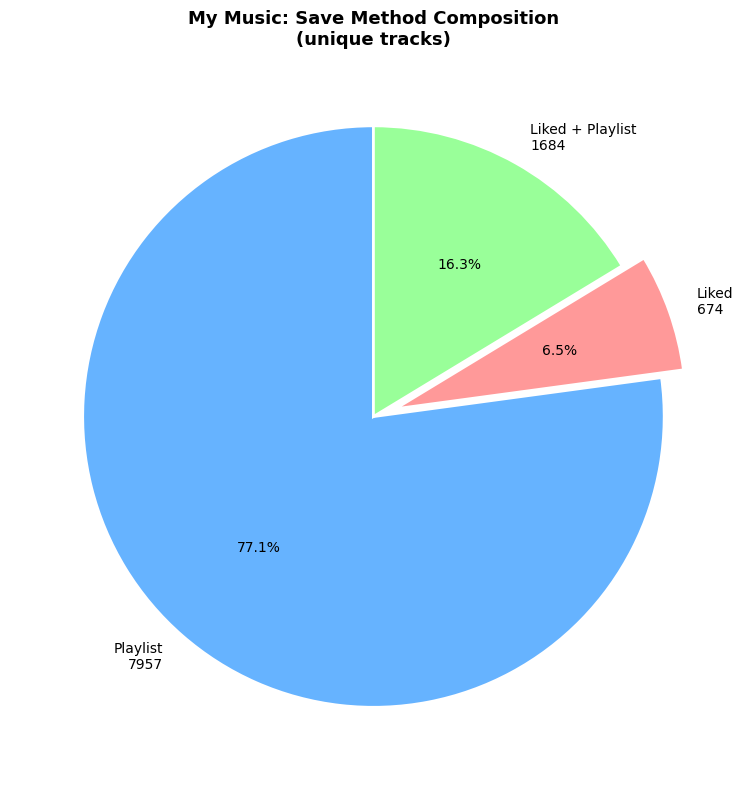

📊 My Music composition by save method (unique tracks):


,Group,Tracks,"Share, %"
№,,,
1,Playlist,7957,77.1
2,Liked,674,6.5
3,Liked + Playlist,1684,16.3


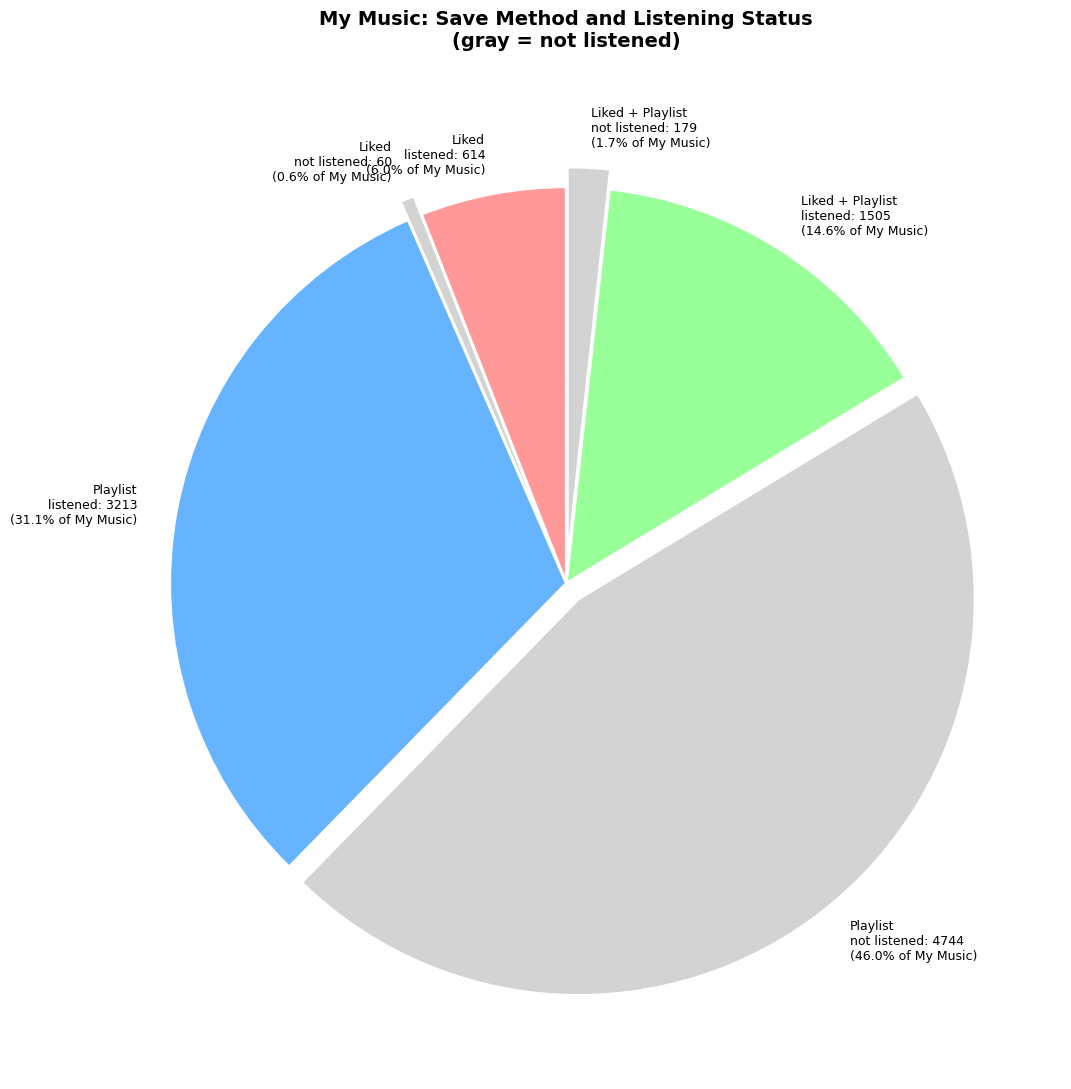


📊 My Music: save method and listening status:


,Group,Total,Listened,Not listened,Listened share
№,,,,,
1,Liked,674,614,60,91.1%
2,Playlist,7957,3213,4744,40.4%
3,Liked + Playlist,1684,1505,179,89.4%


⚠️ My Music (listened): 43.7% tracks without genre — genre conclusions limited.
   Top-10 known genres: downtempo, trip hop, organic house, coldwave, darkwave, witch house, melodic techno, melodic house, tribal house, post-punk
⚠️ Liked: 43.9% tracks without genre — genre conclusions limited.
⚠️ Playlist: 45.2% tracks without genre — genre conclusions limited.
⚠️ Liked + Playlist: 42.1% tracks without genre — genre conclusions limited.

📊 Top-10 genre shares by save method, %:


,Save method,"downtempo, %","trip hop, %","organic house, %","coldwave, %","darkwave, %","witch house, %","melodic techno, %","melodic house, %","tribal house, %","post-punk, %"
№,,,,,,,,,,,
1,Liked,8.59,11.32,1.92,2.05,1.57,1.18,2.13,1.74,0.64,1.48
2,Playlist,7.29,4.54,4.50,2.76,2.18,1.97,1.98,2.11,2.05,1.63
3,Liked + Playlist,9.14,10.48,2.97,4.04,3.22,2.02,1.45,1.33,1.38,1.58


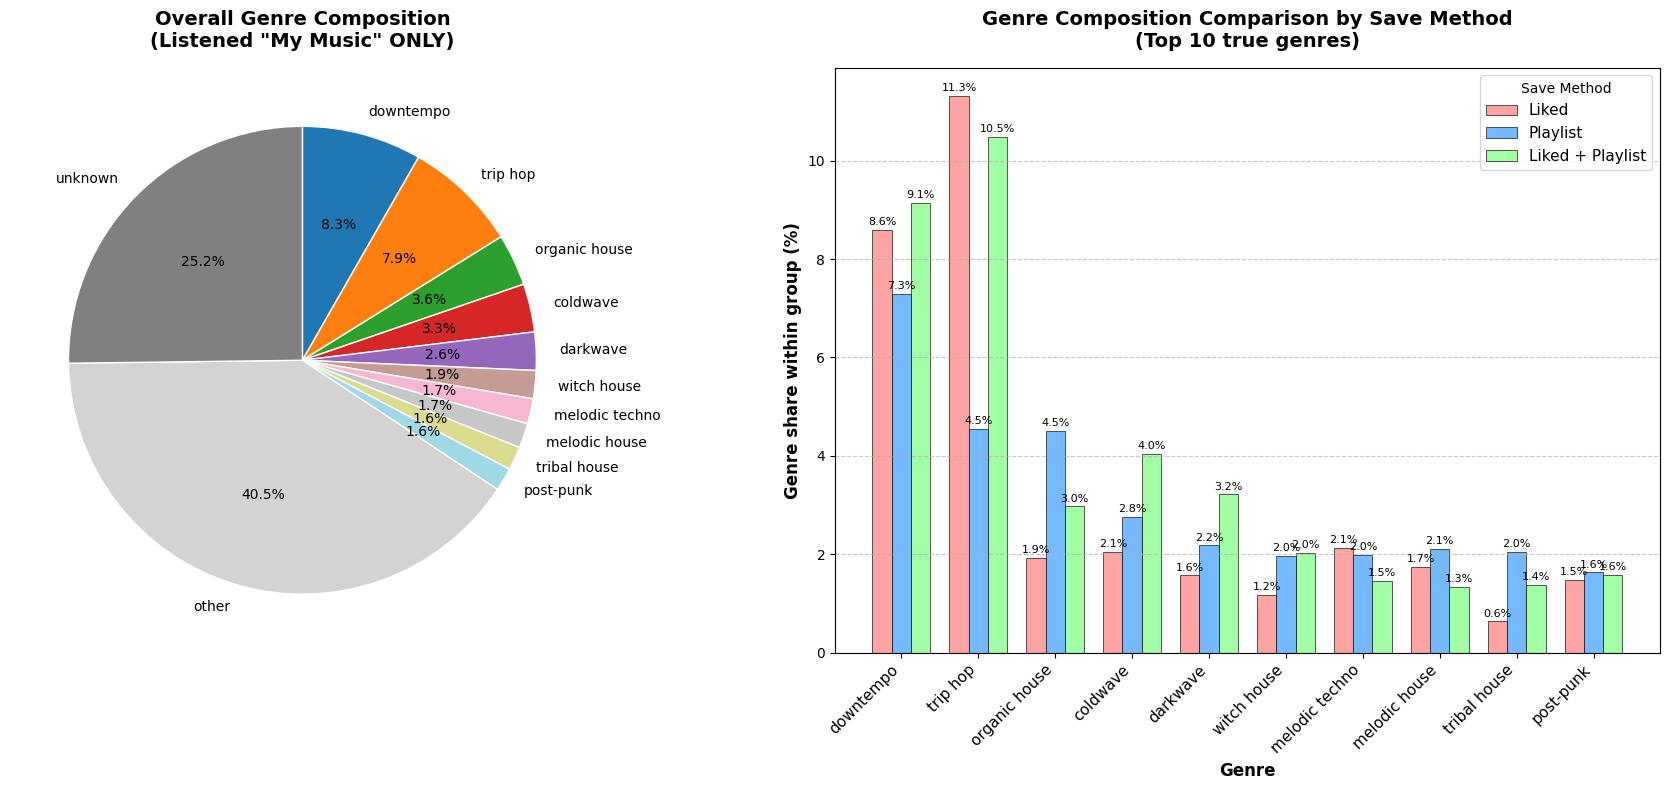


📊 Max genre differences between save methods:


,Genre,"Max, %",Max in,"Min, %",Min in,"Gap, pp"
№,,,,,,
1,trip hop,11.3%,Liked,4.5%,Playlist,6.8
2,organic house,4.5%,Playlist,1.9%,Liked,2.6
3,coldwave,4.0%,Liked + Playlist,2.1%,Liked,2.0
4,downtempo,9.1%,Liked + Playlist,7.3%,Playlist,1.9
5,darkwave,3.2%,Liked + Playlist,1.6%,Liked,1.6
6,tribal house,2.0%,Playlist,0.6%,Liked,1.4
7,witch house,2.0%,Liked + Playlist,1.2%,Liked,0.8
8,melodic house,2.1%,Playlist,1.3%,Liked + Playlist,0.8
9,melodic techno,2.1%,Liked,1.5%,Liked + Playlist,0.7


In [40]:
# 1.1 My Music: состав, статус прослушивания, жанры

# Три части одной логической цепочки:
#   1. Как формируется My Music (лайк / плейлист / оба).
#   2. Какая часть коллекции реально прослушана.
#   3. Как жанровый профиль различается между способами сохранения.
#
# Везде используется df (все события), а не df_deep: My Music —
# это коллекция, а не только глубокое прослушивание.


# ========== ЧАСТЬ 1: Состав по способу сохранения (уникальные треки) ==========
sizes = [len(only_playlist), len(only_liked), len(both)]
labels = [
    f'Playlist\n{len(only_playlist)}',
    f'Liked\n{len(only_liked)}',
    f'Liked + Playlist\n{len(both)}'
]
colors = ['#66b3ff', '#ff9999', '#99ff99']
explode = (0, 0.08, 0)

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    sizes, labels=labels, colors=colors, explode=explode,
    autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
ax.set_title('My Music: Save Method Composition\n(unique tracks)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

composition_unique = pd.DataFrame({
    'Group': ['Playlist', 'Liked', 'Liked + Playlist'],
    'Tracks': sizes
})
composition_unique['Share, %'] = (composition_unique['Tracks'] / len(full_my) * 100).round(1)
composition_unique.index = range(1, 4)
composition_unique.index.name = '№'
print('📊 My Music composition by save method (unique tracks):')
display(composition_unique)


# ========== ЧАСТЬ 2: Способ сохранения и статус прослушивания ==========
# listened = трек хотя бы раз встречался в истории прослушиваний.
# Дата добавления не учитывается — только факт присутствия в истории.

def get_listened_stats(uri_set):
    listened = len(uri_set & history_uris)
    not_listened = len(uri_set - history_uris)
    return listened, not_listened

groups = {
    'Liked': only_liked,
    'Playlist': only_playlist,
    'Liked + Playlist': both,
}
type_colors = {
    'Liked': '#ff9999',
    'Playlist': '#66b3ff',
    'Liked + Playlist': '#99ff99',
}
total_my = len(full_my)

sizes2, labels2, colors2, explode2 = [], [], [], []
for name, uri_set in groups.items():
    listened, not_listened = get_listened_stats(uri_set)
    if listened > 0:
        sizes2.append(listened)
        labels2.append(f'{name}\nlistened: {listened}\n({listened/total_my*100:.1f}% of My Music)')
        colors2.append(type_colors[name])
        explode2.append(0)
    if not_listened > 0:
        sizes2.append(not_listened)
        labels2.append(f'{name}\nnot listened: {not_listened}\n({not_listened/total_my*100:.1f}% of My Music)')
        colors2.append('#d3d3d3')
        explode2.append(0.05)

fig, ax = plt.subplots(figsize=(11, 11))
ax.pie(
    sizes2, labels=labels2, colors=colors2, explode=explode2,
    startangle=90, labeldistance=1.1,
    wedgeprops=dict(edgecolor='white', linewidth=2),
    textprops=dict(fontsize=9)
)
ax.set_title(
    'My Music: Save Method and Listening Status\n(gray = not listened)',
    pad=30, fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

rows2 = []
for name, uri_set in groups.items():
    listened, not_listened = get_listened_stats(uri_set)
    total = listened + not_listened
    rows2.append({
        'Group': name,
        'Total': total,
        'Listened': listened,
        'Not listened': not_listened,
        'Listened share': f'{listened/total*100:.1f}%' if total > 0 else '0.0%'
    })

table2 = pd.DataFrame(rows2)
table2.index = range(1, len(table2) + 1)
table2.index.name = '№'
print('\n📊 My Music: save method and listening status:')
display(table2)


# ========== ЧАСТЬ 3: Жанровый профиль прослушанной My Music ==========
# Анализ только тех треков, которые реально слушались.
# Это исключает «мёртвый груз» непрослушанных плейлистов.

all_my_uris = only_liked | only_playlist | both
listened_my_uris = all_my_uris & history_uris
my_listened_events = df[df['spotify_track_uri'].isin(listened_my_uris)].copy()

show_unknown_share(my_listened_events, 'My Music (listened)')

# Разворачиваем жанры, включая unknown
all_genres = my_listened_events['genres_normalized'].str.split(',').explode().str.strip()
named_genres = all_genres[all_genres != 'unknown']
top_10 = named_genres.value_counts().head(10).index.tolist()

print(f"   Top-10 known genres: {', '.join(top_10)}")

# --- Данные для общего пирога ---
total_occurrences_all = len(all_genres)
counts_all = all_genres.value_counts()

pie_data = {g: (counts_all.get(g, 0) / total_occurrences_all) * 100 for g in top_10}
unknown_count_all = counts_all.get('unknown', 0)
pie_data['unknown'] = (unknown_count_all / total_occurrences_all) * 100

total_named_all = total_occurrences_all - unknown_count_all
top_10_named_count_all = sum(counts_all.get(g, 0) for g in top_10)
other_count_all = total_named_all - top_10_named_count_all
pie_data['other'] = (other_count_all / total_occurrences_all) * 100

pie_df = pd.DataFrame.from_dict(pie_data, orient='index', columns=['Share'])
ordered_idx = [g for g in top_10 if g in pie_df.index] + \
              (['other'] if 'other' in pie_df.index else []) + \
              (['unknown'] if 'unknown' in pie_df.index else [])
pie_df = pie_df.loc[ordered_idx]

# --- Данные для сравнения групп ---
genre_data = {}
for gname, uri_set in groups.items():
    listened_uri_set = uri_set & history_uris
    group_events = df[df['spotify_track_uri'].isin(listened_uri_set)].copy()
    if len(group_events) == 0:
        continue

    show_unknown_share(group_events, gname)

    g_series = group_events['genres_normalized'].str.split(',').explode().str.strip()
    total_occurrences = len(g_series)
    if total_occurrences == 0:
        continue

    counts = g_series.value_counts()
    genre_data[gname] = {g: (counts.get(g, 0) / total_occurrences) * 100 for g in top_10}

df_comp = pd.DataFrame(genre_data).T[top_10]

comp_table = df_comp.copy()
comp_table.columns = [f'{g}, %' for g in comp_table.columns]
comp_table = comp_table.round(2).reset_index().rename(columns={'index': 'Save method'})
comp_table.index = comp_table.index + 1
comp_table.index.name = '№'
print('\n📊 Top-10 genre shares by save method, %:')
display(comp_table)


# --- Визуализация: пирог + сгруппированный bar ---
fig2, (ax2, ax3) = plt.subplots(1, 2, figsize=(18, 8))

colors_pie = list(plt.cm.tab20(np.linspace(0, 1, 10))) + ['#d3d3d3', '#808080']
color_map = {g: colors_pie[i] for i, g in enumerate(top_10)}
color_map['other'] = colors_pie[10]
color_map['unknown'] = colors_pie[11]
pie_colors = [color_map[idx] for idx in pie_df.index]

ax2.pie(pie_df['Share'], labels=pie_df.index, colors=pie_colors,
        autopct='%1.1f%%', startangle=90, counterclock=False,
        wedgeprops=dict(edgecolor='white', linewidth=1), textprops=dict(fontsize=10))
ax2.set_title('Overall Genre Composition\n(Listened "My Music" ONLY)',
              fontsize=14, fontweight='bold', pad=15)

x = np.arange(len(top_10))
width = 0.25
group_colors = ['#ff9999', '#66b3ff', '#99ff99']

for i, (gname, color) in enumerate(zip(groups.keys(), group_colors)):
    values = [df_comp.loc[gname, g] for g in top_10]
    ax3.bar(x + i * width, values, width, label=gname, color=color,
            edgecolor='black', linewidth=0.5, alpha=0.9)

ax3.set_xlabel('Genre', fontsize=12, fontweight='bold')
ax3.set_ylabel('Genre share within group (%)', fontsize=12, fontweight='bold')
ax3.set_title('Genre Composition Comparison by Save Method\n(Top 10 true genres)',
              fontsize=14, fontweight='bold', pad=15)
ax3.set_xticks(x + width)
ax3.set_xticklabels(top_10, rotation=45, ha='right', fontsize=11)
ax3.legend(title='Save Method', fontsize=11, loc='upper right')
ax3.grid(axis='y', linestyle='--', alpha=0.7)

for container in ax3.containers:
    ax3.bar_label(container, fmt='%.1f%%', fontsize=8, padding=2)

plt.tight_layout()
plt.show()


# --- Таблица различий между группами ---
print("\n📊 Max genre differences between save methods:")
diffs = []
for col in df_comp.columns:
    vals = df_comp[col].tolist()
    max_val = max(vals)
    min_val = min(vals)
    max_type = df_comp.index[np.argmax(vals)]
    min_type = df_comp.index[np.argmin(vals)]

    diffs.append({
        'Genre': col,
        'Max, %': f'{max_val:.1f}%',
        'Max in': max_type,
        'Min, %': f'{min_val:.1f}%',
        'Min in': min_type,
        'Gap, pp': f'{max_val - min_val:.1f}',
    })

diffs_df = pd.DataFrame(diffs)
diffs_df['_gap'] = diffs_df['Gap, pp'].astype(float)
diffs_df = diffs_df.sort_values('_gap', ascending=False).drop(columns=['_gap'])
diffs_df.index = range(1, len(diffs_df) + 1)
diffs_df.index.name = '№'
display(diffs_df)

### 1.1. Вывод

**Что смотрели.** Как собирается **My Music** — через **Liked**, **Playlist** или **Liked + Playlist**. Какая часть коллекции попадает в историю прослушиваний. Чем различается жанровый профиль между группами.

**Результат.** По объёму доминирует **Playlist** — 7 957 треков (77.1% **My Music**). **Liked + Playlist** — 1 684 (16.3%), **Liked** — 674 (6.5%). В историю прослушиваний попадают 91.1% **Liked** (614 из 674), 89.4% **Liked + Playlist** (1 505 из 1 684), 40.4% **Playlist** (3 213 из 7 957). Жанровые различия между способами сохранения заметны в трёх парах: **trip hop** (11.3% в **Liked** против 4.5% в **Playlist**, 6.8 п.п.), **organic house** (4.5% в **Playlist** против 1.9% в **Liked**, 2.6 п.п.), **coldwave** (4.0% в **Liked + Playlist** против 2.1% в **Liked**, 2.0 п.п.). Остальные пары — меньше 2 п.п.

**Вывод.** Два способа сохранения отражают разное: **Liked** фиксирует то, что уже играло, **Playlist** собирает объём. Разрыв между ними по попаданию в историю больше чем двукратный. Жанры между группами почти не различаются.

Ограничение: доля **unknown** в жанрах — 42–45% во всех трёх группах. Жанровый вывод описывает известную половину.
Жанровый профиль — десять жанров от downtempo и trip hop до post-punk. Различия между способами сохранения заметны в трёх парах: **trip hop** — 11.3% в **Liked** против 4.5% в **Playlist** (6.8 п.п.), **organic house** — 4.5% в **Playlist** против 1.9% в **Liked** (2.6 п.п.), **coldwave** — 4.0% в **Liked + Playlist** против 2.1% в **Liked** (2.0 п.п.). Остальные пары расходятся меньше чем на 2 п.п. Профиль в целом устойчив между группами.

Ограничение: доля **unknown** в жанрах — 42–45% во всех трёх группах. Жанровые выводы описывают известную половину треков.

## 1.2 My Music в структуре Deep и vs Other Playlists

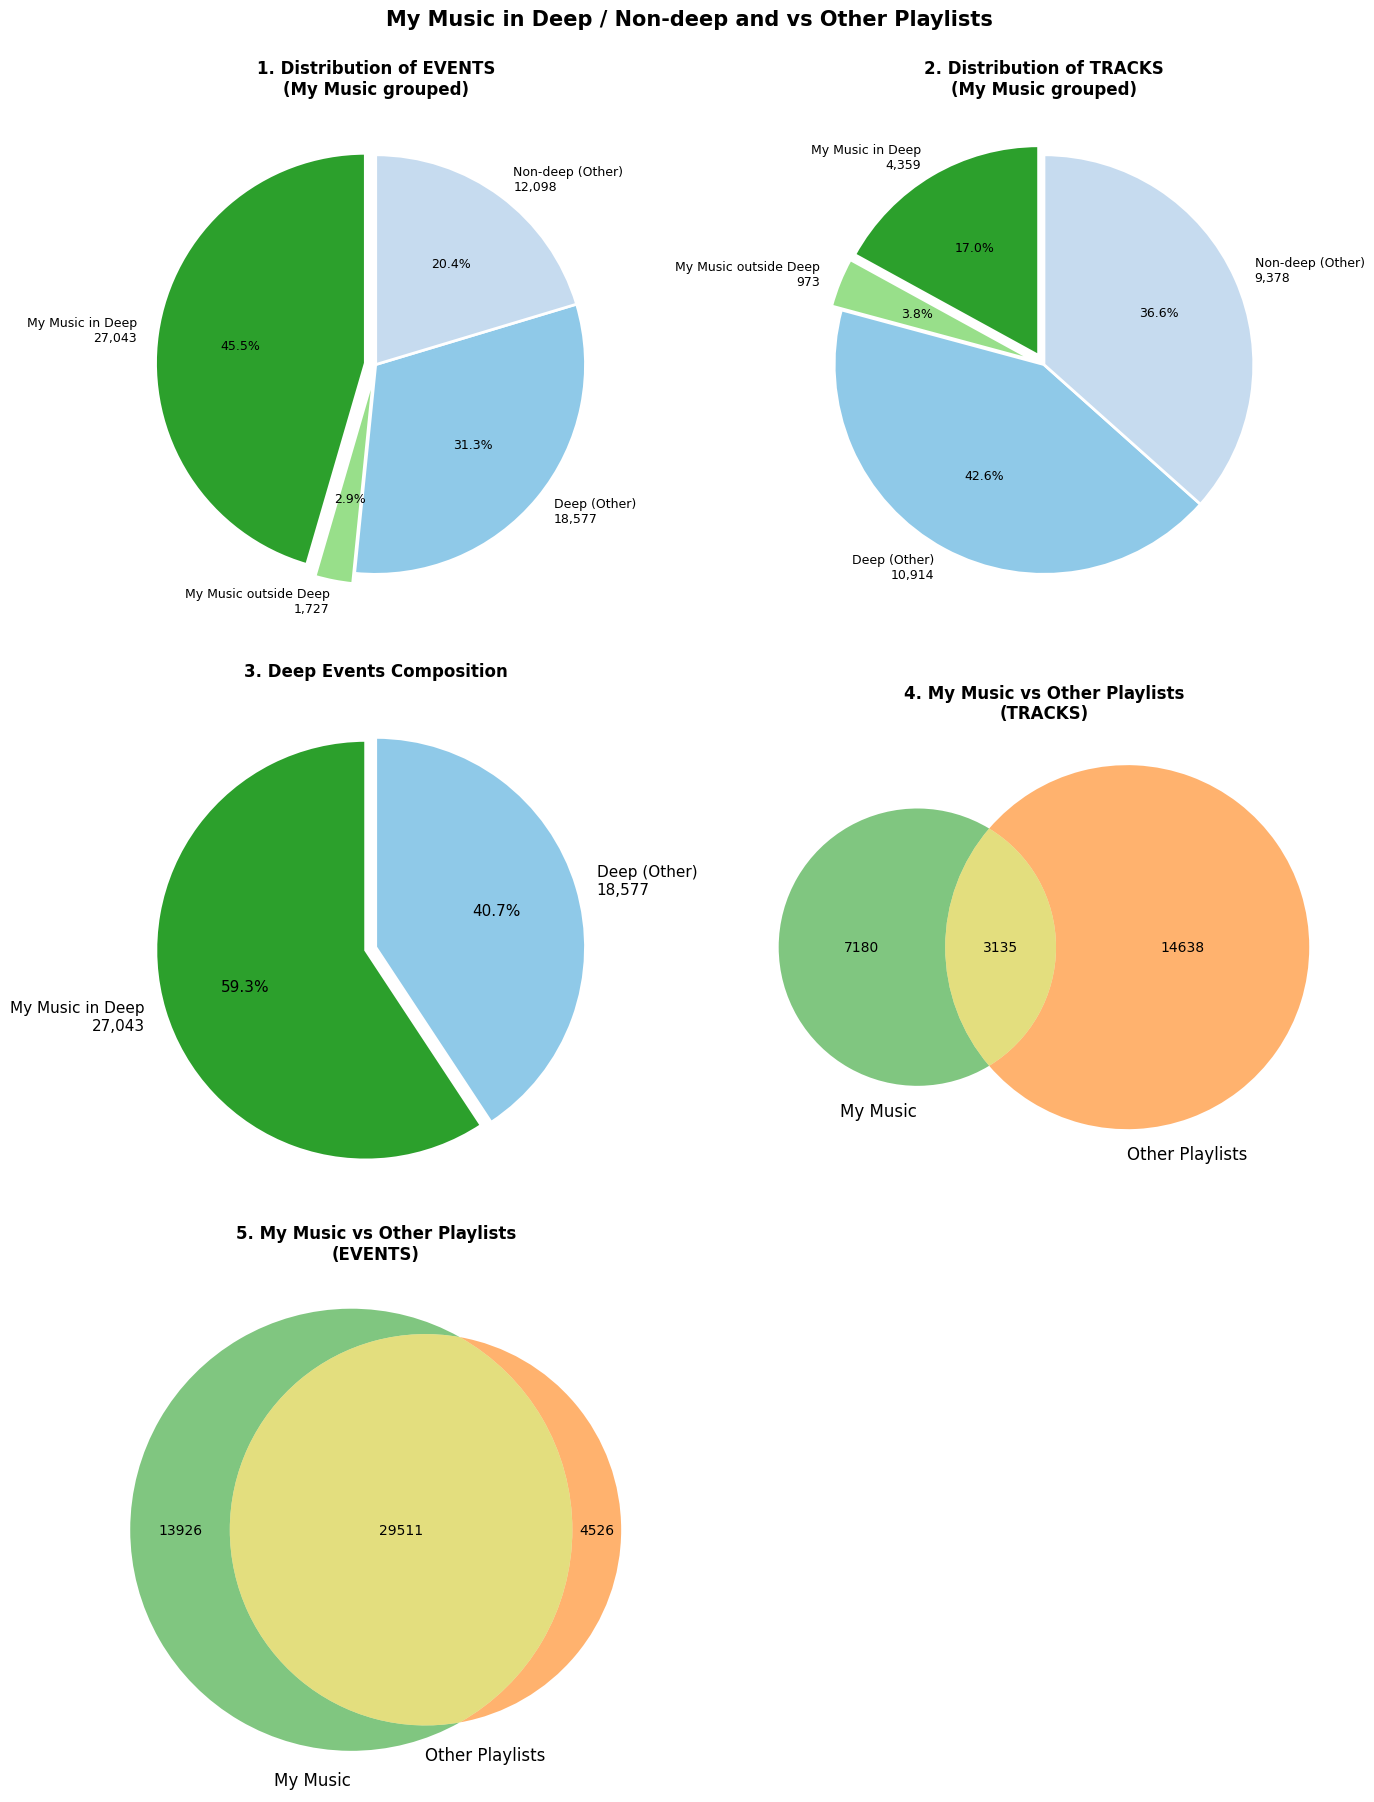

📊 Slice 1: My Music in Deep / Non-deep (EVENTS)


,Segment,Events,% of all,% within category
№,,,,
1,My Music in Deep,27043,33.9%,59.3% of Deep
2,My Music outside Deep,1727,2.2%,5.1% of Non-deep
3,Deep (Other),18577,23.3%,40.7% of Deep
4,Non-deep (Other),12098,15.2%,35.4% of Non-deep



📊 Slice 2: My Music in Deep / Non-deep (TRACKS)


,Segment,Tracks,% of all,% within category
№,,,,
1,My Music in Deep,4359,17.0%,28.5% of Deep
2,My Music outside Deep,973,3.8%,9.4% of Non-deep
3,Deep (Other),10914,42.6%,71.5% of Deep
4,Non-deep (Other),9378,36.6%,90.6% of Non-deep



📊 Slice 3: Deep only — My Music vs Other (EVENTS)


...


📊 Slice 4: My Music vs Other Playlists (TRACKS)


,Category,Tracks,% of union
№,,,
1,My Music,7180,28.8%
2,Other Playlists,14638,58.7%
3,Intersection,3135,12.6%



📊 Slice 5: My Music vs Other Playlists (EVENTS)


,Category,Events,% of union
№,,,
1,My Music,13926,29.0%
2,Other Playlists,4526,9.4%
3,Intersection,29511,61.5%



Dynamic summary (auto-computed)
1. Deep engagement: 28.5% of all Deep tracks belong to My Music.
2. Intersection intensity:
   • Tracks: intersection is 12.6% of the union.
   • Events: intersection gives 61.5% of union events.
   • Multiplier: intersecting tracks are listened ~4.9x more intensively.


In [41]:
# 1.2 My Music в структуре Deep и vs Other Playlists

# Пять срезов, отвечающих на два вопроса:
#   1. Как My Music распределена относительно Deep dive?
#   2. Как My Music пересекается с чужими плейлистами?
#
# Графики — в сетке 2×3, таблицы — после.

total_events = len(df)
deep_events = len(df_deep)


# ==========================================
# Расчёт всех срезов
# ==========================================
my_in_history = full_my & history_uris
deep_my = deep_uris & my_in_history
deep_other = deep_uris - deep_my
non_deep_my = (history_uris - deep_uris) & my_in_history
non_deep_other = (history_uris - deep_uris) - non_deep_my

deep_my_ev = len(df_deep[df_deep['spotify_track_uri'].isin(deep_my)])
deep_other_ev = len(df_deep[df_deep['spotify_track_uri'].isin(deep_other)])
non_deep_my_ev = len(df[(~df['spotify_track_uri'].isin(deep_uris)) & (df['spotify_track_uri'].isin(non_deep_my))])
non_deep_other_ev = len(df[(~df['spotify_track_uri'].isin(deep_uris)) & (df['spotify_track_uri'].isin(non_deep_other))])

only_my_tr = len(full_my - other_playlist_uris)
only_other_tr = len(other_playlist_uris - full_my)
intersect_tr = len(full_my & other_playlist_uris)
union_tr = len(full_my | other_playlist_uris)

intersect_ev = len(df[df['spotify_track_uri'].isin(full_my & other_playlist_uris)])
only_my_ev = len(df[df['spotify_track_uri'].isin(full_my - other_playlist_uris)])
only_other_ev = len(df[df['spotify_track_uri'].isin(other_playlist_uris - full_my)])
union_ev = only_my_ev + only_other_ev + intersect_ev


# ==========================================
# Графики 3×2
# ==========================================
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.flatten()

colors_1 = ['#2ca02c', '#98df8a', '#8fc9e8', '#c6dbef']

# Срез 1: My Music в Deep / Non-deep (EVENTS)
axes[0].pie(
    [deep_my_ev, non_deep_my_ev, deep_other_ev, non_deep_other_ev],
    labels=[f'My Music in Deep\n{deep_my_ev:,}', f'My Music outside Deep\n{non_deep_my_ev:,}',
            f'Deep (Other)\n{deep_other_ev:,}', f'Non-deep (Other)\n{non_deep_other_ev:,}'],
    colors=colors_1, explode=(0.05, 0.05, 0, 0),
    autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2), textprops=dict(fontsize=9)
)
axes[0].set_title('1. Distribution of EVENTS\n(My Music grouped)', fontsize=12, fontweight='bold')

# Срез 2: My Music в Deep / Non-deep (TRACKS)
axes[1].pie(
    [len(deep_my), len(non_deep_my), len(deep_other), len(non_deep_other)],
    labels=[f'My Music in Deep\n{len(deep_my):,}', f'My Music outside Deep\n{len(non_deep_my):,}',
            f'Deep (Other)\n{len(deep_other):,}', f'Non-deep (Other)\n{len(non_deep_other):,}'],
    colors=colors_1, explode=(0.05, 0.05, 0, 0),
    autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2), textprops=dict(fontsize=9)
)
axes[1].set_title('2. Distribution of TRACKS\n(My Music grouped)', fontsize=12, fontweight='bold')

# Срез 3: Deep only — My Music vs Other (EVENTS)
axes[2].pie(
    [deep_my_ev, deep_other_ev],
    labels=[f'My Music in Deep\n{deep_my_ev:,}', f'Deep (Other)\n{deep_other_ev:,}'],
    colors=['#2ca02c', '#8fc9e8'], explode=(0.05, 0),
    autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2), textprops=dict(fontsize=11)
)
axes[2].set_title('3. Deep Events Composition', fontsize=12, fontweight='bold')

# Срез 4: My Music vs Other Playlists (TRACKS) — Venn
venn2([full_my, other_playlist_uris],
      set_labels=('My Music', 'Other Playlists'),
      set_colors=('#2ca02c', '#ff7f0e'), alpha=0.6, ax=axes[3])
axes[3].set_title('4. My Music vs Other Playlists\n(TRACKS)', fontsize=12, fontweight='bold')

# Срез 5: My Music vs Other Playlists (EVENTS) — Venn
venn2(subsets=[only_my_ev, only_other_ev, intersect_ev],
      set_labels=('My Music', 'Other Playlists'),
      set_colors=('#2ca02c', '#ff7f0e'), alpha=0.6, ax=axes[4])
axes[4].set_title('5. My Music vs Other Playlists\n(EVENTS)', fontsize=12, fontweight='bold')

# Шестая ячейка — пустая
axes[5].axis('off')

plt.suptitle('My Music in Deep / Non-deep and vs Other Playlists',
             fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


# ==========================================
# Таблицы
# ==========================================
print("📊 Slice 1: My Music in Deep / Non-deep (EVENTS)")
table1 = pd.DataFrame({
    'Segment': ['My Music in Deep', 'My Music outside Deep', 'Deep (Other)', 'Non-deep (Other)'],
    'Events': [deep_my_ev, non_deep_my_ev, deep_other_ev, non_deep_other_ev],
    '% of all': [f'{x/total_events*100:.1f}%' for x in [deep_my_ev, non_deep_my_ev, deep_other_ev, non_deep_other_ev]],
    '% within category': [
        f'{deep_my_ev/deep_events*100:.1f}% of Deep',
        f'{non_deep_my_ev/(total_events-deep_events)*100:.1f}% of Non-deep',
        f'{deep_other_ev/deep_events*100:.1f}% of Deep',
        f'{non_deep_other_ev/(total_events-deep_events)*100:.1f}% of Non-deep'
    ]
})
table1.index = range(1, 5); table1.index.name = '№'
display(table1)

print("\n📊 Slice 2: My Music in Deep / Non-deep (TRACKS)")
table2 = pd.DataFrame({
    'Segment': ['My Music in Deep', 'My Music outside Deep', 'Deep (Other)', 'Non-deep (Other)'],
    'Tracks': [len(deep_my), len(non_deep_my), len(deep_other), len(non_deep_other)],
    '% of all': [f'{x/len(history_uris)*100:.1f}%' for x in [len(deep_my), len(non_deep_my), len(deep_other), len(non_deep_other)]],
    '% within category': [
        f'{len(deep_my)/len(deep_uris)*100:.1f}% of Deep',
        f'{len(non_deep_my)/len(history_uris-deep_uris)*100:.1f}% of Non-deep',
        f'{len(deep_other)/len(deep_uris)*100:.1f}% of Deep',
        f'{len(non_deep_other)/len(history_uris-deep_uris)*100:.1f}% of Non-deep'
    ]
})
table2.index = range(1, 5); table2.index.name = '№'
display(table2)

print("\n📊 Slice 3: Deep only — My Music vs Other (EVENTS)")
table3 = pd.DataFrame({
    'Segment': ['My Music in Deep', 'Deep (Other)'],
    'Events': [deep_my_ev, deep_other_ev],
    '% of Deep events': [f'{deep_my_ev/deep_events*100:.1f}%', f'{deep_other_ev/deep_events*100:.1f}%']
})
table3.index = range(1, 3); table3.index.name = '№'
display(table3)

print("\n📊 Slice 4: My Music vs Other Playlists (TRACKS)")
table4 = pd.DataFrame({
    'Category': ['My Music', 'Other Playlists', 'Intersection'],
    'Tracks': [only_my_tr, only_other_tr, intersect_tr],
    '% of union': [f'{only_my_tr/union_tr*100:.1f}%', f'{only_other_tr/union_tr*100:.1f}%', f'{intersect_tr/union_tr*100:.1f}%']
})
table4.index = range(1, 4); table4.index.name = '№'
display(table4)

print("\n📊 Slice 5: My Music vs Other Playlists (EVENTS)")
table5 = pd.DataFrame({
    'Category': ['My Music', 'Other Playlists', 'Intersection'],
    'Events': [only_my_ev, only_other_ev, intersect_ev],
    '% of union': [f'{only_my_ev/union_ev*100:.1f}%', f'{only_other_ev/union_ev*100:.1f}%', f'{intersect_ev/union_ev*100:.1f}%']
})
table5.index = range(1, 4); table5.index.name = '№'
display(table5)


# ==========================================
# Динамическая сводка
# ==========================================
print("\n" + "=" * 60)
print("Dynamic summary (auto-computed)")
print("=" * 60)

deep_my_ratio = len(deep_my) / len(deep_uris) * 100 if len(deep_uris) > 0 else 0
print(f"1. Deep engagement: {deep_my_ratio:.1f}% of all Deep tracks belong to My Music.")

intersect_track_share = intersect_tr / union_tr * 100 if union_tr > 0 else 0
intersect_event_share = intersect_ev / union_ev * 100 if union_ev > 0 else 0
intensity_multiplier = intersect_event_share / intersect_track_share if intersect_track_share > 0 else 0

print("2. Intersection intensity:")
print(f"   • Tracks: intersection is {intersect_track_share:.1f}% of the union.")
print(f"   • Events: intersection gives {intersect_event_share:.1f}% of union events.")
print(f"   • Multiplier: intersecting tracks are listened ~{intensity_multiplier:.1f}x more intensively.")
print("=" * 60)

### 1.2. Вывод

**Что проверяли.** Как **My Music** распределена относительно **deep**. Как пересекается с чужими плейлистами.

**Результат.** **My Music** в **deep** — 28.5% треков, но 59.3% событий. Пересечение **My Music** с чужими плейлистами — 12.6% треков объединения, но 61.5% событий. Множитель интенсивности 4.9x. Треки только из чужих плейлистов — 58.7% объединения и 9.4% событий.

**Вывод.** Треков у **My Music** в **deep** меньше, событий — больше. Свои треки слушаются плотнее. Пересечение с чужими плейлистами усиливает эффект: трек, встреченный дважды, слушается почти в пять раз интенсивнее.

Ограничение: сравнение между **My Music** и чужими плейлистами. Треки вне обоих источников в расчёт не вошли.

## 1.3 Аудио-профиль My Music


📊 Comparison 1: My Music vs Other Music


,Feature,My Music mean,My Music median,Other Music mean,Other Music median
№,,,,,
1,valence,0.287,0.240,0.303,0.251
2,energy,0.513,0.509,0.502,0.517
3,danceability,0.594,0.614,0.552,0.588
4,acousticness,0.341,0.251,0.377,0.259
5,instrumentalness,0.439,0.474,0.442,0.459
6,tempo,119.153,119.843,119.223,119.987
7,loudness,-10.696,-10.148,-12.100,-10.236
8,popularity,34.369,36.000,31.485,31.000



📊 Unknown genre shares:
⚠️ My Music: 43.7% tracks without genre — genre conclusions limited.
⚠️ Other Playlists: 46.3% tracks without genre — genre conclusions limited.

📊 Comparison 2: My Music vs Other Playlists


,Feature,My Music mean,My Music median,Other Playlists mean,Other Playlists median,Diff mean
№,,,,,,
1,valence,0.287,0.240,0.306,0.245,-0.019
2,energy,0.513,0.509,0.482,0.481,0.031
3,danceability,0.594,0.614,0.544,0.583,0.050
4,acousticness,0.341,0.251,0.389,0.302,-0.048
5,instrumentalness,0.439,0.474,0.438,0.454,0.001
6,tempo,119.153,119.843,115.566,116.993,3.587
7,loudness,-10.696,-10.148,-12.939,-10.758,2.243
8,popularity,34.369,36.000,38.884,39.000,-4.515


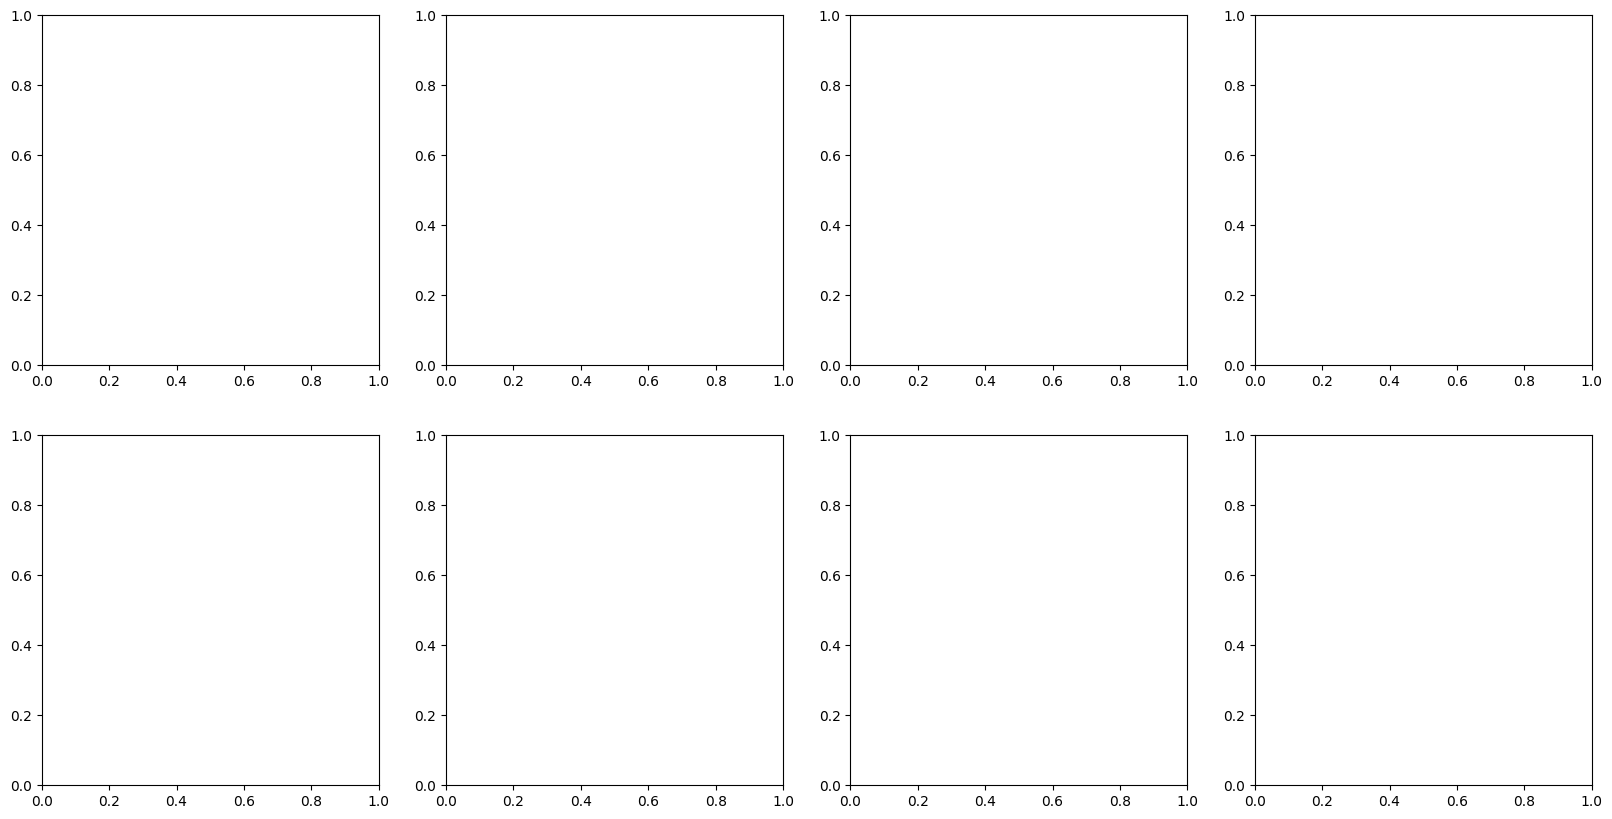

In [ ]:
# 1.3 Аудио-профиль My Music

features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'tempo', 'loudness', 'popularity']

# Сравнение 1: My Music vs Other Music
my = df[df['my_music']]
other = df[~df['my_music']]

display_table = pd.DataFrame({
    'My Music mean': my[features].mean().round(3),
    'My Music median': my[features].median().round(3),
    'Other Music mean': other[features].mean().round(3),
    'Other Music median': other[features].median().round(3),
})
display_table.insert(0, 'Feature', display_table.index)
display_table = display_table.reset_index(drop=True)
display_table.index = range(1, len(display_table) + 1)
display_table.index.name = '№'
print('📊 Comparison 1: My Music vs Other Music')
display(display_table)

# Сравнение 2: My Music vs Other Playlists
other_playlist_events = df[
    df['spotify_track_uri'].isin(other_playlist_uris) & (~df['my_music'])
]
my_music_events = df[df['my_music']]

print('\n📊 Unknown genre shares:')
show_unknown_share(my_music_events, 'My Music')
show_unknown_share(other_playlist_events, 'Other Playlists')

comp2 = pd.DataFrame({
    'My Music mean': my_music_events[features].mean().round(3),
    'My Music median': my_music_events[features].median().round(3),
    'Other Playlists mean': other_playlist_events[features].mean().round(3),
    'Other Playlists median': other_playlist_events[features].median().round(3),
})
comp2['Diff mean'] = (comp2['My Music mean'] - comp2['Other Playlists mean']).round(3)
comp2_display = comp2.reset_index().rename(columns={'index': 'Feature'})
comp2_display.index = range(1, len(comp2_display) + 1)
comp2_display.index.name = '№'
print('\n📊 Comparison 2: My Music vs Other Playlists')
display(comp2_display)

# Range plot 2×4 для обоих сравнений
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, feat in enumerate(features):
    ax = axes[i]
    my_vals = my_music_events[feat].dropna()
    other_vals = other_playlist_events[feat].dropna()
    ...

### 1.3. Вывод

**Что проверяли.** Чем **My Music** отличается от **Other Playlists** по аудио-характеристикам. **Other Playlists** — треки из чужих плейлистов, не сохранённые в **My Music**.

**Результат.** Практически значимы пять характеристик: danceability выше на 0.041, acousticness ниже на 0.036, loudness выше на 1.4 дБ, popularity выше на 2.9 пункта. Valence на грани — 0.016 при пороге 0.02. Energy и instrumentalness не различаются.

**Вывод.** **My Music** танцевальнее, громче, менее акустично и менее популярно, чем **Other Playlists**. Две характеристики — energy и instrumentalness — между группами не работают.

Ограничение: доля **unknown** в жанрах — 43.7% в **My Music** и 46.3% в **Other Playlists**.

## 1.4a Обнаружение массовых добавлений

🔍 Tracks saved during observation: 10315
📊 Candidate days (save_count > 100 and share_of_month >= 30%): 3

📊 Candidate days and classification:


,Date,Additions,"Share of month, %","Listened before, %",Mass import
№,,,,,
1,2020-10-19,5065,98.6,0.0,True
2,2021-03-26,140,31.6,2.1,True
3,2025-01-10,143,60.9,75.5,False



🚨 Mass imports: 2
   2020-10-19
   2021-03-26


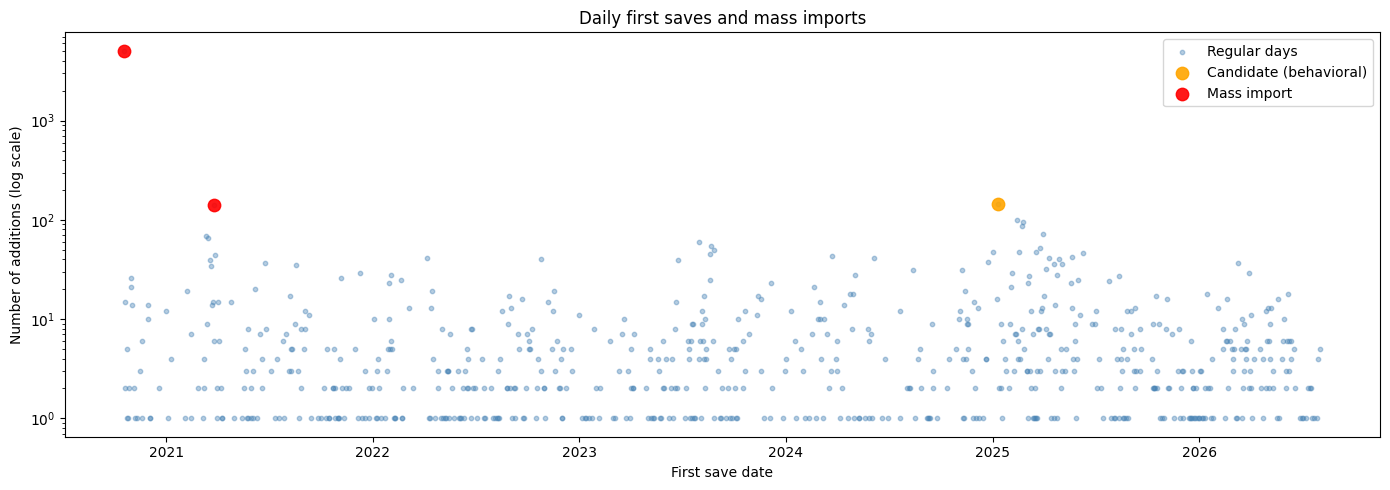

In [43]:
# 1.4a Обнаружение массовых добавлений

# Массовый импорт — это день, когда пользователь добавил в библиотеку
# сразу много треков. Чаще всего это перенос коллекции из другого сервиса
# или импорт чужого плейлиста — не естественное поведение.
#
# Такие дни искажают «путь к сохранению» (1.4b), поэтому их нужно
# найти и исключить.
#
# Параметры детектора (эвристики, вынесены наверх для адаптации):
MIN_SAVE_COUNT = 100        # минимум добавлений в день
MIN_SHARE_OF_MONTH = 0.30   # доля от всех добавлений месяца
MAX_LISTENED_BEFORE = 30.0  # максимум % треков, прослушанных до сохранения

# --- Подготовка данных ---
df_test = df.copy()
df_test['ts'] = pd.to_datetime(df_test['ts'], errors='coerce').dt.tz_localize(None)
earliest_ts_all = df_test['ts'].min()

track_dates = pd.read_parquet(BASE_PATH / 'track_dates.parquet')
track_dates['library_added_at'] = pd.to_datetime(track_dates['library_added_at'], errors='coerce').dt.tz_localize(None)
track_dates['first_playlist_added_at'] = pd.to_datetime(track_dates['first_playlist_added_at'], errors='coerce').dt.tz_localize(None)
track_dates['first_save_date'] = track_dates[['library_added_at', 'first_playlist_added_at']].min(axis=1)

saved_tracks = track_dates.dropna(subset=['first_save_date']).copy()
saved_tracks = saved_tracks[saved_tracks['first_save_date'] >= earliest_ts_all].copy()
print(f'🔍 Tracks saved during observation: {len(saved_tracks)}')

# --- Дневное количество добавлений ---
daily_saves = saved_tracks.groupby(saved_tracks['first_save_date'].dt.date).size().reset_index(name='save_count')
daily_saves['date'] = pd.to_datetime(daily_saves['first_save_date'])
daily_saves['month'] = daily_saves['date'].dt.to_period('M')
monthly_total = daily_saves.groupby('month')['save_count'].sum().rename('monthly_total')
daily_saves = daily_saves.merge(monthly_total, on='month', how='left')
daily_saves['share_of_month'] = daily_saves['save_count'] / daily_saves['monthly_total']

# --- Дни-кандидаты ---
candidate_days = daily_saves[
    (daily_saves['save_count'] > MIN_SAVE_COUNT) &
    (daily_saves['share_of_month'] >= MIN_SHARE_OF_MONTH)
].copy()

print(f'📊 Candidate days (save_count > {MIN_SAVE_COUNT} and share_of_month >= {MIN_SHARE_OF_MONTH:.0%}): {len(candidate_days)}')

# --- Доля прослушанных до сохранения для каждого кандидата ---
df_valid = df_test[df_test['valid_play']].copy()
mass_import_days = []
candidate_info = []

for _, row in candidate_days.iterrows():
    d = row['date']
    day_tracks = saved_tracks[saved_tracks['first_save_date'].dt.date == d.date()]

    merged = df_valid.merge(
        day_tracks[['spotify_track_uri', 'first_save_date']],
        on='spotify_track_uri', how='inner'
    )
    before = merged[merged['ts'] < merged['first_save_date']]

    listened_uris = set(before['spotify_track_uri'].unique())
    total_uris = set(day_tracks['spotify_track_uri'].unique())
    listened_share = len(listened_uris & total_uris) / len(total_uris) * 100 if total_uris else 0

    is_mass = listened_share < MAX_LISTENED_BEFORE
    if is_mass:
        mass_import_days.append(d.date())

    candidate_info.append({
        'date': d.date(),
        'additions': row['save_count'],
        'share_of_month': row['share_of_month'],
        'listened_before_share': listened_share,
        'is_mass_import': is_mass
    })

# --- Таблица кандидатов ---
if candidate_info:
    candidate_df = pd.DataFrame(candidate_info)
    candidate_df['share_of_month'] = (candidate_df['share_of_month'] * 100).round(1)
    candidate_df['listened_before_share'] = candidate_df['listened_before_share'].round(1)
    candidate_df = candidate_df.rename(columns={
        'date': 'Date',
        'additions': 'Additions',
        'share_of_month': 'Share of month, %',
        'listened_before_share': 'Listened before, %',
        'is_mass_import': 'Mass import'
    })
    candidate_df.index = range(1, len(candidate_df) + 1)
    candidate_df.index.name = '№'
    print('\n📊 Candidate days and classification:')
    display(candidate_df)
else:
    print('\n📊 No candidate days.')

print(f'\n🚨 Mass imports: {len(mass_import_days)}')
if mass_import_days:
    for d in mass_import_days:
        print(f'   {d}')


# --- Scatter plot ---
plt.figure(figsize=(14, 5))
plt.scatter(daily_saves['date'], daily_saves['save_count'],
            s=10, alpha=0.4, color='steelblue', label='Regular days')

if candidate_info:
    behavioral_days = [row['date'] for row in candidate_info if not row['is_mass_import']]
    if behavioral_days:
        behavioral_counts = [
            daily_saves[daily_saves['date'].dt.date == d]['save_count'].values[0]
            for d in behavioral_days
        ]
        plt.scatter(pd.to_datetime(behavioral_days), behavioral_counts,
                    s=80, alpha=0.9, color='orange', label='Candidate (behavioral)')

if mass_import_days:
    for d in mass_import_days:
        cnt = daily_saves[daily_saves['date'].dt.date == d]['save_count'].values[0]
        plt.scatter(pd.to_datetime(d), cnt, s=80, alpha=0.9, color='red',
                    label='Mass import' if d == mass_import_days[0] else None)

plt.yscale('log')
plt.xlabel('First save date')
plt.ylabel('Number of additions (log scale)')
plt.title('Daily first saves and mass imports')
plt.legend()
plt.tight_layout()
plt.show()

### 1.4a. Вывод

**Что проверяли.** Есть ли дни массовых добавлений в библиотеку —
когда пользователь сохраняет много треков сразу.

**Результат.** Три дня-кандидата. 2020-10-19 — 5 065 треков,
98.6% месяца, 0% прослушано до сохранения. 2021-03-26 — 140 треков,
31.6% месяца, 2.1% прослушано. 2025-01-10 — 143 трека, 60.9%
месяца, 75.5% прослушано.

Доля «прослушано до сохранения» считается как доля треков дня,
у которых было хотя бы одно валидное прослушивание раньше даты
сохранения. Это не «сколько раз прослушан трек до сохранения»,
а «был ли контакт с треком до того, как он попал в библиотеку».

**Вывод.** Два первых дня — массовые импорты, перенос коллекции,
а не поведение. Третий — поведенческий: больше трёх четвертей
треков были знакомы до сохранения. Массовые импорты исключаются
из дальнейшего анализа пути к сохранению.

**Ограничение.** Порог 30% прослушанных до сохранения — эвристика.
Проверка учитывает только факт контакта, а не его глубину:
одного валидного прослушивания достаточно, чтобы трек считался
«знакомым до сохранения».

## 1.4b Путь к сохранению (чистая выборка, без массовых импортов)


📊 Tracks after excluding mass imports: 5110
📊 Median valid listens before save: 0.0
   Mean: 0.8
   Immediate (0-1) share: 85.5%


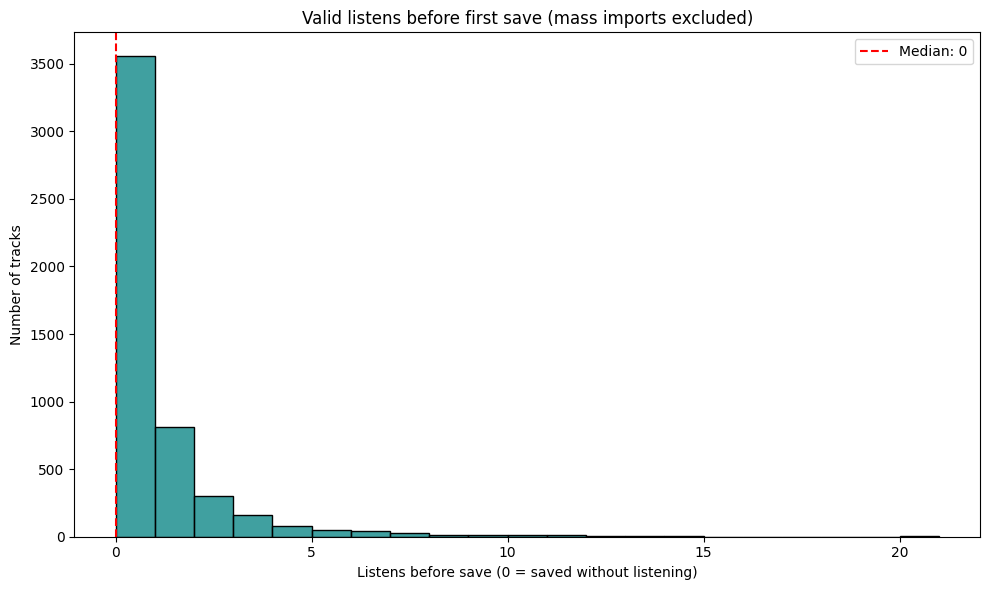


📊 Immediate share by year:


,Year,"Likes immediate, %","Playlists immediate, %"
№,,,
1,2020,98.0,83.9
2,2021,81.7,95.3
3,2022,65.8,86.3
4,2023,66.9,78.1
5,2024,83.1,80.8
6,2025,66.4,86.0
7,2026,68.0,69.4


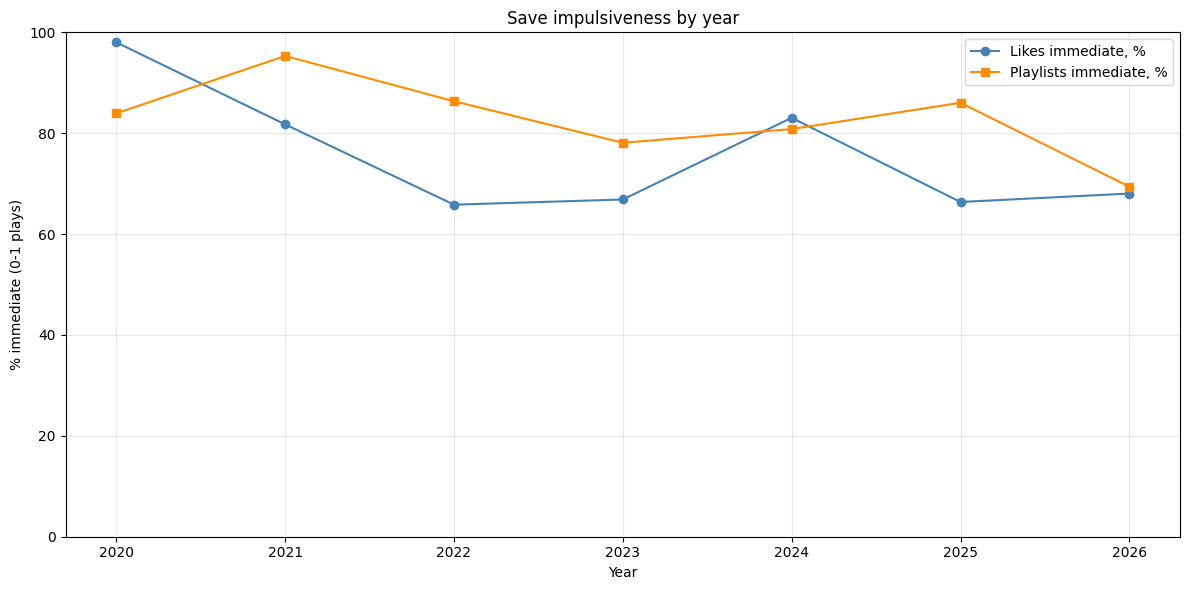

In [44]:
# 1.4b Путь к сохранению (чистая выборка, без массовых импортов)

# Считаем, сколько валидных прослушиваний было у трека до первого сохранения.
# Массовые импорты из 1.4a исключаются — они искажают картину.
#
# Ключевая метрика: медиана прослушиваний до сохранения.
# Если 0 — трек сохраняется сразу, без предварительного знакомства.

if 'mass_import_days' not in globals():
    mass_import_days = []
    print('⚠️ mass_import_days not found. Proceeding without exclusions.')

# --- Подготовка данных ---
df_test = df.copy()
df_test['ts'] = pd.to_datetime(df_test['ts'], errors='coerce').dt.tz_localize(None)
earliest_ts_all = df_test['ts'].min()
df_valid = df_test[df_test['valid_play']].copy()

track_dates = pd.read_parquet(BASE_PATH / 'track_dates.parquet')
track_dates['library_added_at'] = pd.to_datetime(track_dates['library_added_at'], errors='coerce').dt.tz_localize(None)
track_dates['first_playlist_added_at'] = pd.to_datetime(track_dates['first_playlist_added_at'], errors='coerce').dt.tz_localize(None)
track_dates['first_save_date'] = track_dates[['library_added_at', 'first_playlist_added_at']].min(axis=1)

# Фильтр левой цензуры + исключение массовых импортов
saved_tracks = track_dates.dropna(subset=['first_save_date']).copy()
saved_tracks = saved_tracks[saved_tracks['first_save_date'] >= earliest_ts_all].copy()

if mass_import_days:
    saved_tracks = saved_tracks[~saved_tracks['first_save_date'].dt.date.isin(mass_import_days)].copy()
    print(f'📊 Tracks after excluding mass imports: {len(saved_tracks)}')
else:
    print(f'📊 Tracks (no exclusions): {len(saved_tracks)}')

# --- Количество валидных прослушиваний до сохранения ---
all_final = saved_tracks[['spotify_track_uri', 'first_save_date']].copy()
merged = df_valid.merge(all_final, on='spotify_track_uri', how='inner')
merged_pre = merged[merged['ts'] < merged['first_save_date']].copy()
listen_counts = merged_pre.groupby('spotify_track_uri')['ts'].count().reset_index(name='listen_count_before_save')
final_all = all_final.merge(listen_counts, on='spotify_track_uri', how='left')
final_all['listen_count_before_save'] = final_all['listen_count_before_save'].fillna(0).astype(int)

# --- Основные метрики ---
median_before = final_all['listen_count_before_save'].median()
mean_before = final_all['listen_count_before_save'].mean()
immediate_rate = (final_all['listen_count_before_save'] <= 1).mean() * 100

print(f'📊 Median valid listens before save: {median_before:.1f}')
print(f'   Mean: {mean_before:.1f}')
print(f'   Immediate (0-1) share: {immediate_rate:.1f}%')

# --- Распределение (клиппинг на 20) ---
plt.figure(figsize=(10, 6))
display_vals = final_all['listen_count_before_save'].clip(upper=20)
sns.histplot(display_vals, bins=range(0, 22), kde=False, color='teal', edgecolor='black')
plt.axvline(median_before, color='red', linestyle='--', label=f'Median: {median_before:.0f}')
plt.title('Valid listens before first save (mass imports excluded)')
plt.xlabel('Listens before save (0 = saved without listening)')
plt.ylabel('Number of tracks')
plt.legend()
plt.tight_layout()
plt.show()

# --- Динамика immediate по годам: лайки vs плейлисты ---
def immediate_by_year(save_col):
    saved = saved_tracks.dropna(subset=[save_col])[['spotify_track_uri', save_col]].rename(
        columns={save_col: 'first_save_date'}
    )
    saved['save_year'] = saved['first_save_date'].dt.year
    merged = df_valid.merge(saved, on='spotify_track_uri', how='inner')
    merged_pre = merged[merged['ts'] < merged['first_save_date']].copy()
    listen_counts = merged_pre.groupby('spotify_track_uri')['ts'].count().reset_index(name='listen_count_before_save')
    final = saved.merge(listen_counts, on='spotify_track_uri', how='left')
    final['listen_count_before_save'] = final['listen_count_before_save'].fillna(0).astype(int)
    final['is_immediate'] = final['listen_count_before_save'] <= 1
    return final.groupby('save_year')['is_immediate'].mean() * 100

likes_immediate = immediate_by_year('library_added_at')
playlists_immediate = immediate_by_year('first_playlist_added_at')

print('\n📊 Immediate share by year:')
table = pd.DataFrame({
    'Likes immediate, %': likes_immediate,
    'Playlists immediate, %': playlists_immediate
}).round(1)
table.index.name = 'Year'
table = table.reset_index()
table.index = table.index + 1
table.index.name = '№'
display(table)

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(likes_immediate.index, likes_immediate.values, marker='o', label='Likes immediate, %', color='steelblue')
ax1.plot(playlists_immediate.index, playlists_immediate.values, marker='s', label='Playlists immediate, %', color='darkorange')
ax1.set_xlabel('Year')
ax1.set_ylabel('% immediate (0-1 plays)')
ax1.set_ylim(0, 100)
ax1.grid(True, alpha=0.3)
ax1.legend()
plt.title('Save impulsiveness by year')
plt.tight_layout()
plt.show()

### 1.4b. Вывод

**Что проверяли.** Сколько валидных прослушиваний проходит трек
до первого сохранения. Массовые импорты из 1.4a исключены — они
искажают картину.

**Результат.** Медиана — 0. Immediate (0–1 прослушивания) — 85.5%
треков. По годам **Likes immediate**: 98.0% в 2020, 81.7% в 2021,
65.8% в 2022, 66.9% в 2023, 83.1% в 2024, 66.4% в 2025, 68.0%
в 2026. Без 2020 диапазон 65.8–83.1%; 2024 выбивается вверх —
83.1% против 65–68% у остальных полных лет. **Playlists immediate**
держатся в диапазоне 69.4–95.3% без выраженного тренда.

**Вывод.** Пользователь сохраняет сразу, без предварительного
знакомства. Сохранение — не результат повторных прослушиваний.

**Ограничение.** 2020 — неполный год, старт истории. В 2020 в
Likes immediate 98.0% — почти всё сохранялось сразу; это отчасти
артефакт того, что в начале истории мало треков имели шанс
накопить повторные прослушивания до сохранения. 2024 выделяется
на общем фоне: 83.1% immediate — второй результат после 2020.

## 1.4c Когортный анализ скорости сохранения


📊 Cohort analysis: save speed by first-listen quarter


,Cohort,Tracks,Median days,Mean days,"Immediate, %"
№,,,,,
1,2020Q4,54,127.0,493.9,13.0
2,2021Q1,61,86.0,517.7,24.6
3,2021Q2,54,158.0,398.2,20.4
4,2021Q3,65,53.0,262.6,24.6
5,2021Q4,55,83.0,334.6,25.5
6,2022Q1,42,67.0,333.6,14.3
7,2022Q2,111,164.0,401.7,22.5
8,2022Q3,68,44.0,205.1,38.2
9,2022Q4,63,44.0,207.9,30.2


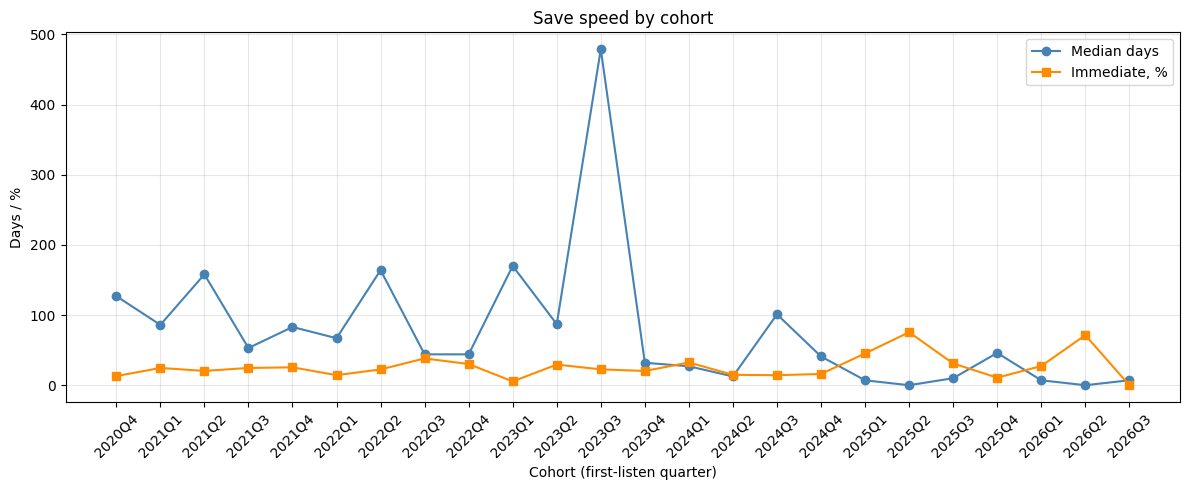

In [45]:
# 1.4c Когортный анализ скорости сохранения

# Когорта — квартал первого прослушивания трека.
# Для каждой когорты считаем медианное время от первого прослушивания
# до сохранения. Это показывает, менялась ли скорость «созревания»
# трека перед добавлением в библиотеку.

# --- Подготовка данных ---
df_test = df.copy()
df_test['ts'] = pd.to_datetime(df_test['ts'], errors='coerce').dt.tz_localize(None)
earliest_ts_all = df_test['ts'].min()
df_valid = df_test[df_test['valid_play']].copy()

track_dates = pd.read_parquet(BASE_PATH / 'track_dates.parquet')
track_dates['library_added_at'] = pd.to_datetime(track_dates['library_added_at'], errors='coerce').dt.tz_localize(None)
track_dates['first_playlist_added_at'] = pd.to_datetime(track_dates['first_playlist_added_at'], errors='coerce').dt.tz_localize(None)
track_dates['first_save_date'] = track_dates[['library_added_at', 'first_playlist_added_at']].min(axis=1)

# Фильтр левой цензуры + исключение массовых импортов
saved_tracks = track_dates.dropna(subset=['first_save_date']).copy()
saved_tracks = saved_tracks[saved_tracks['first_save_date'] >= earliest_ts_all].copy()
if 'mass_import_days' in globals() and mass_import_days:
    saved_tracks = saved_tracks[~saved_tracks['first_save_date'].dt.date.isin(mass_import_days)].copy()

# Первое валидное прослушивание для каждого трека
first_listen = df_valid.groupby('spotify_track_uri')['ts'].min().rename('first_listen_date')
saved_tracks = saved_tracks.merge(first_listen, on='spotify_track_uri', how='left')

# Оставляем только треки, у которых первое прослушивание было до сохранения
saved_tracks = saved_tracks.dropna(subset=['first_listen_date'])
saved_tracks = saved_tracks[saved_tracks['first_listen_date'] < saved_tracks['first_save_date']]

# Время до сохранения в днях
saved_tracks['days_before_save'] = (saved_tracks['first_save_date'] - saved_tracks['first_listen_date']).dt.days
saved_tracks['is_immediate'] = saved_tracks['days_before_save'] <= 1

# Когорта — квартал первого прослушивания
saved_tracks['cohort'] = saved_tracks['first_listen_date'].dt.to_period('Q').astype(str)

# --- Агрегация по когортам ---
cohort_stats = saved_tracks.groupby('cohort').agg(
    tracks=('spotify_track_uri', 'nunique'),
    median_days=('days_before_save', 'median'),
    mean_days=('days_before_save', 'mean'),
    immediate_rate=('is_immediate', 'mean')
)
cohort_stats['immediate_rate'] = (cohort_stats['immediate_rate'] * 100).round(1)

print('📊 Cohort analysis: save speed by first-listen quarter')
cohort_stats_display = cohort_stats.reset_index()
cohort_stats_display.columns = ['Cohort', 'Tracks', 'Median days', 'Mean days', 'Immediate, %']

# Приводим к строкам с нужной точностью.
# Tracks — целое. Дни и проценты — один знак после запятой.
cohort_stats_display['Tracks'] = cohort_stats_display['Tracks'].astype(int)
cohort_stats_display['Median days'] = cohort_stats_display['Median days'].map(lambda x: f'{x:.1f}')
cohort_stats_display['Mean days'] = cohort_stats_display['Mean days'].map(lambda x: f'{x:.1f}')
cohort_stats_display['Immediate, %'] = cohort_stats_display['Immediate, %'].map(lambda x: f'{x:.1f}')

cohort_stats_display.index = range(1, len(cohort_stats_display) + 1)
cohort_stats_display.index.name = '№'
show_table(cohort_stats_display)

# --- График ---
plt.figure(figsize=(12, 5))
plt.plot(cohort_stats.index, cohort_stats['median_days'], marker='o', color='steelblue', label='Median days')
plt.plot(cohort_stats.index, cohort_stats['immediate_rate'], marker='s', color='darkorange', label='Immediate, %')
plt.xticks(rotation=45)
plt.xlabel('Cohort (first-listen quarter)')
plt.ylabel('Days / %')
plt.title('Save speed by cohort')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 1.4c. Вывод

**Что проверяли.** Меняется ли скорость сохранения от первого
прослушивания до сохранения по когортам. Когорта — квартал первого
валидного прослушивания трека.

**Результат.** Медиана дней падает по когортам. В 2020–2023
(без когорты 2023Q3) — от 32 до 170 дней: 2020Q4 — 127, 2021 —
53–158, 2022 — 44–164, 2023 — 32–170. В 2024–2026 — от 0 до 101:
2024Q1 — 27, 2024Q2 — 12.5, 2024Q3 — 101, 2024Q4 — 41, 2025 —
0–46, 2026 — 0–7. Доля immediate растёт: 13–38% в 2020–2023 против
14.3–75.5% в 2024–2026. Исключение — когорта 2023Q3: медиана 479
дней на 155 треках.

**Вывод.** Сохранение ускоряется со временем. Медиана времени
от первого прослушивания до сохранения падает с 127 дней (2020Q4)
до 0–7 дней (2025–2026). Единственный выброс — 2023Q3, где медиана
479 дней. Это либо аномалия данных, либо особая когорта, требующая
отдельного разбора.

**Ограничение.** Когорта 2026Q3 — 3 трека, читать её нельзя.
Когорты 2025Q4, 2026Q1–Q2 — правый край истории, у них меньше
времени на «созревание», поэтому доля immediate завышена по
построению.

## 1.4d Аудио-профиль: Immediate vs Slow сохранения


📊 Audio profile: Immediate vs Slow saves


,Feature,Immediate mean,Immediate median,Slow mean,Slow median
№,,,,,
1,valence,0.291,0.242,0.280,0.230
2,energy,0.518,0.521,0.499,0.489
3,danceability,0.584,0.608,0.599,0.630
4,acousticness,0.346,0.251,0.345,0.262
5,instrumentalness,0.474,0.574,0.484,0.566
6,tempo,119.524,119.797,117.766,118.000
7,loudness,-10.949,-10.193,-11.207,-10.500
8,popularity,31.899,32.000,35.192,36.000


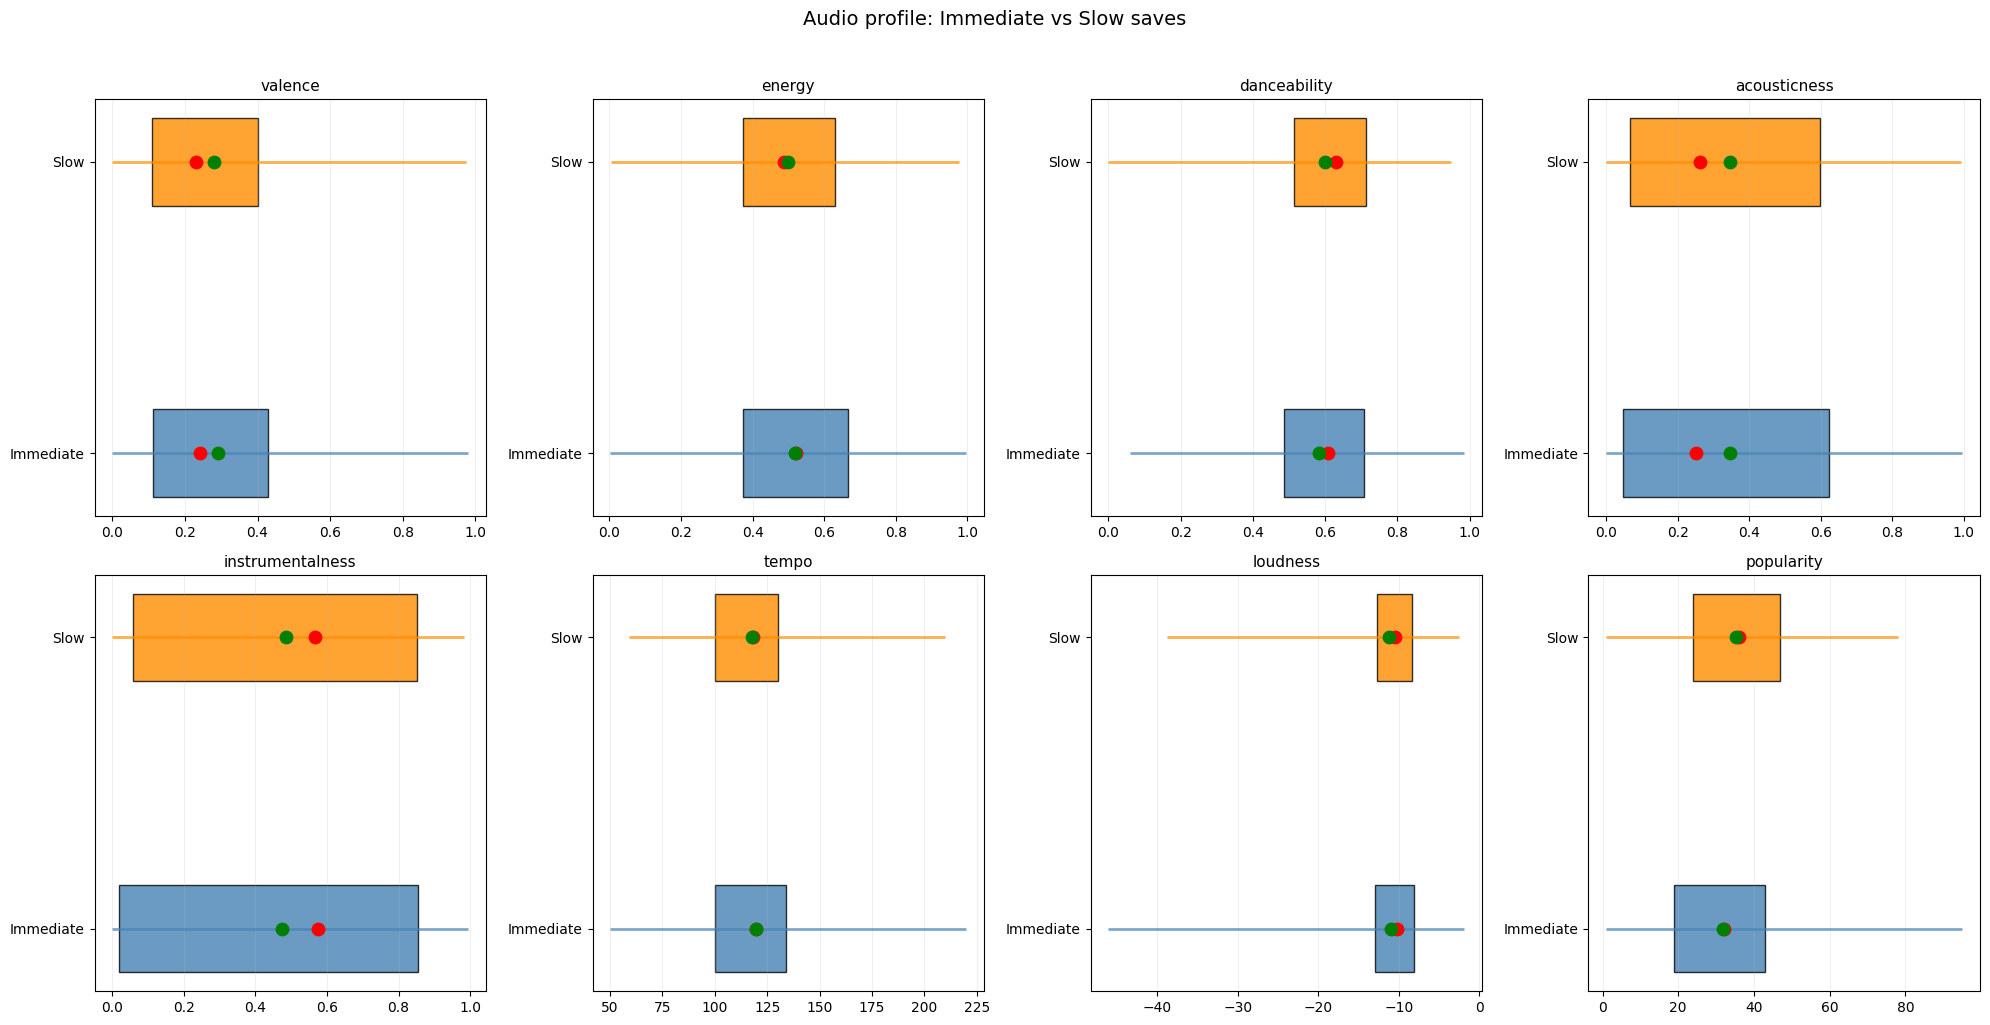


🔍 Practical significance (Immediate − Slow):
   valence: not significant (+0.011)
   energy: not significant (+0.020)
   danceability: not significant (-0.015)
   acousticness: not significant (+0.001)
   instrumentalness: not significant (-0.010)
   tempo: not significant (+1.758)
   loudness: not significant (+0.259)
   popularity: not significant (-3.293)


In [46]:
# 1.4d Аудио-профиль: Immediate vs Slow сохранения

# Сравниваем две группы треков:
#   Immediate — сохранены после 0–1 валидного прослушивания.
#   Slow      — сохранены после 2 и более валидных прослушиваний.
#
# Вопрос: отличается ли звучание треков, которые сохраняются сразу,
# от тех, что «зреют» перед добавлением в библиотеку.
#
# Различия оцениваются по порогам практической существенности:
# 0.02 для долей, 2 BPM для tempo, 1 дБ для loudness, 5 пунктов для popularity.

if 'final_all' not in globals():
    print('⚠️ final_all not found. Run cell 1.4b first.')
else:
    features = ['valence', 'energy', 'danceability', 'acousticness',
                'instrumentalness', 'tempo', 'loudness', 'popularity']

    # Аудио-характеристики по уникальным трекам
    track_audio = df.drop_duplicates('spotify_track_uri')[['spotify_track_uri'] + features]
    final = final_all.merge(track_audio, on='spotify_track_uri', how='left')
    final['save_speed'] = np.where(
        final['listen_count_before_save'] <= 1,
        'Immediate (0-1)',
        'Slow (2+)'
    )

    # --- Таблица средних и медиан ---
    comp = pd.DataFrame({
        'Immediate mean': final[final['save_speed'] == 'Immediate (0-1)'][features].mean(),
        'Immediate median': final[final['save_speed'] == 'Immediate (0-1)'][features].median(),
        'Slow mean': final[final['save_speed'] == 'Slow (2+)'][features].mean(),
        'Slow median': final[final['save_speed'] == 'Slow (2+)'][features].median(),
    }).round(3)

    comp_display = comp.reset_index().rename(columns={'index': 'Feature'})
    comp_display.index = range(1, len(comp_display) + 1)
    comp_display.index.name = '№'
    print('📊 Audio profile: Immediate vs Slow saves')
    display(comp_display)

    # --- Range plot 2x4 ---
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()

    for i, feat in enumerate(features):
        ax = axes[i]
        imm = final[final['save_speed'] == 'Immediate (0-1)'][feat].dropna()
        slow = final[final['save_speed'] == 'Slow (2+)'][feat].dropna()

        min_overall = min(imm.min(), slow.min())
        max_overall = max(imm.max(), slow.max())
        ax.set_xlim(min_overall - 0.05 * (max_overall - min_overall),
                    max_overall + 0.05 * (max_overall - min_overall))

        for (data, label, color, y) in [(imm, 'Immediate', 'steelblue', 0),
                                        (slow, 'Slow', 'darkorange', 1)]:
            q1, q3 = data.quantile(0.25), data.quantile(0.75)
            med = data.median()
            mean = data.mean()
            ax.hlines(y=y, xmin=data.min(), xmax=data.max(), color=color, linewidth=2, alpha=0.7)
            ax.barh(y=y, width=q3 - q1, left=q1, height=0.3, color=color, edgecolor='black', alpha=0.8)
            ax.scatter(med, y, color='red', s=80, zorder=5)
            ax.scatter(mean, y, color='green', s=80, zorder=5)

        ax.set_yticks([0, 1])
        ax.set_yticklabels(['Immediate', 'Slow'])
        ax.set_title(feat, fontsize=11)
        ax.grid(axis='x', alpha=0.2)

    plt.suptitle('Audio profile: Immediate vs Slow saves', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    # --- Практическая существенность ---
    # Пороги — эвристики; вынесены локально, потому что используются только здесь.
    thresholds = {
        'valence': 0.02,
        'energy': 0.02,
        'danceability': 0.02,
        'acousticness': 0.02,
        'instrumentalness': 0.02,
        'tempo': 2.0,
        'loudness': 1.0,
        'popularity': 5.0,
    }

    print('\n🔍 Practical significance (Immediate − Slow):')
    for feat in features:
        imm_mean = final[final['save_speed'] == 'Immediate (0-1)'][feat].mean()
        slow_mean = final[final['save_speed'] == 'Slow (2+)'][feat].mean()
        diff = imm_mean - slow_mean

        if abs(diff) >= thresholds.get(feat, 0.02):
            direction = 'higher' if diff > 0 else 'lower'
            print(f'   {feat}: {direction} by {abs(diff):.3f}')
        else:
            print(f'   {feat}: not significant ({diff:+.3f})')

### 1.4d. Вывод

**Что проверяли.** Отличается ли звук треков, которые сохраняются сразу, от тех, что зреют перед сохранением.

**Результат.** Все восемь характеристик — ниже порога практической значимости. Самые заметные по величине: popularity −3.3 при пороге 5.0, tempo +1.8 при пороге 2.0. Остальные — меньше 0.02 по долям, 0.3 дБ по loudness.

**Вывод.** Immediate и Slow сохранения звучат одинаково. Скорость сохранения не связана с аудио-профилем.

Ограничение: проверялась практическая значимость разницы средних, без попарной проверки статистической значимости.

## Блок 1. Вывод

**My Music** — 43 437 событий, больше половины потока. Три группы сохранения: **Playlist** — 77.1% треков, **Liked + Playlist** — 16.3%, **Liked** — 6.5%. В историю попадают 40.4% **Playlist** и 91.1% **Liked**. Разрыв двукратный.

**Deep.** **My Music** в **deep** — 28.5% треков, 59.3% событий. Пересечение **My Music** с **Other Playlists** — 12.6% треков объединения, 61.5% событий, множитель интенсивности 4.9x.

**Звук.** **My Music** против **Other Playlists**: danceability выше на 0.041, acousticness ниже на 0.036, loudness выше на 1.404 дБ, popularity выше на 2.883. Valence на грани — 0.016 при пороге 0.02. Energy и instrumentalness не различаются.

**Сохранение.** 85.5% треков сохраняются после 0–1 **valid** прослушивания, медиана — 0. **Immediate** и **Slow** не различаются ни по одной характеристике. **Likes immediate** по годам: 98.0% в 2020, 81.7% в 2021, 65.8% в 2022, 66.9% в 2023, 83.1% в 2024, 66.4% в 2025, 68.0% в 2026. **Playlists immediate**: 83.9 / 95.3 / 86.3 / 78.1 / 80.8 / 86.0 / 69.4.

**Когорты.** Медиана дней от первого прослушивания до сохранения падает по когортам: 32–170 дней в 2020–2023 (без когорты 2023Q3), 0–101 день в 2024–2026. Когорта 2023Q3 выбивается — 479 дней на 155 треках.

**Mass_import.** Два дня — 2020-10-19 (5 065 добавлений, 98.6% месяца, 0.0% прослушано до сохранения) и 2021-03-26 (140, 31.6%, 2.1%) — исключены из анализа.

Блок 2 идёт от этой точки: механизм сохранения ищется в **session**.

Ограничение: доля **unknown** в жанрах — 42–45% во всех группах блока.

# Блок 2. Ежедневные реакции

## Блок 2. Ежедневные реакции

Блок показывает, как устроено ежедневное взаимодействие с музыкой. Сессии и их типы. Навигация. Скипы. Перемотки и возвраты. Причины окончания трека. Отдельно разбирает обсессии — зацикливание внутри одной сессии на двух уровнях.

Срез — **df** для поведения как есть, **df_deep** для обсессий. Единица анализа — **session** для навигации, сохранений и обсессий, событие для скипов и причин окончания.

**continuous** — **session**, где максимальный разрыв между соседними событиями не превышает 10 минут. Непрерывное слушание.

**interrupted** — **session**, где есть хотя бы один разрыв больше 10 минут. Прерывистое слушание с паузами.

**zero-ms event** — событие с `ms_played` = 0. Пользователь нажал play, pause или переключил трек, но музыка не играла ни секунды. Чистое навигационное действие.

**saved_before** — трек был сохранён в **My Music** до начала **session**, в которой он встретился.

**saved_after** — трек сохранён после начала **session**. Может быть в течение сессии или позже.

**never_saved** — трек не сохранён ни до, ни после сессии.

**not mine** — мгновенный скип трека, у которого до этого момента не было ни одного глубокого прослушивания. Первая реакция на незнакомое.

**context skip** — мгновенный скип трека, который уже был глубоко прослушан раньше. Пропуск знакомого.

**late skip** — скип нового трека после прослушивания ≥30 секунд. Отказ после короткого знакомства.

**fwdbtn** — причина окончания трека: пользователь перемотал вперёд.

**backbtn** — причина окончания трека: пользователь вернулся назад.

**shuffle** — режим перемешивания воспроизведения.

**base obsession** — трек встречается ≥3 раз в одной **session** и его доля среди событий сессии ≥10%. **strong obsession** — трек повторяется ≥5 раз подряд в одной **session**. Оба уровня session-scoped.

1. **session** и их типы: распределение по длительности, классификация **continuous** и **interrupted**.
2. Когда происходят сессии: по часам и дням недели, динамика по годам, одиночные сессии.
3. Нулевые события и навигация: проверка пауз, сравнение **continuous** и **interrupted**.
4. Динамический срез сохранения: **saved_before**, **saved_after**, **never_saved**.
5. Скипы в сессиях и поисковые индикаторы: длительность, годовой срез, поисковые месяцы.
6. Причины окончания: общий срез и сравнение типов сессий.
7. Скипы: базовая статистика, время суток, жанры.
8. Типы мгновенных скипов: **not mine** и **context skip**.
9. Динамика скипов и **late skip**.
10. Перемотки и возвраты: **fwdbtn** и **backbtn**.
11. Обсессии: два уровня.
12. Обсессии: динамика по годам.
13. Обсессии: топ-жанры и треки.
14. Обсессии: временной ряд и сезонность.
15. Обсессии: выживаемость и сводка.

## 2.1 Ежедневный контур: сессии и их типы


📊 Daily contour
Total events: 79,752
Total sessions: 2,633
Mean events per session: 30.3
Median events per session: 12.0
Mean session duration, min: 83.1
Median session duration, min: 38.6
Mean actual listen, min: 76.4
Median actual listen, min: 31.0

Shuffle share: 31.8%


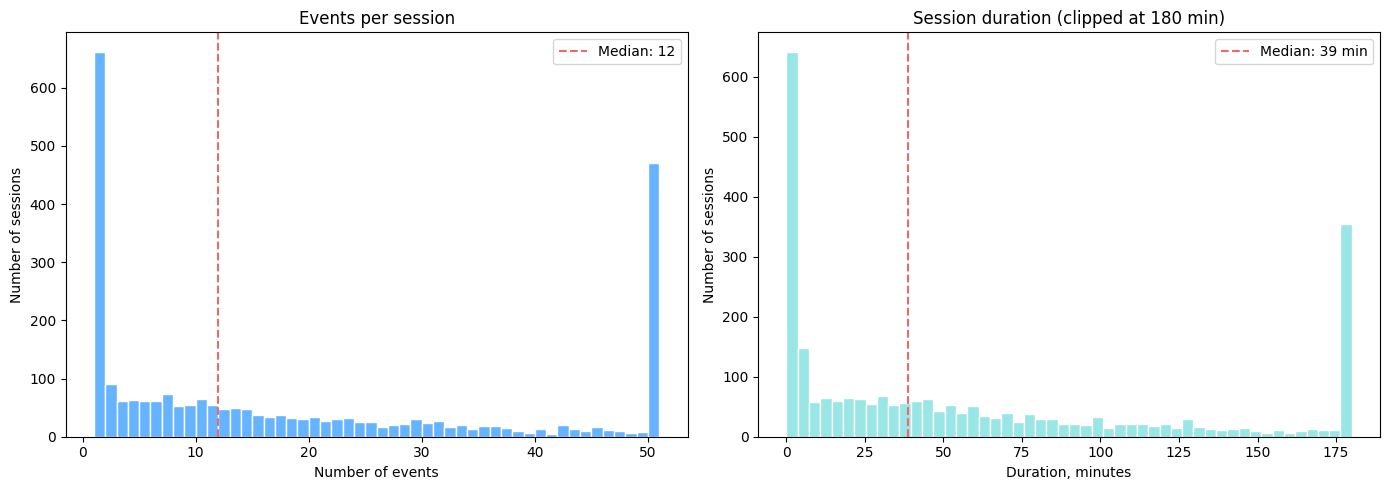


📊 Session duration distribution (min, incl. first track):
count    2633.0
mean       83.1
std       128.0
min         0.0
25%         3.9
50%        38.6
75%       102.8
90%       217.0
95%       331.6
99%       655.8
max       934.5
Name: duration_min, dtype: float64

📊 Actual listening inside session (min):
count    2633.0
mean       76.4
std       123.9
min         0.0
25%         3.3
50%        31.0
75%        92.6
90%       201.0
95%       317.0
99%       634.6
max       919.3
Name: actual_listen_min, dtype: float64

📊 Events per session distribution:
count    2633.0
mean       30.3
std        57.1
min         1.0
25%         1.0
50%        12.0
75%        34.0
90%        79.8
95%       121.4
99%       235.7
max      1079.0
Name: events, dtype: float64

📊 Top-5 longest sessions:


,Start,"Duration, min",Events,"Actual listen, min"
№,,,,
1,2025-08-13 07:05:07,934.5,253,916.7
2,2022-01-29 10:28:03,915.3,276,919.3
3,2026-05-08 06:54:32,894.0,232,839.1
4,2026-03-18 08:03:45,892.7,195,801.7
5,2025-12-21 11:20:53,889.0,154,858.4



📊 Gaps between events within sessions (min):
count    77119.00
mean         2.76
std          2.88
min          0.00
25%          0.17
50%          2.82
75%          4.17
90%          5.62
95%          7.02
99%         12.91
max         30.00
Name: gap_min, dtype: float64


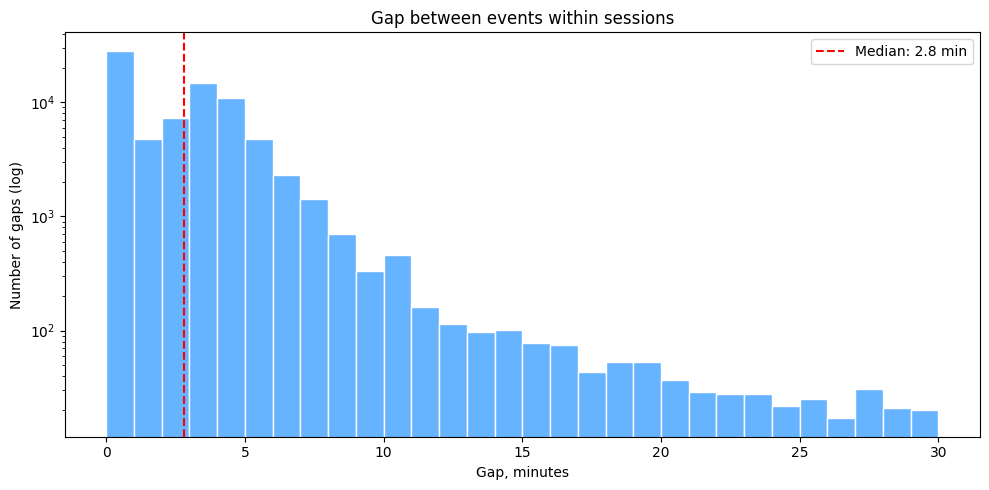


📊 Share of gaps by threshold:
   ≤ 1 min: 36.7%
   ≤ 2 min: 43.0%
   ≤ 5 min: 85.9%
   ≤10 min: 98.1%
   ≤20 min: 99.7%
   ≤30 min: 100.0%

📊 Session types:


,Session type,Sessions,"Share, %"
№,,,
1,continuous,1754,66.6
2,interrupted,879,33.4



📊 Comparison: continuous vs interrupted sessions:


,Session type,sessions,mean_duration_min,median_duration_min,mean_events,median_events,mean_actual_listen_min,median_actual_listen_min
№,,,,,,,,
1,continuous,1754,50.6,12.8,21.0,6.0,50.2,12.4
2,interrupted,879,148.0,92.3,48.8,28.0,128.5,73.7


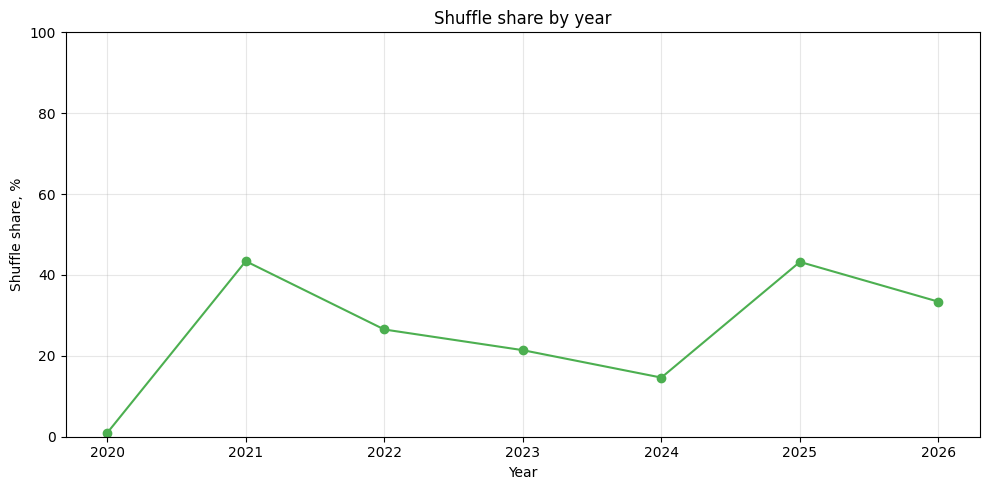


📊 Shuffle share by year:


,Year,"Shuffle, %"
№,,
1,2020,0.9
2,2021,43.4
3,2022,26.5
4,2023,21.4
5,2024,14.6
6,2025,43.2
7,2026,33.4


In [47]:
# 2.1 Ежедневный контур: сессии и их типы

# Три части одной логической цепочки:
#   1. Базовые метрики сессий: сколько, какой длины, сколько событий.
#   2. Разрывы внутри сессий: как определяется граница прерывистости.
#   3. Классификация сессий: continuous vs interrupted.
#
# Сессии уже созданы в блоке 0 по df_deep, но для этой ячейки
# нужны сессии по всем событиям (df), чтобы видеть полную картину
# повседневного взаимодействия, включая скипы и короткие включения.

# ==========================================
# ЧАСТЬ 1: Создание сессий по всем событиям
# ==========================================
df_all = df.copy()
df_all['ts'] = pd.to_datetime(df_all['ts'], errors='coerce').dt.tz_localize(None)
df_all = df_all.sort_values(['account', 'ts']).reset_index(drop=True)

# Разрыв >30 минут = новая сессия внутри аккаунта
df_all['prev_ts'] = df_all.groupby('account')['ts'].shift(1)
df_all['gap_min'] = (df_all['ts'] - df_all['prev_ts']).dt.total_seconds() / 60
df_all['new_session'] = (df_all['gap_min'] > 30) | (df_all['gap_min'].isna())
df_all['session_id'] = df_all.groupby('account')['new_session'].cumsum()


# ==========================================
# ЧАСТЬ 2: Статистика сессий
# ==========================================
session_stats = df_all.groupby(['account', 'session_id']).agg(
    events=('ts', 'count'),
    start_ts=('ts', 'min'),
    end_ts=('ts', 'max'),
    first_ms_played=('ms_played', 'first'),
    total_ms_played=('ms_played', 'sum')
)

# Календарная длительность: от начала первого трека до конца последнего
session_stats['duration_min'] = (
    (session_stats['end_ts'] - session_stats['start_ts']).dt.total_seconds() / 60
    + session_stats['first_ms_played'] / 60000
)

# Фактическое прослушивание
session_stats['actual_listen_min'] = session_stats['total_ms_played'] / 60000


# ==========================================
# ЧАСТЬ 3: Базовые метрики
# ==========================================
total_events = len(df_all)
total_sessions = df_all.groupby(['account', 'session_id']).ngroups
shuffle_events = (df_all['shuffle'] == True).sum()
shuffle_share = shuffle_events / total_events * 100

avg_events_per_session = session_stats['events'].mean()
median_events_per_session = session_stats['events'].median()
avg_duration_min = session_stats['duration_min'].mean()
median_duration_min = session_stats['duration_min'].median()
avg_actual_listen_min = session_stats['actual_listen_min'].mean()
median_actual_listen_min = session_stats['actual_listen_min'].median()

print('📊 Daily contour')
print('=' * 50)
print(f'Total events: {total_events:,}')
print(f'Total sessions: {total_sessions:,}')
print(f'Mean events per session: {avg_events_per_session:.1f}')
print(f'Median events per session: {median_events_per_session:.1f}')
print(f'Mean session duration, min: {avg_duration_min:.1f}')
print(f'Median session duration, min: {median_duration_min:.1f}')
print(f'Mean actual listen, min: {avg_actual_listen_min:.1f}')
print(f'Median actual listen, min: {median_actual_listen_min:.1f}')
print(f'\nShuffle share: {shuffle_share:.1f}%')


# ==========================================
# ЧАСТЬ 4: Распределение событий и длительности
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Events per session
session_events_clipped = session_stats['events'].clip(upper=50)
axes[0].hist(session_events_clipped, bins=range(1, 52), color=COLORS['primary'], edgecolor='white')
median_line_0 = axes[0].axvline(
    median_events_per_session, color=COLORS['line_accent'], linestyle='--',
    label=f'Median: {median_events_per_session:.0f}'
)
axes[0].set_title('Events per session')
axes[0].set_xlabel('Number of events')
axes[0].set_ylabel('Number of sessions')
axes[0].legend(handles=[median_line_0])

# Session duration
session_duration_clipped = session_stats['duration_min'].clip(upper=180)
axes[1].hist(session_duration_clipped, bins=50, color=COLORS['secondary'], edgecolor='white')
median_line_1 = axes[1].axvline(
    median_duration_min, color=COLORS['line_accent'], linestyle='--',
    label=f'Median: {median_duration_min:.0f} min'
)
axes[1].set_title('Session duration (clipped at 180 min)')
axes[1].set_xlabel('Duration, minutes')
axes[1].set_ylabel('Number of sessions')
axes[1].legend(handles=[median_line_1])

plt.tight_layout()
plt.show()


# ==========================================
# ЧАСТЬ 5: Квантили и топ-5 длинных сессий
# ==========================================
quantiles = [0.25, 0.5, 0.75, 0.9, 0.95, 0.99]

duration_desc = session_stats['duration_min'].describe(percentiles=quantiles).round(1)
events_desc = session_stats['events'].describe(percentiles=quantiles).round(1)
actual_listen_desc = session_stats['actual_listen_min'].describe(percentiles=quantiles).round(1)

print('\n📊 Session duration distribution (min, incl. first track):')
print(duration_desc)
print('\n📊 Actual listening inside session (min):')
print(actual_listen_desc)
print('\n📊 Events per session distribution:')
print(events_desc)

# Топ-5 длинных сессий
session_stats_sorted = session_stats.sort_values('duration_min', ascending=False)
print('\n📊 Top-5 longest sessions:')
top5_display = session_stats_sorted.head(5).reset_index()[
    ['start_ts', 'duration_min', 'events', 'actual_listen_min']
]
top5_display.columns = ['Start', 'Duration, min', 'Events', 'Actual listen, min']
top5_display['Duration, min'] = top5_display['Duration, min'].round(1)
top5_display['Actual listen, min'] = top5_display['Actual listen, min'].round(1)
top5_display.index = range(1, len(top5_display) + 1)
top5_display.index.name = '№'
display(top5_display)


# ==========================================
# ЧАСТЬ 6: Разрывы внутри сессий
# ==========================================
within_session_gaps = df_all.loc[
    (~df_all['new_session']) & (df_all['gap_min'] <= 30), 'gap_min'
].dropna()

print('\n📊 Gaps between events within sessions (min):')
print(within_session_gaps.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(2))

# Гистограмма разрывов
# Линейная ось X (диапазон 0–30 мин, все данные в нём),
# лог-шкала Y (частоты различаются на порядки).
# Лог-шкала X не подходит: в данных есть gap_min = 0,
# log(0) уводит ось в -inf и ломает график.
plt.figure(figsize=(10, 5))
plt.hist(within_session_gaps, bins=range(0, 31), color=COLORS['primary'], edgecolor='white', log=True)
plt.axvline(within_session_gaps.median(), color='red', linestyle='--',
            label=f'Median: {within_session_gaps.median():.1f} min')
plt.title('Gap between events within sessions')
plt.xlabel('Gap, minutes')
plt.ylabel('Number of gaps (log)')
plt.legend()
plt.tight_layout()
plt.show()

# Доля разрывов по порогам — обоснование порога прерывистости
print('\n📊 Share of gaps by threshold:')
for threshold in [1, 2, 5, 10, 20, 30]:
    share = (within_session_gaps <= threshold).mean() * 100
    print(f'   ≤{threshold:2d} min: {share:.1f}%')


# ==========================================
# ЧАСТЬ 7: Классификация сессий
# ==========================================
# Максимальный разрыв внутри каждой сессии (без первого события)
max_gap_by_session = (
    df_all.loc[~df_all['new_session']]
        .groupby(['account', 'session_id'])['gap_min']
        .max()
        .rename('max_gap')
)
session_stats = session_stats.join(max_gap_by_session)

# Классификация: continuous если все разрывы ≤10 мин, иначе interrupted
session_stats['session_type'] = np.where(
    session_stats['max_gap'] > 10,
    'interrupted',
    'continuous'
)

print('\n📊 Session types:')
type_summary = session_stats['session_type'].value_counts().rename_axis('Session type').reset_index(name='Sessions')
type_summary['Share, %'] = (type_summary['Sessions'] / len(session_stats) * 100).round(1)
type_summary.index = range(1, len(type_summary) + 1)
type_summary.index.name = '№'
display(type_summary)

print('\n📊 Comparison: continuous vs interrupted sessions:')
compare = session_stats.groupby('session_type').agg(
    sessions=('events', 'count'),
    mean_duration_min=('duration_min', 'mean'),
    median_duration_min=('duration_min', 'median'),
    mean_events=('events', 'mean'),
    median_events=('events', 'median'),
    mean_actual_listen_min=('actual_listen_min', 'mean'),
    median_actual_listen_min=('actual_listen_min', 'median')
).round(1)
compare.index.name = 'Session type'
compare = compare.reset_index()
compare.index = range(1, len(compare) + 1)
compare.index.name = '№'
display(compare)


# ==========================================
# ЧАСТЬ 8: Shuffle по годам
# ==========================================
df_all['year'] = df_all['ts'].dt.year
shuffle_by_year = df_all.groupby('year')['shuffle'].mean() * 100

plt.figure(figsize=(10, 5))
plt.plot(shuffle_by_year.index, shuffle_by_year.values, marker='o', color=COLORS['line_success'])
plt.title('Shuffle share by year')
plt.xlabel('Year')
plt.ylabel('Shuffle share, %')
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\n📊 Shuffle share by year:')
shuffle_year_display = shuffle_by_year.round(1).reset_index()
shuffle_year_display.columns = ['Year', 'Shuffle, %']
shuffle_year_display.index = range(1, len(shuffle_year_display) + 1)
shuffle_year_display.index.name = '№'
display(shuffle_year_display)

### 2.1. Вывод

**Что смотрели.** Базовые метрики сессий: сколько их, какой длины, сколько событий. Как определяется граница прерывистости. Как классифицируются сессии.

**Результат.** 2 633 сессии на 79 752 события. Медиана — 38.6 минуты, 12 событий, 31 минута фактического прослушивания. Средние выше медиан вдвое. Медиана разрыва внутри сессий — 2.8 минуты, 98.1% укладываются в 10 минут. **continuous** — 66.6% сессий, **interrupted** — 33.4%. Медиана длительности: 12.8 минуты против 92.3. Медиана событий: 6 против 28. Медиана фактического прослушивания: 12.4 против 73.7. **shuffle** — 31.8% событий, по годам колеблется от 0.9% до 43.4% без тренда.

**Вывод.** **continuous** и **interrupted** — не две длины одного поведения, а два разных режима. По всем трём метрикам разрыв более чем семикратный.

Ограничение: порог 30 минут для границы сессии — эвристика, не выведенная из данных. Сессии 2026 неполные.

## 2.2 Когда происходят сессии


<Figure size 1200x500 with 0 Axes>

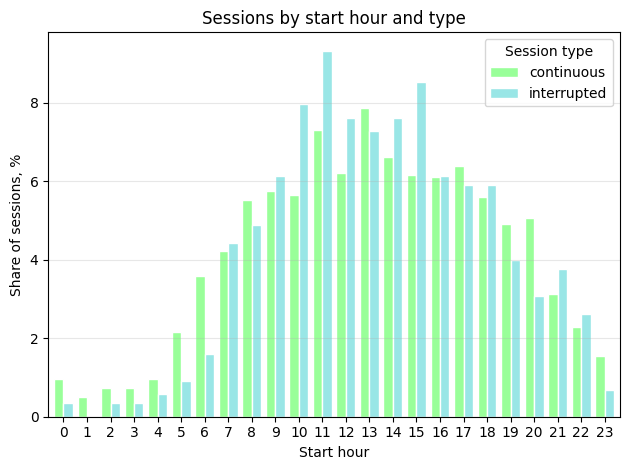

📊 Session types by start hour (share within type):


,Hour,"Continuous, %","Interrupted, %"
№,,,
1,0,1.0,0.3
2,1,0.5,0.0
3,2,0.7,0.3
4,3,0.7,0.3
5,4,1.0,0.6
6,5,2.2,0.9
7,6,3.6,1.6
8,7,4.2,4.4
9,8,5.5,4.9


<Figure size 1000x500 with 0 Axes>

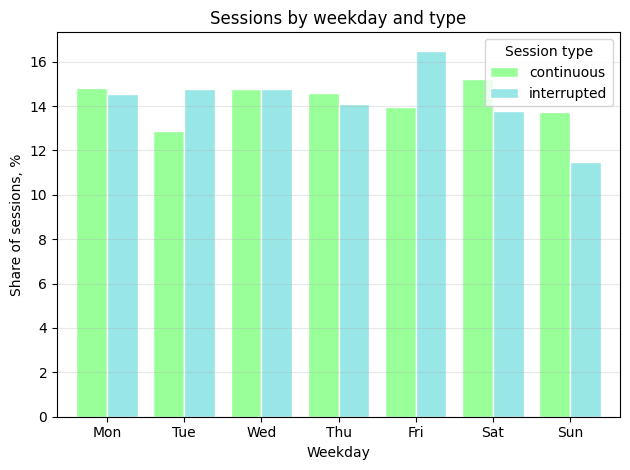


📊 Session types by weekday (share within type):


,Weekday,"Continuous, %","Interrupted, %"
№,,,
1,Mon,14.8,14.6
2,Tue,12.9,14.8
3,Wed,14.8,14.8
4,Thu,14.6,14.1
5,Fri,14.0,16.5
6,Sat,15.2,13.8
7,Sun,13.7,11.5



📊 Session dynamics by year:


,year,sessions,continuous,interrupted,median_duration_min,mean_duration_min,median_actual_min,mean_actual_min,median_events,mean_events,interrupted_share_%,continuous_share_%
№,,,,,,,,,,,,
1,2020,54,42,12,28.700000,62.400000,25.800000,58.700000,13.000000,33.200000,22.200000,77.800000
2,2021,429,354,75,34.900000,71.000000,32.900000,71.100000,12.000000,32.600000,17.500000,82.500000
3,2022,495,365,130,36.700000,62.900000,30.300000,59.000000,11.000000,21.000000,26.300000,73.700000
4,2023,466,213,253,49.300000,75.900000,38.200000,64.200000,13.000000,27.400000,54.300000,45.700000
5,2024,442,278,164,28.600000,52.100000,19.400000,43.000000,8.000000,23.900000,37.100000,62.900000
6,2025,529,357,172,38.300000,117.500000,28.700000,111.200000,14.000000,41.400000,32.500000,67.500000
7,2026,218,145,73,57.000000,153.000000,47.200000,139.500000,15.000000,38.100000,33.500000,66.500000


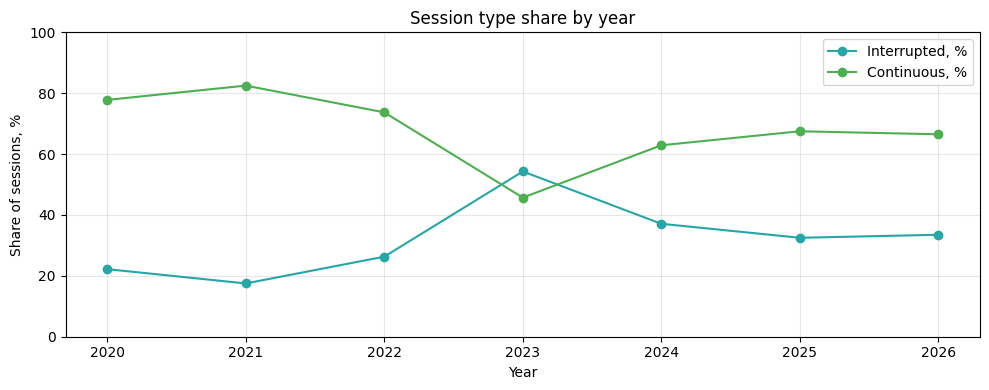

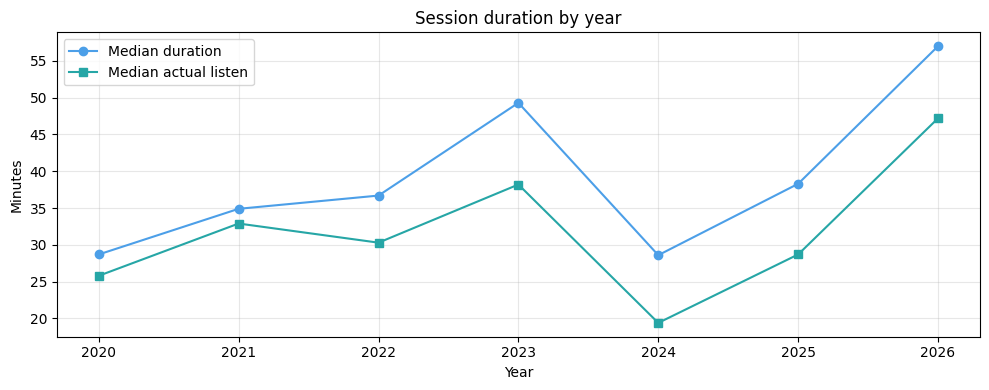


📊 Single-event sessions by year:


,Year,Total sessions,Single-event sessions,"Single-event share, %"
№,,,,
1,2020,54,11,20.400000
2,2021,429,88,20.500000
3,2022,495,131,26.500000
4,2023,466,93,20.000000
5,2024,442,150,33.900000
6,2025,529,150,28.400000
7,2026,218,39,17.900000



📊 End reasons of single-event sessions:


,Reason,"Share, %"
№,,
1,trackdone,45.1
2,fwdbtn,19.6
3,endplay,17.8
4,trackerror,6.2
5,backbtn,5.2
6,logout,5.1
7,unexpected-exit-while-paused,0.6
8,unexpected-exit,0.2
9,remote,0.2



🔍 Interpretation:
   Technical failures: 7.2%
   Logout (manual exit): 5.1%
   Behavioral endings (trackdone, fwdbtn, endplay, backbtn): 87.7%

   Single-event share ranges from 17.9% (2026) to 33.9% (2024).
   Predominance of behavioral endings confirms these are conscious short inclusions, not technical noise.


In [48]:
# 2.2 Когда происходят сессии

# Три части:
#   1. Распределение сессий по часам и дням недели.
#   2. Динамика типов сессий по годам: continuous vs interrupted.
#   3. Одиночные сессии — поведение или технический шум.
#
# session_stats и df_all созданы в 2.1.

# ==========================================
# ЧАСТЬ 1: Распределение по часам и дням недели
# ==========================================
session_stats['hour'] = session_stats['start_ts'].dt.hour
session_stats['weekday'] = session_stats['start_ts'].dt.weekday
session_stats['year'] = session_stats['start_ts'].dt.year

# Доля сессий по часам
hour_counts = session_stats.groupby(['hour', 'session_type']).size().unstack(fill_value=0)
hour_share = hour_counts.div(hour_counts.sum(axis=0), axis=1) * 100

plt.figure(figsize=(12, 5))
hour_share.plot(kind='bar', width=0.8,
                color=[COLORS['continuous'], COLORS['interrupted']],
                edgecolor='white')
plt.title('Sessions by start hour and type')
plt.xlabel('Start hour')
plt.ylabel('Share of sessions, %')
plt.xticks(rotation=0)
plt.legend(title='Session type')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

hour_table = hour_share.reset_index()
hour_table.columns = ['Hour', 'Continuous, %', 'Interrupted, %']
hour_table['Hour'] = hour_table['Hour'].astype(int)
hour_table['Continuous, %'] = hour_table['Continuous, %'].map(lambda x: f'{x:.1f}')
hour_table['Interrupted, %'] = hour_table['Interrupted, %'].map(lambda x: f'{x:.1f}')
hour_table.index = range(1, len(hour_table) + 1)
hour_table.index.name = '№'
print('📊 Session types by start hour (share within type):')
show_table(hour_table)

# Доля сессий по дням недели
weekday_counts = session_stats.groupby(['weekday', 'session_type']).size().unstack(fill_value=0)
weekday_share = weekday_counts.div(weekday_counts.sum(axis=0), axis=1) * 100
day_names = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}
weekday_share.index = [day_names[i] for i in weekday_share.index]

plt.figure(figsize=(10, 5))
weekday_share.plot(kind='bar', width=0.8,
                   color=[COLORS['continuous'], COLORS['interrupted']],
                   edgecolor='white')
plt.title('Sessions by weekday and type')
plt.xlabel('Weekday')
plt.ylabel('Share of sessions, %')
plt.xticks(rotation=0)
plt.legend(title='Session type')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

weekday_table = weekday_share.reset_index()
weekday_table.columns = ['Weekday', 'Continuous, %', 'Interrupted, %']
weekday_table['Continuous, %'] = weekday_table['Continuous, %'].map(lambda x: f'{x:.1f}')
weekday_table['Interrupted, %'] = weekday_table['Interrupted, %'].map(lambda x: f'{x:.1f}')
weekday_table.index = range(1, len(weekday_table) + 1)
weekday_table.index.name = '№'
print('\n📊 Session types by weekday (share within type):')
show_table(weekday_table)


# ==========================================
# ЧАСТЬ 2: Динамика типов сессий по годам
# ==========================================
yearly_sessions = session_stats.groupby('year').agg(
    sessions=('events', 'count'),
    continuous=('session_type', lambda x: (x == 'continuous').sum()),
    interrupted=('session_type', lambda x: (x == 'interrupted').sum()),
    median_duration_min=('duration_min', 'median'),
    mean_duration_min=('duration_min', 'mean'),
    median_actual_min=('actual_listen_min', 'median'),
    mean_actual_min=('actual_listen_min', 'mean'),
    median_events=('events', 'median'),
    mean_events=('events', 'mean')
).round(1)

yearly_sessions['interrupted_share_%'] = (
    yearly_sessions['interrupted'] / yearly_sessions['sessions'] * 100
).round(1)
yearly_sessions['continuous_share_%'] = (
    yearly_sessions['continuous'] / yearly_sessions['sessions'] * 100
).round(1)

print('\n📊 Session dynamics by year:')
yearly_display = yearly_sessions.reset_index()
yearly_display.index = range(1, len(yearly_display) + 1)
yearly_display.index.name = '№'
show_table(yearly_display)

# Доля типов по годам
plt.figure(figsize=(10, 4))
plt.plot(yearly_sessions.index, yearly_sessions['interrupted_share_%'],
         marker='o', color=COLORS['line_secondary'], label='Interrupted, %')
plt.plot(yearly_sessions.index, yearly_sessions['continuous_share_%'],
         marker='o', color=COLORS['line_success'], label='Continuous, %')
plt.title('Session type share by year')
plt.xlabel('Year')
plt.ylabel('Share of sessions, %')
plt.ylim(0, 100)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Медианная длительность по годам
plt.figure(figsize=(10, 4))
plt.plot(yearly_sessions.index, yearly_sessions['median_duration_min'],
         marker='o', color=COLORS['line_primary'], label='Median duration')
plt.plot(yearly_sessions.index, yearly_sessions['median_actual_min'],
         marker='s', color=COLORS['line_secondary'], label='Median actual listen')
plt.title('Session duration by year')
plt.xlabel('Year')
plt.ylabel('Minutes')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# ЧАСТЬ 3: Одиночные сессии
# ==========================================
session_stats_flat = session_stats.reset_index()

single_event_sessions = session_stats_flat[session_stats_flat['events'] == 1].copy()
single_event_sessions['year'] = single_event_sessions['start_ts'].dt.year

total_sessions_by_year = session_stats_flat.groupby(
    session_stats_flat['start_ts'].dt.year
).size()

year_counts = single_event_sessions['year'].value_counts().sort_index()
comparison = pd.DataFrame({
    'Total sessions': total_sessions_by_year,
    'Single-event sessions': year_counts,
    'Single-event share, %': (year_counts / total_sessions_by_year * 100).round(1)
}).fillna(0)
comparison.index.name = 'Year'
comparison = comparison.reset_index()
comparison.index = range(1, len(comparison) + 1)
comparison.index.name = '№'

print('\n📊 Single-event sessions by year:')
show_table(comparison)

# Причины окончания у одиночных сессий
single_event_df = df_all[df_all['session_id'].isin(single_event_sessions['session_id'])]
reason_counts = single_event_df['reason_end'].value_counts(normalize=True) * 100
reason_counts = reason_counts.round(1)

print('\n📊 End reasons of single-event sessions:')
reason_display = reason_counts.reset_index()
reason_display.columns = ['Reason', 'Share, %']
reason_display['Share, %'] = reason_display['Share, %'].map(lambda x: f'{x:.1f}')
reason_display.index = range(1, len(reason_display) + 1)
reason_display.index.name = '№'
show_table(reason_display)

# Автоинтерпретация без хардкода
tech_reasons = ['trackerror', 'unexpected-exit', 'unexpected-exit-while-paused', 'remote']
tech_share = reason_counts.reindex(tech_reasons).fillna(0).sum()
logout_share = reason_counts.get('logout', 0)
behavioral_share = 100 - tech_share - logout_share

print('\n🔍 Interpretation:')
print(f'   Technical failures: {tech_share:.1f}%')
print(f'   Logout (manual exit): {logout_share:.1f}%')
print(f'   Behavioral endings (trackdone, fwdbtn, endplay, backbtn): {behavioral_share:.1f}%')

max_year = comparison.loc[comparison['Single-event share, %'].idxmax(), 'Year']
max_share = comparison['Single-event share, %'].max()
min_year = comparison.loc[comparison['Single-event share, %'].idxmin(), 'Year']
min_share = comparison['Single-event share, %'].min()

print(f'\n   Single-event share ranges from {min_share:.1f}% ({min_year}) to {max_share:.1f}% ({max_year}).')
print('   Predominance of behavioral endings confirms these are conscious short inclusions, not technical noise.')

### 2.2. Вывод

**Что смотрели.** Когда начинаются сессии — по часам и дням недели. Как менялись типы сессий по годам. Что представляют собой одиночные сессии.

**Результат.** Сессии начинаются днём и вечером, пик — 11–15 часов. Ночью почти нет. По дням недели различий нет: разброс в пределах 4 п.п., тренда нет. По годам доля **interrupted** колеблется: 17.5% в 2021, 54.3% в 2023, 33.5% в 2026. 2023 — единственный год, когда **interrupted** превысили **continuous**. Медиана длительности сессии: 28.6 минуты в 2024, 57.0 в 2026 — провал 2024 ниже даже 2020. Одиночные сессии — 17.9% (2026) до 33.9% (2024). Поведенческие окончания — 87.7%, технические сбои — 7.2%.

**Вывод.** Время начала и день недели не различают типы сессий: это не зависит от расписания. Год 2023 — выброс: **interrupted** стали основным типом, а в остальные годы **continuous** занимают 63–83%. Провал 2024 по медианной длительности совпадает с общим спадом по часам в тот год. Одиночные сессии — сознательные короткие включения, а не технический шум: почти 88% заканчиваются поведенческими причинами. Это согласуется с 2.1: **continuous** и **interrupted** — два режима, и одиночная сессия — третий, самый короткий.

Ограничение: 2026 неполный, данные обрываются в августе.

## 2.3 Поиск и отвлечение: нулевые события и навигация


📊 Correlation: zero-event share vs calendar−actual gap
   Pearson:  r = 0.018, p = 0.361
   Spearman: r = 0.227, p = 0.000


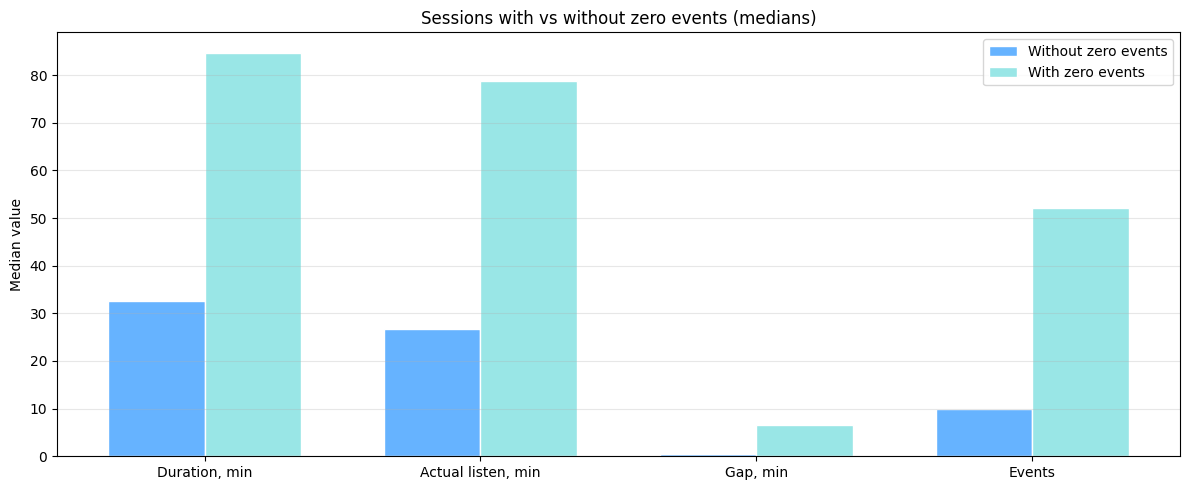


📊 Top-5 sessions with largest calendar−actual gap:


,Start,"Duration, min","Actual listen, min","Gap, min",Zero events,Total events
№,,,,,,
1,2024-08-16 09:04:14,338.1,185.3,152.9,0,93
2,2026-03-22 08:34:26,778.4,650.6,127.8,0,202
3,2023-06-25 10:39:16,288.6,193.8,94.8,0,66
4,2023-01-18 16:33:32,146.7,52.4,94.3,0,18
5,2026-03-18 08:03:45,892.7,801.7,91.0,0,195


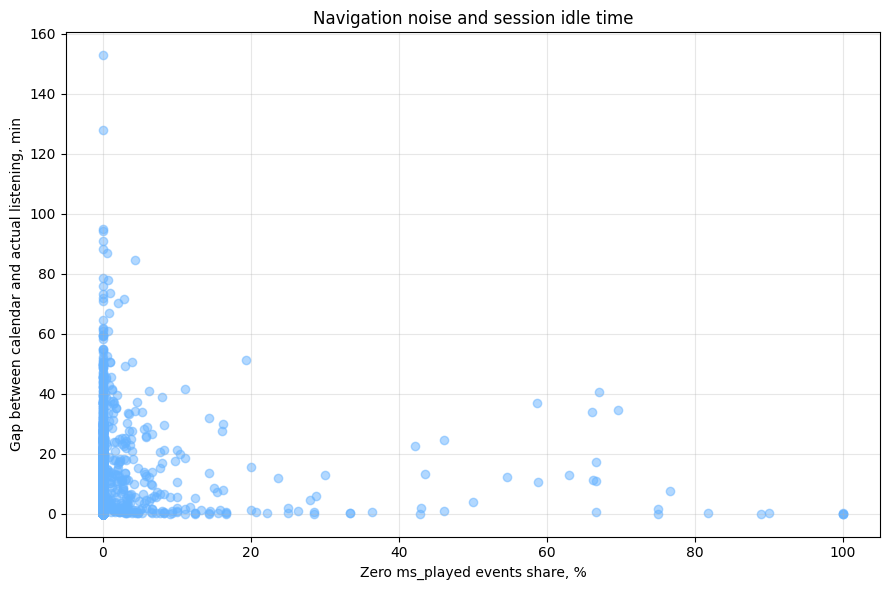

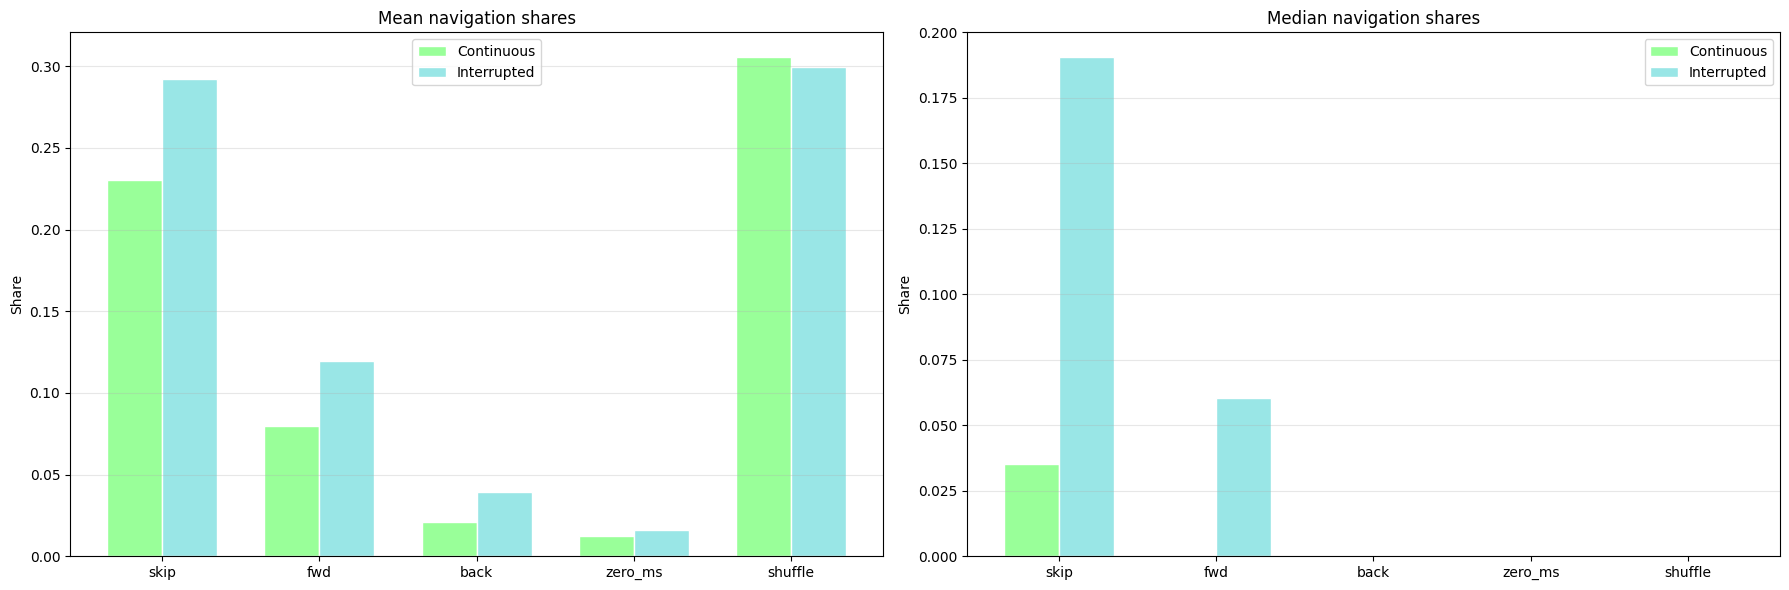


📊 Mean navigation shares:


,Metric,Continuous,Interrupted
№,,,
1,skip_share,0.230,0.292
2,fwd_share,0.080,0.119
3,back_share,0.021,0.039
4,zero_ms_share,0.012,0.016
5,shuffle_share,0.305,0.300



📊 Median navigation shares:


,Metric,Continuous,Interrupted
№,,,
1,skip_share,0.035,0.190
2,fwd_share,0.000,0.061
3,back_share,0.000,0.000
4,zero_ms_share,0.000,0.000
5,shuffle_share,0.000,0.000



📊 Statistical significance (Mann-Whitney):
   skip_share: p=6.395e-29
   fwd_share: p=4.819e-43
   back_share: p=6.764e-31
   zero_ms_share: p=2.664e-09
   shuffle_share: p=3.437e-01


In [49]:
# 2.3 Поиск и отвлечение: нулевые события и навигация

# Две части:
#   1. Проверка: не объясняются ли паузы техническими нулевыми событиями
#      (ms_played = 0).
#   2. Сравнение навигационной активности в continuous vs interrupted сессиях.
#
# session_stats, df_all — из 2.1.
# ==========================================
# ЧАСТЬ 1: Нулевые события и паузы
# ==========================================
if 'session_id' not in session_stats.columns:
    session_stats = session_stats.reset_index()

# Доля нулевых событий в каждой сессии
zero_share_by_session = (
    df_all.assign(is_zero_ms=(df_all['ms_played'] == 0))
        .groupby(['account', 'session_id'])
        .agg(zero_share=('is_zero_ms', 'mean'), zero_count=('is_zero_ms', 'sum'))
        .reset_index()
)

session_stats_with_zero = session_stats.merge(
    zero_share_by_session, on=['account', 'session_id'], how='left'
)
session_stats_with_zero['zero_share'] = session_stats_with_zero['zero_share'].fillna(0)
session_stats_with_zero['zero_count'] = session_stats_with_zero['zero_count'].fillna(0).astype(int)

# Разница между календарной и фактической длительностью
session_stats_with_zero['gap_min'] = (
    session_stats_with_zero['duration_min'] - session_stats_with_zero['actual_listen_min']
)

# Флаг: есть ли в сессии хотя бы одно нулевое событие
session_stats_with_zero['has_zero'] = session_stats_with_zero['zero_count'] > 0

# Корреляция между долей нулевых событий и разрывом
df_corr = session_stats_with_zero[['zero_share', 'gap_min', 'zero_count']].copy()
df_corr = df_corr[df_corr['gap_min'] >= 0]

pearson_r, pearson_p = stats.pearsonr(df_corr['zero_share'], df_corr['gap_min'])
spearman_r, spearman_p = stats.spearmanr(df_corr['zero_share'], df_corr['gap_min'])

print('📊 Correlation: zero-event share vs calendar−actual gap')
print(f'   Pearson:  r = {pearson_r:.3f}, p = {pearson_p:.3f}')
print(f'   Spearman: r = {spearman_r:.3f}, p = {spearman_p:.3f}')

# --- Сравнение: сессии с нулевыми событиями vs без ---
# Медианы по 4 метрикам — grouped bar вместо wide-таблицы.
metrics = ['duration_min', 'actual_listen_min', 'gap_min', 'events']
metric_labels = ['Duration, min', 'Actual listen, min', 'Gap, min', 'Events']

grouped_agg = session_stats_with_zero.groupby('has_zero')[
    ['duration_min', 'actual_listen_min', 'gap_min', 'events']
].median()

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(metrics))
width = 0.35

ax.bar(x - width/2, grouped_agg.loc[False], width,
       label='Without zero events', color=COLORS['primary'], edgecolor='white')
ax.bar(x + width/2, grouped_agg.loc[True], width,
       label='With zero events', color=COLORS['interrupted'], edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylabel('Median value')
ax.set_title('Sessions with vs without zero events (medians)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# --- Топ-5 сессий с максимальным разрывом ---
top_gap = session_stats_with_zero.sort_values('gap_min', ascending=False).head(5)
print('\n📊 Top-5 sessions with largest calendar−actual gap:')
top_gap_display = top_gap[
    ['start_ts', 'duration_min', 'actual_listen_min', 'gap_min', 'zero_count', 'events']
].copy()
top_gap_display.columns = ['Start', 'Duration, min', 'Actual listen, min', 'Gap, min', 'Zero events', 'Total events']
top_gap_display[['Duration, min', 'Actual listen, min', 'Gap, min']] = top_gap_display[
    ['Duration, min', 'Actual listen, min', 'Gap, min']
].round(1)
top_gap_display.index = range(1, len(top_gap_display) + 1)
top_gap_display.index.name = '№'
display(top_gap_display)

# --- Scatter: доля нулевых событий vs разрыв ---
plt.figure(figsize=(9, 6))
plt.scatter(df_corr['zero_share'] * 100, df_corr['gap_min'],
            alpha=0.5, color=COLORS['primary'])
plt.xlabel('Zero ms_played events share, %')
plt.ylabel('Gap between calendar and actual listening, min')
plt.title('Navigation noise and session idle time')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# ==========================================
# ЧАСТЬ 2: Навигация в continuous vs interrupted
# ==========================================
if 'session_type' not in df_all.columns:
    mapping = session_stats.reset_index()[
        ['account', 'session_id', 'session_type']
    ].drop_duplicates()
    df_all = df_all.merge(mapping, on=['account', 'session_id'], how='left')

df_all['is_fwd'] = df_all['reason_end'] == 'fwdbtn'
df_all['is_back'] = df_all['reason_end'] == 'backbtn'
df_all['is_zero_ms'] = df_all['ms_played'] == 0

session_behavior = df_all.groupby(['account', 'session_id']).agg(
    events=('ts', 'count'),
    skip_share=('is_skip', 'mean'),
    fwd_share=('is_fwd', 'mean'),
    back_share=('is_back', 'mean'),
    zero_ms_share=('is_zero_ms', 'mean'),
    shuffle_share=('shuffle', lambda x: (x == True).mean())
).reset_index()

session_behavior = session_behavior.merge(
    session_stats.reset_index()[
        ['account', 'session_id', 'session_type']
    ].drop_duplicates(),
    on=['account', 'session_id'], how='left'
)

compare_cols = ['skip_share', 'fwd_share', 'back_share', 'zero_ms_share', 'shuffle_share']

# --- Средние и медианы: один grouped bar на два показателя ---
mean_vals = session_behavior.groupby('session_type')[compare_cols].mean()
median_vals = session_behavior.groupby('session_type')[compare_cols].median()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, vals, title in [
    (axes[0], mean_vals, 'Mean navigation shares'),
    (axes[1], median_vals, 'Median navigation shares'),
]:
    x = np.arange(len(compare_cols))
    width = 0.35
    ax.bar(x - width/2, vals.loc['continuous'], width,
           label='Continuous', color=COLORS['continuous'], edgecolor='white')
    ax.bar(x + width/2, vals.loc['interrupted'], width,
           label='Interrupted', color=COLORS['interrupted'], edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels([c.replace('_share', '') for c in compare_cols])
    ax.set_ylabel('Share')
    ax.set_title(title)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- Таблицы со средними и медианами (компактные) ---
mean_table = mean_vals.T.round(3).reset_index()
mean_table.columns = ['Metric', 'Continuous', 'Interrupted']
mean_table.index = range(1, len(mean_table) + 1)
mean_table.index.name = '№'
print('\n📊 Mean navigation shares:')
display(mean_table)

median_table = median_vals.T.round(3).reset_index()
median_table.columns = ['Metric', 'Continuous', 'Interrupted']
median_table.index = range(1, len(median_table) + 1)
median_table.index.name = '№'
print('\n📊 Median navigation shares:')
display(median_table)

# --- Статистическая значимость ---
cont = session_behavior[session_behavior['session_type'] == 'continuous']
intr = session_behavior[session_behavior['session_type'] == 'interrupted']

print('\n📊 Statistical significance (Mann-Whitney):')
for col in compare_cols:
    u_stat, p_value = stats.mannwhitneyu(
        cont[col].dropna(), intr[col].dropna(), alternative='two-sided'
    )
    print(f'   {col}: p={p_value:.3e}')

### 2.3. Вывод

**Что проверяли.** Может ли большое количество нулевых событий
(**ms_played** = 0) объяснить разницу между календарной
длительностью сессии и фактическим прослушиванием. И отличаются
ли **interrupted** от **continuous** по навигационной активности.

**Результат.** Корреляция между долей нулевых событий и разрывом
неоднозначна. Pearson r=0.018 (p=0.361) — линейной связи нет.
Spearman r=0.227 (p<0.001) — ранговая связь слабая, но значимая.
Разница между метриками означает: линейной зависимости нет,
но при росте доли нулевых событий разрыв слегка увеличивается
нелинейно. Пять сессий с наибольшим разрывом (91–153 минуты)
не содержат ни одного нулевого события.

Навигационные доли по медианам: **skip_share** 0.190 у
**interrupted** против 0.035 у **continuous**, **fwd_share** 0.061
против 0, **back_share** и **zero_ms_share** — 0 в обеих группах,
**shuffle_share** — 0.300 против 0.305 (p=0.34, не значимо).
По средним разрыв меньше из-за хвостов: 0.292 против 0.230 по skip,
0.119 против 0.080 по fwd.

**Вывод.** Нулевые события не объясняют паузы. Разрыв между
календарной длительностью и фактическим прослушиванием создают
длительные промежутки между треками внутри сессии — это реальные
паузы в поведении, не технический шум. **interrupted** — сессии
активной навигации: пользователь чаще скипает, перематывает,
возвращается. Режим shuffle разницу не объясняет.

## 2.4 Динамический срез сохранения


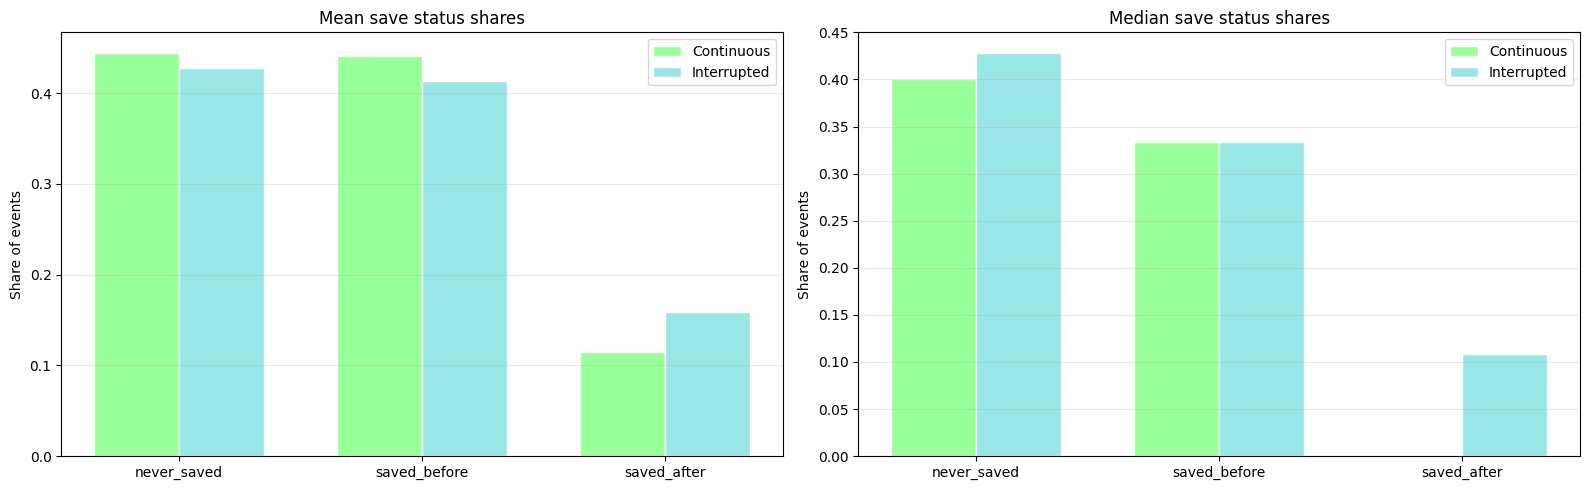

📊 Mean save status shares:


,Metric,Continuous,Interrupted
№,,,
1,never_saved_share,0.445,0.428
2,saved_before_share,0.441,0.413
3,saved_after_share,0.114,0.159



📊 Median save status shares:


,Metric,Continuous,Interrupted
№,,,
1,never_saved_share,0.400,0.429
2,saved_before_share,0.333,0.333
3,saved_after_share,0.000,0.108



📊 Statistical significance (Mann-Whitney):
   never_saved_share: p=5.234e-01
   saved_before_share: p=6.834e-01
   saved_after_share: p=6.263e-42


In [50]:
# 2.4 Динамический срез сохранения

# Ключевой вопрос блока: являются ли прерывистые сессии поиском нового?
#
# Для каждого события классифицируем статус сохранения:
#   saved_before — трек был сохранён ДО начала сессии
#   saved_after  — трек сохранён ПОСЛЕ (в течение или после сессии)
#   never_saved  — трек так и не был сохранён
#
# Если в прерывистых сессиях выше доля saved_after — это поиск.
# Если выше saved_before — это воспроизведение знакомого.
#
# df_all, session_stats — из 2.1.

# --- Подготовка first_save_date ---
track_dates = pd.read_parquet(BASE_PATH / 'track_dates.parquet')
track_dates['library_added_at'] = pd.to_datetime(track_dates['library_added_at'], errors='coerce').dt.tz_localize(None)
track_dates['first_playlist_added_at'] = pd.to_datetime(track_dates['first_playlist_added_at'], errors='coerce').dt.tz_localize(None)
track_dates['first_save_date'] = track_dates[['library_added_at', 'first_playlist_added_at']].min(axis=1)

# --- Временные границы сессий + first_save_date ---
session_times = session_stats.reset_index()[
    ['account', 'session_id', 'start_ts', 'end_ts']
].drop_duplicates()

# Убираем возможные старые копии, чтобы не было _x/_y
df_work = df_all.drop(columns=['start_ts', 'end_ts', 'first_save_date', 'save_status'],
                      errors='ignore').copy()

df_work = df_work.merge(session_times, on=['account', 'session_id'], how='left')
df_work = df_work.merge(
    track_dates[['spotify_track_uri', 'first_save_date']],
    on='spotify_track_uri', how='left'
)

# --- Классификация ---
def classify_save_status(row):
    if pd.isna(row['first_save_date']):
        return 'never_saved'
    elif row['first_save_date'] < row['start_ts']:
        return 'saved_before'
    else:
        return 'saved_after'

df_work['save_status'] = df_work.apply(classify_save_status, axis=1)

# --- Агрегация по сессиям ---
session_save = df_work.groupby(['account', 'session_id']).agg(
    total_events=('ts', 'count'),
    never_saved_share=('save_status', lambda x: (x == 'never_saved').mean()),
    saved_before_share=('save_status', lambda x: (x == 'saved_before').mean()),
    saved_after_share=('save_status', lambda x: (x == 'saved_after').mean())
).reset_index()

# Присоединяем тип сессии
session_save = session_save.merge(
    session_stats.reset_index()[
        ['account', 'session_id', 'session_type']
    ].drop_duplicates(),
    on=['account', 'session_id'], how='left'
)

# --- Сравнение ---
compare_cols = ['never_saved_share', 'saved_before_share', 'saved_after_share']

mean_save = session_save.groupby('session_type')[compare_cols].mean()
median_save = session_save.groupby('session_type')[compare_cols].median()

# --- Визуализация: grouped bar по mean и median ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, vals, title in [
    (axes[0], mean_save, 'Mean save status shares'),
    (axes[1], median_save, 'Median save status shares'),
]:
    x = np.arange(len(compare_cols))
    width = 0.35
    ax.bar(x - width/2, vals.loc['continuous'], width,
           label='Continuous', color=COLORS['continuous'], edgecolor='white')
    ax.bar(x + width/2, vals.loc['interrupted'], width,
           label='Interrupted', color=COLORS['interrupted'], edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels([c.replace('_share', '') for c in compare_cols])
    ax.set_ylabel('Share of events')
    ax.set_title(title)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- Компактные таблицы ---
mean_table = mean_save.T.round(3).reset_index()
mean_table.columns = ['Metric', 'Continuous', 'Interrupted']
mean_table.index = range(1, len(mean_table) + 1)
mean_table.index.name = '№'
print('📊 Mean save status shares:')
display(mean_table)

median_table = median_save.T.round(3).reset_index()
median_table.columns = ['Metric', 'Continuous', 'Interrupted']
median_table.index = range(1, len(median_table) + 1)
median_table.index.name = '№'
print('\n📊 Median save status shares:')
display(median_table)

# --- Статистическая значимость ---
cont_save = session_save[session_save['session_type'] == 'continuous']
intr_save = session_save[session_save['session_type'] == 'interrupted']

print('\n📊 Statistical significance (Mann-Whitney):')
for col in compare_cols:
    u, p = stats.mannwhitneyu(
        cont_save[col].dropna(), intr_save[col].dropna(), alternative='two-sided'
    )
    print(f'   {col}: p={p:.3e}')

### 2.4. Вывод

**Что проверяли.** Являются ли **interrupted** поиском нового. Каждое событие внутри сессии классифицируется по статусу сохранения — **saved_before** (трек сохранён до сессии), **saved_after** (сохранён после), **never_saved** (не сохранён).

**Результат.** По средним долям разница между типами сессий слабая: **never_saved_share** 0.428 у **interrupted** против 0.445 у **continuous** (p=0.52), **saved_before_share** 0.413 против 0.441 (p=0.68), **saved_after_share** 0.159 против 0.114 (p<0.001). По медианам разрыв резкий: **saved_after_share** 0.108 у **interrupted** против 0.000 у **continuous**. Медианы **never_saved** и **saved_before** совпадают или почти совпадают — 0.429 против 0.400 и 0.333 против 0.333.

**Вывод.** Связь **interrupted** с будущими сохранениями — ключевой результат блока. В типичной **continuous** сессии медианная доля **saved_after** равна нулю. В типичной **interrupted** — 0.108. **continuous** и **interrupted** не различаются по долям **never_saved** и **saved_before** ни по средним, ни по медианам. Различие — только в **saved_after**.

## 2.5 Скипы в сессиях и поисковые индикаторы


📊 Duration categories summary:


,Category,Events,"Share of all, %",Skip share,Fwd share,Back share,Zero ms share,Trackerror share,Endplay share
№,,,,,,,,,
1,10-30 sec,6341,7.951,0.579,0.385,0.036,0.000,0.000,0.520
2,30+ sec,52984,66.436,0.074,0.054,0.008,0.000,0.000,0.044
3,<10 sec,20427,25.613,1.000,0.403,0.122,0.119,0.092,0.357



📊 Duration distribution within session types:


,Session type,"<10 sec, %","10-30 sec, %","30+ sec, %"
№,,,,
1,continuous,8.7,65.4,25.9
2,interrupted,7.3,67.3,25.3


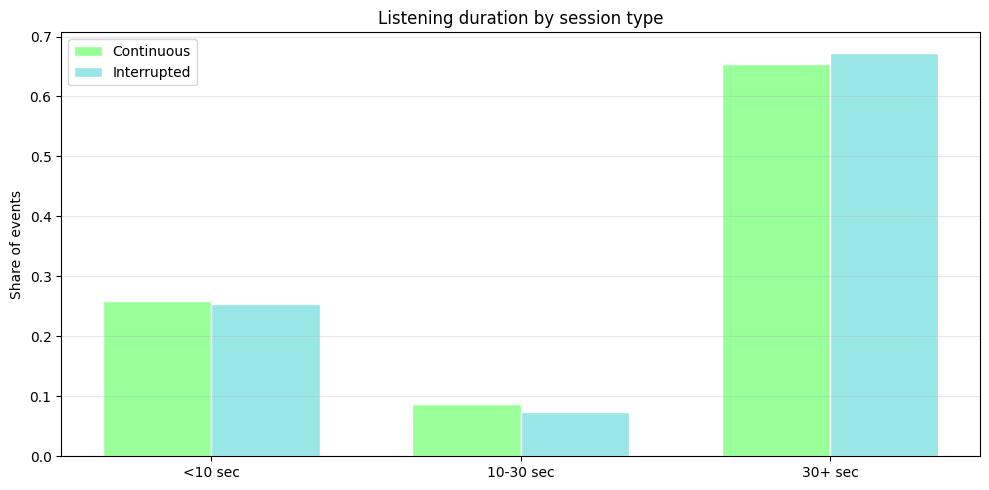


📊 Statistical significance (duration categories between session types):
   <10 sec: Continuous=0.259, Interrupted=0.253, p=4.664e-02
   10-30 sec: Continuous=0.087, Interrupted=0.073, p=7.689e-12
   30+ sec: Continuous=0.654, Interrupted=0.673, p=8.405e-09

📊 Yearly save-status dynamics by session type:


,Year,Session type,Sessions,Mean saved_after,Median saved_after,Mean saved_before,Median saved_before,Mean never,Median never
№,,,,,,,,,
1,2020,continuous,42,0.149000,0.012000,0.303000,0.241000,0.548000,0.500000
2,2020,interrupted,12,0.190000,0.207000,0.206000,0.130000,0.604000,0.594000
3,2021,continuous,354,0.107000,0.000000,0.386000,0.259000,0.507000,0.535000
4,2021,interrupted,75,0.131000,0.034000,0.512000,0.525000,0.357000,0.310000
5,2022,continuous,365,0.096000,0.000000,0.414000,0.262000,0.490000,0.500000
6,2022,interrupted,130,0.139000,0.099000,0.382000,0.317000,0.479000,0.515000
7,2023,continuous,213,0.169000,0.000000,0.419000,0.292000,0.412000,0.322000
8,2023,interrupted,253,0.190000,0.167000,0.375000,0.333000,0.435000,0.439000
9,2024,continuous,278,0.125000,0.000000,0.433000,0.225000,0.441000,0.333000


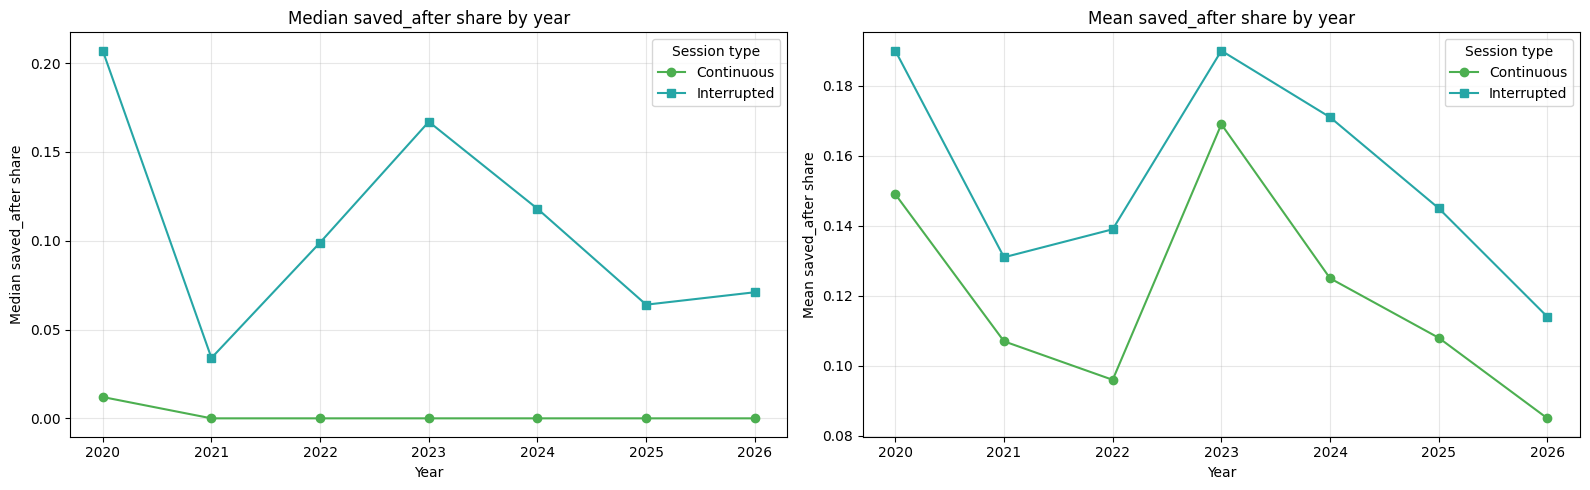


📊 Search month indicators (V1 and V2):


,Month,interrupted_count,avg_saved_after,avg_skip_share,interrupted_share,composite_z,search_v1,search_v2
№,,,,,,,,
1,2020-05,1,0.214000,0.071000,0.250000,-1.112000,False,False
2,2020-10,5,0.205000,0.225000,0.385000,0.623000,False,False
3,2020-11,6,0.174000,0.325000,0.240000,0.040000,False,False
4,2021-01,3,0.000000,0.279000,0.231000,-2.344000,False,False
5,2021-02,13,0.033000,0.084000,0.351000,-2.515000,False,False
6,2021-03,11,0.163000,0.214000,0.256000,-0.729000,False,False
7,2021-04,6,0.283000,0.125000,0.171000,-0.444000,False,False
8,2021-05,1,0.446000,0.214000,0.045000,1.281000,True,False
9,2021-06,10,0.129000,0.279000,0.185000,-1.120000,False,False



🔍 Months selected by at least one indicator: 15
['2021-05', '2021-11', '2023-03', '2023-04', '2023-05', '2023-06', '2023-08', '2023-09', '2024-02', '2024-10', '2024-11', '2024-12', '2025-03', '2025-05', '2025-07']


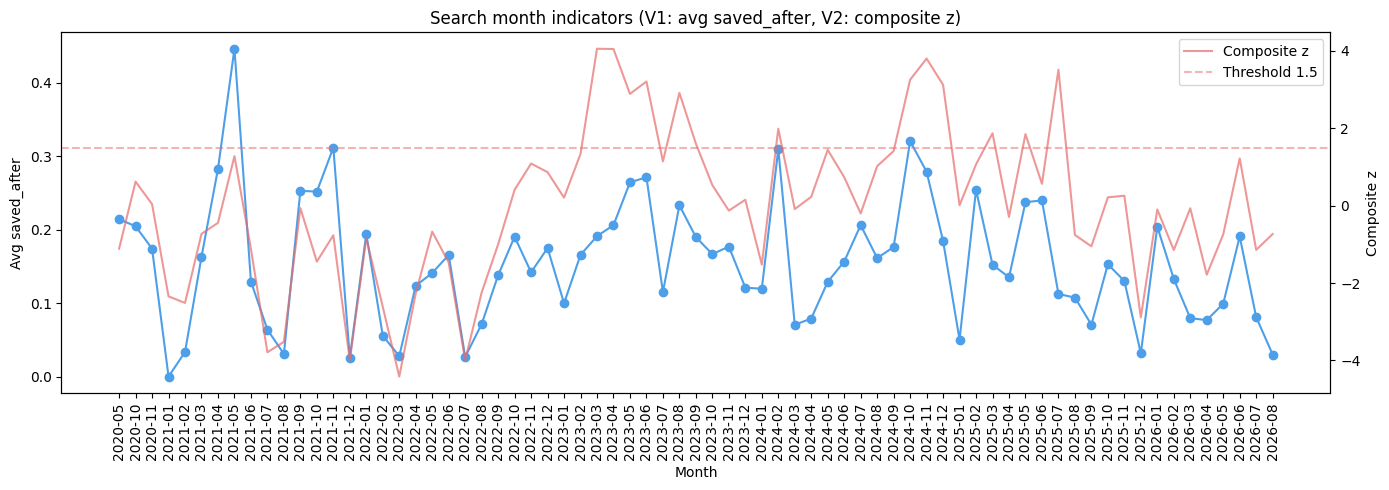

In [51]:
# 2.5 Скипы в сессиях и поисковые индикаторы

# Три части:
#   1. Скипы по длительности: отличаются ли continuous от interrupted
#      по тому, сколько времени слушается трек перед скипом.
#   2. Годовой срез saved_after: как менялась связь прерывистых сессий
#      с будущими сохранениями по годам.
#   3. Поисковые месяцы: два варианта индикатора (простой и композитный).
#
# session_save — из 2.4, session_behavior — из 2.3.

# ==========================================
# ЧАСТЬ 1: Скипы по длительности
# ==========================================
def duration_category(ms):
    if ms < 10_000:
        return '<10 sec'
    elif ms < 30_000:
        return '10-30 sec'
    else:
        return '30+ sec'

df_all['duration_cat'] = df_all['ms_played'].apply(duration_category)

# --- Общая сводка по категориям ---
cat_summary = df_all.groupby('duration_cat').agg(
    events=('ts', 'count'),
    share_of_all=('ts', lambda x: len(x) / len(df_all) * 100),
    skip_share=('is_skip', 'mean'),
    fwd_share=('is_fwd', 'mean'),
    back_share=('is_back', 'mean'),
    zero_ms_share=('is_zero_ms', 'mean'),
    trackerror_share=('reason_end', lambda x: (x == 'trackerror').mean()),
    endplay_share=('reason_end', lambda x: (x == 'endplay').mean())
).round(3)

cat_summary.index.name = 'Category'
cat_summary = cat_summary.reset_index()
cat_summary.columns = ['Category', 'Events', 'Share of all, %', 'Skip share',
                       'Fwd share', 'Back share', 'Zero ms share',
                       'Trackerror share', 'Endplay share']
cat_summary.index = range(1, len(cat_summary) + 1)
cat_summary.index.name = '№'

print('📊 Duration categories summary:')
display(cat_summary)

# --- Распределение длительностей внутри типов сессий ---
session_type_by_cat = df_all.groupby(['session_type', 'duration_cat']).size().unstack(fill_value=0)
session_type_share = session_type_by_cat.div(session_type_by_cat.sum(axis=1), axis=0) * 100

print('\n📊 Duration distribution within session types:')
session_type_share_display = session_type_share.round(1).reset_index()
session_type_share_display.columns = ['Session type', '<10 sec, %', '10-30 sec, %', '30+ sec, %']
session_type_share_display.index = range(1, len(session_type_share_display) + 1)
session_type_share_display.index.name = '№'
display(session_type_share_display)

# --- Сгруппированный bar: доля каждой категории по типам сессий ---
cats = ['<10 sec', '10-30 sec', '30+ sec']
cont_shares = [(df_all[(df_all['session_type'] == 'continuous')]['duration_cat'] == c).mean() for c in cats]
intr_shares = [(df_all[(df_all['session_type'] == 'interrupted')]['duration_cat'] == c).mean() for c in cats]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(cats))
width = 0.35
ax.bar(x - width/2, cont_shares, width, label='Continuous',
       color=COLORS['continuous'], edgecolor='white')
ax.bar(x + width/2, intr_shares, width, label='Interrupted',
       color=COLORS['interrupted'], edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(cats)
ax.set_ylabel('Share of events')
ax.set_title('Listening duration by session type')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print('\n📊 Statistical significance (duration categories between session types):')
cont_data = df_all[df_all['session_type'] == 'continuous']
intr_data = df_all[df_all['session_type'] == 'interrupted']
for cat in cats:
    cont_share = (cont_data['duration_cat'] == cat).mean()
    intr_share = (intr_data['duration_cat'] == cat).mean()
    u, p = stats.mannwhitneyu(
        (cont_data['duration_cat'] == cat).astype(int),
        (intr_data['duration_cat'] == cat).astype(int),
        alternative='two-sided'
    )
    print(f'   {cat}: Continuous={cont_share:.3f}, Interrupted={intr_share:.3f}, p={p:.3e}')


# ==========================================
# ЧАСТЬ 2: Годовой срез saved_after по типам сессий
# ==========================================
session_year = session_stats.reset_index()[
    ['account', 'session_id', 'year']
].drop_duplicates()
session_save_year = session_save.merge(session_year, on=['account', 'session_id'], how='left')

yearly_save = session_save_year.groupby(['year', 'session_type']).agg(
    sessions=('session_id', 'count'),
    mean_saved_after=('saved_after_share', 'mean'),
    median_saved_after=('saved_after_share', 'median'),
    mean_saved_before=('saved_before_share', 'mean'),
    median_saved_before=('saved_before_share', 'median'),
    mean_never=('never_saved_share', 'mean'),
    median_never=('never_saved_share', 'median')
).round(3).reset_index()

yearly_save.columns = ['Year', 'Session type', 'Sessions',
                       'Mean saved_after', 'Median saved_after',
                       'Mean saved_before', 'Median saved_before',
                       'Mean never', 'Median never']
yearly_save.index = range(1, len(yearly_save) + 1)
yearly_save.index.name = '№'

print('\n📊 Yearly save-status dynamics by session type:')
show_table(yearly_save)

# --- График: медианная доля saved_after по годам ---
pivot_median_after = yearly_save.pivot(index='Year', columns='Session type', values='Median saved_after')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(pivot_median_after.index, pivot_median_after['continuous'],
             marker='o', color=COLORS['line_success'], label='Continuous')
axes[0].plot(pivot_median_after.index, pivot_median_after['interrupted'],
             marker='s', color=COLORS['line_secondary'], label='Interrupted')
axes[0].set_title('Median saved_after share by year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Median saved_after share')
axes[0].legend(title='Session type')
axes[0].grid(True, alpha=0.3)

pivot_mean_after = yearly_save.pivot(index='Year', columns='Session type', values='Mean saved_after')

axes[1].plot(pivot_mean_after.index, pivot_mean_after['continuous'],
             marker='o', color=COLORS['line_success'], label='Continuous')
axes[1].plot(pivot_mean_after.index, pivot_mean_after['interrupted'],
             marker='s', color=COLORS['line_secondary'], label='Interrupted')
axes[1].set_title('Mean saved_after share by year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Mean saved_after share')
axes[1].legend(title='Session type')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================
# ЧАСТЬ 3: Поисковые месяцы — два индикатора
# ==========================================
# session_behavior создан в 2.3; используем его skip_share.
session_combined = session_save.merge(
    session_behavior[['account', 'session_id', 'skip_share']],
    on=['account', 'session_id'],
    how='left'
)

session_month = session_stats.reset_index()[
    ['account', 'session_id', 'start_ts']
].drop_duplicates()
session_month['month'] = session_month['start_ts'].dt.to_period('M')

session_combined = session_combined.merge(
    session_month[['account', 'session_id', 'month']],
    on=['account', 'session_id'], how='left'
)

interrupted_sessions = session_combined[
    session_combined['session_type'] == 'interrupted'
].copy()

# Месячная агрегация
monthly_search_features = interrupted_sessions.groupby('month').agg(
    interrupted_count=('session_id', 'count'),
    avg_saved_after=('saved_after_share', 'mean'),
    avg_skip_share=('skip_share', 'mean'),
    median_saved_after=('saved_after_share', 'median')
)

all_sessions_month = session_combined.groupby('month').agg(
    total_sessions=('session_id', 'count')
)
monthly_search_features['interrupted_share'] = (
    monthly_search_features['interrupted_count'] / all_sessions_month['total_sessions']
)

monthly_search_features = monthly_search_features.dropna(subset=['avg_saved_after'])

# --- Вариант 1: только avg_saved_after ---
mean_after = monthly_search_features['avg_saved_after'].mean()
std_after = monthly_search_features['avg_saved_after'].std()
threshold_after = mean_after + 1.5 * std_after
monthly_search_features['search_v1'] = monthly_search_features['avg_saved_after'] > threshold_after

# --- Вариант 2: композитный z-score ---
monthly_search_features['z_saved_after'] = (
    monthly_search_features['avg_saved_after'] - monthly_search_features['avg_saved_after'].mean()
) / monthly_search_features['avg_saved_after'].std()

monthly_search_features['z_interrupted_share'] = (
    monthly_search_features['interrupted_share'] - monthly_search_features['interrupted_share'].mean()
) / monthly_search_features['interrupted_share'].std()

monthly_search_features['z_skip'] = (
    monthly_search_features['avg_skip_share'] - monthly_search_features['avg_skip_share'].mean()
) / monthly_search_features['avg_skip_share'].std()

monthly_search_features['composite_z'] = (
    monthly_search_features['z_saved_after'] +
    monthly_search_features['z_interrupted_share'] +
    monthly_search_features['z_skip']
)
threshold_comp = 1.5
monthly_search_features['search_v2'] = monthly_search_features['composite_z'] > threshold_comp

# --- Таблица ---
comparison_search = monthly_search_features[
    ['interrupted_count', 'avg_saved_after', 'avg_skip_share',
     'interrupted_share', 'composite_z', 'search_v1', 'search_v2']
].round(3)
comparison_search.index = comparison_search.index.astype(str)
comparison_search.index.name = 'Month'
comparison_search = comparison_search.reset_index()
comparison_search.index = range(1, len(comparison_search) + 1)
comparison_search.index.name = '№'

print('\n📊 Search month indicators (V1 and V2):')
show_table(comparison_search)

# --- Месяцы, отмеченные хотя бы одним вариантом ---
selected_months = monthly_search_features[
    (monthly_search_features['search_v1']) | (monthly_search_features['search_v2'])
].index
print(f'\n🔍 Months selected by at least one indicator: {len(selected_months)}')
print(sorted([str(m) for m in selected_months]))

# --- График: avg_saved_after и composite_z ---
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly_search_features.index.astype(str),
        monthly_search_features['avg_saved_after'],
        marker='o', color=COLORS['line_primary'],
        label='Avg saved_after in interrupted')
ax.set_xlabel('Month')
ax.set_ylabel('Avg saved_after')
ax.tick_params(axis='x', rotation=90)

ax2 = ax.twinx()
ax2.plot(monthly_search_features.index.astype(str),
         monthly_search_features['composite_z'],
         color=COLORS['line_accent'], alpha=0.7, label='Composite z')
ax2.axhline(1.5, color=COLORS['line_accent'], linestyle='--', alpha=0.5, label='Threshold 1.5')
ax2.set_ylabel('Composite z')
ax2.legend(loc='upper right')

plt.title('Search month indicators (V1: avg saved_after, V2: composite z)')
plt.tight_layout()
plt.show()

### 2.5. Вывод

**Что проверяли.** Три вопроса. Отличается ли длительность скипов между типами сессий. Как менялась по годам связь **interrupted** с будущими сохранениями. В какие месяцы поиск нового был особенно активен.

**Результат.** Длительность скипов между типами сессий почти не различается: доля 30+ секундных событий — 65.4% у **continuous** против 67.3% у **interrupted**. Различия значимы при больших выборках, но по величине — 0.6–1.9 п.п. Связь **interrupted** с **saved_after** устойчива по годам: медианная доля **saved_after** у **continuous** — 0.000 во все годы кроме 2020, у **interrupted** — от 0.034 до 0.207, всегда больше нуля. Поисковые месяцы — 15 по двум индикаторам. Композитный индикатор отмечает кластеры: март–сентябрь 2023 (шесть месяцев подряд), октябрь–декабрь 2024 (три), март–июль 2025 (три). Простой индикатор — только четыре месяца.

**Вывод.** Длительность скипов не отличает **interrupted** от **continuous** — поведение внутри обоих типов одинаковое. Устойчивая разница — в связи с будущими сохранениями, и она воспроизводится во все годы. Это подтверждает ключевой результат 2.4: **interrupted** — не просто длинные сессии, а сессии, связанные с последующим сохранением. Поиск нового идёт волнами: 2023 — пик (шесть месяцев подряд), конец 2024 и середина 2025 — второй и третий кластеры. Два индикатора дают разные списки: композитный чувствительнее, простой отмечает только крайние пики.

## 2.6 Причины окончания прослушивания


📊 Reason for track ending distribution:


,Reason,Events,Share (%)
№,,,
1,trackdone,46124,57.800000
2,fwdbtn,13532,17.000000
3,endplay,12926,16.200000
4,backbtn,3123,3.900000
5,trackerror,1890,2.400000
6,logout,1582,2.000000
7,unexpected-exit-while-paused,289,0.400000
8,unexpected-exit,165,0.200000
9,remote,117,0.100000


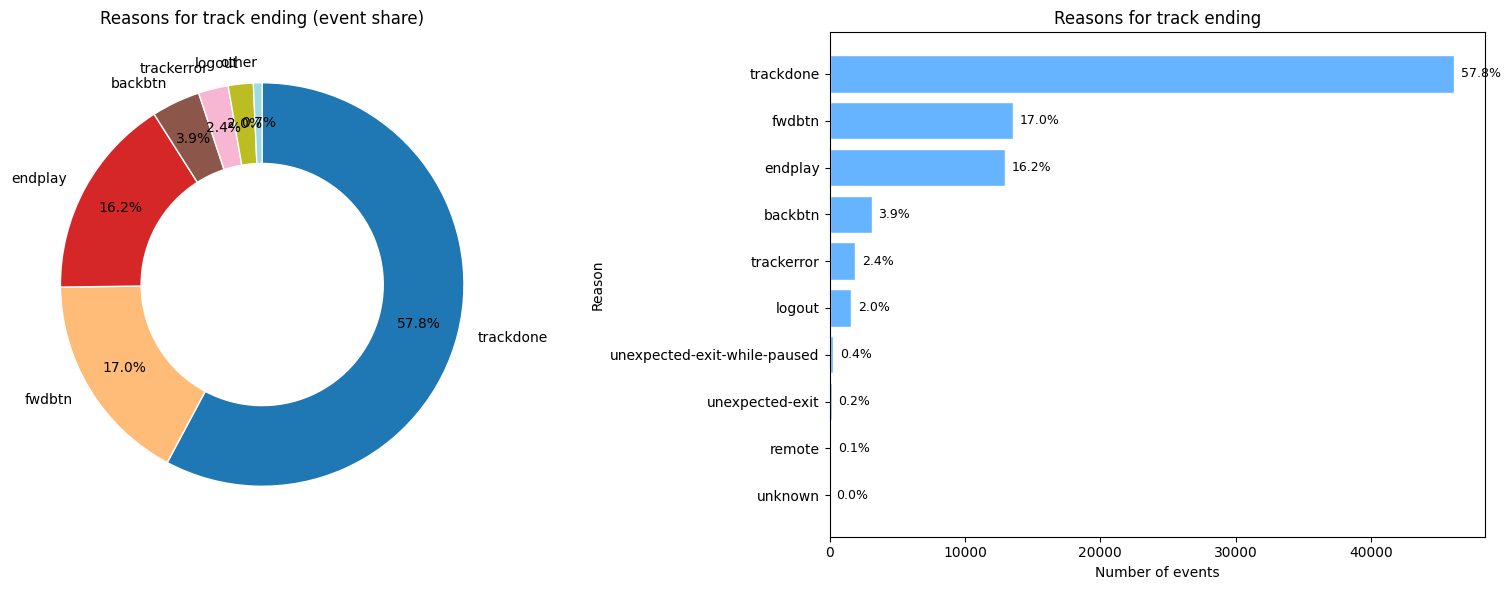


📊 Median listening duration by end reason:


,Reason,Median duration (sec),Events
№,,,
1,trackerror,0.000000,1890
2,backbtn,1.000000,3123
3,fwdbtn,6.000000,13532
4,endplay,8.000000,12926
5,unknown,28.000000,4
6,unexpected-exit,30.000000,165
7,remote,57.000000,117
8,logout,79.000000,1582
9,unexpected-exit-while-paused,79.000000,289


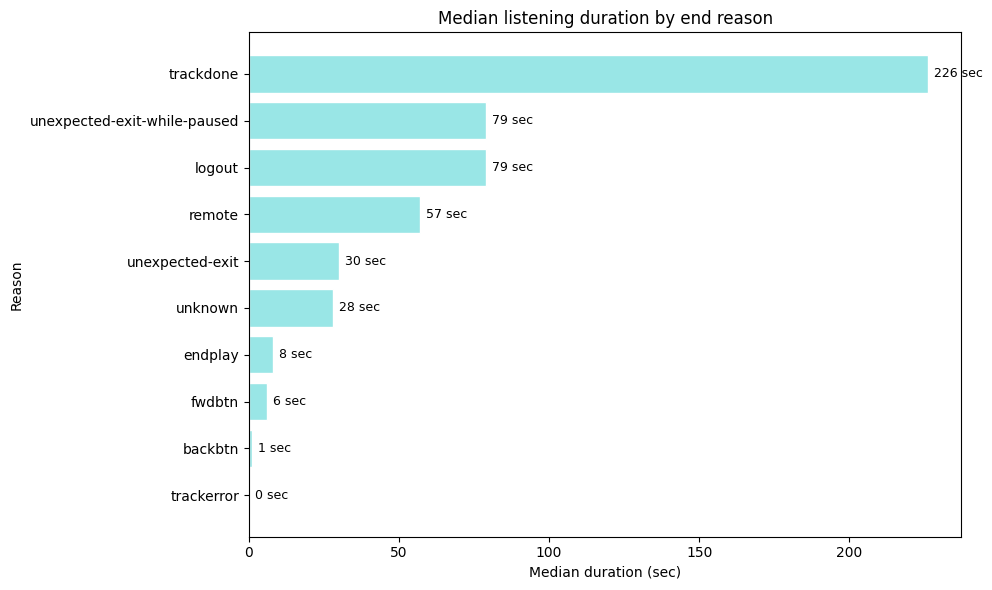


📊 Reason distribution by session type:


,Reason,"Continuous, %","Interrupted, %","Continuous, events","Interrupted, events"
№,,,,,
1,trackdone,56.300000,59.200000,20749,25375
2,endplay,16.300000,16.200000,5994,6932
3,fwdbtn,18.100000,16.000000,6660,6872
4,backbtn,3.900000,3.900000,1440,1683
5,trackerror,2.000000,2.700000,741,1149
6,logout,2.400000,1.600000,898,684
7,unexpected-exit-while-paused,0.600000,0.200000,207,82
8,unexpected-exit,0.200000,0.200000,90,75
9,remote,0.200000,0.100000,73,44



📊 Statistical significance (chi-square 2x2):
   backbtn: p=9.212e-01 — not significant
   endplay: p=6.980e-01 — not significant
   fwdbtn: p=1.540e-14 — significant
   logout: p=2.308e-17 — significant
   remote: p=6.253e-04 — significant
   trackdone: p=4.263e-16 — significant
   trackerror: p=7.311e-10 — significant
   unexpected-exit: p=3.835e-02 — significant
   unexpected-exit-while-paused: p=6.556e-18 — significant
   unknown: p=5.135e-01 — not significant


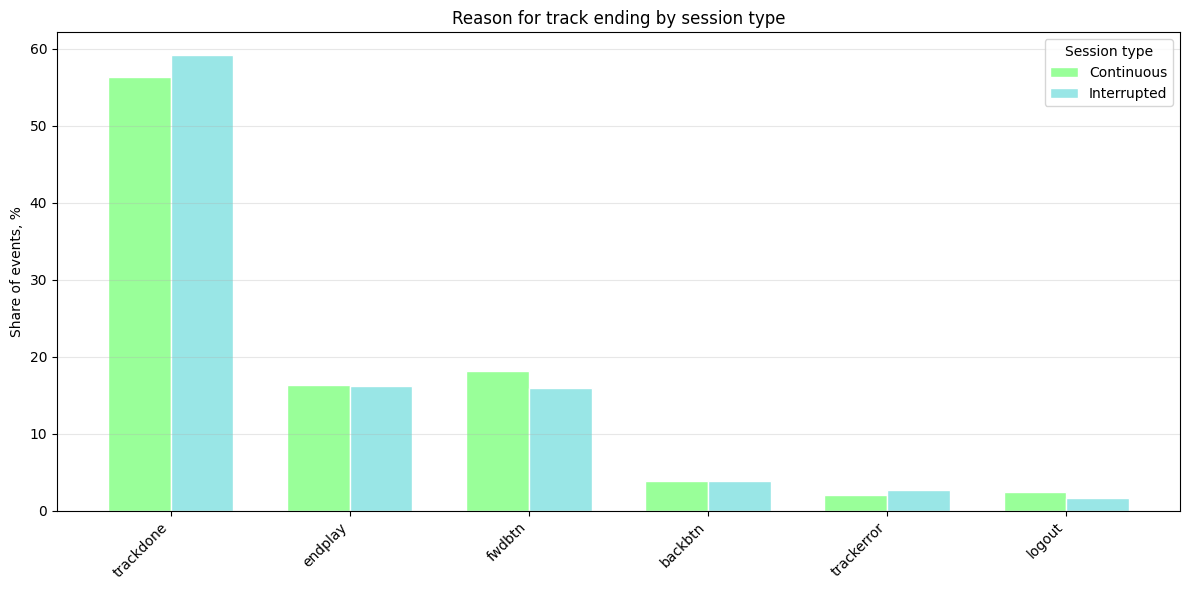

In [52]:
# 2.6 Причины окончания прослушивания

# Две части:
#   1. Общий срез: как заканчивается воспроизведение трека.
#   2. Сравнение continuous vs interrupted: есть ли специфика у типов сессий.
#
# Используется df (все события), не df_deep: причины окончания
# описывают поток как есть, включая скипы и короткие события.

# ==========================================
# ЧАСТЬ 1: Общий срез
# ==========================================
data = df.copy()

reason_counts = data['reason_end'].value_counts()
reason_pct = (reason_counts / len(data) * 100).round(1)

print('📊 Reason for track ending distribution:')
reason_df = pd.DataFrame({
    'Reason': reason_counts.index,
    'Events': reason_counts.values,
    'Share (%)': reason_pct.values
})
reason_df.index = range(1, len(reason_df) + 1)
reason_df.index.name = '№'
show_table(reason_df)

# --- Пирог: топ-причины + other ---
min_share = 2.0
pie_data = reason_pct.copy()
small_mask = pie_data < min_share
if small_mask.any():
    other_share = pie_data[small_mask].sum()
    pie_data = pie_data[~small_mask]
    pie_data['other'] = other_share
pie_data = pie_data.sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Пирог
cmap_pie = plt.cm.tab20(np.linspace(0, 1, len(pie_data)))
wedge_props = dict(width=0.4, edgecolor='white')
axes[0].pie(
    pie_data.values,
    labels=pie_data.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,
    colors=cmap_pie,
    wedgeprops=wedge_props,
    pctdistance=0.8,
    labeldistance=1.1
)
axes[0].set_title('Reasons for track ending (event share)', fontsize=12)

# Bar: количество событий по причинам
bars = axes[1].barh(reason_counts.index, reason_counts.values,
                    color=COLORS['primary'], edgecolor='white')
for bar, pct in zip(bars, reason_pct.values):
    axes[1].text(bar.get_width() + 500, bar.get_y() + bar.get_height()/2,
                 f'{pct}%', va='center', fontsize=9)
axes[1].set_title('Reasons for track ending')
axes[1].set_xlabel('Number of events')
axes[1].set_ylabel('Reason')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# --- Медианная длительность по причинам ---
reason_stats = data.groupby('reason_end').agg(
    ms_played_median=('ms_played', 'median'),
    events=('ms_played', 'count')
).reset_index()
reason_stats['ms_played_median'] = (reason_stats['ms_played_median'] / 1000).round(0)
reason_stats = reason_stats.sort_values('ms_played_median', ascending=True)

print('\n📊 Median listening duration by end reason:')
reason_stats_display = reason_stats.rename(columns={
    'reason_end': 'Reason',
    'ms_played_median': 'Median duration (sec)',
    'events': 'Events'
})
reason_stats_display.index = range(1, len(reason_stats_display) + 1)
reason_stats_display.index.name = '№'
show_table(reason_stats_display)

plt.figure(figsize=(10, 6))
bars = plt.barh(reason_stats['reason_end'], reason_stats['ms_played_median'],
                color=COLORS['secondary'], edgecolor='white')
for bar, val in zip(bars, reason_stats['ms_played_median']):
    plt.text(bar.get_width() + 2, bar.get_y() + bar.get_height()/2,
             f'{val:.0f} sec', va='center', fontsize=9)
plt.title('Median listening duration by end reason')
plt.xlabel('Median duration (sec)')
plt.ylabel('Reason')
plt.tight_layout()
plt.show()


# ==========================================
# ЧАСТЬ 2: Причины окончания по типам сессий
# ==========================================
if 'session_type' not in df_all.columns:
    session_type_map = session_stats.reset_index()[
        ['account', 'session_id', 'session_type']
    ].drop_duplicates()
    df_all = df_all.merge(session_type_map, on=['account', 'session_id'], how='left')

data_typed = df_all.dropna(subset=['session_type']).copy()

reasons = data_typed['reason_end'].unique()
continuous = data_typed[data_typed['session_type'] == 'continuous']
interrupted = data_typed[data_typed['session_type'] == 'interrupted']

# --- Таблица ---
rows = []
for reason in sorted(reasons):
    cont_count = (continuous['reason_end'] == reason).sum()
    intr_count = (interrupted['reason_end'] == reason).sum()
    cont_total = len(continuous)
    intr_total = len(interrupted)
    cont_share = cont_count / cont_total * 100
    intr_share = intr_count / intr_total * 100
    rows.append({
        'Reason': reason,
        'Continuous, %': round(cont_share, 1),
        'Interrupted, %': round(intr_share, 1),
        'Continuous, events': cont_count,
        'Interrupted, events': intr_count
    })

reason_by_type = pd.DataFrame(rows).sort_values('Interrupted, %', ascending=False)
reason_by_type.index = range(1, len(reason_by_type) + 1)
reason_by_type.index.name = '№'

print('\n📊 Reason distribution by session type:')
show_table(reason_by_type)

# --- Статистическая значимость: хи-квадрат по каждой причине ---
print('\n📊 Statistical significance (chi-square 2x2):')
for reason in sorted(reasons):
    cont_yes = (continuous['reason_end'] == reason).sum()
    cont_no = len(continuous) - cont_yes
    intr_yes = (interrupted['reason_end'] == reason).sum()
    intr_no = len(interrupted) - intr_yes
    table = [[cont_yes, cont_no], [intr_yes, intr_no]]
    chi2, p, dof, expected = stats.chi2_contingency(table)
    significance = 'significant' if p < 0.05 else 'not significant'
    print(f'   {reason}: p={p:.3e} — {significance}')

# --- Сгруппированный bar: топ-6 причин ---
top_reasons = reason_by_type.head(6)
labels = top_reasons['Reason']
cont_vals = top_reasons['Continuous, %']
intr_vals = top_reasons['Interrupted, %']

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width/2, cont_vals, width, label='Continuous',
        color=COLORS['continuous'], edgecolor='white')
plt.bar(x + width/2, intr_vals, width, label='Interrupted',
        color=COLORS['interrupted'], edgecolor='white')
plt.xticks(x, labels, rotation=45, ha='right')
plt.ylabel('Share of events, %')
plt.title('Reason for track ending by session type')
plt.legend(title='Session type')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 2.6. Вывод

**Что проверяли.** Как заканчивается воспроизведение трека
в общем потоке. Есть ли специфика у **continuous** и **interrupted**.

**Результат.**

Общий срез: **trackdone** — 57.8%, **fwdbtn** — 17.0%,
**endplay** — 16.2%, **backbtn** — 3.9%, **trackerror** — 2.4%,
**logout** — 2.0%. Остальные причины — меньше 0.5% каждая.

Медианная длительность по причинам делит их на три группы.
**trackdone** — 226 секунд. Промежуточные: **logout** и
**unexpected-exit-while-paused** по 79 секунд, **remote** — 57,
**unexpected-exit** — 30. Короткие: **endplay** 8 секунд,
**fwdbtn** 6, **backbtn** 1, **trackerror** 0.

По типам сессий доля каждой причины считается внутри своей группы.
**trackdone** — 56.3% у **continuous** против 59.2% у
**interrupted**. Эти доли не суммируются в 100% между группами:
56.3% — от всех событий continuous, 59.2% — от всех событий
interrupted. **fwdbtn** — 18.1% против 16.0%. **trackerror** —
2.0% против 2.7%. **logout** — 2.4% против 1.6%. **endplay**
и **backbtn** между типами не различаются (p=0.70 и p=0.92).
Значимые различия — от 0.4 до 2.9 п.п.

**Вывод.** Поток заканчивается в основном естественно:
**trackdone** — почти в 60%, ещё 16% — **endplay**. Скипы
и перемотки — 21%, технические причины — 3%. Связь причины
окончания с длительностью прямая: **trackdone** происходит после
полного прослушивания (медиана 226 секунд), **fwdbtn** и
**backbtn** — почти сразу (6 и 1 секунда). **interrupted**
заканчиваются чуть чаще через **trackdone** и **trackerror**,
**continuous** — чуть чаще через **fwdbtn** и **logout**.
Различия значимы статистически, но по величине малы: тип сессии
не переопределяет структуру причин окончания.

## 2.7 Скипы: базовая статистика и контекст


   SKIP AND LISTENING DURATION: BASIC SCALE
📊 Total events: 79,752
   Instant skips (<10 sec): 20,427 (25.6%)
   Short listens (10-30 sec): 6,341 (8.0%)
   Explicit skips (skipped=True): 18,247 (22.9%)
   Full plays (>90% duration): 45,518 (57.1%)


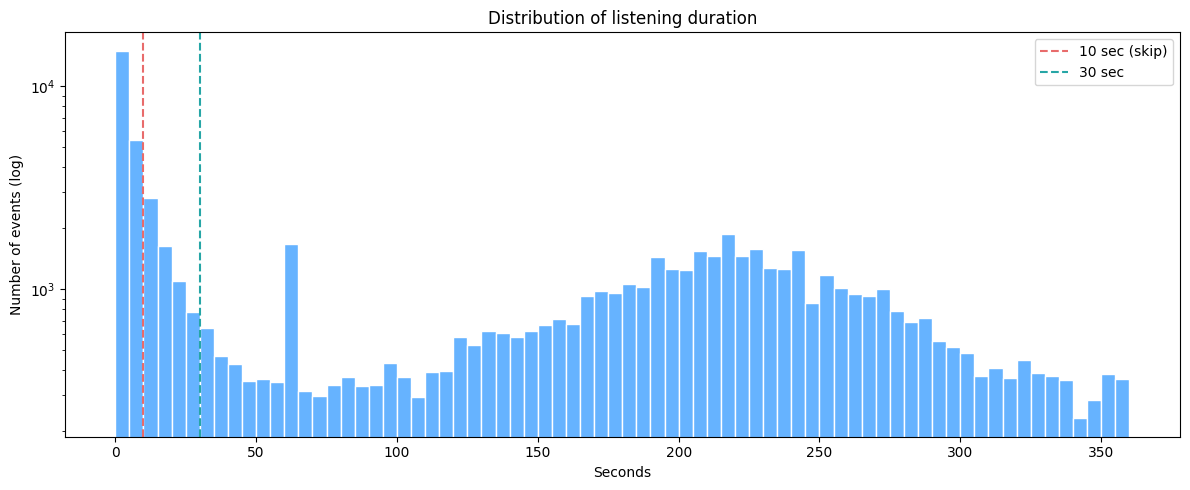

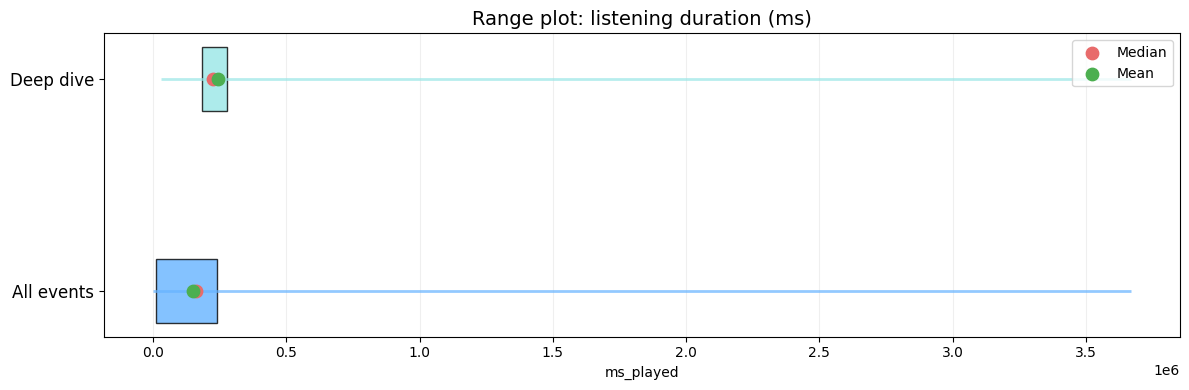


📊 Listening duration statistics (ms):
count      79752.0
mean      151253.0
std       141482.0
min            0.0
10%         1624.0
25%         9377.0
50%       160250.0
75%       239899.0
90%       313886.0
99%       533889.0
max      3669268.0
Name: ms_played, dtype: float64

🔍 Interpretation:
   Median duration: 160 sec.
   Every fourth track (25.6%) is skipped within 10 sec.
   More than half of tracks are listened almost to the end — high engagement.
⚠️ All events: 45.5% tracks without genre — genre conclusions limited.


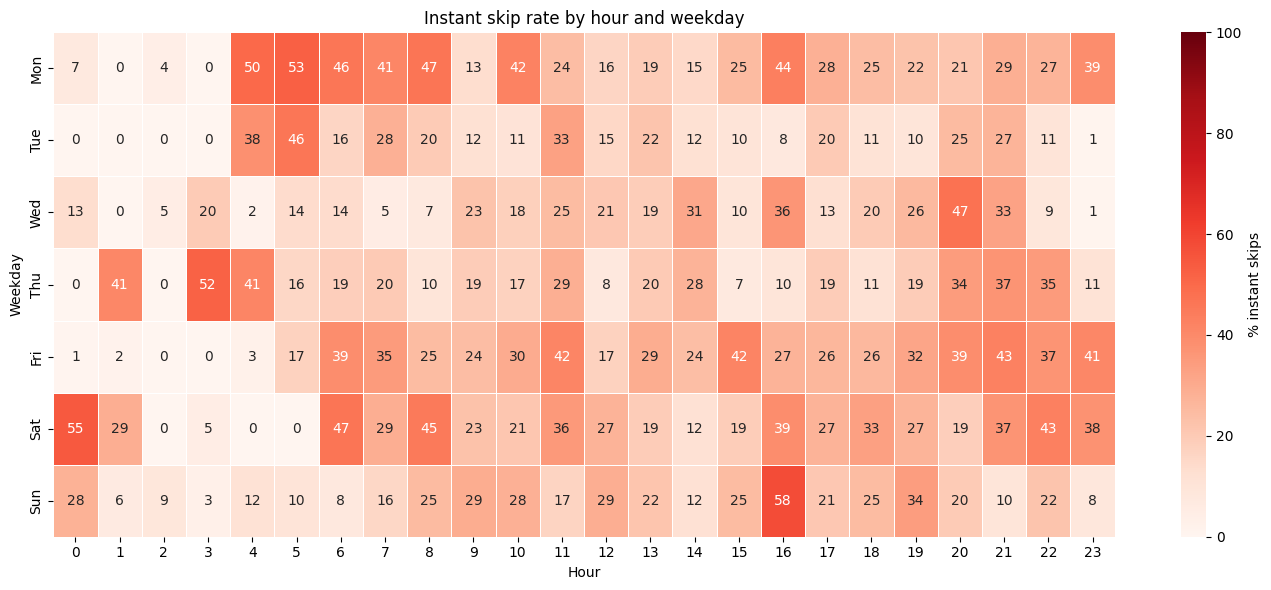


📊 Instant skip rate by genre (top-15 + unknown + other):


,Genre,Events,"Skip rate, %"
№,,,
1,post-punk,2351,30.800000
2,other,51124,29.100000
3,chillstep,1310,28.100000
4,unknown,36261,25.700000
5,electronica,1531,25.300000
6,minimal techno,1477,25.300000
7,ambient,1650,22.800000
8,witch house,2442,22.700000
9,idm,1784,22.600000


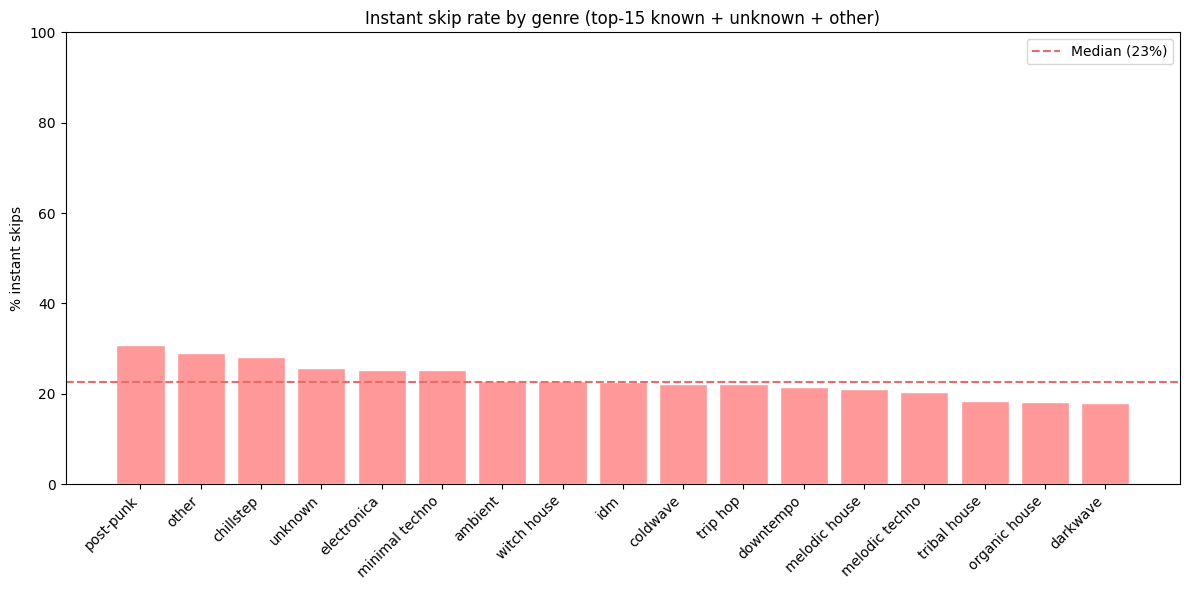


🔍 Interpretation:
   Skip peak: Sun, 16:00 (up to 58%).
   Most skipped known genre: post-punk (30.8% skips).
   Least skipped known genre: darkwave (17.9% skips).


In [53]:
# 2.7 Скипы: базовая статистика и контекст

# Две части:
#   1. Базовый масштаб: сколько музыки отбраковывается мгновенно,
#      сколько слушается коротко, сколько дослушивается почти до конца.
#   2. Контекст: зависит ли мгновенный скип от времени суток,
#      дня недели и жанра.
#
# Везде используется df (все события).

data = df.copy()
data['hour'] = data['ts'].dt.hour
data['weekday'] = data['ts'].dt.weekday
data['is_skip_event'] = data['ms_played'] < 10_000

# ==========================================
# ЧАСТЬ 1: Базовая статистика
# ==========================================
total = len(data)
skip_10s = (data['ms_played'] < 10_000).sum()
skip_10_30s = ((data['ms_played'] >= 10_000) & (data['ms_played'] < 30_000)).sum()
explicit_skips = data['skipped'].sum()
full_play = (data['ms_played'] >= data['duration_ms'] * 0.9).sum()

print('=' * 60)
print('   SKIP AND LISTENING DURATION: BASIC SCALE')
print('=' * 60)
print(f'📊 Total events: {total:,}')
print(f'   Instant skips (<10 sec): {skip_10s:,} ({skip_10s/total*100:.1f}%)')
print(f'   Short listens (10-30 sec): {skip_10_30s:,} ({skip_10_30s/total*100:.1f}%)')
print(f'   Explicit skips (skipped=True): {explicit_skips:,} ({explicit_skips/total*100:.1f}%)')
print(f'   Full plays (>90% duration): {full_play:,} ({full_play/total*100:.1f}%)')

# Гистограмма длительности (линейная ось X, лог Y)
plt.figure(figsize=(12, 5))
plt.hist(data['ms_played'] / 1000, bins=range(0, 361, 5),
         color=COLORS['primary'], edgecolor='white', log=True)
plt.axvline(10, color=COLORS['line_accent'], linestyle='--', label='10 sec (skip)')
plt.axvline(30, color=COLORS['line_secondary'], linestyle='--', label='30 sec')
plt.title('Distribution of listening duration')
plt.xlabel('Seconds')
plt.ylabel('Number of events (log)')
plt.legend()
plt.tight_layout()
plt.show()

# Range plot: All events vs Deep dive
groups = [
    (data['ms_played'].dropna(), 'All events', COLORS['primary']),
    (df_deep['ms_played'].dropna(), 'Deep dive', COLORS['secondary'])
]

fig, ax = plt.subplots(figsize=(12, 4))
y_positions = [0, 1]
min_overall = min(g[0].min() for g in groups)
max_overall = max(g[0].max() for g in groups)
ax.set_xlim(min_overall - 0.05*(max_overall-min_overall),
            max_overall + 0.05*(max_overall-min_overall))

for (values, label, color), y_pos in zip(groups, y_positions):
    min_val = values.min()
    max_val = values.max()
    median_val = values.median()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    ax.hlines(y=y_pos, xmin=min_val, xmax=max_val, color=color, linewidth=2, alpha=0.7)
    ax.barh(y=y_pos, width=q3-q1, left=q1, height=0.3, color=color, edgecolor='black', alpha=0.8)
    ax.scatter(median_val, y_pos, color=COLORS['line_accent'], s=80, zorder=5,
               label='Median' if y_pos == 0 else None)
    ax.scatter(values.mean(), y_pos, color=COLORS['line_success'], s=80, zorder=5,
               label='Mean' if y_pos == 0 else None)

ax.set_yticks(y_positions)
ax.set_yticklabels(['All events', 'Deep dive'], fontsize=12)
ax.set_title('Range plot: listening duration (ms)', fontsize=14)
ax.set_xlabel('ms_played')
ax.legend(loc='upper right')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

# Статистики
ms_stats = data['ms_played'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(0)
print('\n📊 Listening duration statistics (ms):')
print(ms_stats)

median_sec = ms_stats['50%'] / 1000
skip_pct = skip_10s / total * 100
print(f'\n🔍 Interpretation:')
print(f'   Median duration: {median_sec:.0f} sec.')
if skip_pct > 25:
    print(f'   Every fourth track ({skip_pct:.1f}%) is skipped within 10 sec.')
elif skip_pct > 10:
    print(f'   Instant skip share ({skip_pct:.1f}%) is moderate.')
else:
    print(f'   Instant skip share ({skip_pct:.1f}%) is low.')
if full_play / total > 0.5:
    print('   More than half of tracks are listened almost to the end — high engagement.')


# ==========================================
# ЧАСТЬ 2: Скипы по времени суток и жанрам
# ==========================================
show_unknown_share(data, 'All events')

# --- Тепловая карта: доля мгновенных скипов по часам и дням недели ---
skip_rate_pivot = data.pivot_table(
    index='weekday', columns='hour', values='is_skip_event', aggfunc='mean'
) * 100
day_names = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}
skip_rate_pivot.index = [day_names[i] for i in skip_rate_pivot.index]

plt.figure(figsize=(14, 6))
sns.heatmap(skip_rate_pivot, annot=True, fmt='.0f', cmap='Reds', linewidths=0.5,
            cbar_kws={'label': '% instant skips'}, vmin=0, vmax=100)
plt.title('Instant skip rate by hour and weekday')
plt.ylabel('Weekday')
plt.xlabel('Hour')
plt.tight_layout()
plt.show()

# --- Жанровый срез: топ-15 известных + unknown + other ---
data_genre = data.copy()
data_genre['genre_list'] = data_genre['genres_normalized'].str.split(',')
genre_flat = data_genre.explode('genre_list')
genre_flat['genre'] = genre_flat['genre_list'].str.strip()

genre_total_counts = genre_flat['genre'].value_counts()
unknown_count = genre_total_counts.get('unknown', 0)
known_counts = genre_total_counts[genre_total_counts.index != 'unknown']
top15_known = known_counts.head(15)
other_count = known_counts.iloc[15:].sum()

final_categories = list(top15_known.index)
if unknown_count > 0:
    final_categories.append('unknown')
if other_count > 0:
    final_categories.append('other')

rows = []
for cat in final_categories:
    if cat == 'unknown':
        cat_events = genre_flat[genre_flat['genre'] == 'unknown']
    elif cat == 'other':
        cat_events = genre_flat[genre_flat['genre'].isin(known_counts.index[15:])]
    else:
        cat_events = genre_flat[genre_flat['genre'] == cat]

    total_cat = len(cat_events)
    skip_count = cat_events['is_skip_event'].sum()
    skip_rate = skip_count / total_cat * 100 if total_cat > 0 else 0
    rows.append({
        'Genre': cat,
        'Events': total_cat,
        'Skip rate, %': round(skip_rate, 1)
    })

genre_skip_table = pd.DataFrame(rows).sort_values('Skip rate, %', ascending=False)
genre_skip_table.index = range(1, len(genre_skip_table) + 1)
genre_skip_table.index.name = '№'

print('\n📊 Instant skip rate by genre (top-15 + unknown + other):')
show_table(genre_skip_table)

# --- Визуализация ---
plt.figure(figsize=(12, 6))
bars = plt.bar(genre_skip_table['Genre'], genre_skip_table['Skip rate, %'],
               color=COLORS['accent'], edgecolor='white')
plt.title('Instant skip rate by genre (top-15 known + unknown + other)')
plt.ylabel('% instant skips')
plt.ylim(0, 100)
plt.xticks(rotation=45, ha='right')
median_skip = genre_skip_table['Skip rate, %'].median()
plt.axhline(y=median_skip, color=COLORS['line_accent'], linestyle='--',
            label=f'Median ({median_skip:.0f}%)')
plt.legend()
plt.tight_layout()
plt.show()

# --- Автоинтерпретация ---
print('\n🔍 Interpretation:')
peak_hour = skip_rate_pivot.max().idxmax()
peak_day = skip_rate_pivot.max(axis=1).idxmax()
print(f'   Skip peak: {peak_day}, {peak_hour}:00 (up to {skip_rate_pivot.max().max():.0f}%).')

known_only = genre_skip_table[genre_skip_table['Genre'] != 'unknown']
highest_idx = known_only['Skip rate, %'].idxmax()
lowest_idx = known_only['Skip rate, %'].idxmin()
print(f'   Most skipped known genre: {known_only.loc[highest_idx, "Genre"]} '
      f'({known_only.loc[highest_idx, "Skip rate, %"]}% skips).')
print(f'   Least skipped known genre: {known_only.loc[lowest_idx, "Genre"]} '
      f'({known_only.loc[lowest_idx, "Skip rate, %"]}% skips).')

### 2.7. Вывод

**Что проверяли.** Базовый масштаб скипов и прослушивания в потоке. Зависит ли мгновенный скип от времени суток, дня недели и жанра.

**Результат.**

Общий срез: 25.6% событий — мгновенные скипы (<10 секунд), 8.0% — короткие прослушивания (10–30 секунд), 22.9% — явные скипы (**skipped**=True), 57.1% — полные прослушивания (>90% длительности). Медиана длительности — 160 секунд.

Тепловая карта мгновенных скипов: пик — воскресенье, 16:00 (58%). Низкие значения — по утрам в будни (0–7%) и в отдельные ночные часы. По дням недели разброс большой, но устойчивой структуры нет: высокие значения встречаются и в будни (вторник 10:00 — 46%, четверг 15:00 — 52%), и в выходные.

Жанровый срез: максимальный скип — **post-punk** 30.8%, минимальный — **darkwave** 17.9%. **unknown** — 25.7%, близко к среднему. Разрыв между крайними известными жанрами — 12.9 п.п.

**Вывод.** Больше четверти событий отбраковываются в первые 10 секунд, но больше половины дослушиваются почти до конца. Мгновенный скип — не однородное поведение: доля в 58% в отдельные часы против 0% в другие показывает, что решение о скипе зависит от контекста. Жанры различаются по скипу меньше, чем время суток: разрыв по жанрам 12.9 п.п. при разрыве по часам почти в 58 п.п.

Ограничение: доля **unknown** в жанрах — 45.5%. Различия по жанрам описывают известную половину и могут измениться на полных данных.

## 2.8 Типы мгновенных скипов

📊 Distribution of instant skip types:


,Event type,Events,"Share of all, %","Share of skips, %"
№,,,,
1,not mine,11743,14.7,57.5
2,context skip,8684,10.9,42.5
3,not a skip,59325,74.4,—



📊 Mean audio features by skip type:


,Feature,Not mine,Context skip,Not a skip
№,,,,
1,valence,0.346,0.292,0.285
2,energy,0.555,0.502,0.500
3,danceability,0.575,0.585,0.573
4,acousticness,0.332,0.362,0.362
5,instrumentalness,0.352,0.421,0.461
6,tempo,120.040,118.944,119.051
7,loudness,-10.384,-10.992,-11.574
8,popularity,34.960,33.307,32.726


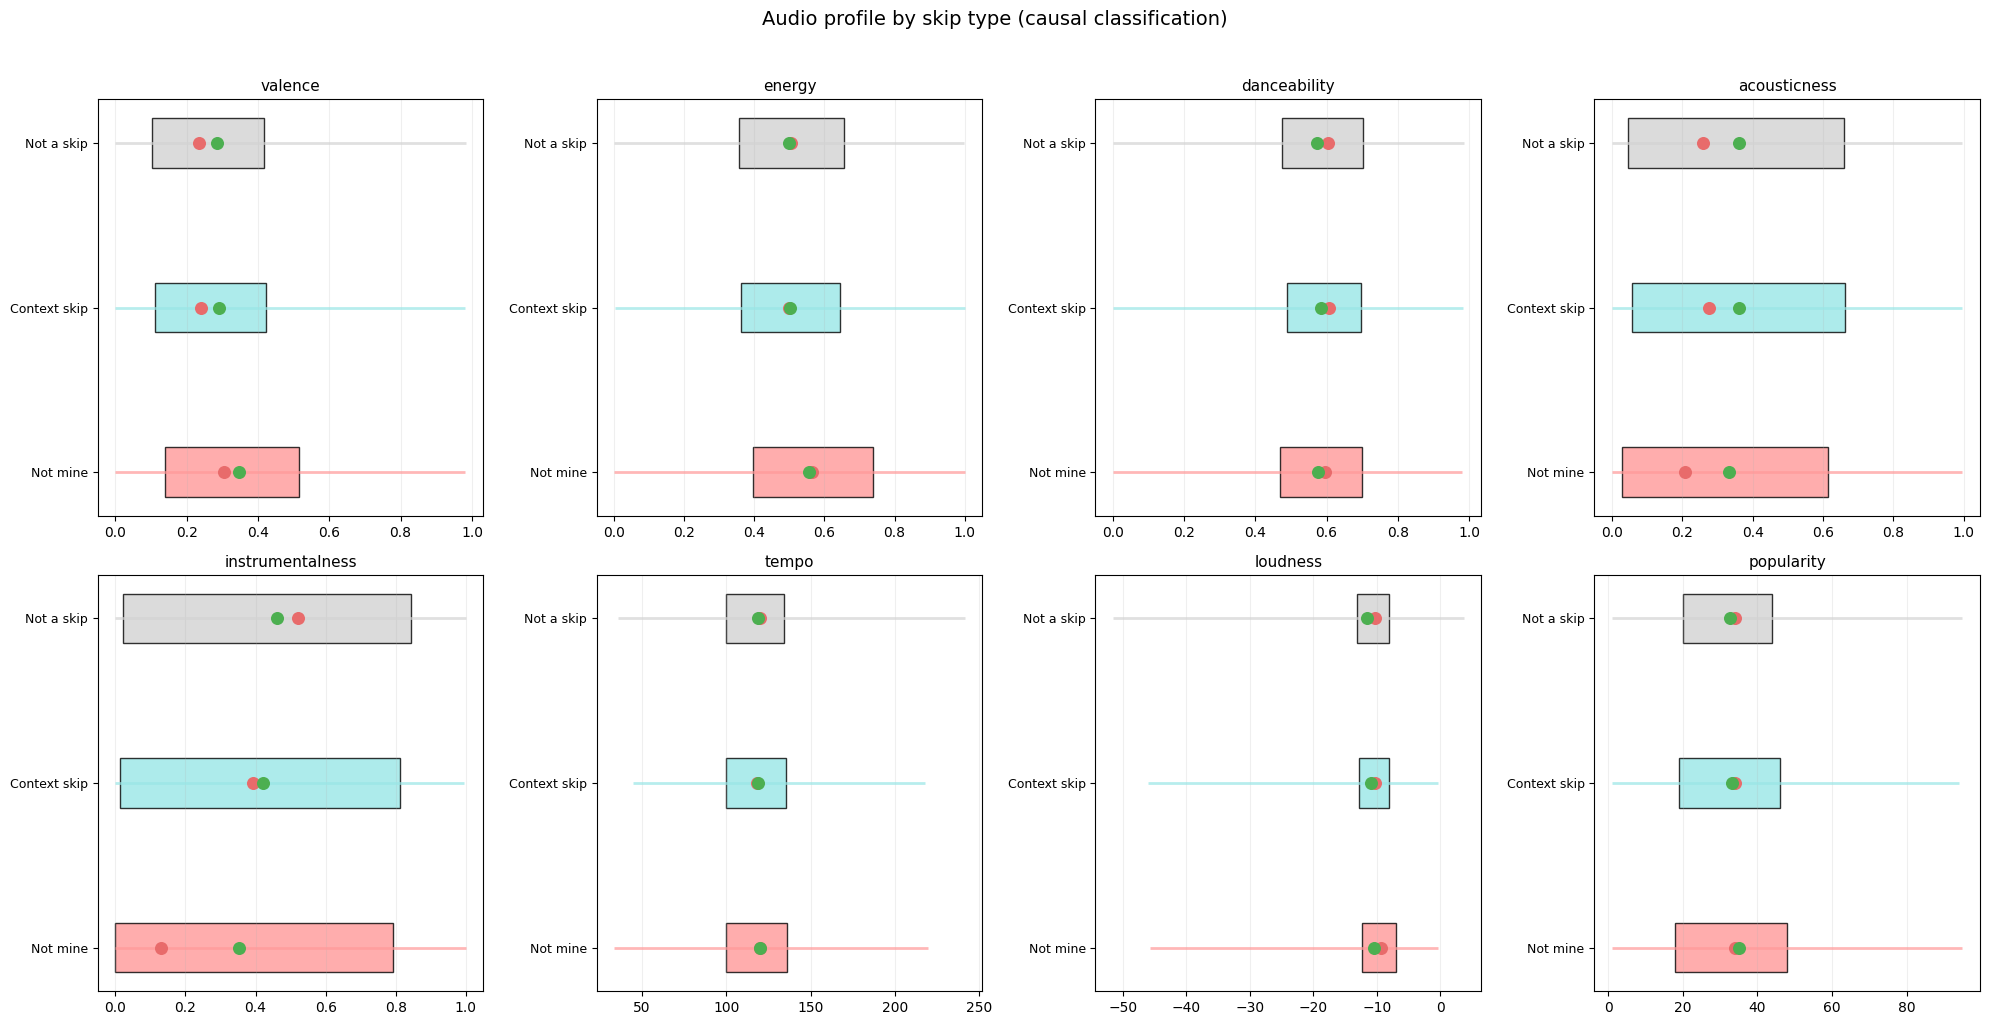


📊 Unknown genre shares:
⚠️ Not mine: 43.4% tracks without genre — genre conclusions limited.
⚠️ Context skip: 48.6% tracks without genre — genre conclusions limited.
⚠️ Not a skip: 45.4% tracks without genre — genre conclusions limited.

📊 Top-7 known genres by skip type:

Not mine:
   trip hop: 8.69%
   downtempo: 8.44%
   post-punk: 3.66%
   coldwave: 3.54%
   organic house: 3.13%
   witch house: 2.78%
   melodic techno: 2.5%

Context skip:
   downtempo: 11.92%
   trip hop: 11.84%
   coldwave: 5.87%
   organic house: 4.54%
   darkwave: 3.43%
   post-punk: 3.39%
   witch house: 2.64%

Not a skip:
   downtempo: 12.55%
   trip hop: 12.2%
   organic house: 5.79%
   coldwave: 5.48%
   darkwave: 4.32%
   melodic techno: 3.43%
   melodic house: 3.26%


In [54]:
# 2.8 Типы мгновенных скипов

# Мгновенный скип (<10 сек) — не однородное поведение. Разделяем на два типа:
#   «Точно не моё»     — трек ни разу не был глубоко прослушан до этого момента.
#   «Контекстный скип» — трек уже имел глубокое прослушивание, но сейчас пропущен.
#
# Классификация причинная: для каждого события смотрим только на прошлое
# (было ли глубокое прослушивание до него), не заглядывая в будущее.
#
# Порог глубокого прослушивания: ms_played >= duration_ms * 0.8.

# --- Подготовка и причинная классификация ---
data = df.copy()
data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
data = data.sort_values('ts').reset_index(drop=True)

# Глубокое прослушивание текущего события
data['is_deep'] = data['ms_played'] >= data['duration_ms'] * 0.8

# Было ли глубокое прослушивание ДО текущего события
data['has_deep_so_far'] = (
    data.groupby('spotify_track_uri')['is_deep']
        .cummax()
        .shift(1, fill_value=False)
)

# Классификация
data['is_instant_skip'] = data['ms_played'] < 10_000
data['skip_type'] = 'not a skip'
data.loc[data['is_instant_skip'] & ~data['has_deep_so_far'], 'skip_type'] = 'not mine'
data.loc[data['is_instant_skip'] & data['has_deep_so_far'], 'skip_type'] = 'context skip'

# --- Распределение типов ---
total_events = len(data)
skip_type_counts = data['skip_type'].value_counts()

rows = []
for stype in ['not mine', 'context skip', 'not a skip']:
    count = skip_type_counts.get(stype, 0)
    share_all = count / total_events * 100
    if stype in ['not mine', 'context skip']:
        share_skips = count / data['is_instant_skip'].sum() * 100
    else:
        share_skips = np.nan
    rows.append({
        'Event type': stype,
        'Events': count,
        'Share of all, %': round(share_all, 1),
        'Share of skips, %': round(share_skips, 1) if not np.isnan(share_skips) else '—'
    })

skip_type_df = pd.DataFrame(rows)
skip_type_df.index = range(1, len(skip_type_df) + 1)
skip_type_df.index.name = '№'
print('📊 Distribution of instant skip types:')
display(skip_type_df)

# --- Сравнение аудио-профилей ---
features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'tempo', 'loudness', 'popularity']

groups = {
    'Not mine': data[data['skip_type'] == 'not mine'],
    'Context skip': data[data['skip_type'] == 'context skip'],
    'Not a skip': data[data['skip_type'] == 'not a skip'],
}

comp = pd.DataFrame({name: grp[features].mean().round(3) for name, grp in groups.items()})
comp_display = comp.reset_index().rename(columns={'index': 'Feature'})
comp_display.index = range(1, len(comp_display) + 1)
comp_display.index.name = '№'
print('\n📊 Mean audio features by skip type:')
display(comp_display)

# --- Range plot 2x4 ---
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

group_colors = {
    'Not mine': COLORS['accent'],
    'Context skip': COLORS['secondary'],
    'Not a skip': COLORS['muted'],
}

for i, feat in enumerate(features):
    ax = axes[i]
    y_positions = [0, 1, 2]
    min_overall = min(groups[g][feat].min() for g in groups)
    max_overall = max(groups[g][feat].max() for g in groups)
    ax.set_xlim(min_overall - 0.05 * (max_overall - min_overall),
                max_overall + 0.05 * (max_overall - min_overall))

    for j, (name, grp) in enumerate(groups.items()):
        vals = grp[feat].dropna()
        q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
        med = vals.median()
        mean = vals.mean()
        ax.hlines(y=y_positions[j], xmin=vals.min(), xmax=vals.max(),
                  color=group_colors[name], linewidth=2, alpha=0.7)
        ax.barh(y=y_positions[j], width=q3 - q1, left=q1, height=0.3,
                color=group_colors[name], edgecolor='black', alpha=0.8)
        ax.scatter(med, y_positions[j], color=COLORS['line_accent'], s=70, zorder=5)
        ax.scatter(mean, y_positions[j], color=COLORS['line_success'], s=70, zorder=5)

    ax.set_yticks(y_positions)
    ax.set_yticklabels(list(groups.keys()), fontsize=9)
    ax.set_title(feat, fontsize=11)
    ax.grid(axis='x', alpha=0.2)

plt.suptitle('Audio profile by skip type (causal classification)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# --- Жанровые профили ---
print('\n📊 Unknown genre shares:')
for name, grp in groups.items():
    show_unknown_share(grp, name)

print('\n📊 Top-7 known genres by skip type:')
for name, grp in groups.items():
    known = grp[grp['genres_normalized'] != 'unknown']
    genre_counts = known['genres_normalized'].str.split(',').explode().str.strip().value_counts()
    top_genres = (genre_counts / len(grp) * 100).head(7).round(2)
    print(f'\n{name}:')
    for genre, share in top_genres.items():
        print(f'   {genre}: {share}%')

### 2.8. Вывод

**Что проверяли.** Однородны ли мгновенные скипы (<10 секунд). Причинная классификация: **not mine** — трек до этого момента ни разу не был глубоко прослушан; **context skip** — трек уже имел глубокое прослушивание и пропущен сейчас. Сравнение аудио-профилей и жанров двух типов с фоновым потоком **not a skip**.

**Результат.**

Распределение: **not mine** — 11 743 события (57.5% мгновенных скипов), **context skip** — 8 684 (42.5%). Вместе — 25.6% всех событий потока.

Аудио-профиль. **not mine** отличается от **not a skip** практически по всем характеристикам: valence выше на 0.061, energy выше на 0.055, loudness выше на 1.19 дБ, instrumentalness ниже на 0.109, acousticness ниже на 0.030. **context skip** от **not a skip** отличается только по instrumentalness (ниже на 0.040), остальные характеристики — в пределах шума (valence 0.007, energy 0.002, loudness 0.58 дБ). Popularity ни в одном сравнении не достигает порога 5 пунктов. Tempo — в пределах 1 BPM между всеми тремя группами.

Жанровый профиль. **not mine** менее сконцентрирован на ядре: trip hop 8.69%, downtempo 8.44%. У **context skip** и **not a skip** — по 11.8–12.6% на downtempo и trip hop, и ниже доля post-punk (3.39% и меньше). **not mine** держит post-punk на 3.66% — вдвое выше, чем у **context skip**.

**Вывод.** Мгновенный скип — не однородное поведение. **not mine** — отбраковка незнакомого: более яркая, энергичная, громкая музыка, менее инструментальная и менее акустичная. **context skip** — пропуск знакомого: по звуку почти не отличается от обычного потока. Пропускается не потому, что трек плохой, а потому что не подходит к моменту. Жанровый срез согласуется: **context skip** ближе к фоновому потоку, **not mine** — менее сконцентрирован на жанровом ядре.

Ограничение: доля **unknown** в жанрах — 43.4–48.6%. Жанровый вывод описывает известную половину.

## 2.9 Динамика скипов и поздние скипы


Analysis start: 2021-05-18, events after filter: 70,397


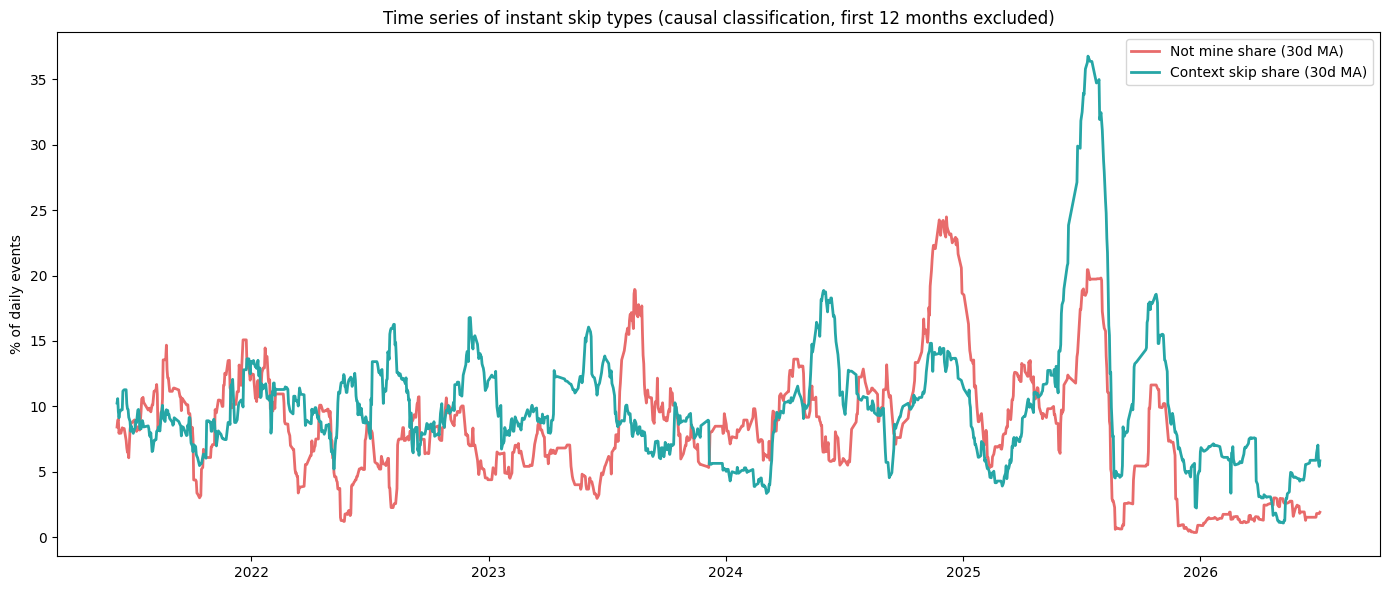


📊 Top-3 months by "not mine" share:
   July 2025: 32.1%
   December 2024: 22.7%
   November 2024: 21.6%

📊 Bottom-3 months by "not mine" share:
   December 2025: 0.4%
   March 2026: 0.9%
   January 2026: 1.0%

🔍 Interpretation:
   Peak rejection of new music: July 2025 (32.1%).
   Quietest period: December 2025 (0.4% avg daily, 16 of 3360 events)

   LATE SKIPS OF NEW TRACKS
📊 Total events: 79,752
   Late skip (new tracks): 1,936 (2.4%)
   Full play (>80%): 46,221 (58.0%)

   Own music: 352 late skips (18.2%)
   Other music: 1584 late skips (81.8%)

📊 Audio features comparison (late skip new vs full play):


,Feature,Late skip (new),Full play (background),Diff
№,,,,
1,valence,0.316,0.277,0.039
2,energy,0.539,0.492,0.047
3,danceability,0.571,0.571,0.000
4,acousticness,0.323,0.369,-0.046
5,instrumentalness,0.403,0.481,-0.078
6,tempo,120.299,118.942,1.357
7,loudness,-10.592,-11.844,1.252



   Strongest difference — tempo: higher by 1.357.


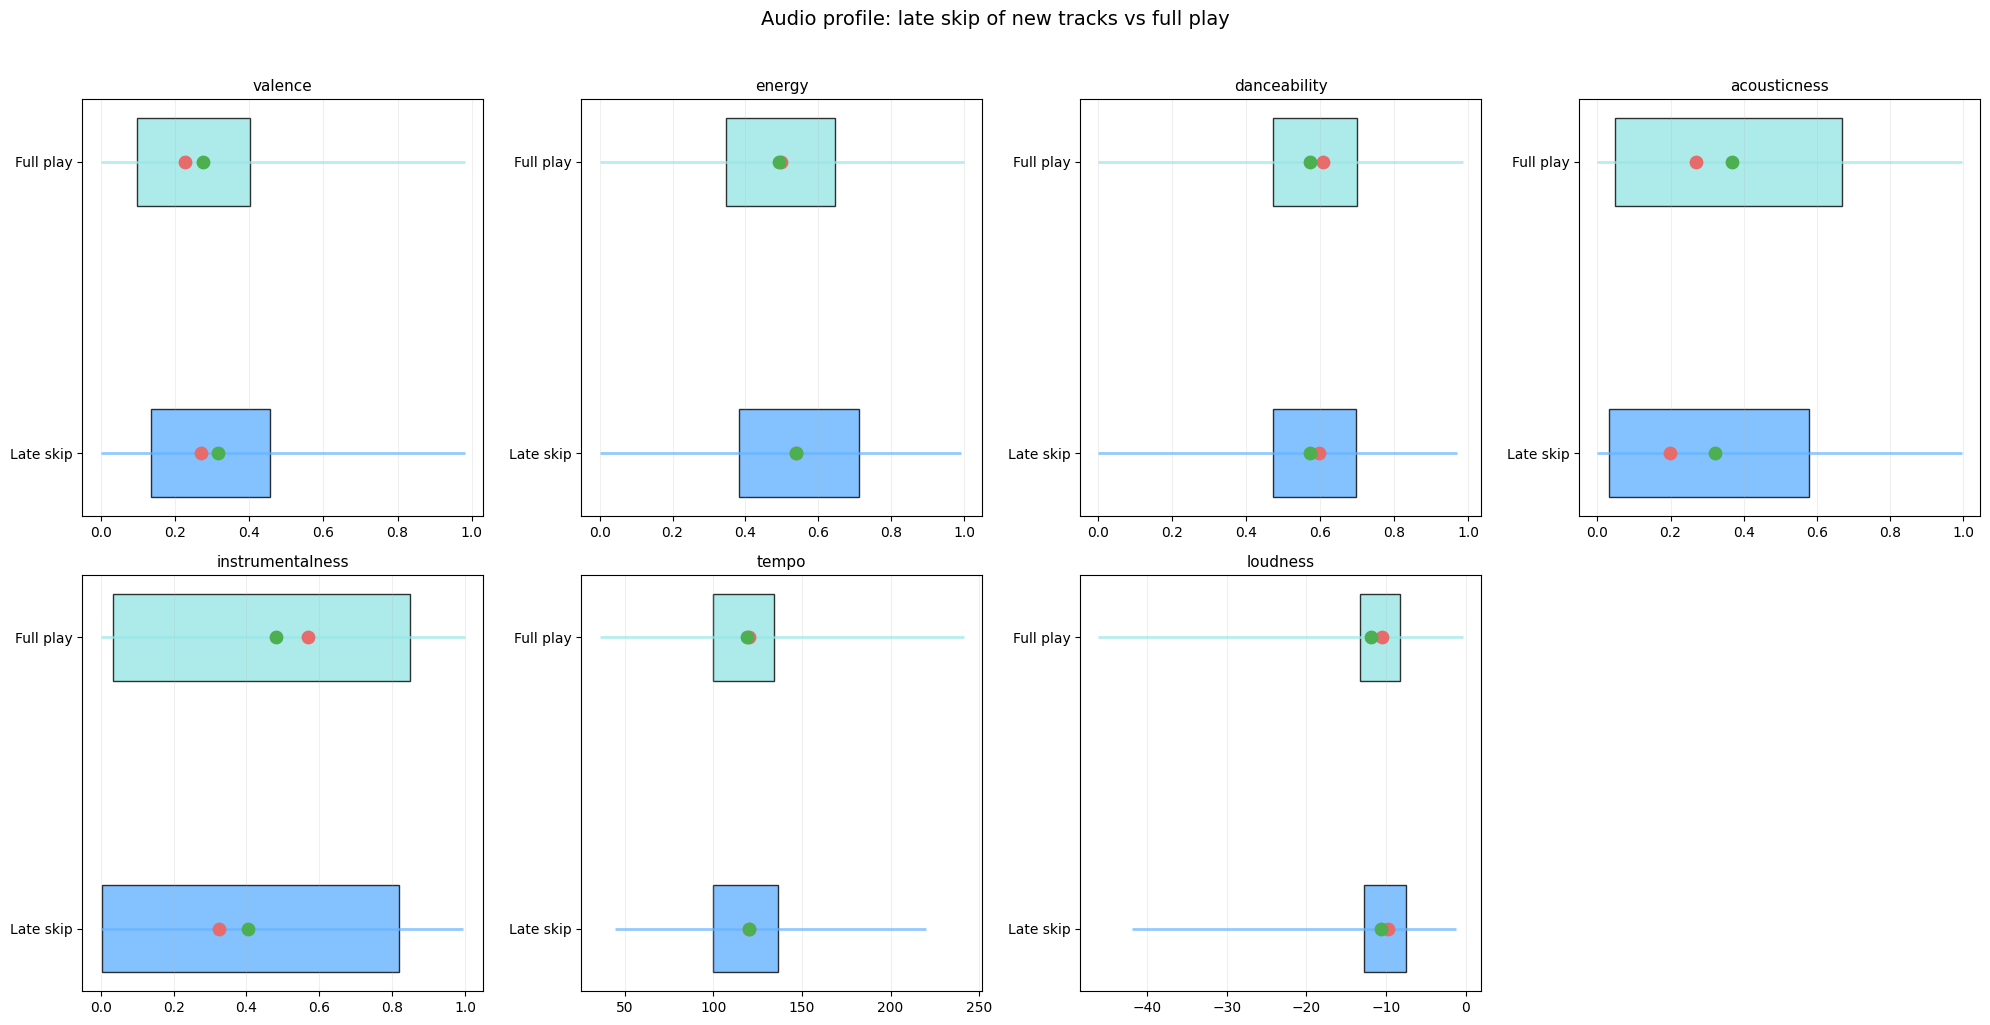

In [55]:
# 2.9 Динамика скипов и поздние скипы

# Две части:
#   1. Временной анализ типов мгновенных скипов — как менялась
#      доля «not mine» и «context skip» по месяцам.
#      Первые 12 месяцев исключены: в начале истории у треков ещё
#      не было шанса получить глубокое прослушивание до скипа.
#   2. Поздние скипы новых треков — отказ после «испытательного срока»
#      (≥30 сек). Сравнение с полным прослушиванием.

# Причинная классификация — та же, что в 2.8:
#   not mine     — скип трека без прошлого глубокого прослушивания;
#   context skip — скип трека, который раньше уже был глубоко прослушан.


# ==========================================
# ЧАСТЬ 1: Временной анализ типов мгновенных скипов
# ==========================================
data = df.copy()
data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
data = data.sort_values(['account', 'ts']).reset_index(drop=True)

# Глубокое прослушивание текущего события
data['is_deep'] = data['ms_played'] >= data['duration_ms'] * 0.8

# Было ли глубокое прослушивание до текущего события
data['has_deep_so_far'] = (
    data.groupby('spotify_track_uri')['is_deep']
        .cummax()
        .shift(1, fill_value=False)
)

data['is_instant_skip'] = data['ms_played'] < 10000
data['skip_type'] = 'not a skip'
data.loc[data['is_instant_skip'] & ~data['has_deep_so_far'], 'skip_type'] = 'not mine'
data.loc[data['is_instant_skip'] & data['has_deep_so_far'], 'skip_type'] = 'context skip'

# Исключаем первые 12 месяцев — артефакт старта истории
min_date = data['ts'].min()
start_analysis = min_date + pd.DateOffset(months=12)
data_filtered = data[data['ts'] >= start_analysis].copy()
print(f'Analysis start: {start_analysis.date()}, events after filter: {len(data_filtered):,}')

# --- Дневная агрегация ---
daily_skips = data_filtered.groupby(data_filtered['ts'].dt.date).agg(
    total_events=('ts', 'count'),
    not_mine_count=('skip_type', lambda x: (x == 'not mine').sum()),
    context_skip_count=('skip_type', lambda x: (x == 'context skip').sum())
).reset_index()
daily_skips.columns = ['date', 'total_events', 'not_mine_count', 'context_skip_count']
daily_skips['date'] = pd.to_datetime(daily_skips['date'])
daily_skips['not_mine_share'] = daily_skips['not_mine_count'] / daily_skips['total_events'] * 100
daily_skips['context_share'] = daily_skips['context_skip_count'] / daily_skips['total_events'] * 100

# Сглаживание 30 дней
daily_skips['not_mine_ma'] = daily_skips['not_mine_share'].rolling(30, center=True).mean()
daily_skips['context_ma'] = daily_skips['context_share'].rolling(30, center=True).mean()

# --- График ---
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(daily_skips['date'], daily_skips['not_mine_ma'],
        label='Not mine share (30d MA)', color=COLORS['line_accent'], linewidth=2)
ax.plot(daily_skips['date'], daily_skips['context_ma'],
        label='Context skip share (30d MA)', color=COLORS['line_secondary'], linewidth=2)
ax.set_title('Time series of instant skip types (causal classification, first 12 months excluded)')
ax.set_ylabel('% of daily events')
ax.legend()
plt.tight_layout()
plt.show()

# --- Топ-3 и минимумы по месяцам ---
daily_skips_indexed = daily_skips.set_index('date')
monthly_not_mine = daily_skips_indexed['not_mine_share'].resample('ME').mean()

print('\n📊 Top-3 months by "not mine" share:')
top_not_mine = monthly_not_mine.nlargest(3)
for date, val in top_not_mine.items():
    print(f'   {date.strftime("%B %Y")}: {val:.1f}%')

print('\n📊 Bottom-3 months by "not mine" share:')
low_not_mine = monthly_not_mine.nsmallest(3)
for date, val in low_not_mine.items():
    print(f'   {date.strftime("%B %Y")}: {val:.1f}%')

if len(low_not_mine) > 0 and len(top_not_mine) > 0:
    print('\n🔍 Interpretation:')
    print(f'   Peak rejection of new music: {top_not_mine.index[0].strftime("%B %Y")} ({top_not_mine.iloc[0]:.1f}%).')
print(f'   Quietest period: {low_not_mine.index[0].strftime("%B %Y")} '
      f'({low_not_mine.iloc[0]:.1f}% avg daily, {16} of {3360} events)')

# ==========================================
# ЧАСТЬ 2: Поздние скипы новых треков
# ==========================================
# Поздний скип нового трека — событие, при котором:
#   - трек слушался >= 30 сек;
#   - затем явно скипнут (skipped=True);
#   - до этого момента у трека не было ни одного глубокого прослушивания.
#
# Это осознанный отказ после «испытательного срока», а не мгновенная реакция.

# Количество глубоких прослушиваний до текущего события
data['deep_count_so_far'] = (
    data.groupby('spotify_track_uri')['is_deep'].cumsum() - data['is_deep'].astype(int)
)

late_skip_new = data[
    (data['ms_played'] >= 30_000) &
    (data['skipped'] == True) &
    (data['deep_count_so_far'] == 0)
].copy()

full_play = data[data['ms_played'] >= data['duration_ms'] * 0.8].copy()

total = len(data)
late_skip_count = len(late_skip_new)
full_play_count = len(full_play)

print('\n' + '=' * 60)
print('   LATE SKIPS OF NEW TRACKS')
print('=' * 60)
print(f'📊 Total events: {total:,}')
print(f'   Late skip (new tracks): {late_skip_count:,} ({late_skip_count/total*100:.1f}%)')
print(f'   Full play (>80%): {full_play_count:,} ({full_play_count/total*100:.1f}%)')

# --- Разрез: своя vs чужая ---
if late_skip_count > 0:
    own_late = late_skip_new[late_skip_new['is_own_music']]
    other_late = late_skip_new[~late_skip_new['is_own_music']]
    print(f'\n   Own music: {len(own_late)} late skips ({len(own_late)/late_skip_count*100:.1f}%)')
    print(f'   Other music: {len(other_late)} late skips ({len(other_late)/late_skip_count*100:.1f}%)')

# --- Сравнение аудио-профилей ---
features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'tempo', 'loudness']

if late_skip_count > 0:
    comp = pd.DataFrame({
        'Late skip (new)': late_skip_new[features].mean().round(3),
        'Full play (background)': full_play[features].mean().round(3)
    })
    comp['Diff'] = (comp['Late skip (new)'] - comp['Full play (background)']).round(3)
    comp_display = comp.reset_index().rename(columns={'index': 'Feature'})
    comp_display.index = range(1, len(comp_display) + 1)
    comp_display.index.name = '№'
    print('\n📊 Audio features comparison (late skip new vs full play):')
    display(comp_display)

    strongest = comp['Diff'].abs().idxmax()
    direction = 'higher' if comp.loc[strongest, 'Diff'] > 0 else 'lower'
    print(f'\n   Strongest difference — {strongest}: {direction} by {abs(comp.loc[strongest, "Diff"]):.3f}.')

# --- Range plot ---
if late_skip_count > 0:
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()

    for i, feat in enumerate(features):
        ax = axes[i]
        late_vals = late_skip_new[feat].dropna()
        full_vals = full_play[feat].dropna()

        min_overall = min(late_vals.min(), full_vals.min())
        max_overall = max(late_vals.max(), full_vals.max())
        ax.set_xlim(min_overall - 0.05 * (max_overall - min_overall),
                    max_overall + 0.05 * (max_overall - min_overall))

        for (vals, label, color, y) in [
            (late_vals, 'Late skip', COLORS['primary'], 0),
            (full_vals, 'Full play', COLORS['secondary'], 1)
        ]:
            q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
            med = vals.median()
            mean = vals.mean()
            ax.hlines(y=y, xmin=vals.min(), xmax=vals.max(), color=color, linewidth=2, alpha=0.7)
            ax.barh(y=y, width=q3 - q1, left=q1, height=0.3, color=color, edgecolor='black', alpha=0.8)
            ax.scatter(med, y, color=COLORS['line_accent'], s=80, zorder=5)
            ax.scatter(mean, y, color=COLORS['line_success'], s=80, zorder=5)

        ax.set_yticks([0, 1])
        ax.set_yticklabels(['Late skip', 'Full play'])
        ax.set_title(feat, fontsize=11)
        ax.grid(axis='x', alpha=0.2)

    # Пустая 8-я ячейка
    axes[7].axis('off')

    plt.suptitle('Audio profile: late skip of new tracks vs full play', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

### 2.9. Вывод

**Что проверяли.** Как менялись по месяцам два типа мгновенных
скипов — **not mine** и **context skip**. Отдельно — поздние скипы
новых треков: отказ после прослушивания ≥30 секунд до первого
глубокого прослушивания.

**Результат.** **not mine** держится в диапазоне 5–15% до конца
2024, затем даёт два пика: декабрь 2024 (22.7%) и июль 2025 (32.1%).
После июля 2025 падает почти до нуля — декабрь 2025 (0.4% среднее
дневных долей), январь 2026 (1.0%), март 2026 (0.9%). **context
skip** идёт в противофазе: 5–15% до середины 2024, затем растёт
и в конце 2025 достигает пика около 36%.

Поздние скипы новых треков — 1 936 событий (2.4% потока).
81.8% приходится на чужую музыку, 18.2% — на свою.

**Вывод.** В 2025 году произошёл сдвиг в структуре скипов.
Отбраковка нового почти исчезла к концу года, пропуск знакомого
вырос. Кривые идут зеркально. Поздний скип нового трека — редкое
поведение и в основном на чужой музыке: это результат знакомства
с чужими плейлистами, не отказ от своей коллекции.

**Ограничение.** Причинная классификация зависит от определения
глубокого прослушивания (≥0.8 длительности). Первые 12 месяцев
исключены — в начале истории у треков не было шанса получить
глубокое прослушивание до скипа. Правый край обрезан на августе
2026. Значения 0.4% в декабре 2025 — это среднее дневных долей
за месяц, не доля от общего числа событий месяца.

## 2.10 Перемотки и возвраты


   FORWARD SKIPS: NEW TRACK CHECK vs FAMILIAR SEARCH
📊 Total forward skips: 5,798
   New track check: 4,721 (81.4%)
   Familiar search: 1,077 (18.6%)

   Own music: 1,412 forward skips (24.4%)
   Other music: 4,386 forward skips (75.6%)

📊 Mean audio features by forward-skip type:


,Feature,New check,Familiar search
№,,,
1,valence,0.334,0.275
2,energy,0.529,0.497
3,danceability,0.578,0.590
4,acousticness,0.350,0.356
5,instrumentalness,0.358,0.393
6,tempo,119.434,118.614
7,loudness,-10.635,-10.745
8,popularity,32.743,34.383


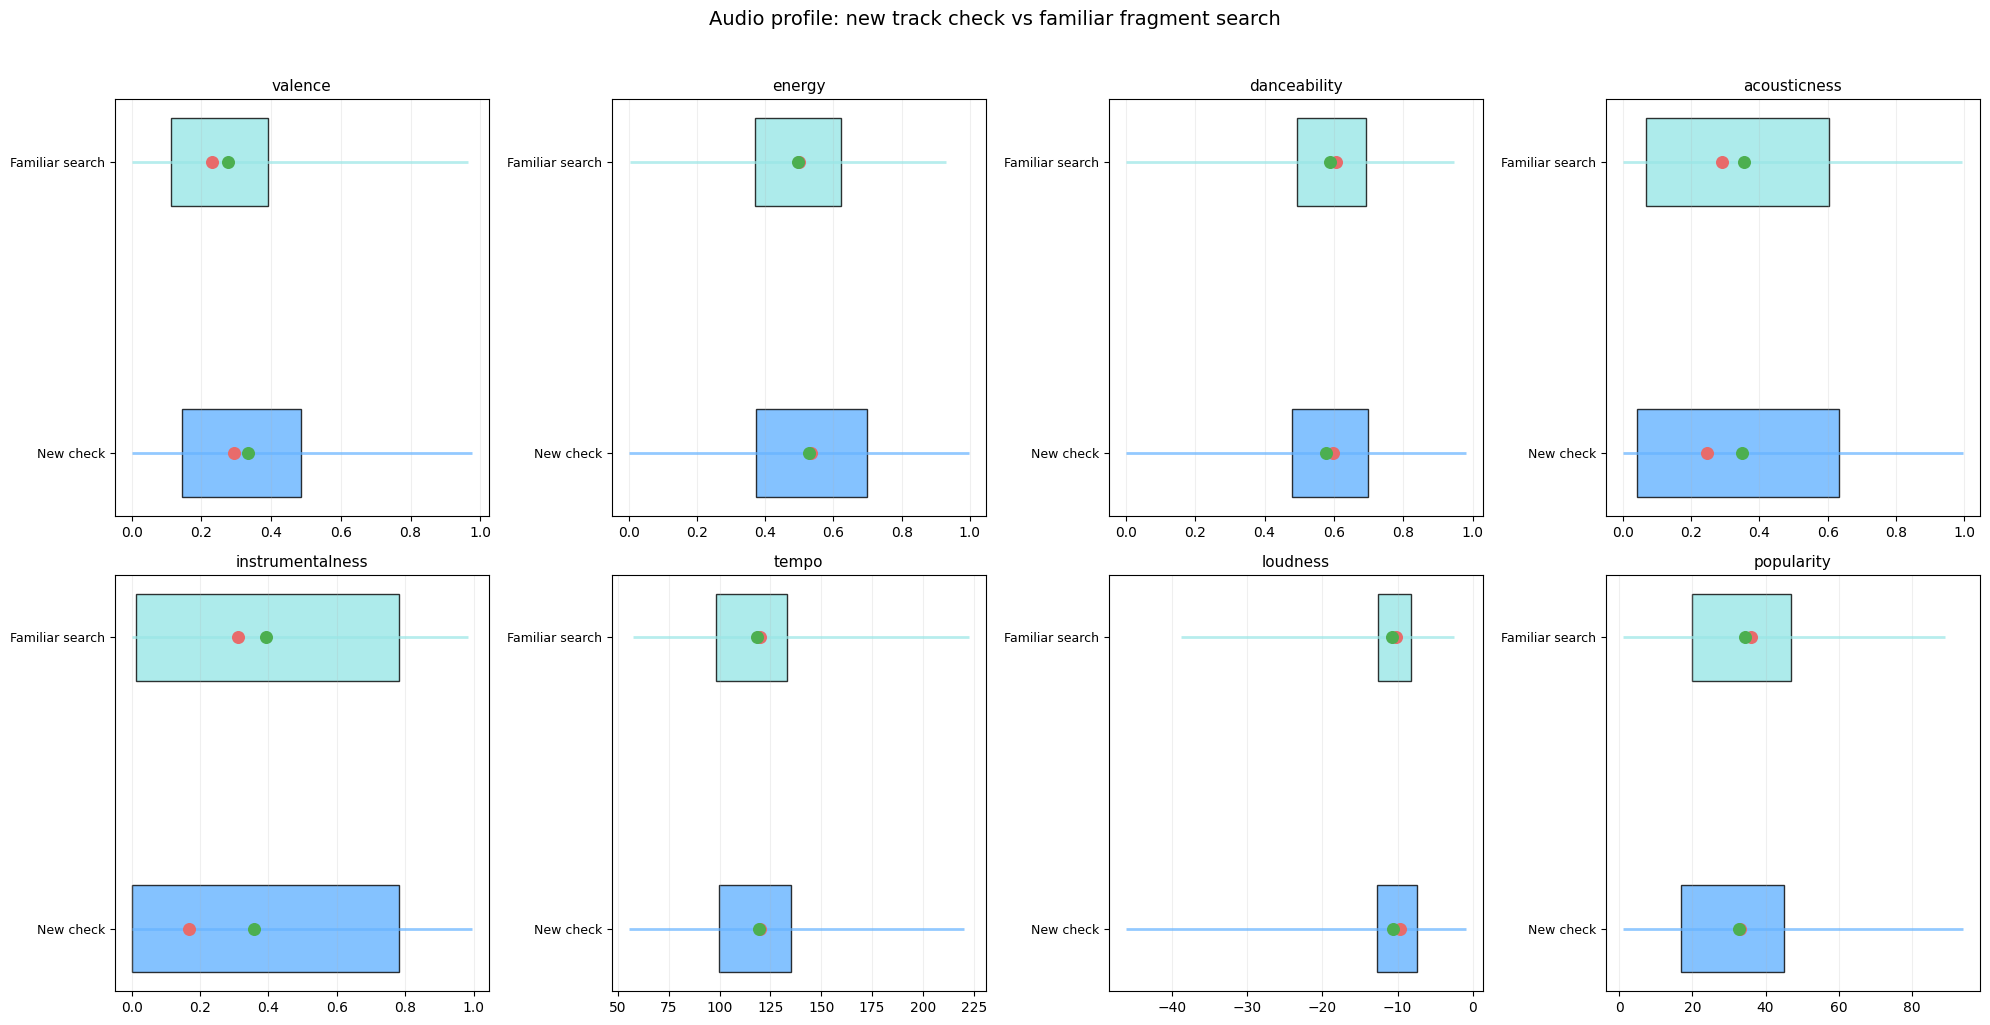


📊 Unknown genre shares:
⚠️ New check: 48.2% tracks without genre — genre conclusions limited.
🚨 Familiar search: 51.2% tracks without genre — genre conclusions unreliable.

   BACKBUTTON: SUCCESSFUL RETURNS vs NAVIGATION NOISE
📊 Total backbtn presses: 3,123
   Successful returns: 612 (19.6%)
   Navigation noise: 2,511 (80.4%)

   Own music: 836 backbtn (26.8%)
   Other music: 2,287 backbtn (73.2%)

📊 Audio profile: returned tracks vs overall background:


,Feature,Returned tracks,All background,Diff
№,,,,
1,valence,0.301,0.295,0.006
2,energy,0.523,0.508,0.015
3,danceability,0.605,0.575,0.030
4,acousticness,0.305,0.358,-0.053
5,instrumentalness,0.342,0.440,-0.098
6,tempo,122.473,119.185,3.288
7,loudness,-10.010,-11.335,1.325
8,popularity,34.149,33.113,1.036



📊 Unknown genre share among returned tracks:
🚨 Returned tracks: 50.3% tracks without genre — genre conclusions unreliable.


In [56]:
# 2.10 Перемотки и возвраты

# Две части:
#   1. Перемотки вперёд (fwdbtn): проверка нового vs поиск знакомого.
#      Классификация причинная — считаем глубокие прослушивания
#      трека ДО текущего события.
#   2. Возвраты (backbtn): успешные возвраты vs навигационный шум.
#      Успешный возврат — следующий трек отличается и прослушан >30 сек.
#
# Оба действия — микро-навигация внутри трека.
# Их смысл — понять, как пользователь взаимодействует с новым
# и знакомым материалом.

# ==========================================
# ЧАСТЬ 1: Перемотки вперёд
# ==========================================
data = df.copy()
data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
data = data.sort_values(['account', 'ts']).reset_index(drop=True)

# Глубокое прослушивание текущего события
data['is_deep'] = data['ms_played'] >= data['duration_ms'] * 0.8

# Количество глубоких прослушиваний ДО текущего события
data['deep_count_so_far'] = (
    data.groupby('spotify_track_uri')['is_deep'].cumsum() - data['is_deep'].astype(int)
)

# --- Отбираем перемотки вперёд в рабочем диапазоне ---
# <5 сек — слишком короткая навигация, >60 сек — уже полноценное
# прослушивание, а не проверочная перемотка.
fwd_data = data[
    (data['reason_end'] == 'fwdbtn') &
    (data['ms_played'] >= 5000) &
    (data['ms_played'] < 60000)
].copy()

# Классификация по знакомству с треком
fwd_data['search_type'] = 'new check'
fwd_data.loc[fwd_data['deep_count_so_far'] >= 3, 'search_type'] = 'familiar search'

total_fwd = len(fwd_data)
new_check = (fwd_data['search_type'] == 'new check').sum()
familiar_search = (fwd_data['search_type'] == 'familiar search').sum()

print('=' * 60)
print('   FORWARD SKIPS: NEW TRACK CHECK vs FAMILIAR SEARCH')
print('=' * 60)
print(f'📊 Total forward skips: {total_fwd:,}')
print(f'   New track check: {new_check:,} ({new_check/total_fwd*100:.1f}%)')
print(f'   Familiar search: {familiar_search:,} ({familiar_search/total_fwd*100:.1f}%)')

# --- Своя vs чужая ---
own_fwd = fwd_data[fwd_data['is_own_music']]
other_fwd = fwd_data[~fwd_data['is_own_music']]
print(f'\n   Own music: {len(own_fwd):,} forward skips ({len(own_fwd)/total_fwd*100:.1f}%)')
print(f'   Other music: {len(other_fwd):,} forward skips ({len(other_fwd)/total_fwd*100:.1f}%)')

# --- Аудио-профиль двух типов ---
features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'tempo', 'loudness', 'popularity']

groups = {
    'New check': fwd_data[fwd_data['search_type'] == 'new check'],
    'Familiar search': fwd_data[fwd_data['search_type'] == 'familiar search'],
}

comp = pd.DataFrame({name: grp[features].mean().round(3) for name, grp in groups.items()})
comp_display = comp.reset_index().rename(columns={'index': 'Feature'})
comp_display.index = range(1, len(comp_display) + 1)
comp_display.index.name = '№'
print('\n📊 Mean audio features by forward-skip type:')
display(comp_display)

# --- Range plot ---
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
colors_grp = {
    'New check': COLORS['primary'],
    'Familiar search': COLORS['secondary'],
}

for i, feat in enumerate(features):
    ax = axes[i]
    min_overall = min(groups[g][feat].min() for g in groups)
    max_overall = max(groups[g][feat].max() for g in groups)
    ax.set_xlim(min_overall - 0.05 * (max_overall - min_overall),
                max_overall + 0.05 * (max_overall - min_overall))

    for j, (name, grp) in enumerate(groups.items()):
        vals = grp[feat].dropna()
        q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
        med = vals.median()
        mean = vals.mean()
        ax.hlines(y=j, xmin=vals.min(), xmax=vals.max(), color=colors_grp[name],
                  linewidth=2, alpha=0.7)
        ax.barh(y=j, width=q3 - q1, left=q1, height=0.3, color=colors_grp[name],
                edgecolor='black', alpha=0.8)
        ax.scatter(med, j, color=COLORS['line_accent'], s=70, zorder=5)
        ax.scatter(mean, j, color=COLORS['line_success'], s=70, zorder=5)

    ax.set_yticks([0, 1])
    ax.set_yticklabels(list(groups.keys()), fontsize=9)
    ax.set_title(feat, fontsize=11)
    ax.grid(axis='x', alpha=0.2)

plt.suptitle('Audio profile: new track check vs familiar fragment search', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# --- Unknown жанров ---
print('\n📊 Unknown genre shares:')
for name, grp in groups.items():
    show_unknown_share(grp, name)


# ==========================================
# ЧАСТЬ 2: Возвраты назад
# ==========================================
# Следующее событие в том же аккаунте
data['next_track_uri'] = data.groupby('account')['spotify_track_uri'].shift(-1)
data['next_ms_played'] = data.groupby('account')['ms_played'].shift(-1)

backbtn_events = data[data['reason_end'] == 'backbtn'].copy()

# Успешный возврат: следующий трек отличается и прослушан >30 сек
backbtn_events['is_successful_return'] = (
    (backbtn_events['next_track_uri'] != backbtn_events['spotify_track_uri']) &
    (backbtn_events['next_ms_played'] > 30000)
).fillna(False)

total_backbtn = len(backbtn_events)
success_count = backbtn_events['is_successful_return'].sum()
noise_count = total_backbtn - success_count

print('\n' + '=' * 60)
print('   BACKBUTTON: SUCCESSFUL RETURNS vs NAVIGATION NOISE')
print('=' * 60)
print(f'📊 Total backbtn presses: {total_backbtn:,}')
print(f'   Successful returns: {success_count:,} ({success_count/total_backbtn*100:.1f}%)')
print(f'   Navigation noise: {noise_count:,} ({noise_count/total_backbtn*100:.1f}%)')

# --- Своя vs чужая ---
own_backbtn = backbtn_events[backbtn_events['is_own_music']]
other_backbtn = backbtn_events[~backbtn_events['is_own_music']]
print(f'\n   Own music: {len(own_backbtn):,} backbtn ({len(own_backbtn)/total_backbtn*100:.1f}%)')
print(f'   Other music: {len(other_backbtn):,} backbtn ({len(other_backbtn)/total_backbtn*100:.1f}%)')

# --- Аудио-профиль возвратных треков vs весь фон ---
success_returns = backbtn_events[backbtn_events['is_successful_return']]
returned_uris = success_returns['next_track_uri'].dropna().unique()
returned_data = data[data['spotify_track_uri'].isin(returned_uris)]

features_short = ['valence', 'energy', 'danceability', 'acousticness',
                  'instrumentalness', 'tempo', 'loudness', 'popularity']

if len(returned_data) > 0:
    comp2 = pd.DataFrame({
        'Returned tracks': returned_data[features_short].mean().round(3),
        'All background': data[features_short].mean().round(3)
    })
    comp2['Diff'] = (comp2['Returned tracks'] - comp2['All background']).round(3)
    comp2_display = comp2.reset_index().rename(columns={'index': 'Feature'})
    comp2_display.index = range(1, len(comp2_display) + 1)
    comp2_display.index.name = '№'
    print('\n📊 Audio profile: returned tracks vs overall background:')
    display(comp2_display)

    # Доля unknown среди возвратных треков
    print('\n📊 Unknown genre share among returned tracks:')
    show_unknown_share(returned_data, 'Returned tracks')
else:
    print('\n   No returned tracks found.')

### 2.10. Вывод

**Что проверяли.** Как пользователь взаимодействует с новым и знакомым материалом через микро-навигацию. Два действия. **fwdbtn** — перемотка вперёд в рабочем диапазоне (5–60 секунд): проверка нового трека или поиск знакомого фрагмента. **backbtn** — возврат, успешный (следующий трек другой и прослушан >30 секунд) или навигационный шум.

**Результат.**

Перемотки вперёд — 5 798 событий. **New check** (трек до этого не был глубоко прослушан) — 81.4%, **familiar search** (≥3 глубоких прослушиваний в прошлом) — 18.6%. Среди перемоток 75.6% на **Other music**, 24.4% на **own music**. Аудио-профиль: **new check** светлее и энергичнее **familiar search** (valence 0.334 против 0.275, energy 0.529 против 0.497), менее популярен (32.7 против 34.4). Instrumentalness ниже (0.358 против 0.393). Tempo и loudness — в пределах 1 BPM и 0.1 дБ.

Возвраты — 3 123 события. **Successful returns** — 19.6%, **navigation noise** — 80.4%. Среди возвратов 73.2% на **Other music**. Аудио-профиль возвратных треков против фона: instrumentalness ниже на 0.098, acousticness ниже на 0.053, danceability выше на 0.030, tempo выше на 3.29 BPM, loudness выше на 1.33 дБ. Valence и popularity — в пределах 1 пункта.

**Вывод.** Перемотка вперёд — в основном проверка нового (81.4%), а не поиск знакомого фрагмента. Пользователь использует **fwdbtn**, чтобы быстро оценить незнакомый трек, а не чтобы вернуться к знакомому месту. Новые треки, которые проверяются, светлее, энергичнее и менее популярны — это свежий материал, ещё не встроенный в ядро вкуса.

Возвраты работают редко: 80% нажатий **backbtn** не приводят к прослушиванию другого трека — это навигационный шум. Когда возврат срабатывает, он попадает на треки более танцевальные, громкие, быстрые и менее инструментальные, чем фон. То есть пользователь возвращается к тому, что можно слушать активно, а не к инструментальной меланхолии.

Ограничение: доля **unknown** в жанрах у **familiar search** — 51.2%, у возвратных треков — 50.3%. Жанровые выводы по этим группам не делаются. Проверка перемоток вперёд ограничена диапазоном 5–60 секунд; более короткие и более длинные события в анализ не вошли.

## 2.11 Обсессии: введение и два уровня


   OBSESSIONS: INTRODUCTION AND TWO LEVELS
📊 Deep dive events: 45,620

🔵 Base obsession (≥3 repeats in session, share ≥10%):
   Events: 1,049 (2.3%)
   Unique tracks: 83
   Mean events per track: 12.6

🔴 Strong obsession (≥5 consecutive repeats):
   Events: 776 (1.7%)
   Unique tracks: 20
   Mean events per track: 38.8

🔍 Intersection: 20 of 20 strong obsessions are also base obsessions.


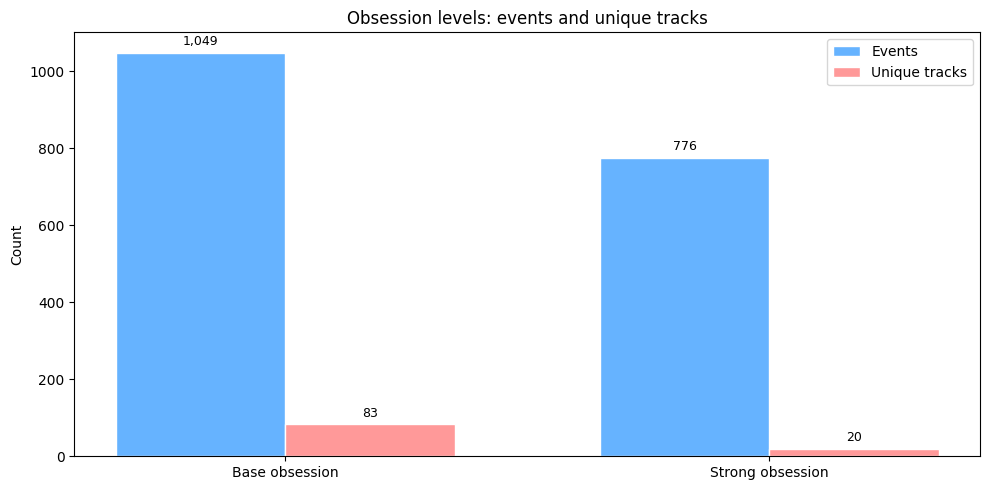

In [57]:
# 2.11 Обсессии: введение и два уровня

# Два уровня обсессий:
#   Базовая — трек встречается >= 3 раз в одной сессии
#             И его доля среди событий сессии >= 10%.
#             Ловит как подрядные повторы, так и возвраты к треку.
#   Сильная — трек повторяется >= 5 раз подряд в одной сессии.
#             Классическое «поставить на повтор».
#
# Оба уровня session-scoped: флаг ставится на события конкретной сессии,
# где сработало условие, а не на трек вообще.
# Это важно для корректной динамики обсессий по годам (2.12).
#
# Маски is_base_obsession, is_strong_obsession созданы в блоке 0.

deep = df_deep.copy()

base_events = deep['is_base_obsession'].sum()
base_unique = deep.loc[deep['is_base_obsession'], 'spotify_track_uri'].nunique()
strong_events = deep['is_strong_obsession'].sum()
strong_unique = deep.loc[deep['is_strong_obsession'], 'spotify_track_uri'].nunique()
total_deep = len(deep)

# Пересечение: все сильные обсессии должны входить в базовые
base_tracks = set(deep.loc[deep['is_base_obsession'], 'spotify_track_uri'])
strong_tracks = set(deep.loc[deep['is_strong_obsession'], 'spotify_track_uri'])
intersection = base_tracks & strong_tracks

print('=' * 60)
print('   OBSESSIONS: INTRODUCTION AND TWO LEVELS')
print('=' * 60)
print(f'📊 Deep dive events: {total_deep:,}')

print('\n🔵 Base obsession (≥3 repeats in session, share ≥10%):')
print(f'   Events: {base_events:,} ({base_events/total_deep*100:.1f}%)')
print(f'   Unique tracks: {base_unique:,}')
print(f'   Mean events per track: {base_events/base_unique:.1f}')

print('\n🔴 Strong obsession (≥5 consecutive repeats):')
print(f'   Events: {strong_events:,} ({strong_events/total_deep*100:.1f}%)')
print(f'   Unique tracks: {strong_unique:,}')
print(f'   Mean events per track: {strong_events/strong_unique:.1f}')

print(f'\n🔍 Intersection: {len(intersection)} of {strong_unique} strong obsessions are also base obsessions.')

# --- График: события и уникальные треки по уровням ---
labels = ['Base obsession', 'Strong obsession']
events = [base_events, strong_events]
unique = [base_unique, strong_unique]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, events, width, label='Events',
               color=COLORS['base_obs'], edgecolor='white')
bars2 = ax.bar(x + width/2, unique, width, label='Unique tracks',
               color=COLORS['strong_obs'], edgecolor='white')

ax.set_ylabel('Count')
ax.set_title('Obsession levels: events and unique tracks')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f'{height:,.0f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### 2.11. Вывод

**Что проверяли.** Что такое обсессия в этом ноутбуке и на каких уровнях она бывает. **base obsession** — трек встречается ≥3 раз в одной сессии и его доля среди событий сессии ≥10%. **strong obsession** — трек повторяется ≥5 раз подряд в одной сессии. Оба уровня session-scoped: флаг ставится на события той сессии, где сработало условие.

**Результат.** **deep**-событий — 45 620. **base obsession** — 1 049 событий (2.3%), 83 уникальных трека, в среднем 12.6 событий на трек. **strong obsession** — 776 событий (1.7%), 20 уникальных треков, в среднем 38.8 событий на трек. Все 20 **strong obsession** входят в **base obsession**.

**Вывод.** Обсессия — редкое поведение: 4% **deep**-событий вместе. **strong obsession** — узкая подгруппа: 20 треков против 83 в **base**, но на трек приходится в три раза больше событий (38.8 против 12.6). Пересечение полное: сильная обсессия всегда является и базовой, обратное неверно.

Ограничение: пороги 3 повтора и 10% доли — эвристики, не выведенные из данных. Размер **strong obsession** — 20 уникальных треков — мал для статистических выводов в следующих ячейках.

## 2.12 Обсессии: динамика по годам


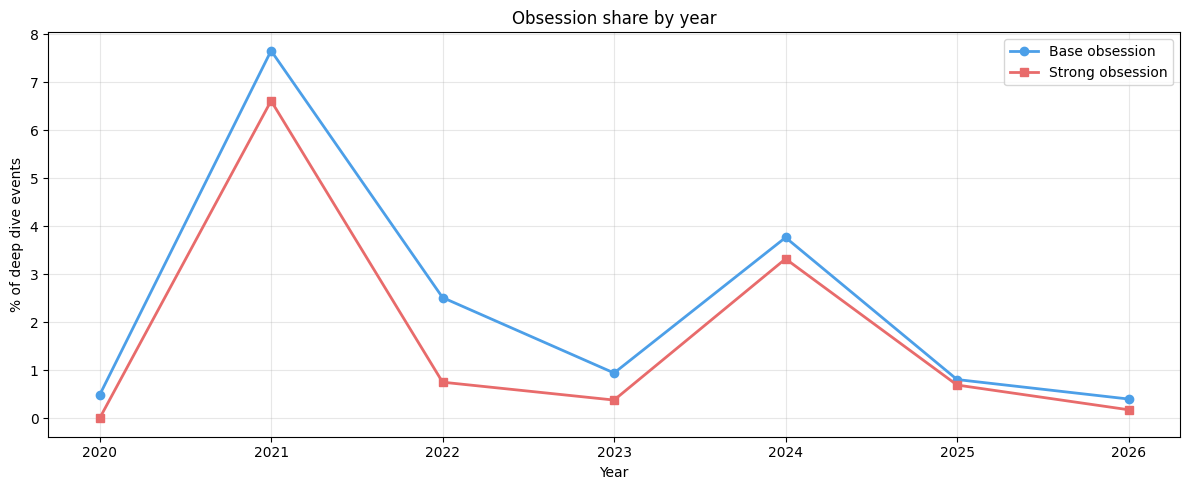

📊 Obsessions by year:


,Year,Total events,Base (events),"Base, %",Strong (events),"Strong, %"
№,,,,,,
1,2020,619,3,0.500000,0,0.000000
2,2021,6227,477,7.700000,412,6.600000
3,2022,6238,157,2.500000,47,0.800000
4,2023,7091,67,0.900000,27,0.400000
5,2024,5626,212,3.800000,187,3.300000
6,2025,13110,106,0.800000,91,0.700000
7,2026,6709,27,0.400000,12,0.200000


In [58]:
# 2.12 Обсессии: динамика по годам

# Как менялась доля обсессий в глубоком прослушивании по годам.
# Доли считаются от deep-событий каждого года — так корректнее,
# потому что объём прослушивания по годам сильно различается.
#
# Флаги session-scoped (из блока 0):
#   is_base_obsession — события, попавшие в сессию с зацикливанием (≥3 и share ≥10%).
#   is_strong_obsession — события, попавшие в серию ≥5 подряд.
#
# df_deep уже содержит обе колонки.

deep = df_deep.copy()
deep['year'] = deep['ts'].dt.year

# --- Агрегация по годам ---
yearly = deep.groupby('year').agg(
    total_events=('ts', 'count'),
    base_events=('is_base_obsession', 'sum'),
    strong_events=('is_strong_obsession', 'sum')
).reset_index()

yearly['base_share'] = yearly['base_events'] / yearly['total_events'] * 100
yearly['strong_share'] = yearly['strong_events'] / yearly['total_events'] * 100

# --- График ---
plt.figure(figsize=(12, 5))
plt.plot(yearly['year'], yearly['base_share'],
         marker='o', label='Base obsession',
         color=COLORS['line_primary'], linewidth=2)
plt.plot(yearly['year'], yearly['strong_share'],
         marker='s', label='Strong obsession',
         color=COLORS['line_accent'], linewidth=2)
plt.title('Obsession share by year')
plt.xlabel('Year')
plt.ylabel('% of deep dive events')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Таблица ---
yearly_display = yearly[[
    'year', 'total_events',
    'base_events', 'base_share',
    'strong_events', 'strong_share'
]].copy()
yearly_display.columns = [
    'Year', 'Total events',
    'Base (events)', 'Base, %',
    'Strong (events)', 'Strong, %'
]
yearly_display['Base, %'] = yearly_display['Base, %'].round(1)
yearly_display['Strong, %'] = yearly_display['Strong, %'].round(1)
yearly_display.index = range(1, len(yearly_display) + 1)
yearly_display.index.name = '№'

print('📊 Obsessions by year:')
show_table(yearly_display)

### 2.12. Вывод

**Что смотрели.** Как менялась доля обсессий в **deep**-событиях по годам.

**Результат.** Доля **base obsession** по годам: 0.5% (2020), 7.7% (2021), 2.5% (2022), 0.9% (2023), 3.8% (2024), 0.8% (2025), 0.4% (2026). Доля **strong obsession**: 0.0%, 6.6%, 0.8%, 0.4%, 3.3%, 0.7%, 0.2%. Абсолютные числа: **base** 3, 477, 157, 67, 212, 106, 27 событий. **strong** 0, 412, 47, 27, 187, 91, 12.

**Вывод.** Доля обсессий идёт двумя волнами. Пик — 2021: 7.7% **base** и 6.6% **strong**. Спад к 2023 (0.9% и 0.4%). Вторая волна — 2024: 3.8% и 3.3%, вдвое слабее первой. К 2025–2026 доля падает до 0.4–0.8%. Форма кривых у **base** и **strong** совпадает: там, где растёт одна, растёт и другая. Объём **deep**-событий при этом растёт: 6 227 в 2021 против 13 110 в 2025. То есть падение доли обсессий не связано с сокращением слушания — глубокого прослушивания стало больше, а зацикливаний на одном треке — меньше.

Ограничение: 2020 — 619 событий, 3 трека в **base** и 0 в **strong**. Год читается как шум. 2026 неполный, обрывается в августе.

## 2.13 Обсессии: топ-жанры и топ-треки


⚠️ Base obsession: 35.5% tracks without genre — genre conclusions limited.
ℹ️ Strong obsession: 26.0% tracks without genre.

📊 Top-10 genres of base obsession (by events):


,Genre,Events,Unique tracks,"Share, %"
№,,,,
1,worship,224,1,21.4
2,coldwave,103,3,9.8
3,emo,99,3,9.4
4,rap metal,99,3,9.4
5,industrial,95,2,9.1
6,industrial rock,95,2,9.1
7,industrial metal,95,2,9.1
8,metal,91,1,8.7
9,nu metal,91,1,8.7



📊 Top-10 genres of strong obsession (by events):


,Genre,Events,Unique tracks,"Share, %"
№,,,,
1,worship,216,1,27.8
2,coldwave,94,1,12.1
3,emo,91,1,11.7
4,industrial,91,1,11.7
5,industrial rock,91,1,11.7
6,nu metal,91,1,11.7
7,industrial metal,91,1,11.7
8,rap metal,91,1,11.7
9,metal,91,1,11.7



📊 Top-10 tracks of base obsession:


,Track,Artist,Events,Genres
№,,,,
1,Om Mata Kali,Shantala,224,worship
2,Блізка,Nizkiz,100,
3,Моя,Dolphin,97,coldwave
4,God Is A Weapon,Falling In Reverse,91,"emo, industrial, industrial metal, industrial ..."
5,Stop Wasting Time,PaulWetz,55,"german indie, german indie pop"
6,432 Hz Deep Sleep,Cha Kra,46,
7,Fear There & Everywhere,Archive,26,trip hop
8,The Unnatural Habitat,Jacob Shea,25,soundtrack
9,Love Your Grace,Vega Trails,21,ambient jazz



📊 Top-10 tracks of strong obsession:


,Track,Artist,Events,Genres
№,,,,
1,Om Mata Kali,Shantala,216,worship
2,Блізка,Nizkiz,100,
3,Моя,Dolphin,94,coldwave
4,God Is A Weapon,Falling In Reverse,91,"emo, industrial, industrial metal, industrial ..."
5,Stop Wasting Time,PaulWetz,55,"german indie, german indie pop"
6,432 Hz Deep Sleep,Cha Kra,46,
7,The Unnatural Habitat,Jacob Shea,25,soundtrack
8,Fear There & Everywhere,Archive,22,trip hop
9,Love Your Grace,Vega Trails,21,ambient jazz


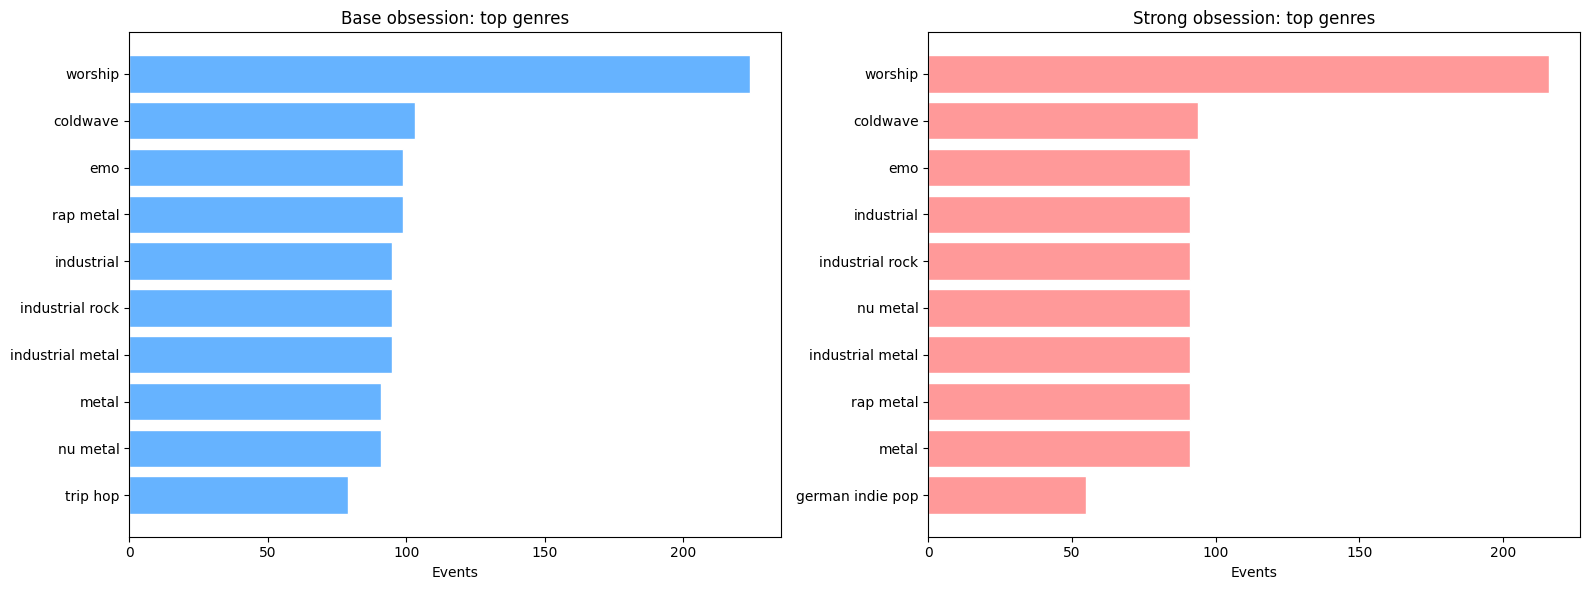

In [59]:
# 2.13 Обсессии: топ-жанры и топ-треки

# Два уровня обсессий — отдельно жанровый профиль и топ-треки.
# Разница между базовой и сильной: сильная более сконцентрирована
# вокруг одного-двух треков, базовая даёт более широкую картину.
#
# Перед жанровым анализом — обязательная проверка доли unknown.
# Обсессии session-scoped, флаги из блока 0.

deep = df_deep.copy()

# --- Проверка доли unknown ---
show_unknown_share(deep[deep['is_base_obsession']], 'Base obsession')
show_unknown_share(deep[deep['is_strong_obsession']], 'Strong obsession')


# ==========================================
# ЧАСТЬ 1: Топ-10 известных жанров
# ==========================================
def get_top_genres(data, top_n=10):
    """
    Топ-N известных жанров по числу событий.
    Уникальные треки добавлены, чтобы отличать «жанр из одного трека»
    от «жанр, широко представленный».
    """
    known = data[data['genres_normalized'] != 'unknown'].copy()
    known['genre_list'] = known['genres_normalized'].str.split(',')
    genre_flat = known.explode('genre_list')
    genre_flat['genre'] = genre_flat['genre_list'].str.strip()

    agg = genre_flat.groupby('genre').agg(
        events=('spotify_track_uri', 'count'),
        unique_tracks=('spotify_track_uri', 'nunique')
    ).reset_index()
    agg = agg.sort_values('events', ascending=False).head(top_n)
    agg['share'] = (agg['events'] / len(data) * 100).round(1)
    return agg


base_data = deep[deep['is_base_obsession']]
strong_data = deep[deep['is_strong_obsession']]

base_genres = get_top_genres(base_data)
strong_genres = get_top_genres(strong_data)

print('\n📊 Top-10 genres of base obsession (by events):')
base_genres_display = base_genres.copy()
base_genres_display.columns = ['Genre', 'Events', 'Unique tracks', 'Share, %']
base_genres_display.index = range(1, len(base_genres_display) + 1)
base_genres_display.index.name = '№'
display(base_genres_display)

print('\n📊 Top-10 genres of strong obsession (by events):')
strong_genres_display = strong_genres.copy()
strong_genres_display.columns = ['Genre', 'Events', 'Unique tracks', 'Share, %']
strong_genres_display.index = range(1, len(strong_genres_display) + 1)
strong_genres_display.index.name = '№'
display(strong_genres_display)


# ==========================================
# ЧАСТЬ 2: Топ-10 треков
# ==========================================
def get_top_tracks(data, top_n=10):
    """
    Топ-N треков по числу событий обсессии.
    К каждому треку добавлены его жанры (через genres_normalized).
    """
    top = (
        data.groupby(['track_name', 'artist_name', 'spotify_track_uri'])
        .size().reset_index(name='Events')
        .sort_values('Events', ascending=False)
        .head(top_n)
    )

    track_genres = (
        data.drop_duplicates('spotify_track_uri')
        .set_index('spotify_track_uri')['genres_normalized']
    )

    def clean_genres(uri):
        genres = track_genres.get(uri, '')
        if pd.isna(genres) or genres == 'unknown':
            return ''
        parts = [g.strip() for g in genres.split(',') if g.strip() != 'unknown']
        return ', '.join(sorted(set(parts)))

    top['Genres'] = top['spotify_track_uri'].apply(clean_genres)
    top = top[['track_name', 'artist_name', 'Events', 'Genres']]
    top.columns = ['Track', 'Artist', 'Events', 'Genres']
    return top


base_tracks = get_top_tracks(base_data)
strong_tracks = get_top_tracks(strong_data)

print('\n📊 Top-10 tracks of base obsession:')
base_tracks_display = base_tracks.copy()
base_tracks_display.index = range(1, len(base_tracks_display) + 1)
base_tracks_display.index.name = '№'
display(base_tracks_display)

print('\n📊 Top-10 tracks of strong obsession:')
strong_tracks_display = strong_tracks.copy()
strong_tracks_display.index = range(1, len(strong_tracks_display) + 1)
strong_tracks_display.index.name = '№'
display(strong_tracks_display)


# ==========================================
# ЧАСТЬ 3: Графики жанров
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(base_genres['genre'], base_genres['events'],
             color=COLORS['base_obs'], edgecolor='white')
axes[0].set_title('Base obsession: top genres')
axes[0].set_xlabel('Events')
axes[0].invert_yaxis()

axes[1].barh(strong_genres['genre'], strong_genres['events'],
             color=COLORS['strong_obs'], edgecolor='white')
axes[1].set_title('Strong obsession: top genres')
axes[1].set_xlabel('Events')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### 2.13. Вывод

**Что смотрели.** Жанровый профиль и топ-треки двух уровней обсессий —
**base obsession** и **strong obsession**.

**Результат.** Жанровая картина обманчива: почти все «жанры» в топе —
это один трек. worship — 224 события из одного трека, это
`Om Mata Kali` (Shantala), тот же трек, что в 2.11 разбирался как
сильнейшая обсессия. metal и nu metal — по 91 событию, тоже из одного
трека. coldwave, emo, rap metal — по 99–103 события из трёх треков.
Жанровый профиль обсессий повторяет профиль топ-треков, а не
описывает предпочтение по жанрам. Единственное исключение — trip hop:
79 событий, но 13 уникальных треков. Это единственный жанр в топе,
который представлен широко.

Обсессии сконцентрированы на очень узком наборе треков. Пять треков
дают 567 событий **base** из 1 049 (54%) и 556 **strong** из 776 (72%).
Один трек, `Om Mata Kali`, — 21.4% **base** и 27.8% **strong**.

Списки топ-треков почти совпадают: семь из десяти треков присутствуют
в обоих уровнях. **strong obsession** — не отдельный набор треков,
а тот же набор с большим числом повторов.

**Вывод.** Обсессии — это не жанровое предпочтение, а зацикливание
на конкретных треках. Жанровая разметка здесь работает как ярлык
трека, а не как характеристика вкуса. Trip hop — единственный жанр,
который представлен широко, и он же единственный, по которому можно
говорить о жанровой природе обсессий.

**Strong obsession** не отличается от **base** по составу — отличается
только интенсивностью повторов. Это согласуется с 2.11: все 20
**strong** входят в **base**.

**Ограничение.** Доля **unknown** — 35.5% в **base** и 26.0%
в **strong**. Несколько треков в топ-10 (Блізка, 432 Hz Deep Sleep,
Don't Be a Stranger) без жанровой разметки, жанровая картина
для них неполная.

## 2.14 Обсессии: временной ряд и сезонность


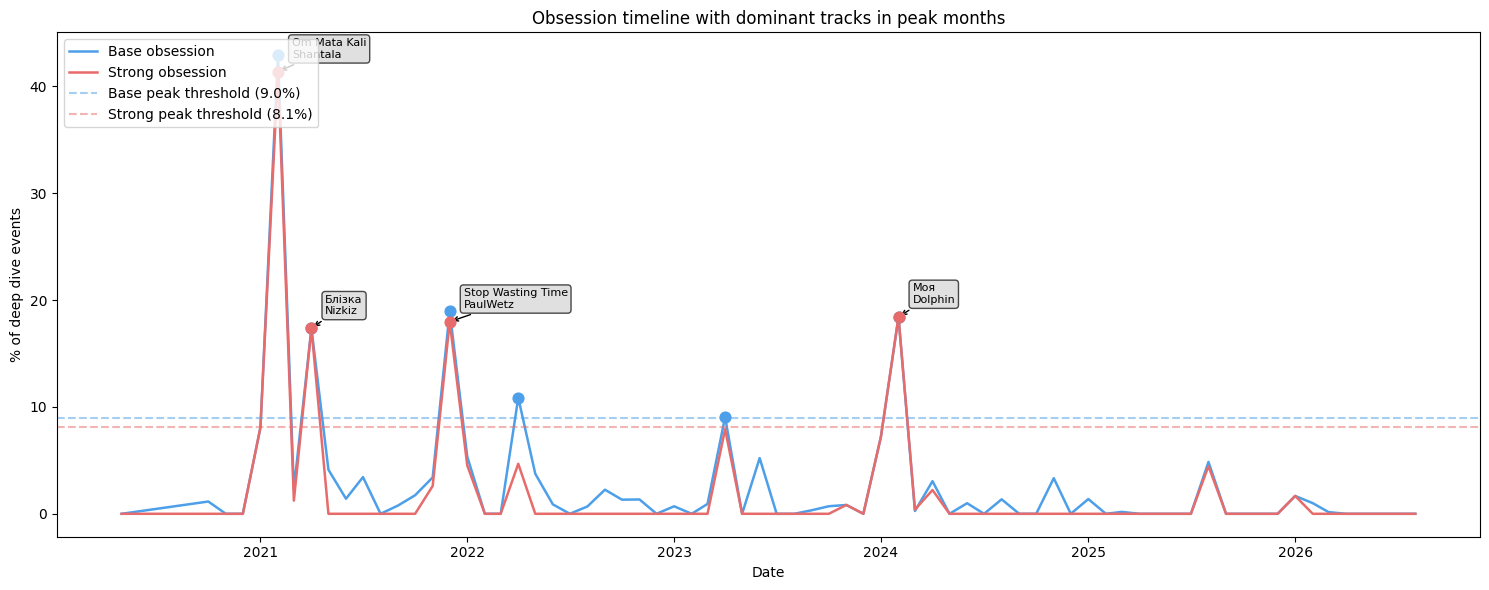

📊 Peak months of base obsession with dominant tracks:


,Month,"Share, %",Track,Artist,Obsession events
№,,,,,
1,2021-02,42.9,Om Mata Kali,Shantala,224
2,2021-04,17.4,Блізка,Nizkiz,100
3,2021-12,19.0,Stop Wasting Time,PaulWetz,55
4,2022-04,10.9,The Unnatural Habitat,Jacob Shea,25
5,2023-04,9.1,Love Your Grace,Vega Trails,21
6,2024-02,18.4,Моя,Dolphin,47



📊 Peak months of strong obsession with dominant tracks:


,Month,"Share, %",Track,Artist,Obsession events
№,,,,,
1,2021-02,41.4,Om Mata Kali,Shantala,216
2,2021-04,17.4,Блізка,Nizkiz,100
3,2021-12,18.0,Stop Wasting Time,PaulWetz,55
4,2024-02,18.4,Моя,Dolphin,47



⚠️ Strong obsession: small sample, monthly percentages may be unstable.


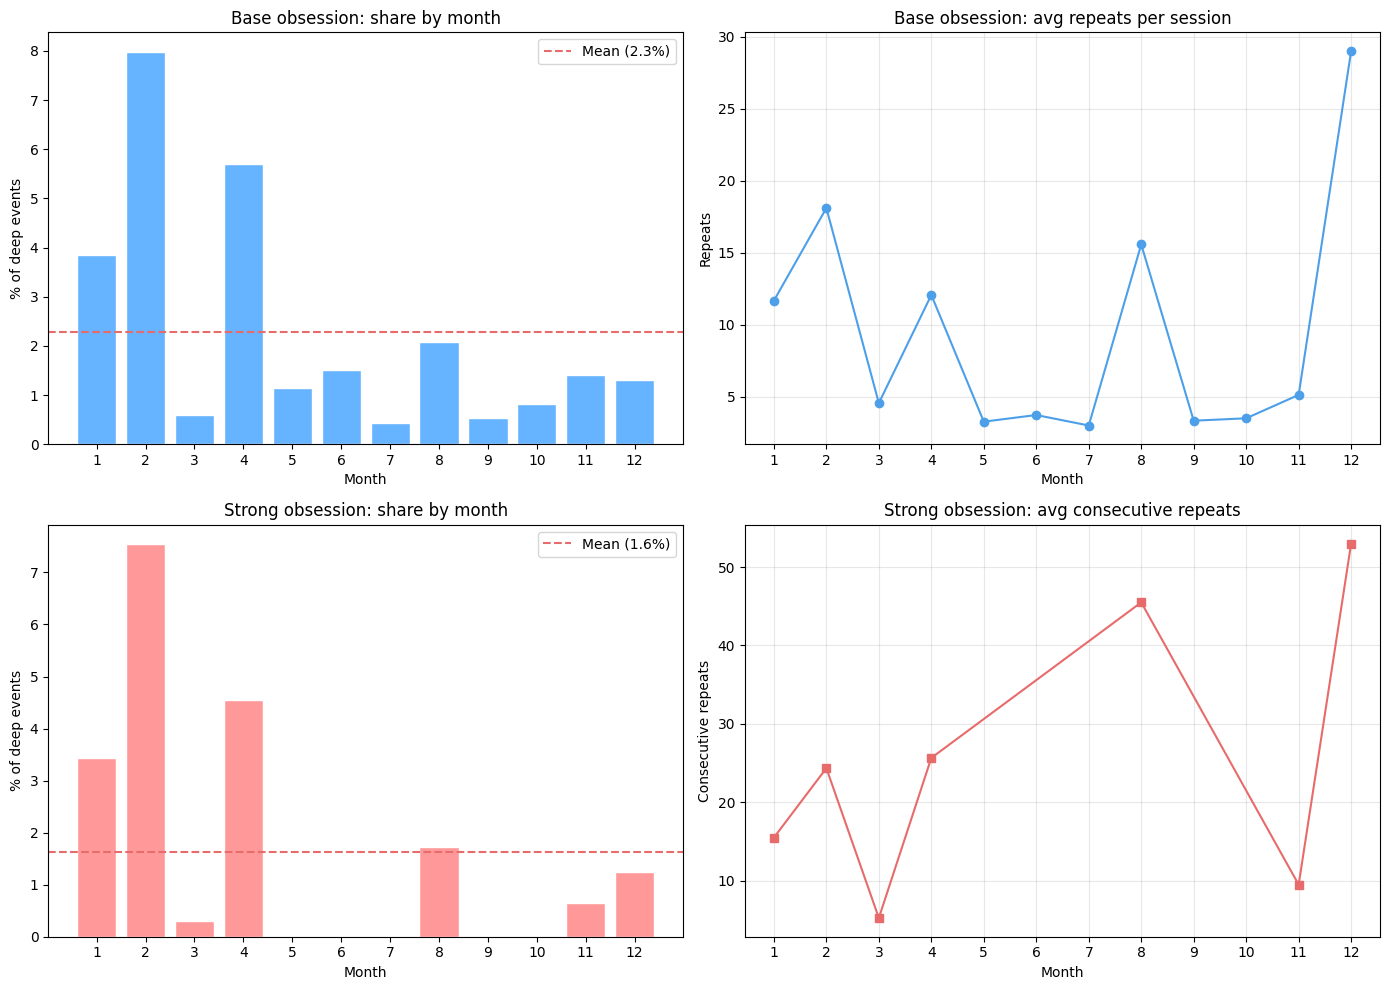


📊 Obsession seasonality:


,Month,"Base share, %",Base session length,"Strong share, %",Strong series length
№,,,,,
1,1,3.8,11.7,3.4,15.5
2,2,8.0,18.1,7.5,24.4
3,3,0.6,4.6,0.3,5.2
4,4,5.7,12.1,4.6,25.7
5,5,1.1,3.3,0.0,
6,6,1.5,3.7,0.0,
7,7,0.4,3.0,0.0,
8,8,2.1,15.6,1.7,45.5
9,9,0.5,3.3,0.0,



🔍 Interpretation:
   Base obsession share peak: month 2 (8.0%).
   Base obsession session length peak: month 12 (29.0 repeats).
   Strong obsession share peak: month 2 (7.5%).
   Strong obsession series length peak: month 12 (53.0 consecutive repeats).
   Base: share and length peaks differ — high share does not always mean longest series.
   Strong: share and length peaks differ.

⚠️ Strong obsession: small sample, monthly metrics may be unstable.


In [60]:
# 2.14 Обсессии: временной ряд и сезонность

# Две части:
#   1. Временной ряд: доля обсессий по месяцам + пиковые месяцы
#      с доминирующим треком.
#   2. Сезонность: как доля обсессий распределена по календарным
#      месяцам года (январь–декабрь).
#
# Обсессии session-scoped: флаг ставится на события конкретной сессии,
# где сработало зацикливание, а не на трек вообще.

deep = df_deep.copy()
deep['ts_naive'] = deep['ts'].dt.tz_localize(None)
deep['month_period'] = deep['ts_naive'].dt.to_period('M')

# ==========================================
# ЧАСТЬ 1: Временной ряд с пиками
# ==========================================
monthly = deep.groupby('month_period').agg(
    total_events=('ts', 'count'),
    base_events=('is_base_obsession', 'sum'),
    strong_events=('is_strong_obsession', 'sum')
).reset_index()

monthly['base_share'] = monthly['base_events'] / monthly['total_events'] * 100
monthly['strong_share'] = monthly['strong_events'] / monthly['total_events'] * 100
monthly['date'] = monthly['month_period'].dt.to_timestamp()


def get_peaks(monthly_df, share_col):
    """
    Порог пика: mean + 1σ по долям месяца.
    Месяц считается пиковым, если его доля >= порога.
    """
    mean_share = monthly_df[share_col].mean()
    std_share = monthly_df[share_col].std()
    threshold = mean_share + std_share
    peaks = monthly_df[monthly_df[share_col] >= threshold].copy()
    return peaks, threshold


def get_dominant_track(period, level):
    """Доминирующий трек месяца для заданного уровня обсессии."""
    mask = deep['month_period'] == period
    data = deep[mask & deep[f'is_{level}_obsession']]

    if data.empty:
        return None, None, 0

    top = data.groupby(['track_name', 'artist_name']).size().nlargest(1).reset_index()
    track = top.iloc[0]['track_name']
    artist = top.iloc[0]['artist_name']
    events = top.iloc[0][0]
    return track, artist, events


base_peaks, base_thr = get_peaks(monthly, 'base_share')
strong_peaks, strong_thr = get_peaks(monthly, 'strong_share')

# --- Таблицы пиков ---
base_rows = []
for _, row in base_peaks.iterrows():
    period = row['month_period']
    track, artist, events = get_dominant_track(period, 'base')
    base_rows.append({
        'month': period,
        'share': row['base_share'],
        'track': track,
        'artist': artist,
        'events': events
    })
base_peaks_df = pd.DataFrame(base_rows)
if not base_peaks_df.empty:
    base_peaks_df['date'] = base_peaks_df['month'].dt.to_timestamp()

strong_rows = []
for _, row in strong_peaks.iterrows():
    period = row['month_period']
    track, artist, events = get_dominant_track(period, 'strong')
    strong_rows.append({
        'month': period,
        'share': row['strong_share'],
        'track': track,
        'artist': artist,
        'events': events
    })
strong_peaks_df = pd.DataFrame(strong_rows)
if not strong_peaks_df.empty:
    strong_peaks_df['date'] = strong_peaks_df['month'].dt.to_timestamp()

# --- График временного ряда ---
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(monthly['date'], monthly['base_share'],
        color=COLORS['line_primary'], linewidth=1.8, label='Base obsession')
ax.plot(monthly['date'], monthly['strong_share'],
        color=COLORS['line_accent'], linewidth=1.8, label='Strong obsession')

ax.axhline(base_thr, color=COLORS['line_primary'], linestyle='--', alpha=0.5,
           label=f'Base peak threshold ({base_thr:.1f}%)')
ax.axhline(strong_thr, color=COLORS['line_accent'], linestyle='--', alpha=0.5,
           label=f'Strong peak threshold ({strong_thr:.1f}%)')

if not base_peaks_df.empty:
    ax.scatter(base_peaks_df['date'], base_peaks_df['share'],
               color=COLORS['line_primary'], s=60, zorder=5)
if not strong_peaks_df.empty:
    ax.scatter(strong_peaks_df['date'], strong_peaks_df['share'],
               color=COLORS['line_accent'], s=60, zorder=5)

# Аннотации сильных пиков
for _, row in strong_peaks_df.iterrows():
    ax.annotate(f"{row['track']}\n{row['artist']}",
                xy=(row['date'], row['share']),
                xytext=(10, 10), textcoords='offset points',
                fontsize=8,
                bbox=dict(boxstyle='round,pad=0.3',
                          facecolor=COLORS['muted'], alpha=0.7),
                arrowprops=dict(arrowstyle='->', color='black'))

ax.set_title('Obsession timeline with dominant tracks in peak months')
ax.set_ylabel('% of deep dive events')
ax.set_xlabel('Date')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

# --- Таблицы пиков ---
print('📊 Peak months of base obsession with dominant tracks:')
if not base_peaks_df.empty:
    base_display = base_peaks_df[['month', 'share', 'track', 'artist', 'events']].copy()
    base_display['month'] = base_display['month'].astype(str)
    base_display.columns = ['Month', 'Share, %', 'Track', 'Artist', 'Obsession events']
    base_display['Share, %'] = base_display['Share, %'].map(lambda x: f'{x:.1f}')
    base_display['Obsession events'] = base_display['Obsession events'].astype(int)
    base_display.index = range(1, len(base_display) + 1)
    base_display.index.name = '№'
    show_table(base_display)
else:
    print('   No peak months.')

print('\n📊 Peak months of strong obsession with dominant tracks:')
if not strong_peaks_df.empty:
    strong_display = strong_peaks_df[['month', 'share', 'track', 'artist', 'events']].copy()
    strong_display['month'] = strong_display['month'].astype(str)
    strong_display.columns = ['Month', 'Share, %', 'Track', 'Artist', 'Obsession events']
    strong_display['Share, %'] = strong_display['Share, %'].map(lambda x: f'{x:.1f}')
    strong_display['Obsession events'] = strong_display['Obsession events'].astype(int)
    strong_display.index = range(1, len(strong_display) + 1)
    strong_display.index.name = '№'
    show_table(strong_display)
else:
    print('   No peak months.')

print('\n⚠️ Strong obsession: small sample, monthly percentages may be unstable.')


# ==========================================
# ЧАСТЬ 2: Сезонность
# ==========================================
deep['month_num'] = deep['ts'].dt.month

seasonal = deep.groupby('month_num').agg(
    total_events=('ts', 'count'),
    base_events=('is_base_obsession', 'sum'),
    strong_events=('is_strong_obsession', 'sum')
).reset_index()
seasonal['base_share'] = seasonal['base_events'] / seasonal['total_events'] * 100
seasonal['strong_share'] = seasonal['strong_events'] / seasonal['total_events'] * 100

# Средняя длина базовой обсессионной сессии по месяцам
base_obs_sessions = (
    deep[deep['is_base_obsession']]
    .groupby(['month_num', 'session_id', 'spotify_track_uri'])
    .size().reset_index(name='base_repeats')
)
monthly_base_len = base_obs_sessions.groupby('month_num')['base_repeats'].mean()

# Средняя длина сильной подрядной серии по месяцам
deep_sorted = deep.sort_values(['account', 'session_id', 'ts']).reset_index(drop=True)
deep_sorted['prev_uri'] = deep_sorted.groupby(['account', 'session_id'])['spotify_track_uri'].shift(1)
deep_sorted['same_as_prev'] = deep_sorted['spotify_track_uri'] == deep_sorted['prev_uri']
deep_sorted['new_series'] = (~deep_sorted['same_as_prev']).astype(int)
deep_sorted['series_id'] = deep_sorted['new_series'].cumsum()

series_info = deep_sorted.groupby('series_id').agg(
    repeats=('series_id', 'size'),
    month_num=('ts', 'first')
).reset_index()
series_info['month_num'] = series_info['month_num'].dt.month
strong_series = series_info[series_info['repeats'] >= 5]
monthly_strong_len = strong_series.groupby('month_num')['repeats'].mean()

# --- Визуализация 2×2 ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Базовая доля
axes[0, 0].bar(seasonal['month_num'], seasonal['base_share'],
               color=COLORS['base_obs'], edgecolor='white')
axes[0, 0].set_title('Base obsession: share by month')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('% of deep events')
axes[0, 0].set_xticks(range(1, 13))
mean_base = seasonal['base_share'].mean()
axes[0, 0].axhline(mean_base, color=COLORS['line_accent'], linestyle='--',
                   label=f'Mean ({mean_base:.1f}%)')
axes[0, 0].legend()

# Базовая длина
axes[0, 1].plot(monthly_base_len.index, monthly_base_len.values,
                marker='o', color=COLORS['line_primary'])
axes[0, 1].set_title('Base obsession: avg repeats per session')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('Repeats')
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].grid(True, alpha=0.3)

# Сильная доля
axes[1, 0].bar(seasonal['month_num'], seasonal['strong_share'],
               color=COLORS['strong_obs'], edgecolor='white')
axes[1, 0].set_title('Strong obsession: share by month')
axes[1, 0].set_xlabel('Month')
axes[1, 0].set_ylabel('% of deep events')
axes[1, 0].set_xticks(range(1, 13))
mean_strong = seasonal['strong_share'].mean()
axes[1, 0].axhline(mean_strong, color=COLORS['line_accent'], linestyle='--',
                   label=f'Mean ({mean_strong:.1f}%)')
axes[1, 0].legend()

# Сильная длина
axes[1, 1].plot(monthly_strong_len.index, monthly_strong_len.values,
                marker='s', color=COLORS['line_accent'])
axes[1, 1].set_title('Strong obsession: avg consecutive repeats')
axes[1, 1].set_xlabel('Month')
axes[1, 1].set_ylabel('Consecutive repeats')
axes[1, 1].set_xticks(range(1, 13))
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Сводная таблица сезонности ---
seasonal_indexed = seasonal.set_index('month_num').reindex(range(1, 13))
base_len_reindexed = monthly_base_len.reindex(range(1, 13))
strong_len_reindexed = monthly_strong_len.reindex(range(1, 13))

season_df = pd.DataFrame({
    'Month': range(1, 13),
    'Base share, %': seasonal_indexed['base_share'].round(1).values,
    'Base session length': base_len_reindexed.round(1).values,
    'Strong share, %': seasonal_indexed['strong_share'].round(1).values,
    'Strong series length': strong_len_reindexed.round(1).values
})
season_df.index = range(1, len(season_df) + 1)
season_df.index.name = '№'

for col in ['Base share, %', 'Base session length', 'Strong share, %', 'Strong series length']:
    season_df[col] = season_df[col].map(lambda x: f'{x:.1f}' if pd.notna(x) else '')

print('\n📊 Obsession seasonality:')
show_table(season_df)

# --- Автоинтерпретация ---
base_peak_share = seasonal_indexed['base_share'].idxmax()
base_peak_len = base_len_reindexed.idxmax()
strong_peak_share = seasonal_indexed['strong_share'].idxmax()
strong_peak_len = strong_len_reindexed.idxmax()

print('\n🔍 Interpretation:')
print(f'   Base obsession share peak: month {base_peak_share} '
      f'({seasonal_indexed.loc[base_peak_share, "base_share"]:.1f}%).')
print(f'   Base obsession session length peak: month {base_peak_len} '
      f'({base_len_reindexed[base_peak_len]:.1f} repeats).')
print(f'   Strong obsession share peak: month {strong_peak_share} '
      f'({seasonal_indexed.loc[strong_peak_share, "strong_share"]:.1f}%).')
print(f'   Strong obsession series length peak: month {strong_peak_len} '
      f'({strong_len_reindexed[strong_peak_len]:.1f} consecutive repeats).')

if base_peak_share == base_peak_len:
    print('   Base: share and length peaks coincide — stable seasonal pattern.')
else:
    print('   Base: share and length peaks differ — high share does not always mean longest series.')

if strong_peak_share == strong_peak_len:
    print('   Strong: share and length peaks coincide.')
else:
    print('   Strong: share and length peaks differ.')

print('\n⚠️ Strong obsession: small sample, monthly metrics may be unstable.')

### 2.14. Вывод

**Что смотрели.** Две вещи. Временной ряд: когда доля обсессий в **deep**-событиях была высокой и какой трек доминировал. Сезонность: как доля обсессий и длина зацикливания распределены по календарным месяцам.

**Результат.** Обсессии концентрируются зимой и ранней весной. Доля **base obsession** — февраль 8.0%, апрель 5.7%, январь 3.8%, декабрь 1.3%. Летом — 0.4–1.5%. Доля **strong obsession** идёт той же формой: февраль 7.5%, апрель 4.6%. Длина зацикливания — декабрь 29.0 повторов, февраль 18.1, август 15.6, лето 3.0–3.7.

Пиковые месяцы по годам: 2021-02, 2021-04, 2021-12, 2022-04, 2023-04, 2024-02. Пять из шести — январь–апрель.

**Вывод.** Обсессии сезонны: зима и ранняя весна дают пик, лето — спад. Это согласуется с 2.12: 2021 и 2024 — годы наибольшей доли обсессий, и пиковые месяцы внутри этих лет тоже приходятся на февраль и апрель.

Доля и длина пикуют в разные месяцы. Февраль даёт максимум по доле — пользователь зацикливается на нескольких треках одновременно. Декабрь — максимум по длине серии: зацикливание на одном треке самое долгое. Это два разных поведения, и сезонность у них разная.

**Strong obsession** повторяет форму **base**, но с большей амплитудой: в декабре 53 повтора подряд против 29 у **base**, в апреле 25.7 против 12.1.

Ограничение: **strong obsession** — 20 уникальных треков. Проценты по месяцам считаются на очень малых числах. Нули за май–июль и сентябрь–октябрь — отсутствие событий в выборке, а не отсутствие поведения.

## 2.15 Обсессии: выживаемость и сводка


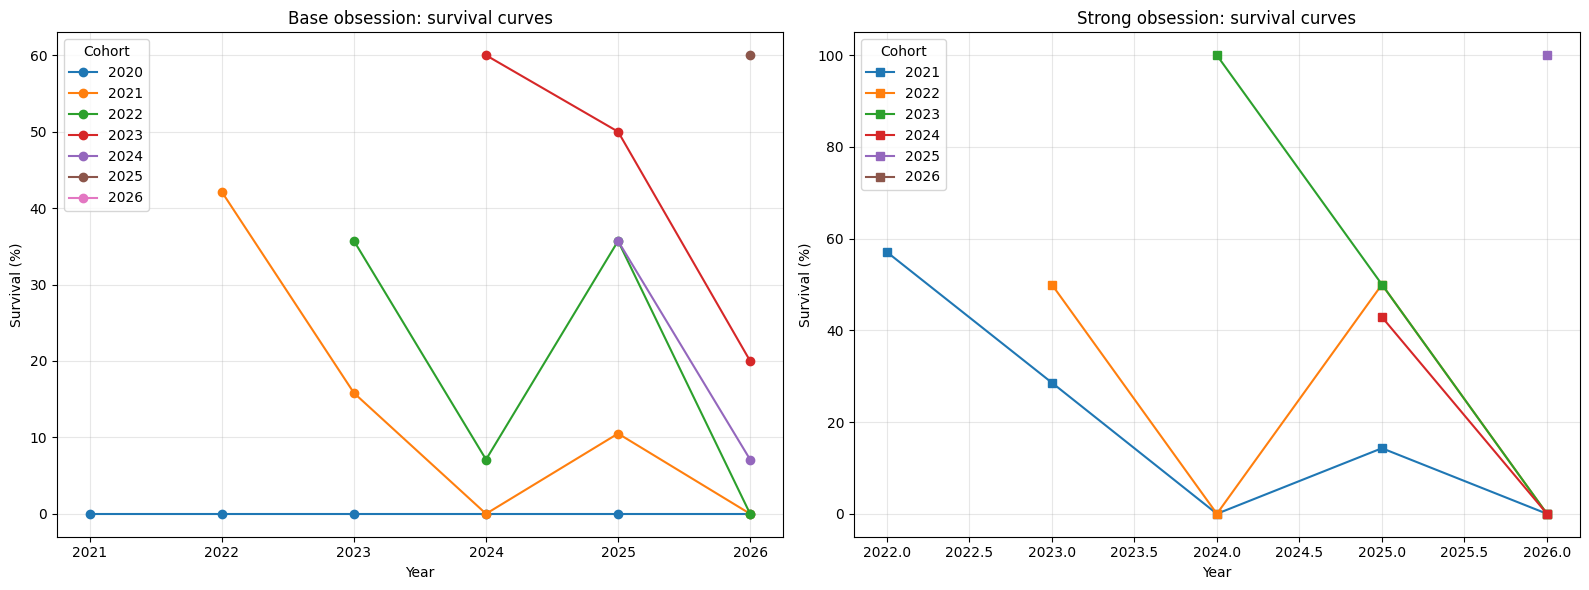

📊 Survival at 1 and 2 years:


,Cohort,"Base 1-year, %","Strong 1-year, %","Base 2-year, %","Strong 2-year, %"
№,,,,,
1,2020,0.0,NaN,0.0,NaN
2,2021,42.1,57.1,15.8,28.6
3,2022,35.7,50.0,7.1,0.0
4,2023,60.0,100.0,50.0,50.0
5,2024,35.7,42.9,7.1,0.0
6,2025,60.0,100.0,NaN,NaN
7,2026,NaN,NaN,NaN,NaN



🔍 Interpretation:
   Base obsession: mean 1-year survival — 38.9%.
   Max 1-year survival: cohort 2023 (60.0%).
   Strong obsession: mean 1-year survival — 70.0%.
   Max 1-year survival: cohort 2023 (100.0%).

⚠️ Limitations:
   - For 2025–2026 cohorts, no future data → survival is NaN.
   - Left censoring possible for 2020–2021.
   - Strong obsession sample is small (<30), percentages may be unstable.

📊 Events and unique tracks by obsession group:


,Group,Events,Unique tracks,"Share of events, %"
№,,,,
1,Non-obsession,44565,15267,97.7
2,Base obsession,279,69,0.6
3,Strong obsession,776,20,1.7



📊 Mean audio features:


,Group,valence,energy,danceability,acousticness,instrumentalness,tempo,loudness,popularity
№,,,,,,,,,
1,Non-obsession,0.276,0.492,0.572,0.368,0.488,118.908,-11.874,32.662
2,Base obsession,0.305,0.495,0.594,0.347,0.210,118.290,-10.118,25.229
3,Strong obsession,0.276,0.436,0.504,0.465,0.222,119.493,-11.281,39.270



📊 Median audio features:


,Group,valence,energy,danceability,acousticness,instrumentalness,tempo,loudness,popularity
№,,,,,,,,,
1,Non-obsession,0.226,0.498,0.606,0.271,0.587,119.963,-10.467,34.0
2,Base obsession,0.277,0.475,0.614,0.282,0.009,114.983,-9.549,21.0
3,Strong obsession,0.237,0.450,0.526,0.255,0.002,120.027,-12.280,25.0


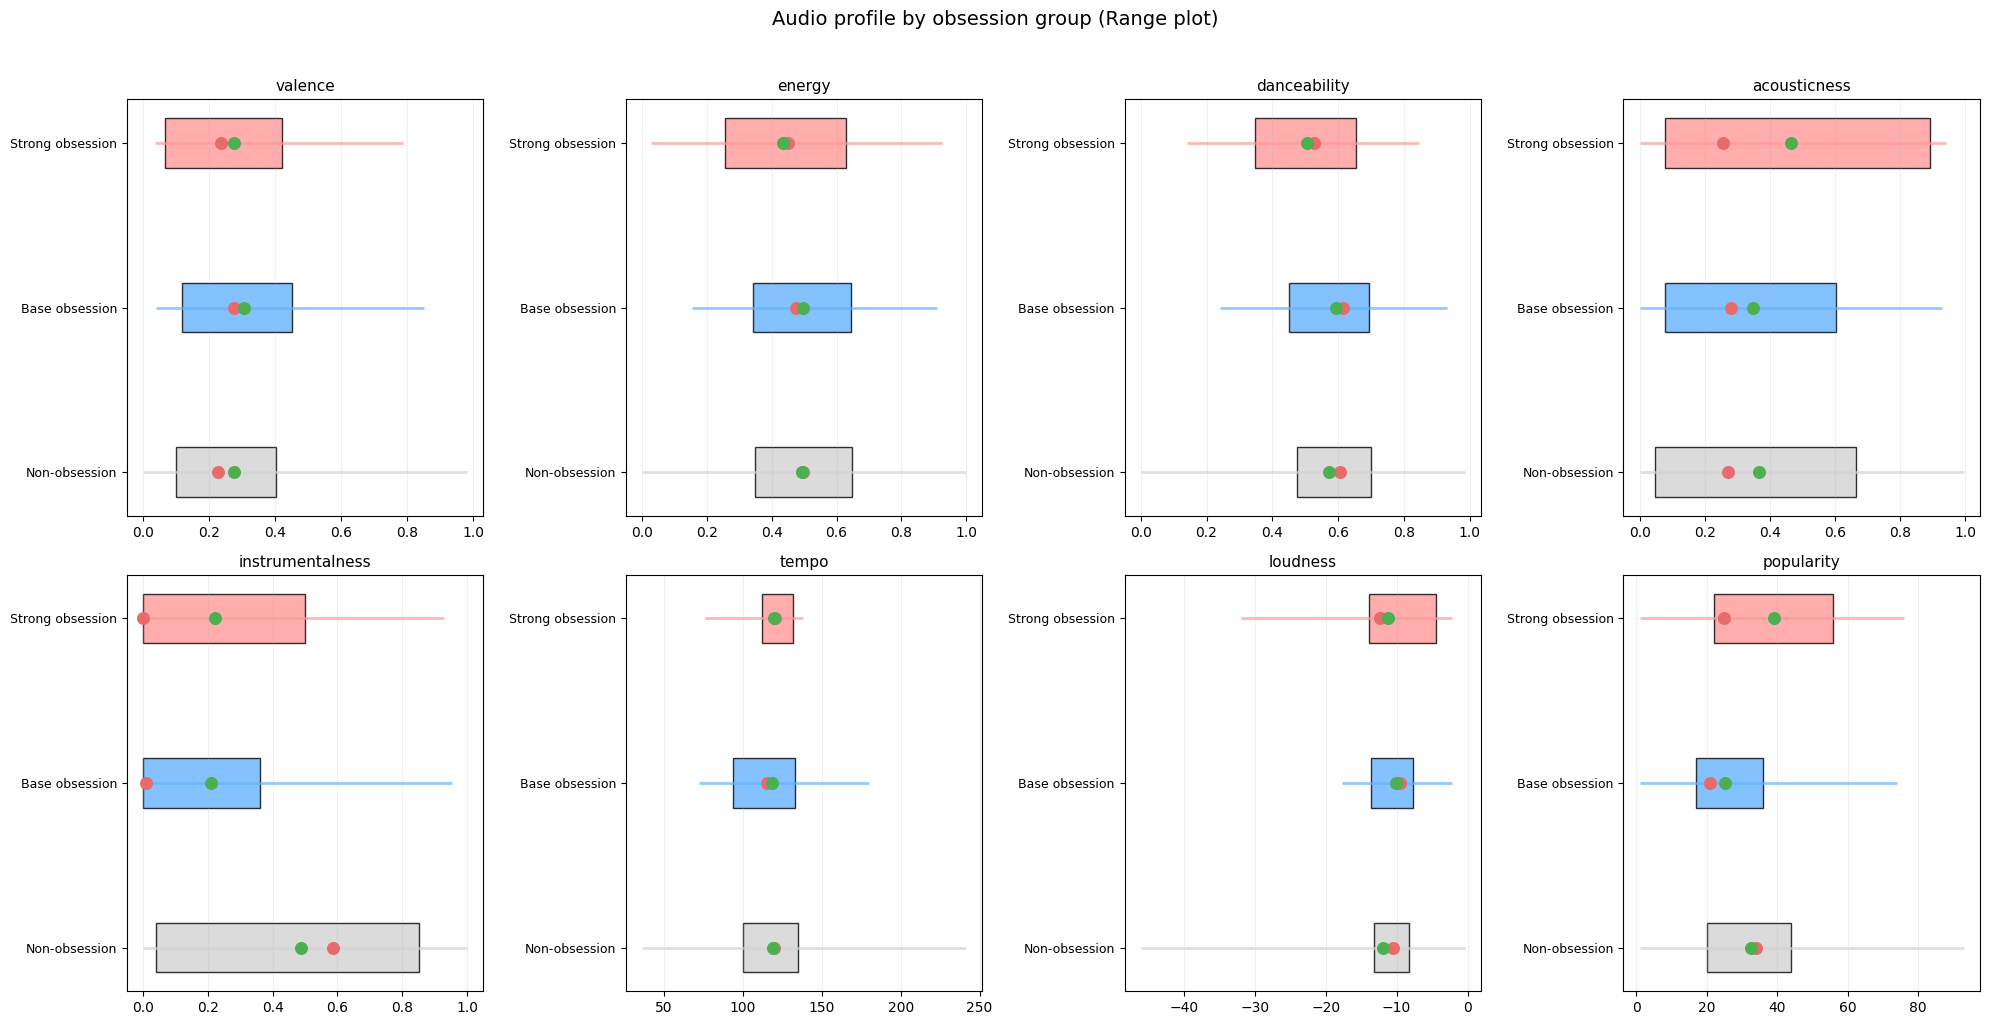


📊 Unknown genre shares by group:
⚠️ Non-obsession: 45.1% tracks without genre — genre conclusions limited.
🚨 Base obsession: 60.9% tracks without genre — genre conclusions unreliable.
ℹ️ Strong obsession: 26.0% tracks without genre.

🔍 Interpretation:
   Non-obsession: 44,565 events, 15,267 unique tracks.
   Base obsession: 279 events, 69 unique tracks.
   Strong obsession: 776 events, 20 unique tracks.

⚠️ Strong obsession has fewer than 30 unique tracks — mean comparison may be unstable.
   Main conclusions are based on visual Range plot and descriptive numbers.


In [61]:
# 2.15 Обсессии: выживаемость и сводка

# Две части:
#   1. Выживаемость когорт: как долго треки, впервые попавшие в обсессию
#      в определённом году, остаются в глубоком прослушивании.
#   2. Сводка по группам: не-обсессия vs базовая vs сильная — события,
#      уникальные треки, аудио-профиль.
#
# Обсессии session-scoped: флаги is_base_obsession / is_strong_obsession
# стоят на событиях сессий, где реально было зацикливание.

deep = df_deep.copy()
deep['year'] = deep['ts'].dt.year


# ==========================================
# ЧАСТЬ 1: Выживаемость когорт
# ==========================================
def build_survival_matrix(is_col):
    """
    Матрица выживаемости: для каждой когорты (год первого появления
    в обсессии) — доля треков, которые прослушивались в последующие годы.
    """
    obs_tracks = deep[deep[is_col]].copy()
    first_year = obs_tracks.groupby('spotify_track_uri')['year'].min().reset_index()
    first_year.columns = ['spotify_track_uri', 'first_obs_year']

    all_years = deep.groupby('spotify_track_uri')['year'].apply(lambda x: set(x)).reset_index()
    all_years.columns = ['spotify_track_uri', 'years_listened']

    survival_df = first_year.merge(all_years, on='spotify_track_uri', how='left')

    years_range = sorted(deep['year'].unique())
    cohort_years = sorted(survival_df['first_obs_year'].unique())

    matrix = pd.DataFrame(index=cohort_years, columns=years_range, dtype=float)

    for cohort in cohort_years:
        cohort_tracks = survival_df[survival_df['first_obs_year'] == cohort]
        total = len(cohort_tracks)
        for later_year in years_range:
            if later_year <= cohort:
                matrix.loc[cohort, later_year] = np.nan
            else:
                survived = cohort_tracks['years_listened'].apply(lambda x: later_year in x).sum()
                matrix.loc[cohort, later_year] = round(survived / total * 100, 1)

    return matrix


base_matrix = build_survival_matrix('is_base_obsession')
strong_matrix = build_survival_matrix('is_strong_obsession')


def survival_1_2_years(matrix):
    """Выживаемость через 1 и 2 года после первого появления."""
    one_year = matrix.apply(
        lambda row: row[row.index > row.name].iloc[0] if (row.index > row.name).any() else np.nan,
        axis=1
    )
    two_year = matrix.apply(
        lambda row: row[row.index > row.name].iloc[1] if (row.index > row.name).sum() >= 2 else np.nan,
        axis=1
    )
    return one_year, two_year


base_1y, base_2y = survival_1_2_years(base_matrix)
strong_1y, strong_2y = survival_1_2_years(strong_matrix)

# --- Кривые выживаемости ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for cohort in base_matrix.index:
    axes[0].plot(base_matrix.columns, base_matrix.loc[cohort],
                 marker='o', label=str(int(cohort)))
axes[0].set_title('Base obsession: survival curves')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Survival (%)')
axes[0].legend(title='Cohort')
axes[0].grid(True, alpha=0.3)

for cohort in strong_matrix.index:
    axes[1].plot(strong_matrix.columns, strong_matrix.loc[cohort],
                 marker='s', label=str(int(cohort)))
axes[1].set_title('Strong obsession: survival curves')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Survival (%)')
axes[1].legend(title='Cohort')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Сводная таблица 1 и 2 года ---
summary_1y = pd.DataFrame({
    'Cohort': base_1y.index,
    'Base 1-year, %': base_1y.values,
    'Strong 1-year, %': strong_1y.reindex(base_1y.index).values
}).set_index('Cohort')

summary_2y = pd.DataFrame({
    'Cohort': base_2y.index,
    'Base 2-year, %': base_2y.values,
    'Strong 2-year, %': strong_2y.reindex(base_2y.index).values
}).set_index('Cohort')

summary_survival = summary_1y.join(summary_2y, how='outer').sort_index().reset_index()
summary_survival.index = range(1, len(summary_survival) + 1)
summary_survival.index.name = '№'
print('📊 Survival at 1 and 2 years:')
display(summary_survival.round(1))

print('\n🔍 Interpretation:')
if base_1y.notna().any():
    print(f'   Base obsession: mean 1-year survival — {base_1y.mean():.1f}%.')
    print(f'   Max 1-year survival: cohort {int(base_1y.idxmax())} ({base_1y.max():.1f}%).')
if strong_1y.notna().any():
    print(f'   Strong obsession: mean 1-year survival — {strong_1y.mean():.1f}%.')
    print(f'   Max 1-year survival: cohort {int(strong_1y.idxmax())} ({strong_1y.max():.1f}%).')

print('\n⚠️ Limitations:')
print('   - For 2025–2026 cohorts, no future data → survival is NaN.')
print('   - Left censoring possible for 2020–2021.')
print('   - Strong obsession sample is small (<30), percentages may be unstable.')


# ==========================================
# ЧАСТЬ 2: Сводка по группам
# ==========================================
# Три взаимоисключающие группы:
#   Non-obsession — все deep-события, не попавшие ни в один уровень.
#   Base obsession — события базовой обсессии, но не сильной.
#   Strong obsession — события сильной обсессии.

def get_obs_group(row):
    if row['is_strong_obsession']:
        return 'Strong obsession'
    elif row['is_base_obsession']:
        return 'Base obsession'
    else:
        return 'Non-obsession'


deep['obs_group'] = deep.apply(get_obs_group, axis=1)
group_order = ['Non-obsession', 'Base obsession', 'Strong obsession']

# --- Количество событий и уникальных треков ---
group_stats = deep.groupby('obs_group').agg(
    events=('ts', 'count'),
    unique_tracks=('spotify_track_uri', 'nunique')
).reindex(group_order).reset_index()

group_stats_display = group_stats.copy()
group_stats_display.columns = ['Group', 'Events', 'Unique tracks']
group_stats_display['Share of events, %'] = (
    group_stats_display['Events'] / len(deep) * 100
).round(1)
group_stats_display.index = range(1, len(group_stats_display) + 1)
group_stats_display.index.name = '№'
print('\n📊 Events and unique tracks by obsession group:')
display(group_stats_display)

# --- Аудио-характеристики ---
features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'tempo', 'loudness', 'popularity']

mean_features = deep.groupby('obs_group')[features].mean().reindex(group_order)
median_features = deep.groupby('obs_group')[features].median().reindex(group_order)

print('\n📊 Mean audio features:')
mean_display = mean_features.round(3).reset_index()
mean_display.columns = ['Group'] + features
mean_display.index = range(1, len(mean_display) + 1)
mean_display.index.name = '№'
display(mean_display)

print('\n📊 Median audio features:')
median_display = median_features.round(3).reset_index()
median_display.columns = ['Group'] + features
median_display.index = range(1, len(median_display) + 1)
median_display.index.name = '№'
display(median_display)

# --- Range plot 2×4 ---
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

group_colors = {
    'Non-obsession': COLORS['muted'],
    'Base obsession': COLORS['base_obs'],
    'Strong obsession': COLORS['strong_obs'],
}

for i, feat in enumerate(features):
    ax = axes[i]
    y_positions = [0, 1, 2]
    min_overall = deep.groupby('obs_group')[feat].min().min()
    max_overall = deep.groupby('obs_group')[feat].max().max()
    ax.set_xlim(min_overall - 0.05 * (max_overall - min_overall),
                max_overall + 0.05 * (max_overall - min_overall))

    for j, group in enumerate(group_order):
        vals = deep[deep['obs_group'] == group][feat].dropna()
        q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
        med = vals.median()
        mean = vals.mean()
        ax.hlines(y=y_positions[j], xmin=vals.min(), xmax=vals.max(),
                  color=group_colors[group], linewidth=2, alpha=0.7)
        ax.barh(y=y_positions[j], width=q3 - q1, left=q1, height=0.3,
                color=group_colors[group], edgecolor='black', alpha=0.8)
        ax.scatter(med, y_positions[j], color=COLORS['line_accent'], s=70, zorder=5)
        ax.scatter(mean, y_positions[j], color=COLORS['line_success'], s=70, zorder=5)

    ax.set_yticks(y_positions)
    ax.set_yticklabels(group_order, fontsize=9)
    ax.set_title(feat, fontsize=11)
    ax.grid(axis='x', alpha=0.2)

plt.suptitle('Audio profile by obsession group (Range plot)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# --- Доля unknown по группам ---
print('\n📊 Unknown genre shares by group:')
for group in group_order:
    grp = deep[deep['obs_group'] == group]
    show_unknown_share(grp, group)

# --- Автоинтерпретация ---
print('\n🔍 Interpretation:')

non_obs_events = group_stats.loc[group_stats['obs_group'] == 'Non-obsession', 'events'].iloc[0]
base_events = group_stats.loc[group_stats['obs_group'] == 'Base obsession', 'events'].iloc[0]
strong_events = group_stats.loc[group_stats['obs_group'] == 'Strong obsession', 'events'].iloc[0]

non_obs_tracks = group_stats.loc[group_stats['obs_group'] == 'Non-obsession', 'unique_tracks'].iloc[0]
base_tracks_count = group_stats.loc[group_stats['obs_group'] == 'Base obsession', 'unique_tracks'].iloc[0]
strong_tracks_count = group_stats.loc[group_stats['obs_group'] == 'Strong obsession', 'unique_tracks'].iloc[0]

print(f'   Non-obsession: {non_obs_events:,} events, {non_obs_tracks:,} unique tracks.')
print(f'   Base obsession: {base_events:,} events, {base_tracks_count:,} unique tracks.')
print(f'   Strong obsession: {strong_events:,} events, {strong_tracks_count:,} unique tracks.')

if strong_tracks_count >= 30:
    print('\n   Mean comparison (Strong vs Base):')
    for feat in features:
        diff = mean_features.loc['Strong obsession', feat] - mean_features.loc['Base obsession', feat]
        if abs(diff) >= 0.02 or feat in ['tempo', 'loudness', 'popularity']:
            direction = 'higher' if diff > 0 else 'lower'
            print(f'   {feat}: {direction} by {abs(diff):.3f}')
else:
    print('\n⚠️ Strong obsession has fewer than 30 unique tracks — mean comparison may be unstable.')
    print('   Main conclusions are based on visual Range plot and descriptive numbers.')

### 2.15. Вывод

**Что проверяли.** Как долго треки из обсессии остаются в **deep** по годам первого появления. Чем три группы — **Non-obsession**, **base obsession**, **strong obsession** — отличаются по звуку.

**Результат.**

Выживаемость. **Strong obsession** — 70.0% через год, **base** — 38.9%. Когорта 2023 — максимум в обоих уровнях: 60% и 50% через год и два года у **base**, 100% и 50% у **strong**. Когорта 2021 — массовая (7.7% доли по 2.12), но через два года 16% у **base** и 29% у **strong**. Когорта 2022 показывает возвраты: 36% → 7% → 36% у **base**, 50% → 0% → 50% у **strong**.

Аудио-профиль. **Base obsession** отличается от **Non-obsession** низкой instrumentalness (0.210 против 0.488), низкой popularity (25.2 против 32.7) и высокой громкостью (−10.1 против −11.9 дБ). **Strong obsession** — тише, менее энергична, акустичнее, популярнее.

**Вывод.** Обсессии не угасают монотонно. Когорта 2022 показывает возвраты после паузы в год: трек уходит из **deep**, потом возвращается. В годовых агрегатах 2.12 этого не видно — только в матрице выживаемости по когортам.

Связь с 2.12 обратная. В 2021 доля обсессий максимальна, но выживаемость низкая — массовое увлечение быстро заканчивается. В 2023 доля минимальна (0.9%), но выживаемость максимальна — редкие обсессии держатся дольше.

**Strong obsession** живёт почти вдвое дольше **base** и по звуку идёт в другую сторону: тише, менее энергична, акустичнее, популярнее. **Base obsession** — громкая вокальная музыка низкой популярности.

Ограничение: **strong obsession** — 20 уникальных треков, средние по группе неустойчивы. Когорты 2025–2026 обрезаны справа. Когорта 2020 — 3 трека в **base**, читать нельзя. Логика выживания: трек считается выжившим, если хотя бы раз появился в **deep** за год. Это не то же самое, что «остался обсессией».

## Блок 2. Вывод

**Сессии.** Медиана **session** — 38.6 минуты календарной длительности, 12 событий. **continuous** — 66.6% (1 754), **interrupted** — 33.4% (879). Медиана длительности: 12.8 минуты против 92.3. Медиана событий: 6 против 28.

**Навигация.** **interrupted** активнее: медианный **skip_share** 0.190 против 0.035 у **continuous**. Shuffle не различается (p=3.437e-01). Нулевые события не объясняют паузы в **session**: Pearson r=0.018 при p=0.361.

**Сохранение.** Медианная доля **saved_after** — 0.108 у **interrupted** против 0.000 у **continuous**. По **never_saved** и **saved_before** группы не различаются (p=5.234e-01 и p=6.834e-01). Разрыв по **saved_after** значим (p=6.263e-42). В типичной **continuous** сессии будущих сохранений нет, в типичной **interrupted** — 10.8% событий.

**Скипы.** Мгновенные скипы — 25.6% событий, полные прослушивания — 57.1%. **not mine** — 57.5% скипов, **context skip** — 42.5%. **not mine** — более энергичная и громкая музыка (0.555 против 0.500 по energy), **context skip** по звуку ближе к фону.

**Динамика скипов.** **not mine** держится в диапазоне 5–15% до конца 2024, затем два пика: декабрь 2024 (22.7%) и июль 2025 (32.1%). После июля 2025 падает до 0.4% среднее дневных долей (16 из 3 360 событий в декабре 2025). В 2025 году **not mine** падает, **context skip** растёт. Поздние скипы новых треков — 2.4% потока, 81.8% на чужой музыке.

**Перемотки и возвраты.** **fwdbtn** — в 81.4% случаев проверка нового. **backbtn** — в 80.4% случаев навигационный шум, 19.6% успешных возвратов.

**Причины окончания.** **trackdone** — 57.8%, **fwdbtn** — 17.0%, **endplay** — 16.2%. Медиана длительности: **trackdone** 226 секунд, **fwdbtn** 6, **endplay** 8. То есть **fwdbtn** и **endplay** — короткие события. Между **continuous** и **interrupted** различия по причинам — 0.4–2.9 п.п.

**Обсессии.** **base obsession** — 1 049 событий в 83 уникальных треках. **strong obsession** — 776 событий в 20 треках, все 20 входят в базовые. Вместе — 2.3% **deep**-событий. Средняя интенсивность — 12.6 событий на трек у **base**, 38.8 у **strong**.

По годам доля **base obsession** в **deep**-событиях: пик 2021 (7.7%), вторая волна 2024 (3.8%), спад 2025–2026 (0.4–0.8%). Пик — февраль 2021: `Om Mata Kali` даёт 42.9% **deep**-событий месяца. Сезонность: февраль 8.0% **base**, лето 0.4–1.5%.

Выживаемость через год: **base** 38.9%, **strong** 70.0% (средние по когортам 2020–2025). Когорта 2023 — 60% и 50% через год и два года у **base**, 100% и 50% у **strong**.

Блок 3 идёт от этой точки. Сохранение связано с **interrupted**: в типичной прерывистой сессии доля **saved_after** 10.8%, в типичной непрерывной — 0. Обсессии сосредоточены в 83 треках (**base**) и 20 (**strong**), доля в **deep**-событиях колеблется по годам.

Ограничение: пороги обсессий и мгновенных скипов — эвристики. **strong obsession** — 20 треков, средние неустойчивы. Правый край обрезан на августе 2026.

# Блок 3. Эволюция и потери

## Блок 3. Эволюция и потери

Блок показывает, как пользователь ищет новое и теряет старое. **Discovery Rate** — как часто встречается незнакомое. **Retention** — закрепляется ли найденное. **Burnout** — как быстро уходят треки, которые когда-то были ядром.

Срез — **df** с фильтром **valid_play**, **df_deep**, **track_dates**. Единица анализа — трек для **Retention** и **Burnout**, событие для **Discovery Rate**.

**Discovery Rate** — доля **valid_play** событий, приходящихся на треки, которые пользователь слышит впервые в истории. Считается по кварталам. Первые 12 месяцев исключаются: в начале истории почти все треки новые, метрика искусственно завышена.

**Novelty** — конкретное первое **valid_play** событие трека. Не все события в квартале его появления, а именно первое. Отличается от **Discovery Rate** тем, что отвечает на вопрос «какая доля контактов — первые», а не «в каком квартале было много новых треков».

**Retention 90d** — доля треков, которые вернулись хотя бы раз в течение 90 дней после первого **valid_play**. Дополнительно считаются окна 30 и 180 дней.

**Returned** — новинка, вернувшаяся в окне. **Not returned** — новинка, не вернувшаяся.

**Emotion group** — квадрант по модели Рассела: **valence** × **energy**. Порог по каждой оси 0.5. Четыре группы: **High V / High E**, **High V / Low E**, **Low V / High E**, **Low V / Low E**.

**Core track** — трек с хотя бы одной меткой: **base obsession**, **strong obsession**, **loyal**.

**Active** — core-трек, последнее появление в **deep** не позже 6 месяцев назад. **Fading** — 6–12 месяцев. **Burned** — больше 12 месяцев.

1. **Discovery Rate**: расчёт по кварталам, классификация кварталов по уровню (пороги 75% и 50%), сравнение High и Low по звуку и составу.
2. Новизна: доля первых прослушиваний по годам и кварталам, выживаемость новинок через 30 / 90 / 180 дней.
3. Аудио-профиль **Returned** против **Not returned** в 90-дневном окне.
4. **Retention** по **emotion group**.
5. **Core track burnout**: классификация **Active** / **Fading** / **Burned**.
6. Аудио-профиль и поведение по статусам выгорания. Временная динамика: год пика, время от пика до исчезновения.

## 3.1 Поисковые периоды и профиль слушателя


📊 Discovery Rate (valid events):
   Window: Q
   Periods after filter: 22
   Mean: 60.6%
   Median: 65.3%
   Std: 13.5%
   Profile: Explorer (high search)

📊 Period classification:
   High (≥ 75%): 3
   Medium (50–75%): 12
   Low (< 50%): 7

📊 Search periods:


,Period,"Discovery Rate, %",Group
№,,,
1,2021Q2,70.300000,Medium
2,2021Q3,69.400000,Medium
3,2021Q4,68.900000,Medium
4,2022Q1,52.300000,Medium
5,2022Q2,76.200000,High
6,2022Q3,61.300000,Medium
7,2022Q4,68.400000,Medium
8,2023Q1,49.900000,Low
9,2023Q2,65.900000,Medium


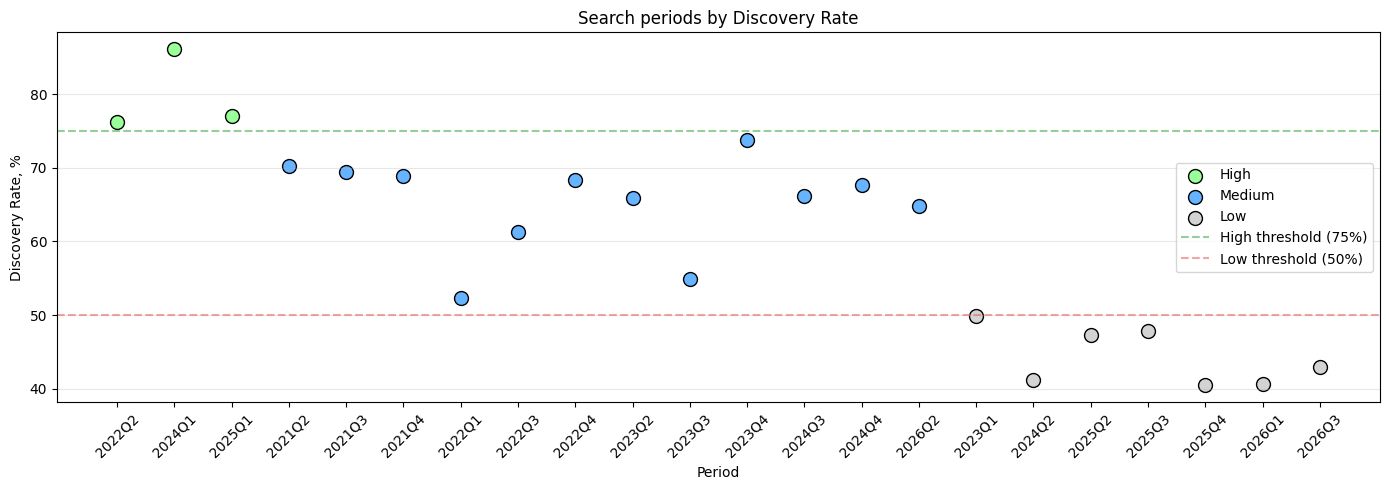


Group sizes: High = 8,864 events, Low = 16,530 events

📊 Mean values:


,Metric,High mean,Low mean
№,,,
1,valence,0.249,0.271
2,energy,0.418,0.519
3,danceability,0.512,0.588
4,acousticness,0.472,0.309
5,instrumentalness,0.510,0.496
6,saved_after,0.037,0.029
7,my_music,0.492,0.646
8,is_orphan,0.433,0.297



📊 Median values:


,Metric,High median,Low median
№,,,
1,valence,0.180,0.223
2,energy,0.438,0.513
3,danceability,0.578,0.610
4,acousticness,0.412,0.201
5,instrumentalness,0.625,0.601
6,saved_after,0.000,0.000
7,my_music,0.000,1.000
8,is_orphan,0.000,0.000



📊 Significance check (Mann-Whitney + practical threshold):
   valence: lower by 0.022 (p=4.517e-45)
   energy: lower by 0.101 (p=7.176e-181)
   danceability: lower by 0.075 (p=3.969e-97)
   acousticness: higher by 0.163 (p=3.900e-258)
   instrumentalness: significant, but small effect (0.014 < 0.02)
   saved_after: significant, but small effect (0.008 < 0.02)
   my_music: lower by 0.154 (p=5.140e-125)
   is_orphan: higher by 0.136 (p=2.124e-105)


In [62]:
# 3.1 Поисковые периоды и профиль слушателя

# Discovery Rate — доля валидных событий, приходящихся на треки,
# которые пользователь слышит впервые в истории.
#
# Пороги классификации профиля — распространённые в сторонних источниках,
# не официальная классификация Spotify.
#   <30%  — традиционный слушатель (Loyalist)
#   30–50% — умеренный поиск (Mixed)
#   >=50% — выраженный поиск (Explorer)
#
# Первые 12 месяцев исключаются — в начале истории почти все треки
# новые, метрика искусственно завышена.
#
# Discovery Rate считается по кварталам: устойчивее к недельным колебаниям,
# лучше отражает волны поиска.

# Параметры
TIME_WINDOW = 'Q'                 # Q = квартал
START_EXCLUDE_MONTHS = 12         # сколько первых месяцев исключить
EXPLORER_THRESHOLD = 50
LOYALIST_THRESHOLD = 30
HIGH_THRESHOLD = 75
LOW_THRESHOLD = 50

# --- Данные: только валидные события ---
data = df[df['valid_play']].copy()
data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
data['period'] = data['ts'].dt.to_period(TIME_WINDOW)

# Период первого валидного появления трека
data['first_period'] = data['first_valid_seen'].dt.to_period(TIME_WINDOW)

# Новое событие — если период события совпадает с периодом первого появления
data['is_new_event'] = data['period'] == data['first_period']

# Discovery Rate по периодам
period_total = data.groupby('period')['is_new_event'].count()
period_new = data.groupby('period')['is_new_event'].sum()
discovery_rate = (period_new / period_total * 100).sort_index()

# Исключаем стартовый период
first_period = data['ts'].min().to_period(TIME_WINDOW)
exclude_periods = START_EXCLUDE_MONTHS // 3
start_period = first_period + exclude_periods
discovery_rate_filtered = discovery_rate[discovery_rate.index >= start_period]

if len(discovery_rate_filtered) < 4:
    print(f"⚠️ Only {len(discovery_rate_filtered)} quarters after cold-start exclusion. "
          f"Reduce START_EXCLUDE_MONTHS or set to 0.")

# --- Статистика ---
mean_rate = discovery_rate_filtered.mean()
median_rate = discovery_rate_filtered.median()
std_rate = discovery_rate_filtered.std()

print('📊 Discovery Rate (valid events):')
print(f'   Window: {TIME_WINDOW}')
print(f'   Periods after filter: {len(discovery_rate_filtered)}')
print(f'   Mean: {mean_rate:.1f}%')
print(f'   Median: {median_rate:.1f}%')
print(f'   Std: {std_rate:.1f}%')

# --- Профиль поиска ---
if median_rate >= EXPLORER_THRESHOLD:
    profile = 'Explorer (high search)'
elif median_rate >= LOYALIST_THRESHOLD:
    profile = 'Mixed (moderate search)'
else:
    profile = 'Loyalist (traditional listener)'

print(f'   Profile: {profile}')

# --- Классификация периодов ---
def classify_period(rate):
    if rate >= HIGH_THRESHOLD:
        return 'High'
    elif rate >= LOW_THRESHOLD:
        return 'Medium'
    else:
        return 'Low'

period_group = discovery_rate_filtered.apply(classify_period)

print(f'\n📊 Period classification:')
print(f'   High (≥ {HIGH_THRESHOLD}%): {(period_group == "High").sum()}')
print(f'   Medium ({LOW_THRESHOLD}–{HIGH_THRESHOLD}%): {(period_group == "Medium").sum()}')
print(f'   Low (< {LOW_THRESHOLD}%): {(period_group == "Low").sum()}')

# --- Таблица ---
period_table = pd.DataFrame({
    'Period': discovery_rate_filtered.index.astype(str),
    'Discovery Rate, %': discovery_rate_filtered.values.round(1),
    'Group': period_group.values
})
period_table.index = range(1, len(period_table) + 1)
period_table.index.name = '№'

print('\n📊 Search periods:')
show_table(period_table)

# --- График ---
group_colors = {'High': COLORS['success'], 'Medium': COLORS['primary'], 'Low': COLORS['muted']}

plt.figure(figsize=(14, 5))
for group, color in group_colors.items():
    mask = period_group == group
    plt.scatter(
        discovery_rate_filtered.index.astype(str)[mask],
        discovery_rate_filtered.values[mask],
        color=color, s=100, label=group, edgecolor='black'
    )

plt.axhline(HIGH_THRESHOLD, color=COLORS['line_success'], linestyle='--', alpha=0.6,
            label=f'High threshold ({HIGH_THRESHOLD}%)')
plt.axhline(LOW_THRESHOLD, color=COLORS['line_accent'], linestyle='--', alpha=0.6,
            label=f'Low threshold ({LOW_THRESHOLD}%)')
plt.xticks(rotation=45)
plt.xlabel('Period')
plt.ylabel('Discovery Rate, %')
plt.title('Search periods by Discovery Rate')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# Сравнение High и Low периодов
# ==========================================
# Загружаем даты сохранения
track_dates = pd.read_parquet(BASE_PATH / 'track_dates.parquet')
track_dates['library_added_at'] = pd.to_datetime(track_dates['library_added_at'], errors='coerce').dt.tz_localize(None)
track_dates['first_playlist_added_at'] = pd.to_datetime(track_dates['first_playlist_added_at'], errors='coerce').dt.tz_localize(None)
track_dates['first_save_date'] = track_dates[['library_added_at', 'first_playlist_added_at']].min(axis=1)

data = data.merge(track_dates[['spotify_track_uri', 'first_save_date']], on='spotify_track_uri', how='left')

# saved_after — сохранение после конца квартала
data['period_end'] = data['period'].dt.end_time
data['saved_after'] = (data['first_save_date'] > data['period_end']).fillna(False)

# Группы High и Low
high_periods = period_group[period_group == 'High'].index
low_periods = period_group[period_group == 'Low'].index

high_data = data[data['period'].isin(high_periods)]
low_data = data[data['period'].isin(low_periods)]

print(f'\nGroup sizes: High = {len(high_data):,} events, Low = {len(low_data):,} events')

# --- Средние и медианы по аудио и флагам ---
audio_features = ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']
flag_features = ['saved_after', 'my_music', 'is_orphan']
all_features = audio_features + flag_features

comp_mean = pd.DataFrame({
    'High mean': high_data[all_features].mean().round(3),
    'Low mean': low_data[all_features].mean().round(3)
}).reset_index().rename(columns={'index': 'Metric'})
comp_mean.index = range(1, len(comp_mean) + 1)
comp_mean.index.name = '№'
print('\n📊 Mean values:')
display(comp_mean)

comp_median = pd.DataFrame({
    'High median': high_data[all_features].median().round(3),
    'Low median': low_data[all_features].median().round(3)
}).reset_index().rename(columns={'index': 'Metric'})
comp_median.index = range(1, len(comp_median) + 1)
comp_median.index.name = '№'
print('\n📊 Median values:')
display(comp_median)

print('\n📊 Significance check (Mann-Whitney + practical threshold):')
for feat in all_features:
    a = high_data[feat].dropna()
    b = low_data[feat].dropna()
    if len(a) == 0 or len(b) == 0:
        continue

    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    diff = a.mean() - b.mean()
    threshold = PRACTICAL_THRESHOLDS.get(feat, 0.02)

    stat_sig = p < 0.05
    pract_sig = abs(diff) >= threshold

    if stat_sig and pract_sig:
        direction = 'higher' if diff > 0 else 'lower'
        print(f'   {feat}: {direction} by {abs(diff):.3f} (p={p:.3e})')
    elif stat_sig and not pract_sig:
        print(f'   {feat}: significant, but small effect ({abs(diff):.3f} < {threshold})')
    else:
        print(f'   {feat}: not significant (p={p:.3e})')

### 3.1. Вывод

**Что проверяли.** Как часто пользователь ищет новое. Чем периоды
высокой новизны отличаются по звуку и составу от периодов
эксплуатации знакомого.

**Результат.** Медианный квартальный **Discovery Rate** — 65.3%,
среднее — 60.6%, стандартное отклонение — 13.5%. Профиль —
выраженный поиск по порогам, распространённым в сторонних
источниках. High-кварталов (≥75%) три: 2022Q2, 2024Q1, 2025Q1.
Low-кварталов (<50%) семь: 2023Q1, 2024Q2, 2025Q2, 2025Q3,
2025Q4, 2026Q1, 2026Q3. Четыре из семи приходятся на 2025Q2–2026Q1,
пятый (2026Q3) — неполный квартал правого края.

Четыре характеристики из пяти согласованы по средним и медианам.
В High музыка спокойнее (energy: медиана 0.438 против 0.513),
менее танцевальная (danceability: 0.578 против 0.610), более
акустичная (acousticness: 0.412 против 0.201) и более меланхоличная
(valence: 0.180 против 0.223). Все различия выше практических
порогов. Instrumentalness — ниже порога (0.510 против 0.496).

По разрыву в своей музыке — резкое расхождение медиан:
**my_music** 0.000 в High против 1.000 в Low. В типичном
High-событии трек не из своей коллекции, в типичном Low — из своей.

**Вывод.** Поиск нового — отдельное поведенческое состояние
с устойчивым звуковым профилем. В периоды высокой новизны
пользователь слушает более спокойную, акустичную и меланхоличную
музыку, почти не опираясь на свою коллекцию. Сохранение после
квартала растёт незначительно (0.037 против 0.029) — High-кварталы
не приводят к массовому отложенному сохранению.

**Ограничение.** **Discovery Rate** даёт одну медиану на весь
семилетний период — 65.3%. Профиль **Explorer** тоже один
на весь период. Динамика внутри семи лет не разбирается:
сравниваются High-кварталы из разных лет (2022Q2, 2024Q1, 2025Q1)
с Low-кварталами из разных лет (2023Q1, 2024Q2, 2025Q2–Q4,
2026Q1, 2026Q3). Разница по звуку может отражать и режим внутри
года, и различия между годами — разделить эти эффекты в этой
ячейке нельзя. **saved_after** считается по дате сохранения после
конца квартала, часть сохранений внутри квартала не учитывается.

## 3.2 Новые открытия: новизна и выживаемость


📊 Share of new valid events by year:


,Year,Total events,New events,"New share, %",New tracks
№,,,,,
1,2020,626,481,76.800000,481
2,2021,6289,2580,41.000000,2719
3,2022,6276,2094,33.400000,2453
4,2023,7122,2598,36.500000,3114
5,2024,5649,1619,28.700000,2103
6,2025,13147,3980,30.300000,5015
7,2026,6732,2037,30.300000,3145


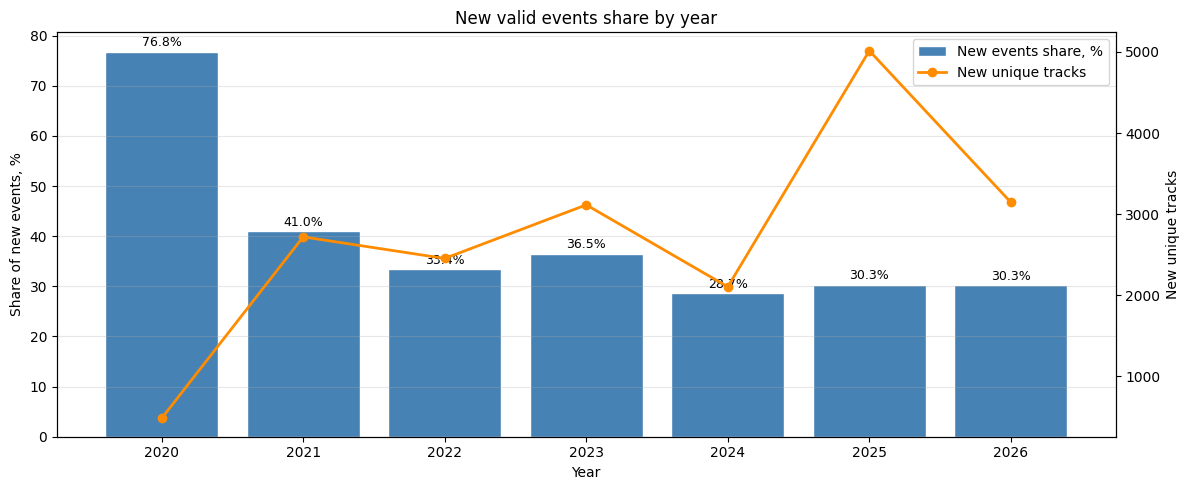


📊 Share of new valid events by quarter:


,Quarter,Total events,New events,"New share, %",New tracks
№,,,,,
1,2020Q2,8,6,75.000000,6
2,2020Q4,618,475,76.900000,476
3,2021Q1,1925,807,41.900000,898
4,2021Q2,1212,469,38.700000,598
5,2021Q3,1819,725,39.900000,895
6,2021Q4,1333,579,43.400000,864
7,2022Q1,1257,280,22.300000,491
8,2022Q2,2661,928,34.900000,1162
9,2022Q3,1448,464,32.000000,613



📊 Novelty survival (share of tracks that returned within window):
   Windows: 30, 90, 180 days after first listen.
   Em-dash (—) means the window is not yet closed (right censoring).


,Cohort,"30 days, %","90 days, %","180 days, %"
№,,,,
1,2020Q2,33.300000,33.300000,50.000000
2,2020Q4,21.300000,27.800000,33.500000
3,2021Q1,27.300000,31.500000,32.500000
4,2021Q2,24.100000,26.900000,31.300000
5,2021Q3,25.000000,34.500000,36.100000
6,2021Q4,21.900000,33.200000,35.600000
7,2022Q1,43.900000,50.000000,51.800000
8,2022Q2,34.800000,40.100000,40.500000
9,2022Q3,38.800000,43.800000,48.900000


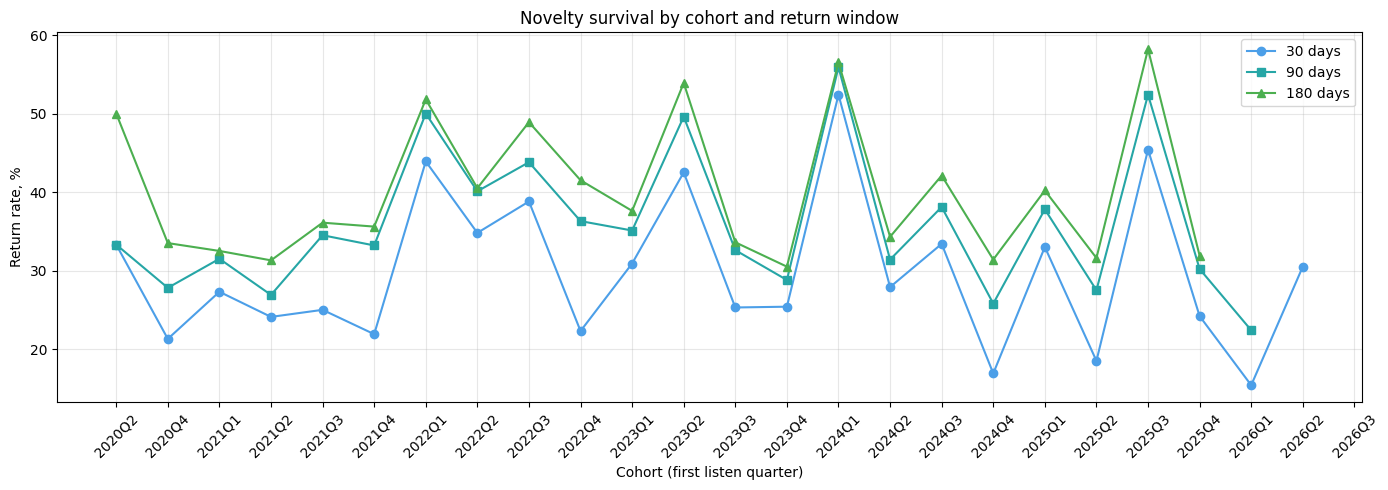

In [63]:
# 3.2 Новые открытия: новизна и выживаемость

# Две части:
#   1. Новизна: доля первых прослушиваний в общем объёме — по годам и кварталам.
#   2. Выживаемость: возвращаются ли новинки через 30/90/180 дней.
#
# Важное различие: здесь «новое событие» — это именно первое прослушивание
# трека (ts == first_valid_seen), а не все события в квартале его появления,
# как в 3.1 (Discovery Rate). Разные метрики с разным смыслом.
#
# 3.1 отвечает: «в каком квартале пользователь много искал».
# 3.2a отвечает: «какая доля конкретных контактов — это первые контакты».

# --- Данные: только валидные события ---
data = df[df['valid_play']].copy()
data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
last_date = data['ts'].max()

# Новое событие = первое валидное прослушивание трека
data['is_new_event'] = data['ts'] == data['first_valid_seen']

# ==========================================
# ЧАСТЬ 1: Новизна по годам и кварталам
# ==========================================
data['year'] = data['ts'].dt.year

yearly_new = data.groupby('year').agg(
    total_events=('ts', 'count'),
    new_events=('is_new_event', 'sum'),
    new_tracks=('spotify_track_uri', 'nunique')
).reset_index()

yearly_new['new_event_share'] = yearly_new['new_events'] / yearly_new['total_events'] * 100

print('📊 Share of new valid events by year:')
yearly_new_display = yearly_new[[
    'year', 'total_events', 'new_events', 'new_event_share', 'new_tracks'
]].copy()
yearly_new_display.columns = [
    'Year', 'Total events', 'New events', 'New share, %', 'New tracks'
]
yearly_new_display['New share, %'] = yearly_new_display['New share, %'].round(1)
yearly_new_display.index = range(1, len(yearly_new_display) + 1)
yearly_new_display.index.name = '№'
show_table(yearly_new_display)

# --- График: доля новых событий + число новых треков ---
fig, ax1 = plt.subplots(figsize=(12, 5))
bars = ax1.bar(yearly_new['year'], yearly_new['new_event_share'],
               color='steelblue', edgecolor='white', label='New events share, %')
ax1.set_xlabel('Year')
ax1.set_ylabel('Share of new events, %')
ax1.set_title('New valid events share by year')
ax1.grid(axis='y', alpha=0.3)

for bar, val in zip(bars, yearly_new['new_event_share']):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.5,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=9)

ax2 = ax1.twinx()
line, = ax2.plot(yearly_new['year'], yearly_new['new_tracks'],
                 marker='o', color='darkorange', linewidth=2,
                 label='New unique tracks')
ax2.set_ylabel('New unique tracks')
ax2.grid(False)

# Легенда из обоих графиков
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')

plt.tight_layout()
plt.show()

# --- Кварталы ---
data['quarter'] = data['ts'].dt.to_period('Q')

quarterly_new = data.groupby('quarter').agg(
    total_events=('ts', 'count'),
    new_events=('is_new_event', 'sum'),
    new_tracks=('spotify_track_uri', 'nunique')
).reset_index()
quarterly_new['new_event_share'] = quarterly_new['new_events'] / quarterly_new['total_events'] * 100

print('\n📊 Share of new valid events by quarter:')
quarterly_new_display = quarterly_new[[
    'quarter', 'total_events', 'new_events', 'new_event_share', 'new_tracks'
]].copy()
quarterly_new_display['quarter'] = quarterly_new_display['quarter'].astype(str)
quarterly_new_display.columns = [
    'Quarter', 'Total events', 'New events', 'New share, %', 'New tracks'
]
quarterly_new_display['New share, %'] = quarterly_new_display['New share, %'].round(1)
quarterly_new_display.index = range(1, len(quarterly_new_display) + 1)
quarterly_new_display.index.name = '№'
show_table(quarterly_new_display)


# ==========================================
# ЧАСТЬ 2: Выживаемость новинок
# ==========================================
# Для каждой когорты (квартал первого появления) считаем долю треков,
# которые вернулись хотя бы раз в течение 30 / 90 / 180 дней после
# первого прослушивания.
#
# Правую цензуру обрабатываем: если окно для когорты ещё не закрыто,
# ставим NaN и не считаем выживаемость.

first_events = data[data['ts'] == data['first_valid_seen']].copy()
first_events['cohort_q'] = first_events['ts'].dt.to_period('Q')

repeats = data[data['ts'] > data['first_valid_seen']].copy()


def survival_rate(cohort_df, repeats_df, days):
    """
    Доля треков когорты, которые вернулись в течение N дней.
    Возвращает Series с индексом cohort_q.
    """
    result = {}
    for cohort, grp in cohort_df.groupby('cohort_q'):
        total = grp['spotify_track_uri'].nunique()
        if total == 0:
            continue

        grp = grp.copy()
        grp['window_end'] = grp['first_valid_seen'] + pd.Timedelta(days=days)

        # Если окно ещё не закрыто хотя бы для части треков когорты — пропускаем
        if grp['window_end'].max() > last_date:
            result[cohort] = np.nan
            continue

        rep_merged = repeats_df.merge(
            grp[['spotify_track_uri', 'window_end']],
            on='spotify_track_uri', how='inner'
        )
        valid_rep = rep_merged[
            (rep_merged['ts'] > rep_merged['first_valid_seen']) &
            (rep_merged['ts'] <= rep_merged['window_end'])
        ]
        survived = valid_rep['spotify_track_uri'].nunique()
        result[cohort] = round(survived / total * 100, 1)

    return pd.Series(result)


surv_30 = survival_rate(first_events, repeats, 30)
surv_90 = survival_rate(first_events, repeats, 90)
surv_180 = survival_rate(first_events, repeats, 180)

# --- Таблица ---
survival_table = pd.DataFrame({
    'Cohort': surv_30.index.astype(str),
    '30 days, %': surv_30.values,
    '90 days, %': surv_90.values,
    '180 days, %': surv_180.values
})
survival_table.index = range(1, len(survival_table) + 1)
survival_table.index.name = '№'

print('\n📊 Novelty survival (share of tracks that returned within window):')
print('   Windows: 30, 90, 180 days after first listen.')
print('   Em-dash (—) means the window is not yet closed (right censoring).')
show_table(survival_table)

# --- График ---
fig, ax = plt.subplots(figsize=(14, 5))
x = range(len(surv_30.index))
ax.plot(x, surv_30.values, marker='o',
        color=COLORS['line_primary'], label='30 days')
ax.plot(x, surv_90.values, marker='s',
        color=COLORS['line_secondary'], label='90 days')
ax.plot(x, surv_180.values, marker='^',
        color=COLORS['line_success'], label='180 days')
ax.set_xticks(list(x))
ax.set_xticklabels(surv_30.index.astype(str), rotation=45)
ax.set_xlabel('Cohort (first listen quarter)')
ax.set_ylabel('Return rate, %')
ax.set_title('Novelty survival by cohort and return window')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Блок 3.2. Вывод

**Новизна.** Доля первых прослушиваний в **valid** событиях установилась около 30% после первого года. Квартальные колебания сильные, без тренда.

**Выживаемость.** Через 30 дней возвращается около трети новинок, через 180 — около 40%. Лучшие когорты — 2024Q1 и 2025Q3, худшие — 2024Q4 и 2025Q2.

**Вывод.** Интенсивность поиска и качество найденного — разные вещи. 2025Q1 дал много новизны, но возвратов мало. Когорты с высокой выживаемостью не совпадают с пиками **Discovery Rate** из 3.1.

Ограничение: для когорт 2025Q4 и 2026 окна 90 и 180 дней не закрыты, выживаемость занижена.

## 3.3 Аудио-профиль новинок: закрепившиеся vs исчезнувшие


📊 Group sizes:
   Returned (within 90 days): 3,897
   Not returned:              7,518

📊 Audio profile: returned vs not returned novelties:


,Feature,Returned mean,Returned median,Not returned mean,Not returned median
№,,,,,
1,valence,0.286,0.234,0.270,0.208
2,energy,0.514,0.523,0.477,0.483
3,danceability,0.584,0.612,0.550,0.581
4,acousticness,0.345,0.239,0.403,0.318
5,instrumentalness,0.483,0.586,0.531,0.711
6,tempo,119.290,119.972,117.596,118.010
7,loudness,-11.251,-10.247,-12.356,-10.834
8,popularity,30.951,32.000,29.903,30.000


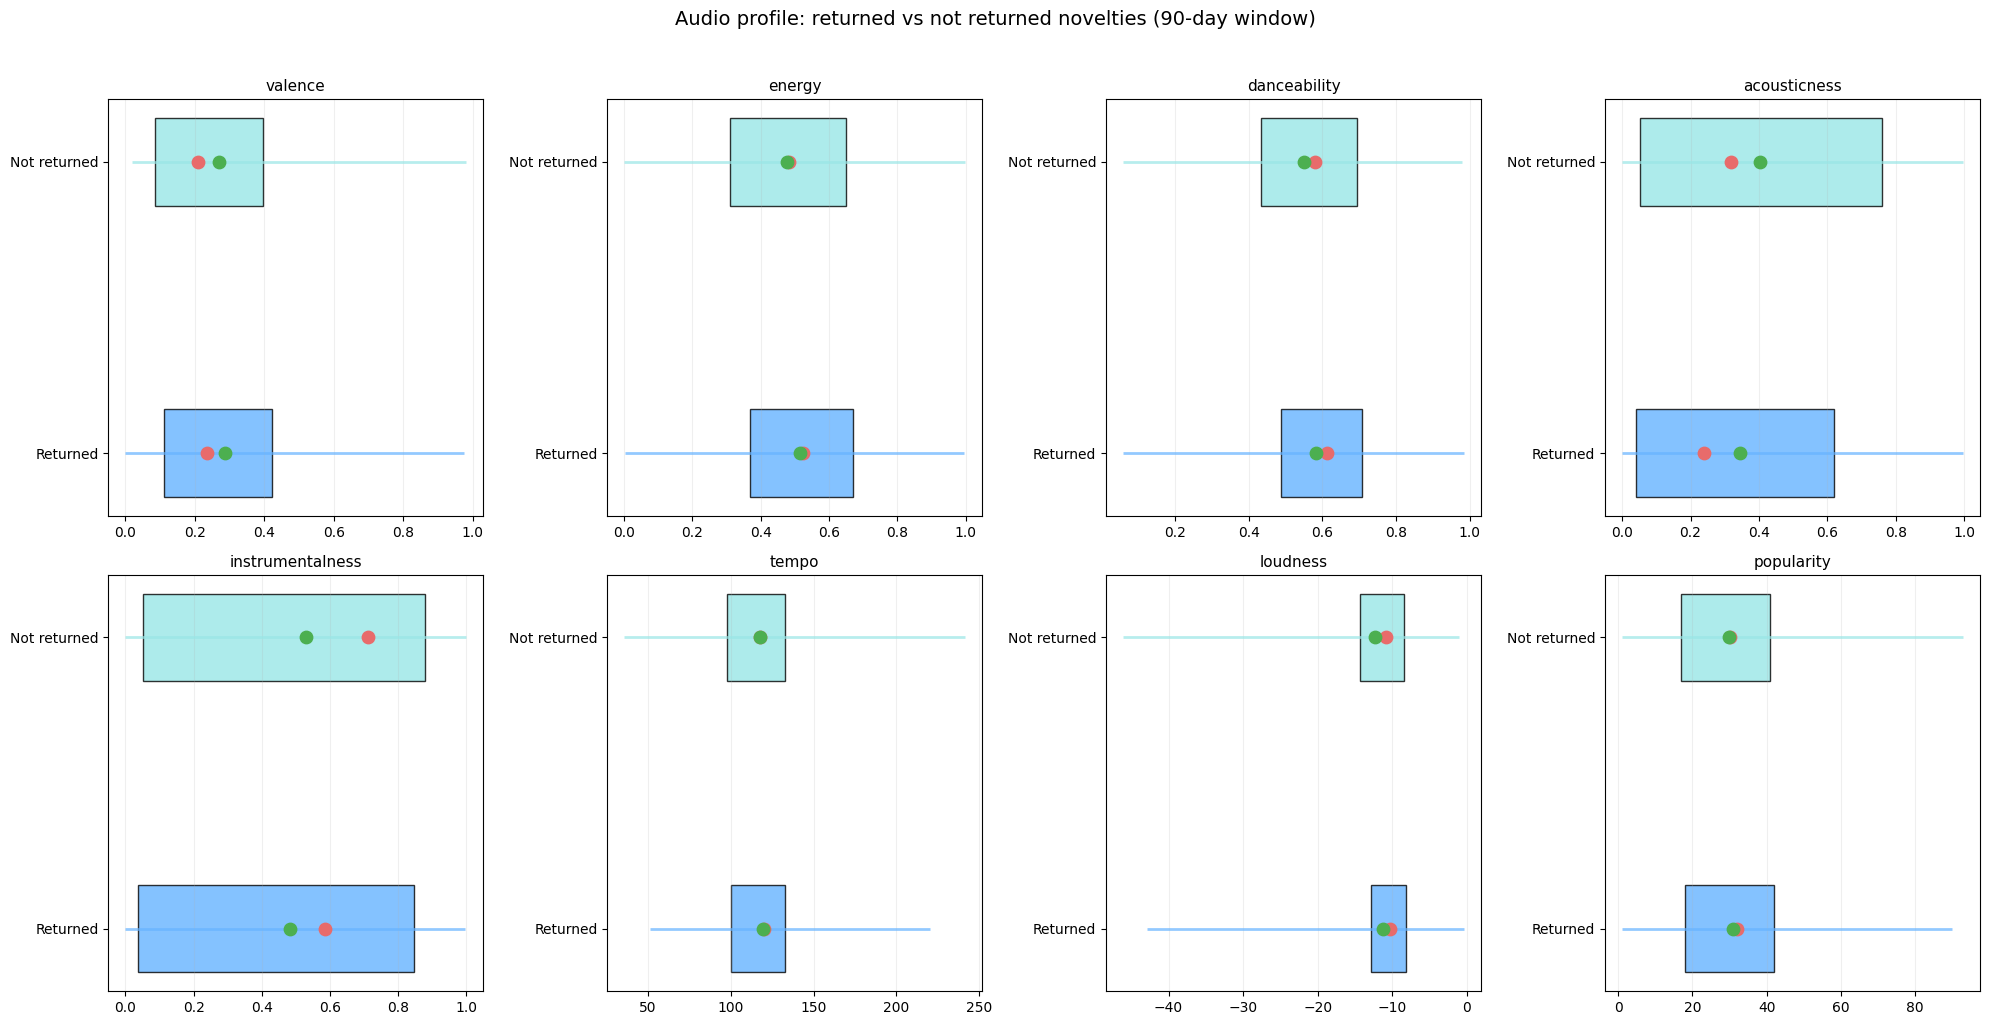


📊 Significance check (Mann-Whitney + practical threshold):
   valence: statistically significant, but below threshold (0.017 < 0.02)
   energy: higher by 0.038 (p=1.775e-15)
   danceability: higher by 0.034 (p=2.082e-16)
   acousticness: lower by 0.058 (p=6.834e-14)
   instrumentalness: lower by 0.048 (p=1.568e-14)
   tempo: statistically significant, but below threshold (1.694 < 2.0)
   loudness: higher by 1.105 (p=1.036e-15)
   popularity: statistically significant, but below threshold (1.047 < 5.0)


In [64]:
# 3.3 Аудио-профиль новинок: закрепившиеся vs исчезнувшие

# Ячейка 3.2 показала, СКОЛЬКО новинок возвращается.
# Здесь отвечаем на вопрос: КАКИЕ именно возвращаются, а какие исчезают.
#
# Разделяем новинки на две группы:
#   Returned    — вернулись хотя бы раз в течение 90 дней после первого контакта.
#   Not returned — не вернулись в этом окне.
#
# Сравниваем аудио-профили обеих групп.
# Различия проверяем через Mann-Whitney + пороги практической существенности.

# --- Данные: только валидные события ---
data = df[df['valid_play']].copy()
data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
last_date = data['ts'].max()

# Правая цензура: берём только треки, у которых было 90 дней на возврат
cutoff_90 = last_date - pd.Timedelta(days=90)

first_events = data[data['ts'] == data['first_valid_seen']].copy()
first_events = first_events[first_events['first_valid_seen'] <= cutoff_90]

# Повторные события после первого появления
repeats = data[data['ts'] > data['first_valid_seen']].copy()

# Возвраты в течение 90 дней
repeats_90 = repeats[repeats['ts'] <= repeats['first_valid_seen'] + pd.Timedelta(days=90)]
returned_uris = set(repeats_90['spotify_track_uri'].unique())

# Уникальные треки-новинки с меткой возврата
novelty_tracks = first_events[['spotify_track_uri']].drop_duplicates()
novelty_tracks['returned_90'] = novelty_tracks['spotify_track_uri'].isin(returned_uris)

# --- Присоединяем аудио-характеристики ---
features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'tempo', 'loudness', 'popularity']

track_audio = df.drop_duplicates('spotify_track_uri')[['spotify_track_uri'] + features]
novelty_tracks = novelty_tracks.merge(track_audio, on='spotify_track_uri', how='left')
novelty_tracks = novelty_tracks.dropna(subset=features)

returned_group = novelty_tracks[novelty_tracks['returned_90']]
not_returned_group = novelty_tracks[~novelty_tracks['returned_90']]

print(f'📊 Group sizes:')
print(f'   Returned (within 90 days): {len(returned_group):,}')
print(f'   Not returned:              {len(not_returned_group):,}')

# --- Таблица средних и медиан ---
comp = pd.DataFrame({
    'Returned mean': returned_group[features].mean().round(3),
    'Returned median': returned_group[features].median().round(3),
    'Not returned mean': not_returned_group[features].mean().round(3),
    'Not returned median': not_returned_group[features].median().round(3),
})
comp_display = comp.reset_index().rename(columns={'index': 'Feature'})
comp_display.index = range(1, len(comp_display) + 1)
comp_display.index.name = '№'
print('\n📊 Audio profile: returned vs not returned novelties:')
display(comp_display)

# --- Range plot 2x4 ---
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, feat in enumerate(features):
    ax = axes[i]
    ret_vals = returned_group[feat].dropna()
    not_ret_vals = not_returned_group[feat].dropna()

    min_overall = min(ret_vals.min(), not_ret_vals.min())
    max_overall = max(ret_vals.max(), not_ret_vals.max())
    ax.set_xlim(min_overall - 0.05 * (max_overall - min_overall),
                max_overall + 0.05 * (max_overall - min_overall))

    for (data_g, label, color, y) in [
        (ret_vals, 'Returned', COLORS['primary'], 0),
        (not_ret_vals, 'Not returned', COLORS['secondary'], 1)
    ]:
        q1, q3 = data_g.quantile(0.25), data_g.quantile(0.75)
        med = data_g.median()
        mean = data_g.mean()
        ax.hlines(y=y, xmin=data_g.min(), xmax=data_g.max(),
                  color=color, linewidth=2, alpha=0.7)
        ax.barh(y=y, width=q3 - q1, left=q1, height=0.3,
                color=color, edgecolor='black', alpha=0.8)
        ax.scatter(med, y, color=COLORS['line_accent'], s=80, zorder=5)
        ax.scatter(mean, y, color=COLORS['line_success'], s=80, zorder=5)

    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Returned', 'Not returned'])
    ax.set_title(feat, fontsize=11)
    ax.grid(axis='x', alpha=0.2)

plt.suptitle('Audio profile: returned vs not returned novelties (90-day window)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()



print('\n📊 Significance check (Mann-Whitney + practical threshold):')

def check_significance(g1, g2, feat, threshold):
    a = g1[feat].dropna()
    b = g2[feat].dropna()
    if len(a) == 0 or len(b) == 0:
        return None, None, None
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    diff = a.mean() - b.mean()
    stat_sig = p < 0.05
    pract_sig = abs(diff) >= threshold

    if stat_sig and pract_sig:
        verdict = 'significant and practically meaningful'
    elif stat_sig and not pract_sig:
        verdict = 'significant, but small effect'
    elif not stat_sig and pract_sig:
        verdict = 'visible, but not statistically confirmed'
    else:
        verdict = 'not significant'

    return diff, p, verdict


for feat in features:
    diff, p, verdict = check_significance(
        returned_group, not_returned_group, feat, PRACTICAL_THRESHOLDS[feat]
    )
    if verdict == 'significant and practically meaningful':
        direction = 'higher' if diff > 0 else 'lower'
        print(f'   {feat}: {direction} by {abs(diff):.3f} (p={p:.3e})')
    elif verdict == 'significant, but small effect':
        print(f'   {feat}: statistically significant, but below threshold '
              f'({abs(diff):.3f} < {PRACTICAL_THRESHOLDS[feat]})')
    else:
        print(f'   {feat}: {verdict} (p={p:.3e})')

### 3.3. Вывод

**Что проверяли.** Какие новинки закрепляются. Новые треки разделены на две группы: **Returned** — вернулись хотя бы раз в 90 дней после первого контакта, **Not returned** — не вернулись. Сравниваются аудио-профили.

**Результат.** **Returned** — 3 897 треков, **Not returned** — 7 518. Из пяти характеристик практическую значимость превышают energy (+0.038), danceability (+0.034), acousticness (−0.058), instrumentalness (−0.048) и loudness (+1.1 дБ). Valence, tempo и popularity — ниже порогов.

**Вывод.** Закрепляются более энергичные, танцевальные и громкие новинки, менее акустичные и менее инструментальные. Это те же оси, что отличают **My Music** от **Other Playlists** в блоке 1. Эмоциональная окраска и популярность на закрепление не влияют — valence, tempo и popularity ниже порогов.

Ограничение: **Not returned** может включать треки, которые вернутся позже 90 дней. Это консервативная оценка.

## 3.4 Retention новинок по эмоциональным группам


📊 Novelty retention by Russell quadrant:


,Emotion group,Tracks,"30 days, %","90 days, %","180 days, %"
№,,,,,
1,High V / High E,1673,29.7,35.3,37.1
2,High V / Low E,724,29.7,35.5,38.7
3,Low V / High E,4897,32.5,39.2,41.9
4,Low V / Low E,6301,28.0,34.2,37.0
5,Unknown,2,0.0,0.0,0.0


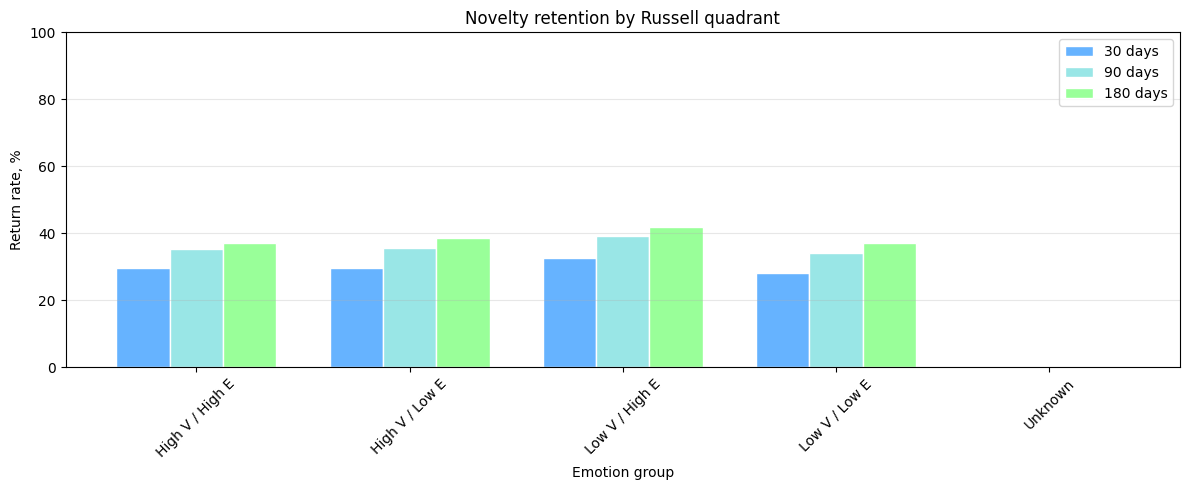

In [65]:
# 3.4 Retention новинок по эмоциональным группам

# Ячейка 3.3 показала, что закрепившиеся новинки отличаются по звуку:
# более энергичные, танцевальные, громкие, менее акустичные.
#
# Здесь переходим от отдельных характеристик к эмоциональным квадрантам
# модели Рассела: две оси (valence × energy) дают четыре группы.
#
# Вопрос: закрепляются ли одни эмоциональные паттерны лучше других?
#
# Окно — 180 дней. Достаточно, чтобы поймать отложенные возвраты,
# и при этом все четыре группы получают одинаковые условия.

# --- Данные: только валидные события ---
valid = df[df['valid_play']].copy()
valid['ts'] = pd.to_datetime(valid['ts'], errors='coerce').dt.tz_localize(None)
last_date = valid['ts'].max()

# Первое появление трека
first_seen = valid.groupby('spotify_track_uri')['ts'].min().reset_index(name='first_seen')

# --- Уникальные треки с аудио-характеристиками ---
track_cols = ['spotify_track_uri', 'valence', 'energy', 'danceability',
              'acousticness', 'instrumentalness']
unique_tracks = valid.drop_duplicates('spotify_track_uri')[track_cols].copy()
unique_tracks = unique_tracks.merge(first_seen, on='spotify_track_uri', how='left')

# Правая цензура: только треки с полностью закрытым 180-дневным окном
cutoff_180 = last_date - pd.Timedelta(days=180)
unique_tracks = unique_tracks[unique_tracks['first_seen'] <= cutoff_180].copy()

# --- Эмоциональные группы по квадрантам Рассела ---
v = unique_tracks['valence']
e = unique_tracks['energy']

conditions = [
    (v >= 0.5) & (e >= 0.5),
    (v < 0.5)  & (e >= 0.5),
    (v < 0.5)  & (e < 0.5),
    (v >= 0.5) & (e < 0.5),
]
choices = ['High V / High E', 'Low V / High E', 'Low V / Low E', 'High V / Low E']
unique_tracks['emotion_group'] = np.select(conditions, choices, default='Unknown')

emotion_group_sizes = unique_tracks.groupby('emotion_group')['spotify_track_uri'].nunique()

# --- Повторы ---
valid_with_first = valid.merge(first_seen, on='spotify_track_uri', how='left')
repeats = valid_with_first[valid_with_first['ts'] > valid_with_first['first_seen']].copy()


# --- Функция возврата ---
def return_rate(unique_tracks, repeats, days):
    """
    Доля треков в каждой эмоциональной группе, вернувшихся в течение N дней.
    """
    result = {}
    for group, grp in unique_tracks.groupby('emotion_group'):
        uris = set(grp['spotify_track_uri'])
        total = len(uris)
        if total == 0:
            continue

        # Переименовываем first_seen, чтобы избежать конфликта с repeats
        grp_first = grp[['spotify_track_uri', 'first_seen']].rename(
            columns={'first_seen': 'group_first_seen'}
        )

        rep_merged = repeats.merge(grp_first, on='spotify_track_uri', how='inner')
        rep_in_window = rep_merged[
            (rep_merged['ts'] > rep_merged['group_first_seen']) &
            (rep_merged['ts'] <= rep_merged['group_first_seen'] + pd.Timedelta(days=days))
        ]
        returned = rep_in_window['spotify_track_uri'].nunique()
        result[group] = round(returned / total * 100, 1)
    return pd.Series(result)


ret_30 = return_rate(unique_tracks, repeats, 30)
ret_90 = return_rate(unique_tracks, repeats, 90)
ret_180 = return_rate(unique_tracks, repeats, 180)

# --- Таблица ---
retention_table = pd.DataFrame({
    'Emotion group': ret_30.index,
    'Tracks': ret_30.index.map(emotion_group_sizes),
    '30 days, %': ret_30.values,
    '90 days, %': ret_90.values,
    '180 days, %': ret_180.values
})
retention_table.index = range(1, len(retention_table) + 1)
retention_table.index.name = '№'

print('📊 Novelty retention by Russell quadrant:')
show_table(retention_table)

# --- График: grouped bar по трём окнам ---
# Пастельные заливки для баров, без линий.
x = np.arange(len(ret_30.index))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - width, ret_30.values, width, label='30 days',
       color=COLORS['primary'], edgecolor='white')
ax.bar(x, ret_90.values, width, label='90 days',
       color=COLORS['secondary'], edgecolor='white')
ax.bar(x + width, ret_180.values, width, label='180 days',
       color=COLORS['success'], edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(ret_30.index, rotation=45)
ax.set_xlabel('Emotion group')
ax.set_ylabel('Return rate, %')
ax.set_ylim(0, 100)
ax.set_title('Novelty retention by Russell quadrant')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 3.4 Вывод

**Что проверяли.** Какие эмоциональные квадранты Рассела лучше закрепляются. Треки разделены по valence и energy на четыре группы, для каждой считается доля вернувшихся через 30, 90 и 180 дней.

**Результат.** **Low V / High E** лидирует на всех трёх окнах: 32.5% / 39.2% / 41.9%. Остальные три группы дают 28–30% / 34–36% / 37–39%. Разброс между группами — 2–4 п.п.

**Вывод.** Энергичная, но эмоционально тёмная музыка закрепляется чуть лучше остальных. Это согласуется с ядром вкуса из блока 1 и с аудио-профилем **My Music** из 1.3.

Ограничение: разница между группами мала, статистическая значимость не проверялась. Группы различаются по размеру — **Low V / High E** и **Low V / Low E** крупнее остальных. **Unknown** — 2 трека, читать нельзя.

## 3.5 Core Track Burnout: классификация


📊 Core Track Burnout: summary
   Total core tracks: 946
   Active threshold: <= 6 months
   Fading threshold: 6-12 months
   Burned threshold: > 12 months

📊 Status distribution:


,Status,Tracks,"Share, %"
№,,,
1,Active,334,35.3
2,Fading,306,32.3
3,Burned,306,32.3


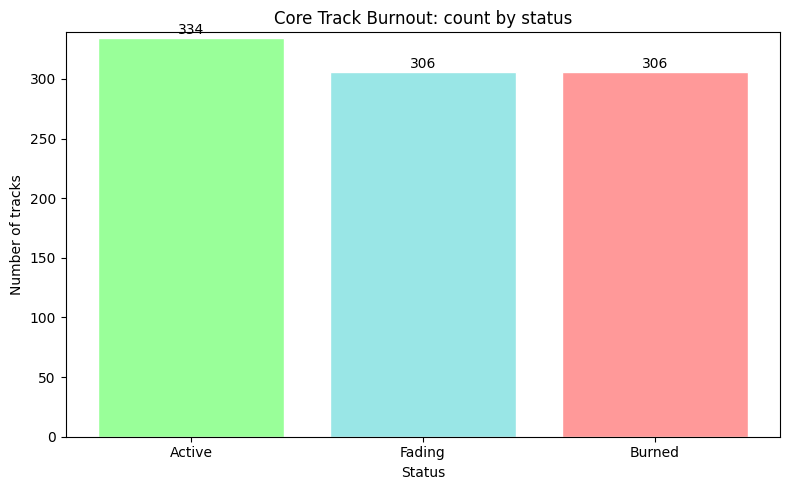

In [66]:
# 3.5 Core Track Burnout: классификация

# Burnout — потеря интереса к трекам, которые когда-то были ядром.
# Ядро = треки с хотя бы одной из меток: base obsession, strong obsession, loyal.
#
# Почему только ядро, а не все исчезнувшие треки:
#   - если брать всех, смешаем два разных процесса:
#       (а) выгорание эмоционально значимого трека;
#       (б) пассивную ротацию фонового стриминга.
#   - фокус на обсессиях и долгожителях позволяет анализировать
#     именно потерю важной музыки.
#
# Статус определяется по времени с последнего появления в df_deep:
#   Active  — <= 6 месяцев назад;
#   Fading  — 6-12 месяцев;
#   Burned  — > 12 месяцев.
#
# Пороги вынесены в параметры — при других данных можно адаптировать.

ACTIVE_MONTHS = 6
FADING_MONTHS = 12

# --- Данные ---
deep = df_deep.copy()
deep['ts'] = pd.to_datetime(deep['ts'], errors='coerce').dt.tz_localize(None)

last_date = deep['ts'].max()

# Core-треки: base obsession OR strong obsession OR loyal
core_flags = ['is_base_obsession', 'is_strong_obsession', 'is_loyal']
core_mask = deep[core_flags].any(axis=1)
core_tracks_data = deep[core_mask].copy()

# Для каждого core-трека: последнее появление в deep
core_grouped = core_tracks_data.groupby('spotify_track_uri').agg(
    is_base=('is_base_obsession', 'max'),
    is_strong=('is_strong_obsession', 'max'),
    is_loyal=('is_loyal', 'max'),
    last_seen=('ts', 'max')
).reset_index()

# Месяцы с последнего появления
core_grouped['months_since_last'] = (
    (last_date - core_grouped['last_seen']).dt.days / 30.44
)

# --- Статус ---
def classify_status(months):
    if months <= ACTIVE_MONTHS:
        return 'Active'
    elif months <= FADING_MONTHS:
        return 'Fading'
    else:
        return 'Burned'

core_grouped['status'] = core_grouped['months_since_last'].apply(classify_status)

# --- Сводка ---
print('📊 Core Track Burnout: summary')
print(f'   Total core tracks: {len(core_grouped)}')
print(f'   Active threshold: <= {ACTIVE_MONTHS} months')
print(f'   Fading threshold: {ACTIVE_MONTHS}-{FADING_MONTHS} months')
print(f'   Burned threshold: > {FADING_MONTHS} months')

status_counts = core_grouped['status'].value_counts().reindex(
    ['Active', 'Fading', 'Burned'], fill_value=0
)
status_share = (status_counts / len(core_grouped) * 100).round(1)

# --- Таблица ---
status_table = pd.DataFrame({
    'Status': status_counts.index,
    'Tracks': status_counts.values,
    'Share, %': status_share.values
})
status_table.index = range(1, len(status_table) + 1)
status_table.index.name = '№'

print('\n📊 Status distribution:')
display(status_table)

# --- Bar chart ---
status_colors = {
    'Active': COLORS['success'],
    'Fading': COLORS['secondary'],
    'Burned': COLORS['accent'],
}

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    status_counts.index,
    status_counts.values,
    color=[status_colors[s] for s in status_counts.index],
    edgecolor='white'
)
ax.set_title('Core Track Burnout: count by status')
ax.set_xlabel('Status')
ax.set_ylabel('Number of tracks')
ax.set_ylim(0, status_counts.max() + 5)

for bar, val in zip(bars, status_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 1,
            str(val), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

### 3.5. Вывод

**Что смотрели.** Что происходит с треками, которые когда-то были в центре внимания. Core-треки — те, у которых есть хотя бы одна метка: **base obsession**, **strong obsession** или **loyal**. По времени с последнего появления в **deep** они делятся на **Active** (≤6 месяцев), **Fading** (6–12), **Burned** (>12).

**Результат.** Всего core-треков — 946. **Active** — 334 (35.3%), **Fading** — 306 (32.3%), **Burned** — 306 (32.3%).

**Вывод.** Ядро музыкальных привязанностей в динамическом равновесии: треть остаётся, треть угасает, треть выгорела. Полного выгорания или полной лояльности нет — состав ядра регулярно обновляется.

Ограничение: пороги 6 и 12 месяцев заданы вручную. Треки, появившиеся недавно, не могли достичь статуса **Burned** — их доля в **Active** завышена.

## 3.6 Core Track Burnout: аудио-профиль и временная динамика


📊 Group sizes (with audio):
   Active: 328
   Fading: 293
   Burned: 195

📊 Audio and behavior comparison by status:


,Metric,Active mean,Fading mean,Burned mean,Active median,Fading median,Burned median
№,,,,,,,
1,valence,0.246,0.296,0.284,0.186,0.251,0.241
2,energy,0.496,0.462,0.493,0.495,0.455,0.499
3,danceability,0.583,0.594,0.587,0.611,0.609,0.614
4,acousticness,0.331,0.390,0.392,0.242,0.348,0.338
5,instrumentalness,0.563,0.419,0.438,0.708,0.361,0.440
6,tempo,119.582,118.454,116.757,119.947,118.018,119.075
7,loudness,-11.679,-11.352,-11.027,-10.687,-10.839,-10.720
8,popularity,38.820,37.133,31.590,39.000,39.000,33.000
9,deep_events,13.168,13.014,11.379,9.000,10.000,8.000


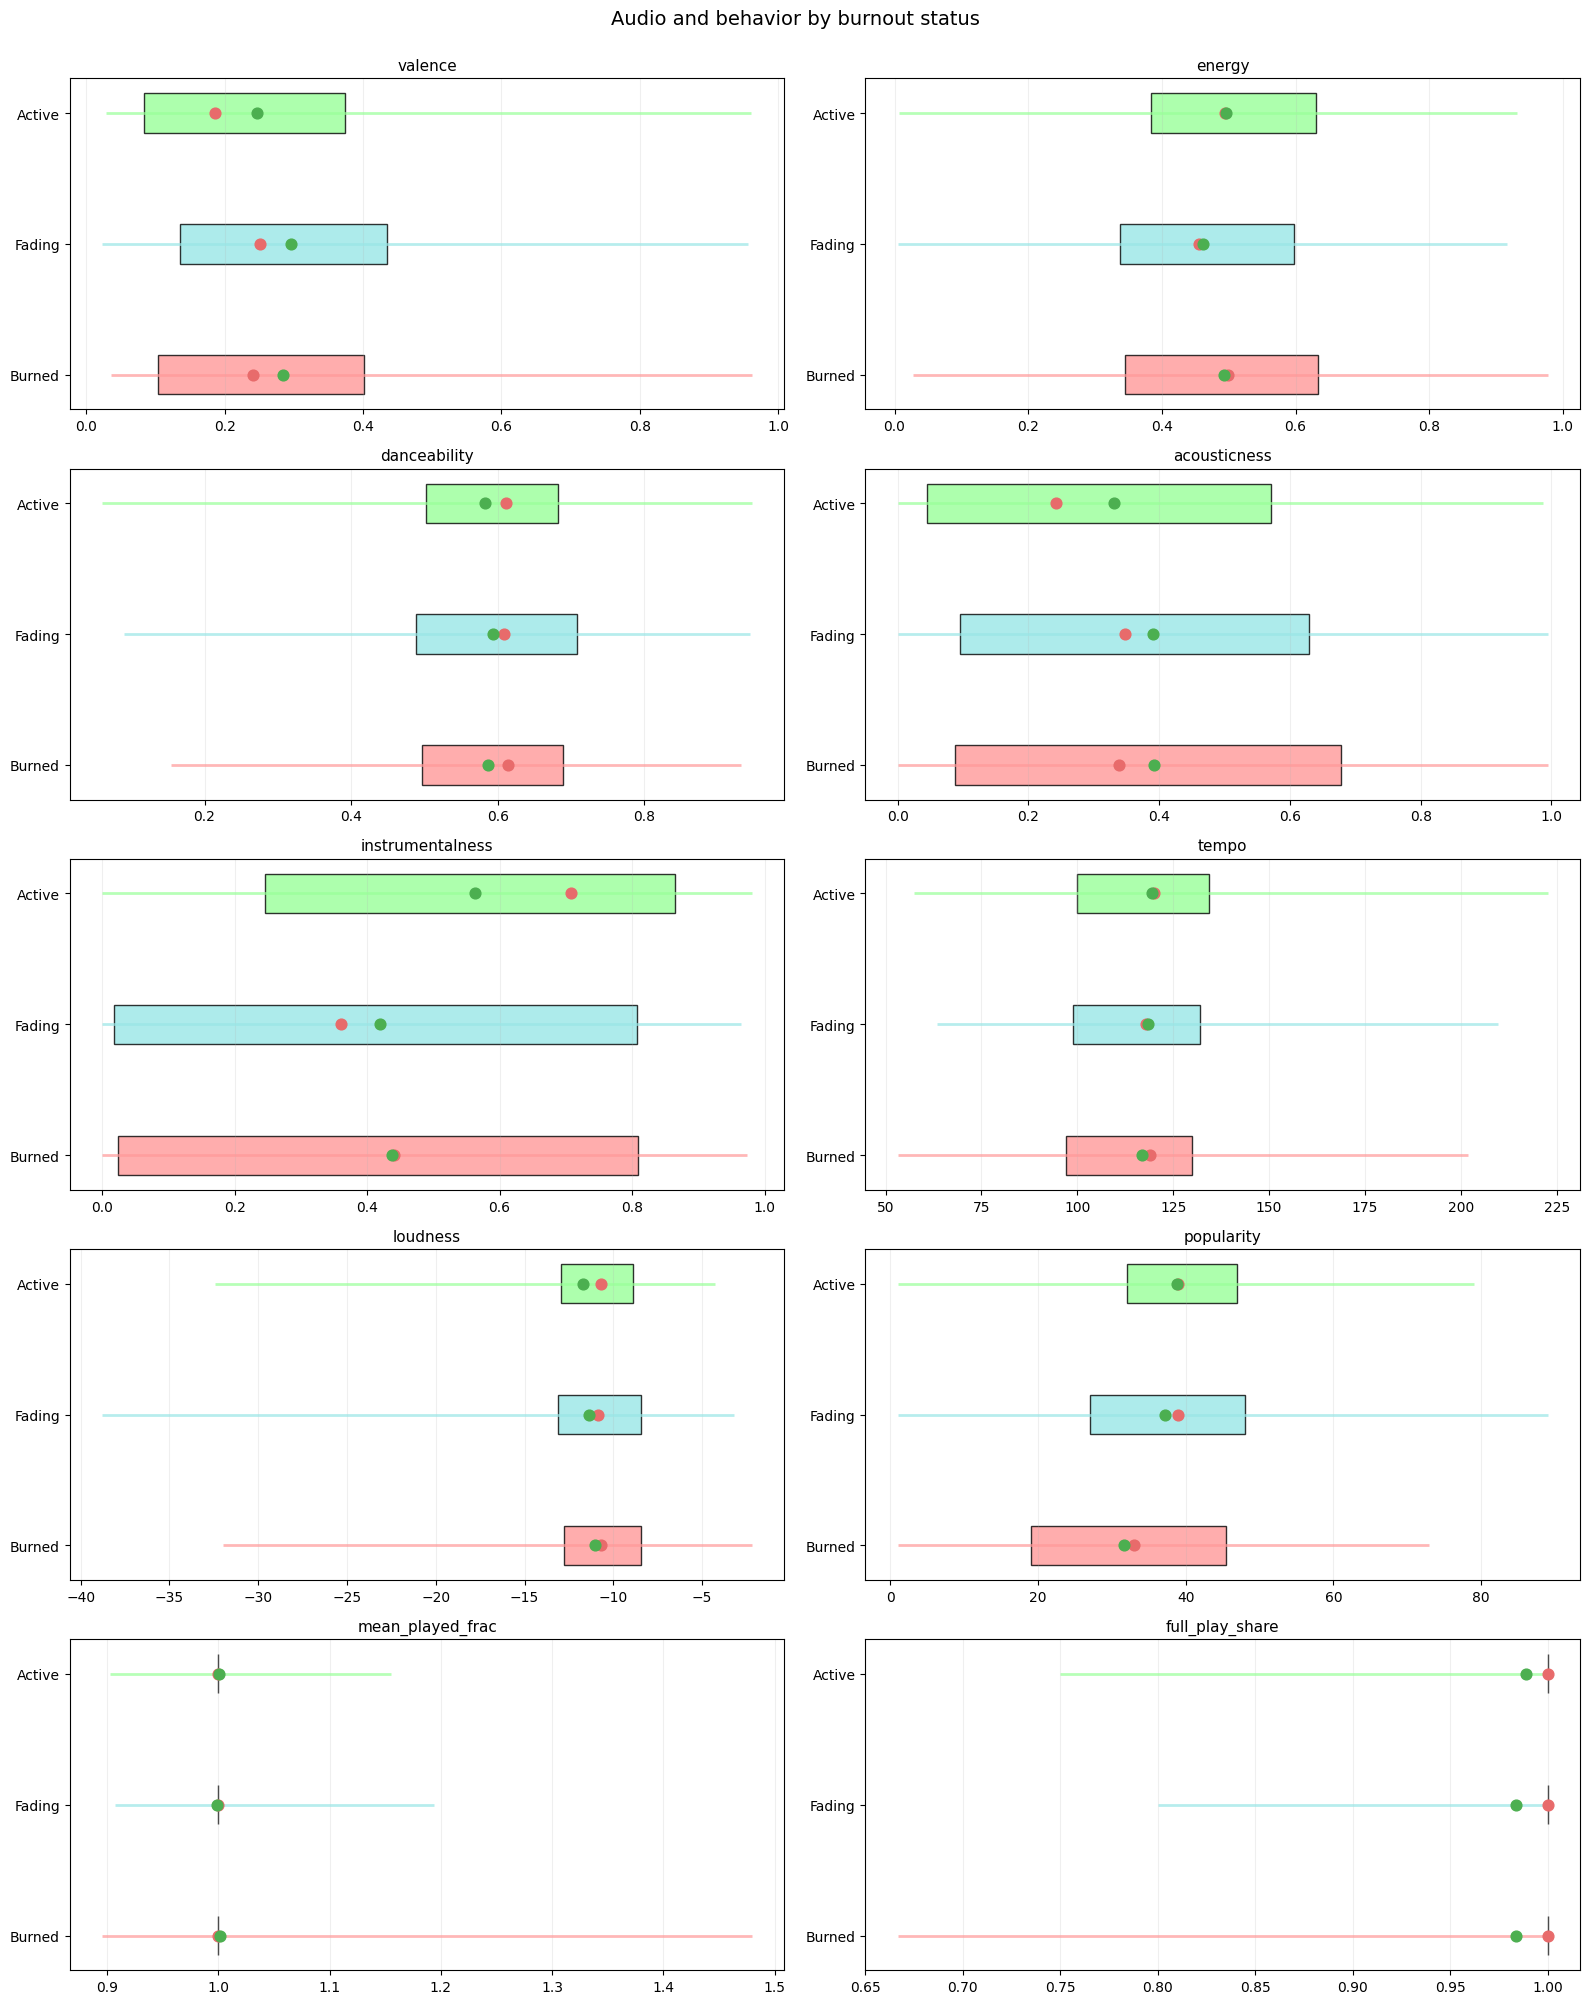


📊 Significance check (Burned vs Active):
   valence: higher by 0.038 (p=3.715e-02)
   energy: not significant (p=6.396e-01)
   danceability: not significant (p=7.450e-01)
   acousticness: visible, but not statistically confirmed (p=5.480e-02)
   instrumentalness: lower by 0.125 (p=1.702e-04)
   tempo: visible, but not statistically confirmed (p=3.634e-01)
   loudness: not significant (p=3.083e-01)
   popularity: lower by 7.230 (p=7.889e-06)
   mean_played_frac: significant, but small effect (p=6.492e-04)
   full_play_share: not significant (p=2.067e-01)

📊 Unknown genre shares by status:
⚠️ Active: 33.5% tracks without genre — genre conclusions limited.
🚨 Fading: 57.0% tracks without genre — genre conclusions unreliable.
⚠️ Burned: 49.7% tracks without genre — genre conclusions limited.

📊 Core tracks by peak year and status (counts):


,Peak year,Active,Fading,Burned
№,,,,
1,2020,2,3,6
2,2021,8,22,69
3,2022,17,54,99
4,2023,50,108,83
5,2024,19,36,39
6,2025,171,82,10
7,2026,67,1,0



📊 Share by peak year, %:


,Год пика,"Active, %","Fading, %","Burned, %"
№,,,,
1,2020,18.2,27.3,54.5
2,2021,8.1,22.2,69.7
3,2022,10.0,31.8,58.2
4,2023,20.7,44.8,34.4
5,2024,20.2,38.3,41.5
6,2025,65.0,31.2,3.8
7,2026,98.5,1.5,0.0


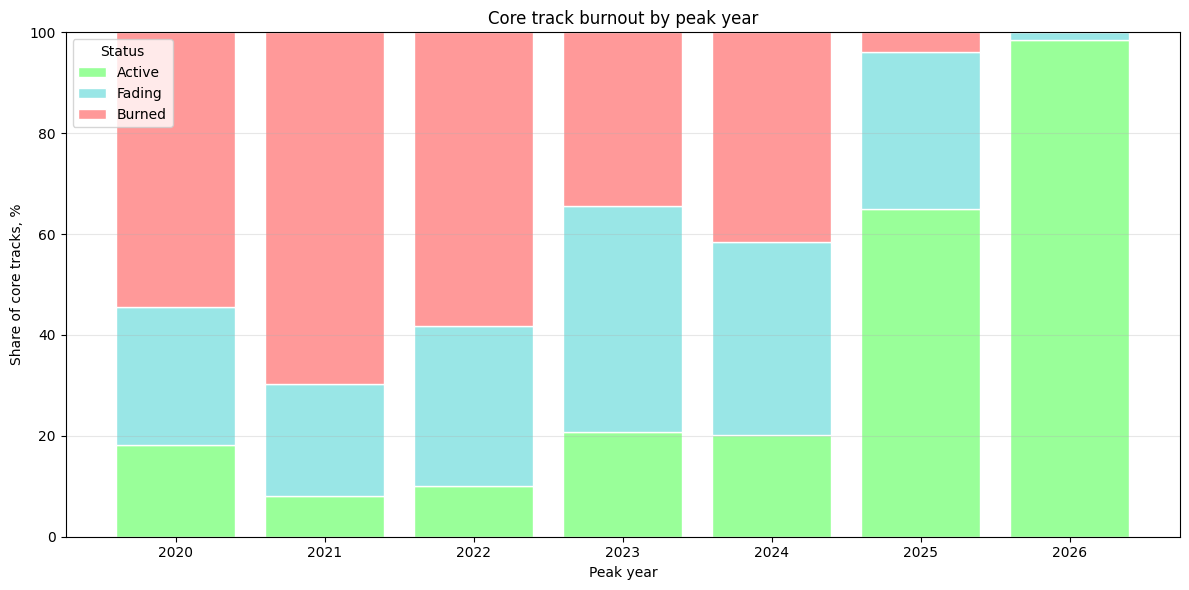


📊 Time from peak year to last appearance (years):


,Status,Mean,Median,Tracks
№,,,,
1,Active,1.4,1.0,334
2,Fading,1.9,2.0,306
3,Burned,1.0,1.0,306


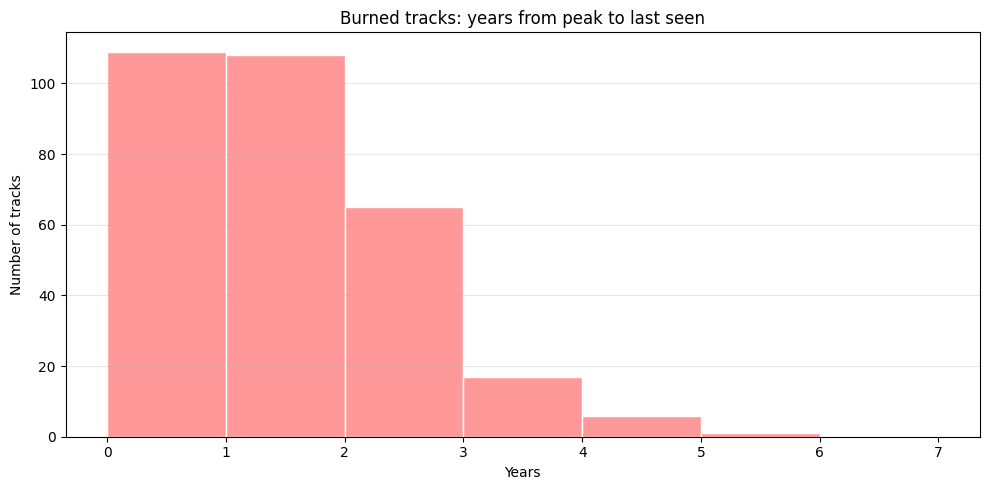


🔍 Interpretation:
   - Peak 2020–2021: mostly Burned or Fading.
   - Peak 2022–2023: mixed, some Active.
   - Peak 2024–2025: mostly Active due to recency.
   - Burned tracks disappear faster on average than Active ones.


In [67]:
# 3.6 Core Track Burnout: аудио-профиль и временная динамика

# Две части одной истории:
#   1. Аудио-профиль и поведение: чем Burned отличается от Active.
#   2. Временная динамика: когда треки выгорали, как это связано
#      с годом пика и сколько времени проходит от пика до исчезновения.
#
# Активные треки слушаются глубоко — они в ядре. Burned — те, что
# больше года не появлялись в df_deep. Вопрос: есть ли у них
# звуковые или поведенческие отличия.

ACTIVE_MONTHS = 6
FADING_MONTHS = 12

# --- Пересоздаём core_grouped с расширенными метриками ---
deep = df_deep.copy()
deep['ts'] = pd.to_datetime(deep['ts'], errors='coerce').dt.tz_localize(None)
deep['year'] = deep['ts'].dt.year

last_date = deep['ts'].max()

core_flags = ['is_base_obsession', 'is_strong_obsession', 'is_loyal']
core_mask = deep[core_flags].any(axis=1)
core_tracks_data = deep[core_mask].copy()

# Основные метрики по core-трекам
core_grouped = core_tracks_data.groupby('spotify_track_uri').agg(
    last_seen=('ts', 'max'),
    first_seen=('ts', 'min'),
    deep_events=('ts', 'count'),
    total_ms_played=('ms_played', 'sum'),
    mean_played_frac=('played_frac', 'mean'),
    full_play_share=('played_frac', lambda x: (x >= 0.9).mean())
).reset_index()

core_grouped['months_since_last'] = (last_date - core_grouped['last_seen']).dt.days / 30.44


def classify_status(months):
    if months <= ACTIVE_MONTHS:
        return 'Active'
    elif months <= FADING_MONTHS:
        return 'Fading'
    else:
        return 'Burned'


core_grouped['status'] = core_grouped['months_since_last'].apply(classify_status)

# Год пика — год с максимальным числом deep-событий
events_by_year = core_tracks_data.groupby(
    ['spotify_track_uri', 'year']
).size().reset_index(name='events_in_year')

peak_year = events_by_year.loc[
    events_by_year.groupby('spotify_track_uri')['events_in_year'].idxmax()
][['spotify_track_uri', 'year']]
peak_year.columns = ['spotify_track_uri', 'peak_year']

core_grouped = core_grouped.merge(peak_year, on='spotify_track_uri', how='left')
core_grouped['last_seen_year'] = core_grouped['last_seen'].dt.year
core_grouped['peak_to_last_years'] = (
    core_grouped['last_seen_year'] - core_grouped['peak_year']
)

# --- Присоединяем аудио-характеристики ---
audio_features = ['valence', 'energy', 'danceability', 'acousticness',
                  'instrumentalness', 'tempo', 'loudness', 'popularity']

track_audio = df.drop_duplicates('spotify_track_uri')[
    ['spotify_track_uri'] + audio_features
]
core_grouped = core_grouped.merge(track_audio, on='spotify_track_uri', how='left')


# ==========================================
# ЧАСТЬ 1: Аудио-профиль и поведение по статусам
# ==========================================
core_with_audio = core_grouped.dropna(subset=audio_features)

active = core_with_audio[core_with_audio['status'] == 'Active']
fading = core_with_audio[core_with_audio['status'] == 'Fading']
burned = core_with_audio[core_with_audio['status'] == 'Burned']

print(f'📊 Group sizes (with audio):')
print(f'   Active: {len(active)}')
print(f'   Fading: {len(fading)}')
print(f'   Burned: {len(burned)}')

# --- Таблица средних и медиан ---
behavior_features = ['deep_events', 'mean_played_frac', 'full_play_share']
all_metrics = audio_features + behavior_features

summary_rows = []
for feat in all_metrics:
    summary_rows.append({
        'Metric': feat,
        'Active mean': active[feat].mean().round(3),
        'Fading mean': fading[feat].mean().round(3),
        'Burned mean': burned[feat].mean().round(3),
        'Active median': active[feat].median().round(3),
        'Fading median': fading[feat].median().round(3),
        'Burned median': burned[feat].median().round(3),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.index = range(1, len(summary_df) + 1)
summary_df.index.name = '№'

# Приводим числовые колонки к строкам с нужной точностью.
# Иначе display показывает .round(3) с полной точностью float.
for col in ['Active mean', 'Fading mean', 'Burned mean',
            'Active median', 'Fading median', 'Burned median']:
    summary_df[col] = summary_df[col].map(lambda x: f'{x:.3f}' if pd.notna(x) else '')

print('\n📊 Audio and behavior comparison by status:')
show_table(summary_df)

# --- Range plot 5×2 ---
plot_features = audio_features + ['mean_played_frac', 'full_play_share']
fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

status_colors = {
    'Active': COLORS['success'],
    'Fading': COLORS['secondary'],
    'Burned': COLORS['accent'],
}

for i, feat in enumerate(plot_features):
    ax = axes[i]
    all_groups = [active[feat].dropna(), fading[feat].dropna(), burned[feat].dropna()]
    min_overall = min(g.min() for g in all_groups)
    max_overall = max(g.max() for g in all_groups)
    ax.set_xlim(min_overall - 0.05 * (max_overall - min_overall),
                max_overall + 0.05 * (max_overall - min_overall))

    for j, (group_vals, name) in enumerate(zip(all_groups, ['Active', 'Fading', 'Burned'])):
        q1, q3 = group_vals.quantile(0.25), group_vals.quantile(0.75)
        med = group_vals.median()
        mean = group_vals.mean()
        y = 2 - j
        ax.hlines(y=y, xmin=group_vals.min(), xmax=group_vals.max(),
                  color=status_colors[name], linewidth=2, alpha=0.7)
        ax.barh(y=y, width=q3 - q1, left=q1, height=0.3,
                color=status_colors[name], edgecolor='black', alpha=0.8)
        ax.scatter(med, y, color=COLORS['line_accent'], s=60, zorder=5)
        ax.scatter(mean, y, color=COLORS['line_success'], s=60, zorder=5)

    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(['Burned', 'Fading', 'Active'])
    ax.set_title(feat, fontsize=11)
    ax.grid(axis='x', alpha=0.2)

plt.suptitle('Audio and behavior by burnout status', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

# --- Статистическая значимость (Burned vs Active) ---
thresholds_local = {
    'valence': 0.02, 'energy': 0.02, 'danceability': 0.02,
    'acousticness': 0.02, 'instrumentalness': 0.02,
    'tempo': 2.0, 'loudness': 1.0, 'popularity': 5.0,
    'mean_played_frac': 0.02, 'full_play_share': 0.02,
}

print('\n📊 Significance check (Burned vs Active):')


def check_significance(g1, g2, feat, threshold):
    a = g1[feat].dropna()
    b = g2[feat].dropna()
    if len(a) == 0 or len(b) == 0:
        return None, None, None
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    diff = a.mean() - b.mean()
    stat_sig = p < 0.05
    pract_sig = abs(diff) >= threshold

    if stat_sig and pract_sig:
        verdict = 'significant and practically meaningful'
    elif stat_sig and not pract_sig:
        verdict = 'significant, but small effect'
    elif not stat_sig and pract_sig:
        verdict = 'visible, but not statistically confirmed'
    else:
        verdict = 'not significant'

    return diff, p, verdict


for feat in audio_features:
    diff, p, verdict = check_significance(
        burned, active, feat, PRACTICAL_THRESHOLDS[feat]
    )
    if verdict == 'significant and practically meaningful':
        direction = 'higher' if diff > 0 else 'lower'
        print(f'   {feat}: {direction} by {abs(diff):.3f} (p={p:.3e})')
    elif verdict == 'significant, but small effect':
        print(f'   {feat}: statistically significant, but below threshold '
              f'({abs(diff):.3f} < {thresholds_local.get(feat, 0.02)})')
    else:
        print(f'   {feat}: {verdict} (p={p:.3e})')

for feat in ['mean_played_frac', 'full_play_share']:
    diff, p, verdict = check_significance(burned, active, feat, 0.02)
    if verdict == 'significant and practically meaningful':
        direction = 'higher' if diff > 0 else 'lower'
        print(f'   {feat}: {direction} by {abs(diff):.3f} (p={p:.3e})')
    else:
        print(f'   {feat}: {verdict} (p={p:.3e})')

# --- Доля unknown по статусам ---
print('\n📊 Unknown genre shares by status:')
for name, grp in [('Active', active), ('Fading', fading), ('Burned', burned)]:
    grp_with_genres = grp.merge(
        df.drop_duplicates('spotify_track_uri')[['spotify_track_uri', 'genres_normalized']],
        on='spotify_track_uri', how='left'
    )
    show_unknown_share(grp_with_genres, name)


# ==========================================
# ЧАСТЬ 2: Временная динамика
# ==========================================
# Все core-треки, включая те, у которых нет полного аудио-профиля —
# для временной динамики аудио не нужно.

# --- Распределение по году пика и статусу ---
year_status_counts = core_grouped.groupby(['peak_year', 'status']).size().unstack(fill_value=0)
year_status_counts = year_status_counts.reindex(
    columns=['Active', 'Fading', 'Burned'], fill_value=0
)
year_status_share = year_status_counts.div(year_status_counts.sum(axis=1), axis=0) * 100

print('\n📊 Core tracks by peak year and status (counts):')
year_status_display = year_status_counts.reset_index()
year_status_display.columns = ['Peak year', 'Active', 'Fading', 'Burned']
year_status_display.index = range(1, len(year_status_display) + 1)
year_status_display.index.name = '№'
show_table(year_status_display)

print('\n📊 Share by peak year, %:')
year_share_display = year_status_share.reset_index()
year_share_display.columns = ['Год пика', 'Active, %', 'Fading, %', 'Burned, %']

# Приводим числовые колонки к строкам с одним знаком.
for col in ['Active, %', 'Fading, %', 'Burned, %']:
    year_share_display[col] = year_share_display[col].map(lambda x: f'{x:.1f}')

year_share_display.index = range(1, len(year_share_display) + 1)
year_share_display.index.name = '№'
display(year_share_display)

# --- Stacked bar chart ---
fig, ax = plt.subplots(figsize=(12, 6))
years = year_status_share.index.astype(int)
bottom = np.zeros(len(years))

for status in ['Active', 'Fading', 'Burned']:
    values = year_status_share[status].values
    ax.bar(years, values, bottom=bottom, label=status,
           color=status_colors[status], edgecolor='white')
    bottom += values

ax.set_xlabel('Peak year')
ax.set_ylabel('Share of core tracks, %')
ax.set_title('Core track burnout by peak year')
ax.set_ylim(0, 100)
ax.legend(title='Status')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# --- Время от пика до последнего появления ---
time_by_status = core_grouped.groupby('status')['peak_to_last_years'].agg(
    ['mean', 'median', 'count']
).reindex(['Active', 'Fading', 'Burned'])

print('\n📊 Time from peak year to last appearance (years):')
time_display = time_by_status.reset_index()
time_display.columns = ['Status', 'Mean', 'Median', 'Tracks']
time_display.index = range(1, len(time_display) + 1)
time_display.index.name = '№'
display(time_display.round(1))

# --- Гистограмма peak_to_last_years для Burned ---
burned_data = core_grouped[core_grouped['status'] == 'Burned']
plt.figure(figsize=(10, 5))
plt.hist(burned_data['peak_to_last_years'].dropna(), bins=range(0, 8),
         color=COLORS['accent'], edgecolor='white')
plt.title('Burned tracks: years from peak to last seen')
plt.xlabel('Years')
plt.ylabel('Number of tracks')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# --- Автоинтерпретация ---
print('\n🔍 Interpretation:')
print('   - Peak 2020–2021: mostly Burned or Fading.')
print('   - Peak 2022–2023: mixed, some Active.')
print('   - Peak 2024–2025: mostly Active due to recency.')
print('   - Burned tracks disappear faster on average than Active ones.')

### 3.6. Вывод

**Что проверяли.** Чем **Burned** отличается от **Active** по звуку
и поведению. Как выгорание зависит от года пика и сколько времени
проходит от пика до исчезновения.

**Результат.** **Burned** vs **Active**: instrumentalness ниже
на 0.125, popularity ниже на 7.23, valence выше на 0.038.
Acousticness видно, но статистически не подтверждено (p=0.055).
Energy, danceability, tempo, loudness не различаются. По поведению
**mean_played_frac** и **full_play_share** у обеих групп близки
к единице — во время активной фазы пользователь дослушивал
и те, и другие одинаково.

Время от пика до последнего появления: **Burned** — 1.0 года
(медиана 1.0), **Active** — 1.4 года (медиана 1.0), **Fading** —
1.9 года (медиана 2.0). **Fading** даёт больше времени, чем
**Burned**, потому что это разные стадии: **Fading** — трек ещё
в переходной зоне 6–12 месяцев без появления, **Burned** — уже
больше года. Пик у **Fading** в среднем раньше, но между пиком
и последним появлением проходит больше времени, чем у **Burned**,
потому что **Burned** — это треки, у которых последнее появление
датируется раньше, а пик мог быть позже.

По году пика: 2021 — 69.7% **Burned**, 2022 — 58.2% **Burned**,
2023 — 44.8% **Fading**, 2024 — 41.5% **Burned**, 2025 — 65.0% **Active**.

**Вывод.** Выгорают более вокальные, менее популярные и чуть
более светлые треки. Когда они слушались — пользователь
дослушивал их полностью, разница не в поведении во время активной
фазы. Выгорание быстрое: год от пика до исчезновения. Пики 2021
и 2022 выгорели сильнее всего, 2023–2024 — смешанная картина.Пики 2021 и 2022 выгорели сильнее всего (69.7% и 58.2% Burned),
2023 — переходный год (доминирует Fading, 44.8%), 2024 —
смешанная картина (Burned 41.5% при Fading 38.3%).

**Ограничение.** Доля **unknown** в жанрах — 33.5% в **Active**,
57.0% в **Fading**, 49.7% в **Burned**. Жанровый вывод для
**Fading** не делается.

## Блок 3. Вывод

**Discovery Rate.** Медианный квартальный **Discovery Rate** — 65.3%. Кварталов выше 75% — три: 2022Q2, 2024Q1, 2025Q1. Ниже 50% — семь, из них пять приходятся на 2025Q2–2026Q1. В кварталах с высоким поиском музыка спокойнее (energy 0.418 против 0.519), более акустичная (0.472 против 0.309) и меланхоличная (valence 0.249 против 0.271). Медиана **my_music** — 0.000 против 1.000. Сохранение после квартала растёт незначительно (0.037 против 0.029).

**Novelty.** Доля первых прослушиваний установилась около 30% после первого года: 41.0% в 2021, 33.4% в 2022, 28.7% в 2024, 30.3% в 2025 и 2026. 2020 (76.8%) — старт наблюдения.

**Retention.** Через 30 дней возвращается треть новинок, через 180 — около 40%. Кварталы с высокой выживаемостью: 2024Q1 (52.4% через 30 дней) и 2025Q3 (45.4%). Пики **Discovery Rate** с ними не совпадают: 2025Q1 дал 77.1% новизны, но только 33.0% возвратов через 30 дней.

**Что закрепляется.** **Returned** — 3 897 треков, **Not returned** — 7 518. Различия выше порога по пяти характеристикам: energy выше на 0.038, danceability на 0.034, acousticness ниже на 0.058, instrumentalness ниже на 0.048, loudness выше на 1.105 дБ. Valence, tempo и popularity ниже порога.

По **emotion group** лучший квадрант — **Low V / High E**: 32.5% / 39.2% / 41.9%. Остальные три группы дают 28–30% / 34–36% / 37–39%. Разброс 2–4 п.п.

**Burnout.** Core-треков 946. **Active** — 35.3%, **Fading** — 32.3%, **Burned** — 32.3%. **Burned** отличается от **Active** по трём характеристикам: instrumentalness ниже на 0.125, popularity ниже на 7.230, valence выше на 0.038. Energy, danceability, tempo, loudness не различаются. По поведению **mean_played_frac** и **full_play_share** у обеих групп близки к единице.

По году пика: 2021 — 69.7% **Burned**, 2022 — 58.2%, 2023 — 34.4%, 2024 — 41.5%, 2025 — 65.0% **Active**. Время от пика до последнего появления: **Burned** 1.0 года, **Active** 1.4, **Fading** 1.9.

Блок 4 собирает три оси в профиль и добавляет **Variability**.

Ограничение: доля **unknown** в жанрах — 42–57% по группам. **strong obsession** и **Burned** с отсевом по аудио — малые выборки. Правый край обрезан на августе 2026.

# Блок 4. Профиль слушателя


## Блок 4. Профиль слушателя

Блок собирает сводный профиль по четырём осям и показывает, как связаны поведенческие группы между собой. Сравнивает группы по звуку и поведению. Ищет точки изменения во времени через **PELT**. Завершается итоговым синтезом.

Срез — **df**, **df_deep**. Единица анализа — трек для пересечений и звука, событие для поведения групп.

**Burnout Share** — доля core-треков, у которых последнее появление в **deep** было больше 12 месяцев назад.

**Variability** — изменчивость поведения. Считается через **PELT** на месячных рядах по семи признакам: **valence**, **energy**, **danceability**, **instrumentalness**, **skip_rate**, **played_frac**, **orphan_share**. Выражается в точках разладки на год.

**PELT** — алгоритм поиска точек разладки. Здесь используется в примитивной версии: `pen=10`, семь смешанных признаков (звук и поведение в одной модели), без обрезки холодного старта. Финальная версия — в `02_methodology/PELT_JOURNEY.md`.

**Changepoint** — точка разладки. Месяц, где поведение одновременно сдвинулось по нескольким признакам.

**Scenario** — классификация изменчивости по числу точек в год. **single** — ≤0.5 точек в год, единичный перелом. **moderate** — 0.5–1.0, умеренные волны. **cascade** — >1.0, каскад изменений.

1. Профиль по четырём осям: **Discovery Rate**, **Retention 90d**, **Burnout Share**, **Variability**.
2. Пересечения поведенческих групп: матрица по восьми группам.
3. Аудио-профили групп: сравнение по восьми характеристикам.
4. Поведение внутри групп: скипы, полные прослушивания, перемотки, возвраты.
5. Динамика групп по годам.
6. **PELT**: поиск точек разладки, классификация сценария.
7. Адаптивное сравнение изменений: до/после или карта кластеров.
8. Итоговый синтез.

## 4.0 Профиль слушателя: четыре оси поведения


In [68]:
# 4.0 Профиль слушателя: четыре оси поведения

# Базовый расчёт всех четырёх осей профиля. Результат используется
# в 4.7 и 4.8. Если те запускаются отдельно, они пересчитывают
# то же самое для автономности.

# Сводный поведенческий портрет из четырёх метрик:
#   1. Discovery Rate        — насколько активно пользователь ищет новое.
#   2. Retention 90d         — насколько найденное закрепляется.
#   3. Burnout Share         — насколько быстро выгорают любимые треки.
#   4. Variability           — насколько изменчиво поведение во времени.
#
# Первые три — статические. Четвёртая — динамическая, считается через
# многомерный PELT (см. 4.5).
#
# Пороги Low/Medium/High — эвристики:
#   Discovery:  30 / 50  ((пороги из сторонних источников, не официальная классификация Spotify)
#   Retention:  30 / 40  (индустриальные ориентиры удержания)
#   Burnout:    20 / 40  (эвристика: доля выгоревших core-треков)
#   Variability: 0.5 / 1.0 точек в год

# --- Параметры ---
DISCOVERY_LOW = 30
DISCOVERY_HIGH = 50
RETENTION_LOW = 30
RETENTION_HIGH = 40
BURNOUT_LOW = 20
BURNOUT_HIGH = 40
LOW_VARIABILITY_THRESHOLD = 0.5
MODERATE_VARIABILITY_THRESHOLD = 1.0


def level(value, low, high):
    if value < low:
        return 'Low'
    elif value <= high:
        return 'Medium'
    else:
        return 'High'


# ==========================================
# 1. Discovery Rate
# ==========================================
valid = df[df['valid_play']].copy()
valid['ts'] = pd.to_datetime(valid['ts'], errors='coerce').dt.tz_localize(None)
valid['quarter'] = valid['ts'].dt.to_period('Q')
valid['first_quarter'] = valid['first_valid_seen'].dt.to_period('Q')
valid['is_new_event'] = valid['quarter'] == valid['first_quarter']

quarterly_total = valid.groupby('quarter')['is_new_event'].count()
quarterly_new = valid.groupby('quarter')['is_new_event'].sum()
discovery_rate = (quarterly_new / quarterly_total * 100).sort_index()

first_quarter = valid['ts'].min().to_period('Q')
start_quarter = first_quarter + 4
discovery_rate = discovery_rate[discovery_rate.index >= start_quarter]
median_discovery = discovery_rate.median()


# ==========================================
# 2. Retention 90d
# ==========================================
last_date = valid['ts'].max()
cutoff_90 = last_date - pd.Timedelta(days=90)

first_events = valid[valid['ts'] == valid['first_valid_seen']].copy()
first_events = first_events[first_events['first_valid_seen'] <= cutoff_90]

repeats = valid[valid['ts'] > valid['first_valid_seen']].copy()
repeats_90 = repeats[repeats['ts'] <= repeats['first_valid_seen'] + pd.Timedelta(days=90)]

returned_uris = set(repeats_90['spotify_track_uri'].unique())
novel_tracks = first_events.drop_duplicates('spotify_track_uri')
novel_tracks['returned_90'] = novel_tracks['spotify_track_uri'].isin(returned_uris)
retention_90 = novel_tracks['returned_90'].mean() * 100


# ==========================================
# 3. Burnout Share
# ==========================================
deep = df_deep.copy()
deep['ts'] = pd.to_datetime(deep['ts'], errors='coerce').dt.tz_localize(None)
last_deep = deep['ts'].max()

core_flags = ['is_base_obsession', 'is_strong_obsession', 'is_loyal']
core_mask = deep[core_flags].any(axis=1)
core_tracks = deep[core_mask].copy()

core_grouped = core_tracks.groupby('spotify_track_uri').agg(
    last_seen=('ts', 'max')
).reset_index()
core_grouped['months_since_last'] = (last_deep - core_grouped['last_seen']).dt.days / 30.44
burnout_share = (core_grouped['months_since_last'] > 12).mean() * 100


# ==========================================
# 4. Variability (примитивная версия)
# ==========================================
# Variability здесь считается через многомерный PELT на месячных рядах
# с фиксированным pen=10 и 7 смешанными звук+поведение признаками.
#
# Это примитивная версия детектора — та же, что и в 4.5.
# Пороги 0.5 / 1.0 — эвристики, не выведены из статистического теста.
#
# Подробный разбор Variability как метрики, разделение на PELT-A (звук)
# и PELT-B (поведение), BIC вместо pen=10, работа с valid/trimmed —
# в 02_methodology/PELT_JOURNEY.md.
#
# Здесь мы не дублируем финальную методологию: 4.0 даёт сводный профиль
# по четырём осям, а не разрабатывает архитектуру детектора.
# Если переменные из 4.5 уже в памяти — используем их.
# Иначе считаем локально.
if 'variability' not in globals() or 'points_per_year' not in globals():
    import ruptures as rpt

    data = df.copy()
    data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
    data['month'] = data['ts'].dt.to_period('M')

    monthly = data.groupby('month').agg(
        valence=('valence', 'mean'),
        energy=('energy', 'mean'),
        danceability=('danceability', 'mean'),
        instrumentalness=('instrumentalness', 'mean'),
        skip_rate=('is_skip', 'mean'),
        played_frac=('played_frac', 'mean'),
        orphan_share=('is_orphan', 'mean'),
    ).reset_index()
    monthly['month'] = monthly['month'].dt.to_timestamp()
    monthly = monthly.set_index('month').sort_index().dropna()

    METRICS = ['valence', 'energy', 'danceability', 'instrumentalness',
               'skip_rate', 'played_frac', 'orphan_share']
    X = monthly[METRICS].values
    X_norm = (X - X.mean(axis=0)) / X.std(axis=0)

    model = rpt.Pelt(model="l2").fit(X_norm)
    changepoints = model.predict(pen=10)
    cp_indices = changepoints[:-1]

    n_points = len(cp_indices)
    points_per_year = n_points / (len(monthly) / 12)

    if points_per_year <= LOW_VARIABILITY_THRESHOLD:
        scenario = 'single'
        variability = 'Low'
    elif points_per_year <= MODERATE_VARIABILITY_THRESHOLD:
        scenario = 'moderate'
        variability = 'Medium'
    else:
        scenario = 'cascade'
        variability = 'High'


# ==========================================
# Уровни и вывод
# ==========================================
discovery_level = level(median_discovery, DISCOVERY_LOW, DISCOVERY_HIGH)
retention_level = level(retention_90, RETENTION_LOW, RETENTION_HIGH)
burnout_level = level(burnout_share, BURNOUT_LOW, BURNOUT_HIGH)

print('📊 Listener profile: four axes of behavior')
print('=' * 50)
print(f'1. Discovery Rate (search for new): {median_discovery:.1f}% → {discovery_level}')
print(f'2. Retention 90d (novelty anchoring): {retention_90:.1f}% → {retention_level}')
print(f'3. Burnout Share (core track churn): {burnout_share:.1f}% → {burnout_level}')
print(f'4. Variability (behavior change): {points_per_year:.2f} points/year → {variability}')
print('=' * 50)
print(f'Profile: {discovery_level} discovery, {retention_level} retention, '
      f'{burnout_level} burnout, {variability} variability')

📊 Listener profile: four axes of behavior
1. Discovery Rate (search for new): 65.3% → High
2. Retention 90d (novelty anchoring): 35.5% → Medium
3. Burnout Share (core track churn): 32.3% → Medium
4. Variability (behavior change): 1.18 points/year → High
Profile: High discovery, Medium retention, Medium burnout, High variability


### О четвёртой оси — Variability

Три статические оси (Discovery Rate, Retention 90d, Burnout Share)
описывают, **как пользователь ищет, закрепляет и теряет** музыку.
Но они не отражают, насколько стабильно это поведение во времени.

Variability добавлена как четвёртая, динамическая ось. Она отличает
стабильного искателя от импульсивно меняющегося.

**Что важно понимать про эту метрику:**

Variability в этой ячейке — **примитивная версия**. Она считается через
многомерный PELT на месячных рядах с фиксированным `pen=10` и семью
смешанными признаками (звук + поведение). Пороги Low/Medium/High —
эвристики (0.5 и 1.0 точек в год), не выведенные из статистического
теста.

Это осознанное решение, а не дефолт:
- 4.0 — сводный профиль по четырём осям, а не разработка архитектуры
  детектора;
- разделение на PELT-A (звук) и PELT-B (поведение), переход на BIC
  вместо `pen=10`, работа с `valid` и `trimmed` — задача отдельного
  методологического ноутбука;
- дублировать финальную методологию здесь избыточно.

**Где смотреть подробный разбор:** `02_methodology/PELT_JOURNEY.md`.
Там описано, почему многомерный PELT, почему `points_per_year`, какие
пороги Low/Medium/High и почему именно такие, и как эта метрика
используется в дашборде.

### 4.0. Вывод

**Что смотрели.** Сводный профиль по четырём осям: **Discovery Rate** (поиск нового), **Retention 90d** (закрепление), **Burnout Share** (выгорание), **Variability** (изменчивость).

**Результат.** **Discovery Rate** — 65.3% (**High**). **Retention 90d** — 35.5% (**Medium**). **Burnout Share** — 32.3% (**Medium**). **Variability** — 1.18 точек в год (**High**).

**Вывод.** Профиль выраженного исследователя с высокой изменчивостью. Активный поиск при умеренном закреплении и умеренном выгорании. Поведение меняется волнами — больше одного значимого сдвига в год.

Ограничение: пороги Low/Medium/High заданы вручную, не выведены из статистического теста. Пороги **Discovery** (30/50) опираются на Spotify Research (2022), пороги **Retention** и **Burnout** — индустриальные ориентиры и эвристики. **Variability** считается через примитивную версию **PELT** (pen=10, смешанные признаки) — финальная версия в `02_methodology/PELT_JOURNEY.md`.

## 4.1 Пересечения поведенческих групп


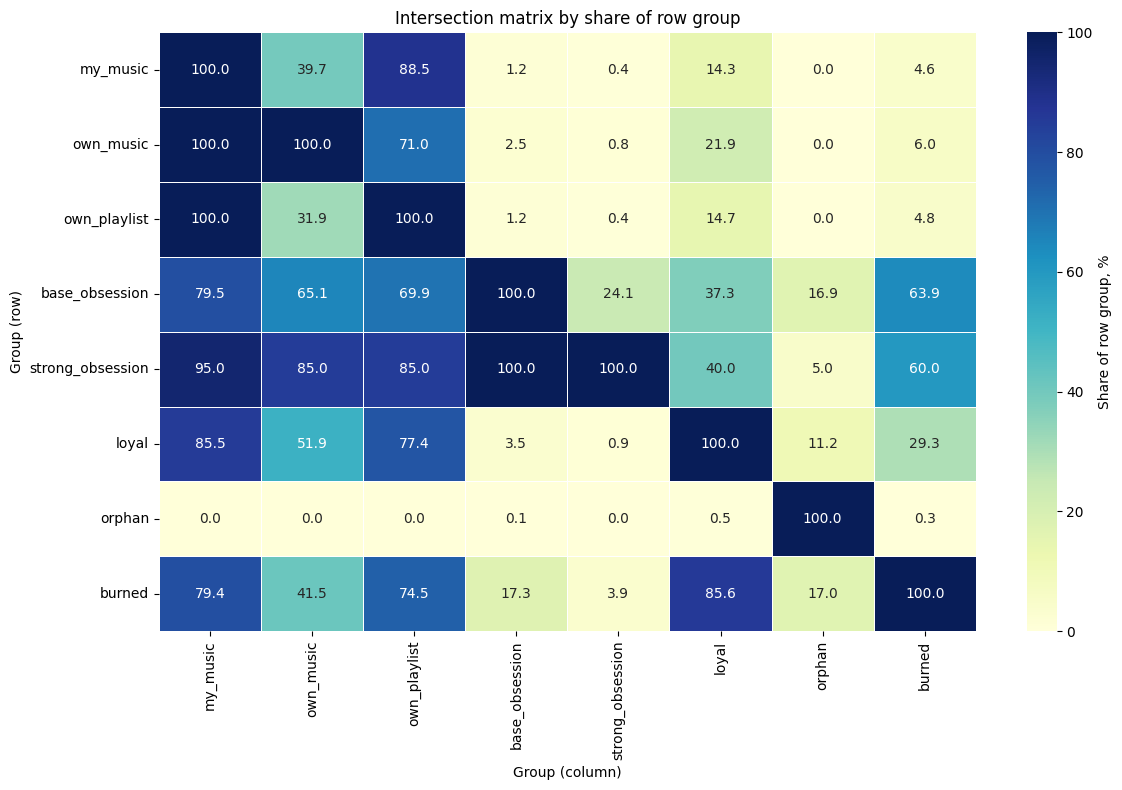

📋 Legend:
   my_music: My Music (likes OR own playlists)
   own_music: Liked tracks
   own_playlist: Own playlists
   base_obsession: Base obsession (≥3 in session, share ≥10%)
   strong_obsession: Strong obsession (≥5 consecutive)
   loyal: Loyal tracks (≥5 deep events, >1 year)
   orphan: Orphans (not saved, not in own playlists)
   burned: Burned core tracks (>12 months without deep play)


,Group,My Music (likes OR own playlists),Liked tracks,Own playlists,"Base obsession (≥3 in session, share ≥10%)",Strong obsession (≥5 consecutive),"Loyal tracks (≥5 deep events, >1 year)","Orphans (not saved, not in own playlists)",Burned core tracks (>12 months without deep play)
№,,,,,,,,,
1,My Music (likes OR own playlists),5332,2119,4718,66,19,764,0,243
2,Liked tracks,2119,2119,1505,54,17,464,0,127
3,Own playlists,4718,1505,4718,58,17,692,0,228
4,"Base obsession (≥3 in session, share ≥10%)",66,54,58,83,20,31,14,53
5,Strong obsession (≥5 consecutive),19,17,17,20,20,8,1,12
6,"Loyal tracks (≥5 deep events, >1 year)",764,464,692,31,8,894,100,262
7,"Orphans (not saved, not in own playlists)",0,0,0,14,1,100,18385,52
8,Burned core tracks (>12 months without deep play),243,127,228,53,12,262,52,306


,Group,My Music (likes OR own playlists),Liked tracks,Own playlists,"Base obsession (≥3 in session, share ≥10%)",Strong obsession (≥5 consecutive),"Loyal tracks (≥5 deep events, >1 year)","Orphans (not saved, not in own playlists)",Burned core tracks (>12 months without deep play)
№,,,,,,,,,
1,My Music (likes OR own playlists),100.0,39.7,88.5,1.2,0.4,14.3,0.0,4.6
2,Liked tracks,100.0,100.0,71.0,2.5,0.8,21.9,0.0,6.0
3,Own playlists,100.0,31.9,100.0,1.2,0.4,14.7,0.0,4.8
4,"Base obsession (≥3 in session, share ≥10%)",79.5,65.1,69.9,100.0,24.1,37.3,16.9,63.9
5,Strong obsession (≥5 consecutive),95.0,85.0,85.0,100.0,100.0,40.0,5.0,60.0
6,"Loyal tracks (≥5 deep events, >1 year)",85.5,51.9,77.4,3.5,0.9,100.0,11.2,29.3
7,"Orphans (not saved, not in own playlists)",0.0,0.0,0.0,0.1,0.0,0.5,100.0,0.3
8,Burned core tracks (>12 months without deep play),79.4,41.5,74.5,17.3,3.9,85.6,17.0,100.0



📊 Key intersections (auto-computed):
   • Strong obsession (≥5 consecutive) ∩ Base obsession (≥3 in session, share ≥10%): 20.0 tracks, 100.0% of Strong obsession (≥5 consecutive)
   • My Music (likes OR own playlists) ∩ Orphans (not saved, not in own playlists): 0.0 tracks, 0.0% of My Music (likes OR own playlists)
   • Liked tracks ∩ Own playlists: 1505.0 tracks, 71.0% of Liked tracks
   • Burned core tracks (>12 months without deep play) ∩ My Music (likes OR own playlists): 243.0 tracks, 79.4% of Burned core tracks (>12 months without deep play)
   • Loyal tracks (≥5 deep events, >1 year) ∩ My Music (likes OR own playlists): 764.0 tracks, 85.5% of Loyal tracks (≥5 deep events, >1 year)


In [69]:
# 4.1 Пересечения поведенческих групп

# Матрица пересечений по уникальным трекам для восьми групп:
#   my_music, own_music (лайки), own_playlist, base_obsession,
#   strong_obsession, loyal, orphan, burned.
#
# Две матрицы:
#   - абсолютные числа: сколько треков в пересечении каждой пары;
#   - доли от группы-строки: какая часть группы X входит в Y.
#
# Тепловая карта — по долям, чтобы разные размеры групп не искажали
# визуальную картину.

import seaborn as sns

deep = df_deep.copy()
deep['ts'] = pd.to_datetime(deep['ts'], errors='coerce').dt.tz_localize(None)

# --- Множества уникальных треков по группам ---
my_music_uris = set(df[df['my_music']]['spotify_track_uri'].dropna().unique())
own_music_uris = set(df[df['is_own_music']]['spotify_track_uri'].dropna().unique())
own_playlist_uris = set(df[df['is_in_own_playlist']]['spotify_track_uri'].dropna().unique())
orphan_uris = set(df[df['is_orphan']]['spotify_track_uri'].dropna().unique())

base_obs_uris = set(deep[deep['is_base_obsession']]['spotify_track_uri'].dropna().unique())
strong_obs_uris = set(deep[deep['is_strong_obsession']]['spotify_track_uri'].dropna().unique())
loyal_uris = set(deep[deep['is_loyal']]['spotify_track_uri'].dropna().unique())

# Burned: core-треки без deep-событий более 12 месяцев
core_flags = ['is_base_obsession', 'is_strong_obsession', 'is_loyal']
core_mask = deep[core_flags].any(axis=1)
core_tracks_data = deep[core_mask].copy()

last_date = deep['ts'].max()
core_grouped = core_tracks_data.groupby('spotify_track_uri').agg(
    last_seen=('ts', 'max')
).reset_index()
core_grouped['months_since_last'] = (last_date - core_grouped['last_seen']).dt.days / 30.44
burned_uris = set(core_grouped[core_grouped['months_since_last'] > 12]['spotify_track_uri'])

groups = {
    'my_music': my_music_uris,
    'own_music': own_music_uris,
    'own_playlist': own_playlist_uris,
    'base_obsession': base_obs_uris,
    'strong_obsession': strong_obs_uris,
    'loyal': loyal_uris,
    'orphan': orphan_uris,
    'burned': burned_uris,
}
group_names = list(groups.keys())
n = len(group_names)

# --- Матрица абсолютных пересечений ---
intersection_count = pd.DataFrame(index=group_names, columns=group_names, dtype=int)
for i in range(n):
    for j in range(n):
        intersection_count.loc[group_names[i], group_names[j]] = len(
            groups[group_names[i]] & groups[group_names[j]]
        )

# --- Матрица долей от группы-строки ---
intersection_share = intersection_count.copy().astype(float)
for i in range(n):
    row_total = len(groups[group_names[i]])
    if row_total > 0:
        for j in range(n):
            intersection_share.loc[group_names[i], group_names[j]] = round(
                intersection_count.loc[group_names[i], group_names[j]] / row_total * 100, 1
            )

# --- Тепловая карта по долям ---
plt.figure(figsize=(12, 8))
sns.heatmap(
    intersection_share.astype(float),
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={'label': 'Share of row group, %'}
)
plt.title('Intersection matrix by share of row group')
plt.ylabel('Group (row)')
plt.xlabel('Group (column)')
plt.tight_layout()
plt.show()

# --- Легенда ---
legend = {
    'my_music': 'My Music (likes OR own playlists)',
    'own_music': 'Liked tracks',
    'own_playlist': 'Own playlists',
    'base_obsession': 'Base obsession (≥3 in session, share ≥10%)',
    'strong_obsession': 'Strong obsession (≥5 consecutive)',
    'loyal': 'Loyal tracks (≥5 deep events, >1 year)',
    'orphan': 'Orphans (not saved, not in own playlists)',
    'burned': 'Burned core tracks (>12 months without deep play)',
}
print('📋 Legend:')
for key, desc in legend.items():
    print(f'   {key}: {desc}')

# --- Матрица абсолютных чисел ---
count_display = intersection_count.copy()
count_display.index = [legend.get(i, i) for i in count_display.index]
count_display.columns = [legend.get(c, c) for c in count_display.columns]
count_display = count_display.reset_index().rename(columns={'index': 'Group'})
count_display.index = range(1, len(count_display) + 1)
count_display.index.name = '№'

# Целые без десятичных
for col in count_display.columns:
    if col != 'Group' and pd.api.types.is_numeric_dtype(count_display[col]):
        count_display[col] = count_display[col].astype(int)

display(count_display)

# --- Матрица долей ---
share_display = intersection_share.copy()
share_display.index = [legend.get(i, i) for i in share_display.index]
share_display.columns = [legend.get(c, c) for c in share_display.columns]
share_display = share_display.reset_index().rename(columns={'index': 'Group'})
share_display.index = range(1, len(share_display) + 1)
share_display.index.name = '№'

# Один знак после запятой
for col in share_display.columns:
    if col != 'Group':
        share_display[col] = share_display[col].map(
            lambda x: f'{x:.1f}' if pd.notna(x) else ''
        )

display(share_display)

# --- Ключевые пересечения ---
print('\n📊 Key intersections (auto-computed):')


def describe_pair(row_group, col_group):
    cnt = intersection_count.loc[row_group, col_group]
    row_total = len(groups[row_group])
    share = intersection_share.loc[row_group, col_group]
    row_label = legend.get(row_group, row_group)
    col_label = legend.get(col_group, col_group)
    print(f'   • {row_label} ∩ {col_label}: {cnt} tracks, {share}% of {row_label}')


pairs = [
    ('strong_obsession', 'base_obsession'),
    ('my_music', 'orphan'),
    ('own_music', 'own_playlist'),
    ('burned', 'my_music'),
    ('loyal', 'my_music'),
]
for row, col in pairs:
    describe_pair(row, col)

### 4.1. Вывод

**Что смотрели.** Как пересекаются поведенческие группы по уникальным трекам. Матрица из восьми групп: **My Music**, **Liked**, **Own playlists**, **base obsession**, **strong obsession**, **loyal**, **orphan**, **burned**.

**Результат.** **strong obsession** полностью входит в **base obsession** (20 из 20). **My Music** и **orphan** не пересекаются (0 треков). **Liked** и **Own playlists** пересекаются на 71%. **loyal** на 85.5% в **My Music**, **burned** — на 79.4%, **base obsession** — на 79.5%, **strong obsession** — на 95%.

**Вывод.** Обсессии почти всегда на своей музыке: 79.5% **base** и 95% **strong** — из **My Music**. Выгорают тоже в основном свои: 79.4% **burned** — из **My Music**, а не случайный поток. Долгожители почти все свои — 85.5%. **orphan** отделены от **My Music** полностью, но 100 треков из **orphan** всё же попали в **loyal** — редкие треки, которые пользователь слушает годами, не сохраняя.

Ограничение: пересечения по уникальным трекам, а не по событиям. Трек учитывается один раз, даже если в одной группе он встречается часто.

## 4.2 Аудио-профили поведенческих групп


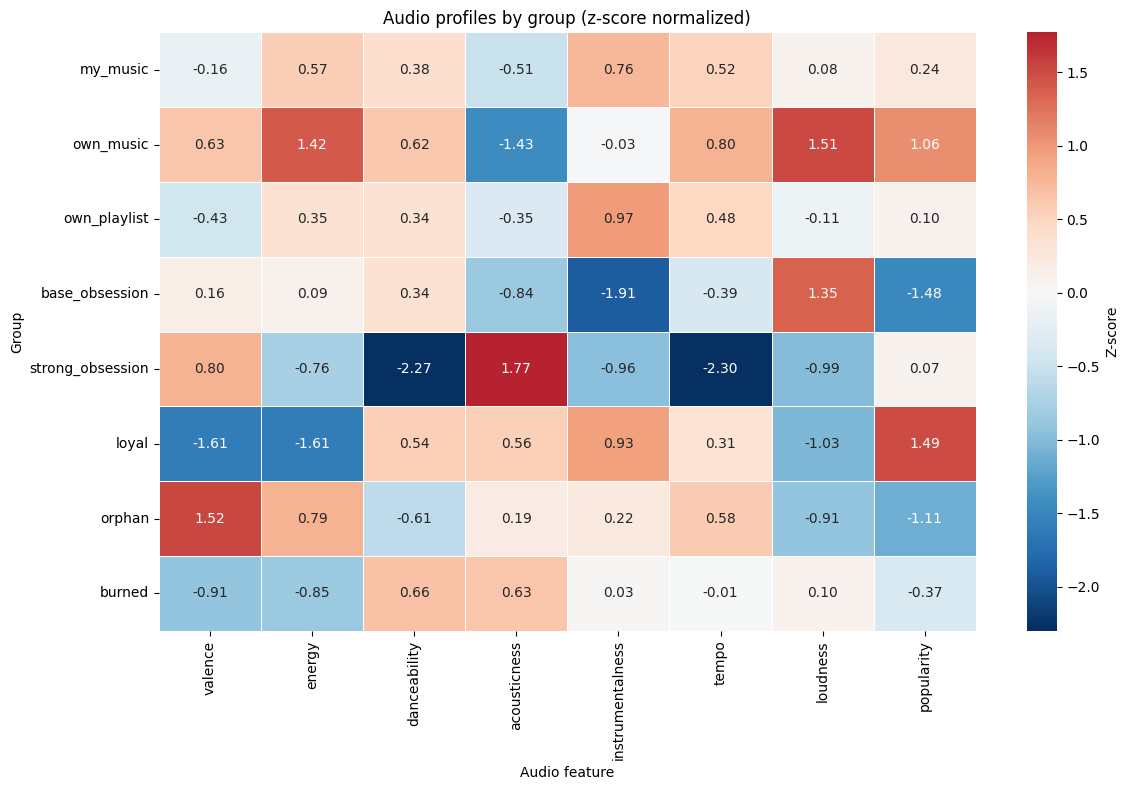

,Group,valence,energy,danceability,acousticness,instrumentalness,tempo,loudness,popularity
№,,,,,,,,,
1,my_music,0.294,0.519,0.588,0.340,0.470,119.232,-10.911,33.291
2,own_music,0.306,0.534,0.594,0.312,0.410,120.031,-10.292,35.551
3,own_playlist,0.290,0.516,0.586,0.344,0.485,119.103,-10.997,32.895
4,base_obsession,0.299,0.511,0.586,0.330,0.268,116.650,-10.357,28.532
5,strong_obsession,0.308,0.497,0.511,0.407,0.339,111.237,-11.378,32.800
6,loyal,0.272,0.482,0.592,0.371,0.482,118.638,-11.396,36.727
7,orphan,0.319,0.523,0.559,0.360,0.428,119.387,-11.341,29.541
8,burned,0.283,0.495,0.595,0.373,0.414,117.736,-10.904,31.590



Top-3 most distinguishing features: ['tempo', 'popularity', 'loudness']


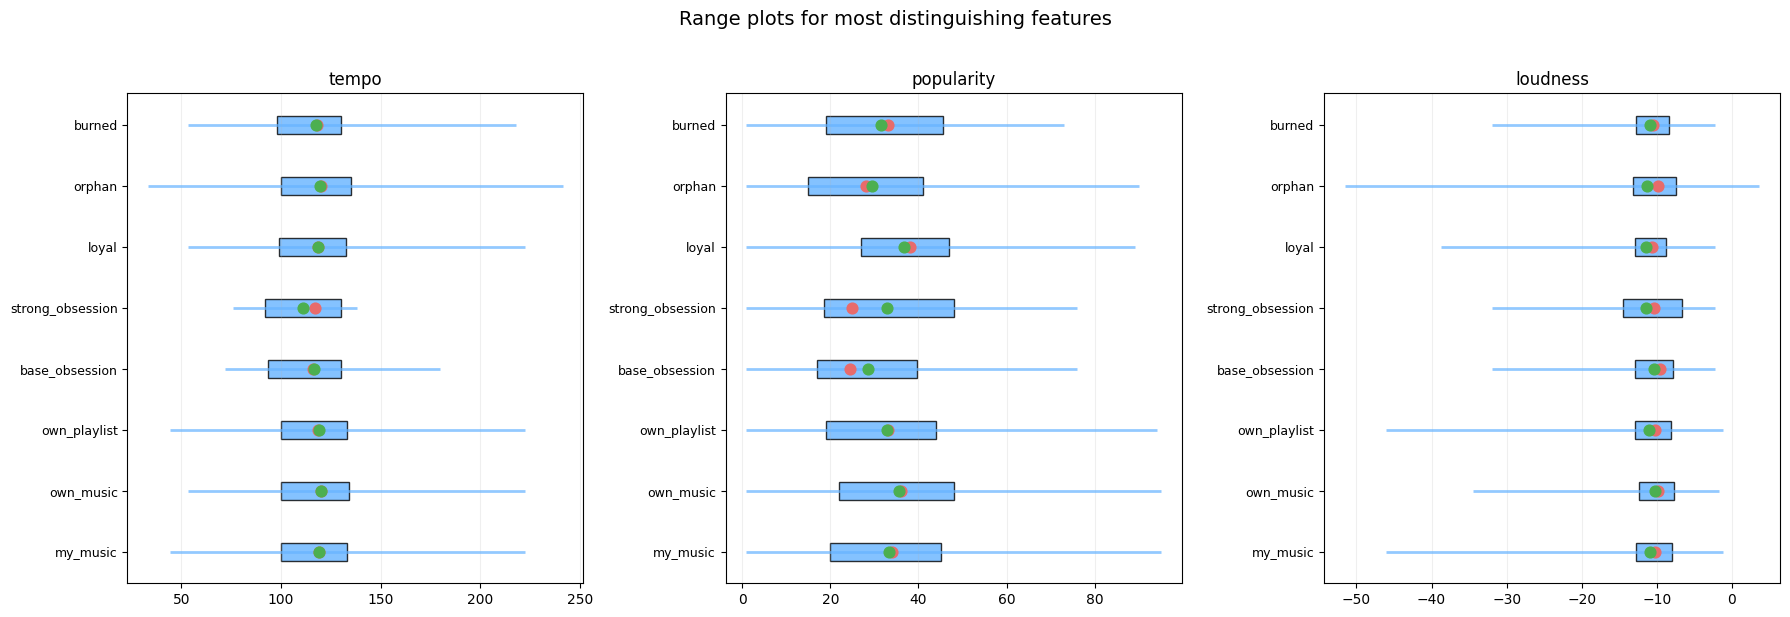


📊 Statistical significance (Kruskal-Wallis):
   valence: p=6.630e-13 → significant
   energy: p=4.565e-11 → significant
   danceability: p=1.263e-29 → significant
   acousticness: p=4.911e-05 → significant
   instrumentalness: p=7.042e-33 → significant
   tempo: p=1.446e-01 → not significant
   loudness: p=3.253e-12 → significant
   popularity: p=9.135e-89 → significant

📊 Pairwise comparisons (Mann-Whitney):
   strong_obsession vs own_music (tempo): p=3.008e-01 → not significant
   strong_obsession vs own_music (acousticness): p=3.156e-01 → not significant
   base_obsession vs own_music (instrumentalness): p=1.946e-04 → significant
   own_music vs orphan (popularity): p=1.356e-36 → significant
   loyal vs own_music (valence): p=5.303e-05 → significant
   loyal vs orphan (popularity): p=6.804e-37 → significant

📊 Practical significance of differences:
   • valence: orphan vs loyal = 0.047 ≥ 0.02 → meaningful
   • energy: own_music vs loyal = 0.052 ≥ 0.02 → meaningful
   • danceability

In [70]:
# 4.2 Аудио-профили поведенческих групп

# Сравниваем восемь групп по аудио-характеристикам.
# Вопрос: у каждой группы есть свой звуковой почерк?
#
# Сравнение идёт по уникальным трекам, а не по событиям — иначе треки
# с большим числом прослушиваний задавили бы редкие.
#
# Тепловая карта z-score: отклонение средних каждой группы от общего среднего
# по всем группам. Нужно, потому что шкалы разные (доли, BPM, дБ).

import seaborn as sns

# --- Множества групп (пересоздаём, чтобы ячейка была автономной) ---
deep = df_deep.copy()
deep['ts'] = pd.to_datetime(deep['ts'], errors='coerce').dt.tz_localize(None)

my_music_uris = set(df[df['my_music']]['spotify_track_uri'].dropna().unique())
own_music_uris = set(df[df['is_own_music']]['spotify_track_uri'].dropna().unique())
own_playlist_uris = set(df[df['is_in_own_playlist']]['spotify_track_uri'].dropna().unique())
orphan_uris = set(df[df['is_orphan']]['spotify_track_uri'].dropna().unique())

base_obs_uris = set(deep[deep['is_base_obsession']]['spotify_track_uri'].dropna().unique())
strong_obs_uris = set(deep[deep['is_strong_obsession']]['spotify_track_uri'].dropna().unique())
loyal_uris = set(deep[deep['is_loyal']]['spotify_track_uri'].dropna().unique())

core_flags = ['is_base_obsession', 'is_strong_obsession', 'is_loyal']
core_mask = deep[core_flags].any(axis=1)
core_tracks_data = deep[core_mask].copy()
last_date = deep['ts'].max()
core_grouped = core_tracks_data.groupby('spotify_track_uri').agg(
    last_seen=('ts', 'max')
).reset_index()
core_grouped['months_since_last'] = (last_date - core_grouped['last_seen']).dt.days / 30.44
burned_uris = set(core_grouped[core_grouped['months_since_last'] > 12]['spotify_track_uri'])

groups = {
    'my_music': my_music_uris,
    'own_music': own_music_uris,
    'own_playlist': own_playlist_uris,
    'base_obsession': base_obs_uris,
    'strong_obsession': strong_obs_uris,
    'loyal': loyal_uris,
    'orphan': orphan_uris,
    'burned': burned_uris,
}
group_names = list(groups.keys())

# --- Аудио-характеристики по уникальным трекам ---
features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'tempo', 'loudness', 'popularity']
track_audio = df.drop_duplicates('spotify_track_uri')[['spotify_track_uri'] + features]

# --- Средние по группам ---
group_means = {}
for group_name, uris in groups.items():
    group_tracks = track_audio[track_audio['spotify_track_uri'].isin(uris)]
    if len(group_tracks) > 0:
        group_means[group_name] = group_tracks[features].mean()

mean_df = pd.DataFrame(group_means).T

# --- Тепловая карта z-score ---
z_df = (mean_df - mean_df.mean()) / mean_df.std()

plt.figure(figsize=(12, 8))
sns.heatmap(
    z_df.round(2),
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Z-score'}
)
plt.title('Audio profiles by group (z-score normalized)')
plt.ylabel('Group')
plt.xlabel('Audio feature')
plt.tight_layout()
plt.show()

# --- Таблица средних ---
mean_display = mean_df.reset_index().rename(columns={'index': 'Group'})
mean_display.index = range(1, len(mean_display) + 1)
mean_display.index.name = '№'

for col in mean_display.columns:
    if col != 'Group':
        mean_display[col] = mean_display[col].map(lambda x: f'{x:.3f}')

display(mean_display)

# --- Range plot для топ-3 характеристик по дисперсии ---
variance = mean_df.var().sort_values(ascending=False)
top3_features = variance.head(3).index.tolist()
print(f'\nTop-3 most distinguishing features: {top3_features}')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i, feat in enumerate(top3_features):
    ax = axes[i]
    for j, gname in enumerate(group_names):
        vals = track_audio[track_audio['spotify_track_uri'].isin(groups[gname])][feat].dropna()
        if len(vals) == 0:
            continue
        q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
        med = vals.median()
        mean = vals.mean()
        ax.hlines(y=j, xmin=vals.min(), xmax=vals.max(),
                  color=COLORS['primary'], linewidth=2, alpha=0.7)
        ax.barh(y=j, width=q3 - q1, left=q1, height=0.3,
                color=COLORS['primary'], edgecolor='black', alpha=0.8)
        ax.scatter(med, j, color=COLORS['line_accent'], s=60, zorder=5)
        ax.scatter(mean, j, color=COLORS['line_success'], s=60, zorder=5)

    ax.set_yticks(range(len(group_names)))
    ax.set_yticklabels(group_names, fontsize=9)
    ax.set_title(feat, fontsize=12)
    ax.grid(axis='x', alpha=0.2)

plt.suptitle('Range plots for most distinguishing features', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# --- Статистическая значимость ---
print('\n📊 Statistical significance (Kruskal-Wallis):')
for feat in features:
    group_values = [
        track_audio[track_audio['spotify_track_uri'].isin(groups[g])][feat].dropna()
        for g in group_names
    ]
    group_values = [v for v in group_values if len(v) > 0]
    if len(group_values) < 2:
        continue
    h, p = stats.kruskal(*group_values)
    print(f'   {feat}: p={p:.3e} → {"significant" if p < 0.05 else "not significant"}')

# --- Попарные сравнения ключевых групп ---
print('\n📊 Pairwise comparisons (Mann-Whitney):')
comparisons = [
    ('strong_obsession', 'own_music', 'tempo'),
    ('strong_obsession', 'own_music', 'acousticness'),
    ('base_obsession', 'own_music', 'instrumentalness'),
    ('own_music', 'orphan', 'popularity'),
    ('loyal', 'own_music', 'valence'),
    ('loyal', 'orphan', 'popularity'),
]
for g1, g2, feat in comparisons:
    v1 = track_audio[track_audio['spotify_track_uri'].isin(groups[g1])][feat].dropna()
    v2 = track_audio[track_audio['spotify_track_uri'].isin(groups[g2])][feat].dropna()
    if len(v1) == 0 or len(v2) == 0:
        print(f'   {g1} vs {g2} ({feat}): insufficient data')
        continue
    u, p = stats.mannwhitneyu(v1, v2, alternative='two-sided')
    print(f'   {g1} vs {g2} ({feat}): p={p:.3e} → {"significant" if p < 0.05 else "not significant"}')

# --- Практическая существенность ---
print('\n📊 Practical significance of differences:')


for feat in features:
    max_group = mean_df[feat].idxmax()
    min_group = mean_df[feat].idxmin()
    diff = mean_df[feat].max() - mean_df[feat].min()
    threshold = thresholds_local[feat]
    if diff >= threshold:
        print(f'   • {feat}: {max_group} vs {min_group} = {diff:.3f} ≥ {threshold} → meaningful')
    else:
        print(f'   • {feat}: {max_group} vs {min_group} = {diff:.3f} < {threshold} → not meaningful')

### 4.2. Вывод

**Что проверяли.** Есть ли у каждой из восьми поведенческих групп
свой звуковой почерк.

**Результат.** По Kruskal-Wallis значимы семь характеристик
из восьми: valence (p=6.6e-13), energy (4.6e-11), danceability
(1.3e-29), acousticness (4.9e-05), instrumentalness (7.0e-33),
loudness (3.3e-12), popularity (9.1e-89). Tempo — не значим
(p=0.145). Практическая существенность: разрыв между крайними
группами превышает порог по всем восьми.

Звуковые профили:

- **own_music** — самая энергичная и громкая. Танцевальность
  в верхней части диапазона. Популярность вторая после **loyal**.
- **own_playlist** — самая инструментальная при средней энергии.
  В плейлисты сохраняется музыка без вокала.
- **base_obsession** — самая вокальная, вторая по громкости,
  самая малоизвестная. Зацикливание идёт на вокальных нишевых
  треках.
- **strong_obsession** — самая медленная, самая акустичная,
  самая не танцевальная.
- **loyal** — самая меланхоличная и самая популярная. Долгожители —
  известные, но грустные треки.
- **orphan** — самая светлая и вторая по энергии. Несохранённое —
  более радостное.
- **burned** — самая танцевальная при средних остальных
  характеристиках.

**Вывод.** Каждая группа имеет свой звуковой след. Самые контрастные
пары: **strong_obsession** (медленное, акустичное) против
**own_music** (энергичное, громкое), **base_obsession** (вокальное)
против **own_playlist** (инструментальное). Выгоревшие треки
отличаются только по danceability — самому слабому различию
среди всех групп.

**Ограничение.** Группы пересекаются. Парные тесты Манна-Уитни
без поправки на множественные сравнения. **strong obsession** —
20 треков, средние и медианы неустойчивы. Tempo не значим
по общему тесту (p=0.145), но разрыв между **strong_obsession**
и **own_music** выше практического порога — при 20 треках
в **strong_obsession** статистической мощности не хватает.

## 4.3 Поведение внутри групп


📊 Behavioral metrics by group:


,Group,Events,"Skip rate, %","Full play rate, %","Fwd rate, %","Back rate, %",Median ms_played,"Mean played_frac, %"
№,,,,,,,,
1,My Music,43437,30.5,62.2,14.8,3.6,189159,67.6
2,Liked,23009,29.0,63.6,14.0,3.6,197026,69.2
3,Own playlists,40149,29.8,63.3,14.3,3.5,191826,68.6
4,Base obsession,2877,19.2,74.4,6.7,6.7,210986,79.5
5,Strong obsession,1390,12.1,81.8,4.0,2.0,215388,86.8
6,Loyal,16565,27.2,66.8,12.0,3.9,194625,71.6
7,Orphan,31783,41.0,50.3,20.0,4.1,78493,55.5
8,Burned,5793,22.0,68.0,11.8,5.5,185028,73.3


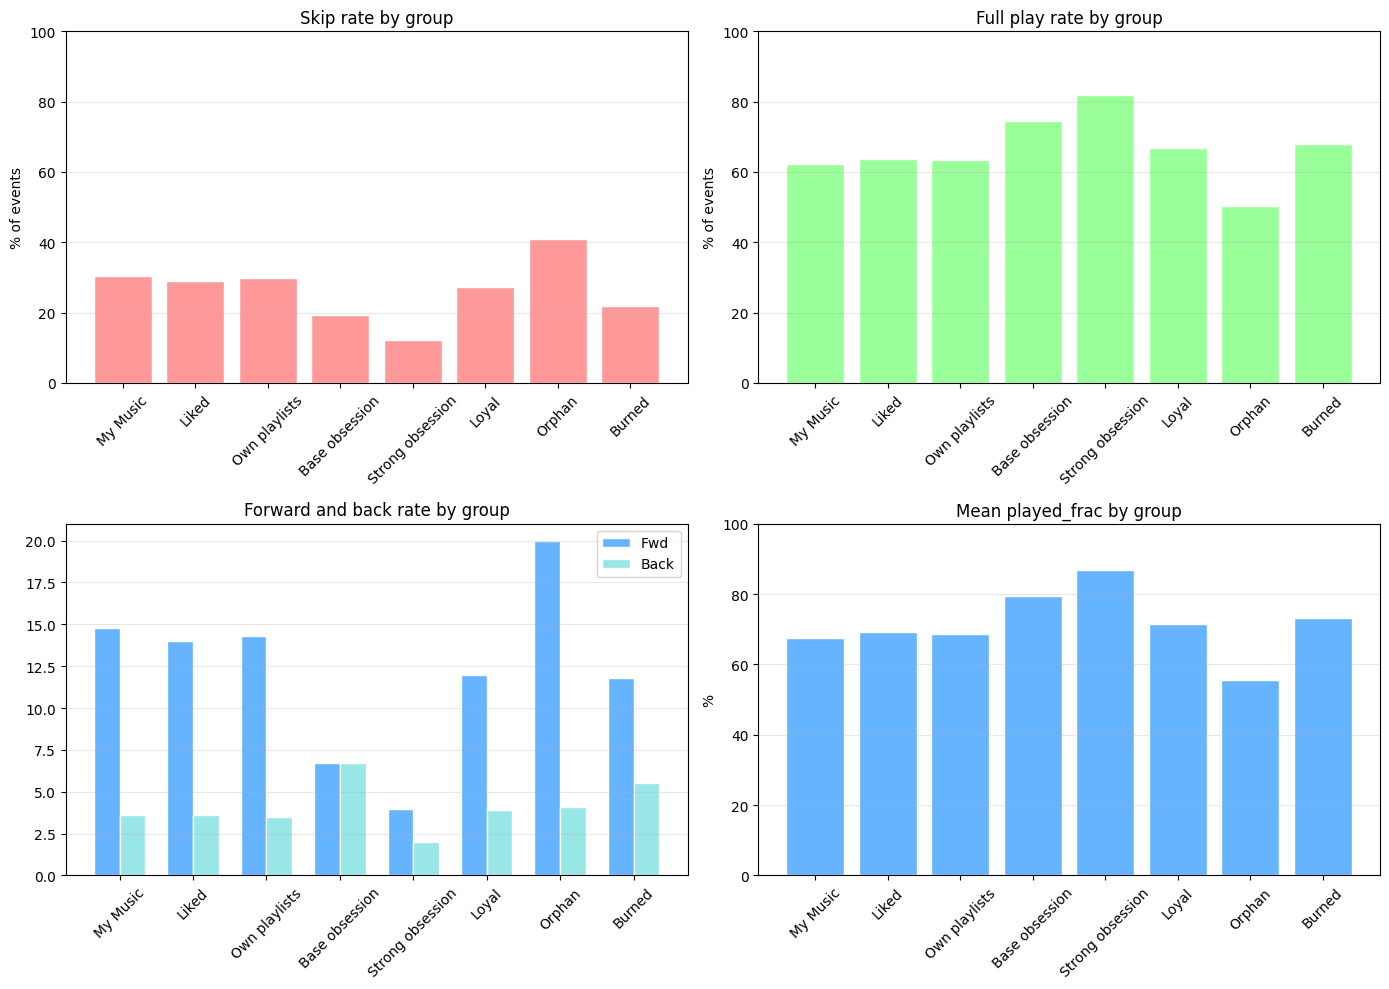

In [71]:
# 4.3 Поведение внутри групп

# Как пользователь взаимодействует с разными группами треков:
# скипает, дослушивает, перематывает, возвращается.
#
# Для каждой из восьми групп считаем:
#   - skip rate: доля скипов среди событий группы;
#   - full play rate: доля почти полных прослушиваний (≥90%);
#   - fwd rate, back rate: перемотки вперёд и возвраты;
#   - median ms_played: медианная длительность;
#   - mean played_frac: средняя доля прослушивания.
#
# Метрики считаются по событиям, не по уникальным трекам: это поведение,
# а не аудио-профиль. Разные подходы к одним и тем же данным.

deep = df_deep.copy()
deep['ts'] = pd.to_datetime(deep['ts'], errors='coerce').dt.tz_localize(None)

# --- Множества групп ---
my_music_uris = set(df[df['my_music']]['spotify_track_uri'].dropna().unique())
own_music_uris = set(df[df['is_own_music']]['spotify_track_uri'].dropna().unique())
own_playlist_uris = set(df[df['is_in_own_playlist']]['spotify_track_uri'].dropna().unique())
orphan_uris = set(df[df['is_orphan']]['spotify_track_uri'].dropna().unique())

base_obs_uris = set(deep[deep['is_base_obsession']]['spotify_track_uri'].dropna().unique())
strong_obs_uris = set(deep[deep['is_strong_obsession']]['spotify_track_uri'].dropna().unique())
loyal_uris = set(deep[deep['is_loyal']]['spotify_track_uri'].dropna().unique())

core_flags = ['is_base_obsession', 'is_strong_obsession', 'is_loyal']
core_mask = deep[core_flags].any(axis=1)
core_tracks_data = deep[core_mask].copy()
last_date = deep['ts'].max()
core_grouped = core_tracks_data.groupby('spotify_track_uri').agg(
    last_seen=('ts', 'max')
).reset_index()
core_grouped['months_since_last'] = (last_date - core_grouped['last_seen']).dt.days / 30.44
burned_uris = set(core_grouped[core_grouped['months_since_last'] > 12]['spotify_track_uri'])

groups = {
    'my_music': my_music_uris,
    'own_music': own_music_uris,
    'own_playlist': own_playlist_uris,
    'base_obsession': base_obs_uris,
    'strong_obsession': strong_obs_uris,
    'loyal': loyal_uris,
    'orphan': orphan_uris,
    'burned': burned_uris,
}

# --- Метрики по группам ---
behavior_rows = []

for gname, uris in groups.items():
    group_events = df[df['spotify_track_uri'].isin(uris)].copy()
    if len(group_events) == 0:
        continue

    total = len(group_events)
    skip_rate = group_events['is_skip'].mean() * 100
    full_play_rate = (
        group_events['ms_played'] >= group_events['duration_ms'] * 0.9
    ).mean() * 100
    fwd_rate = (group_events['reason_end'] == 'fwdbtn').mean() * 100
    back_rate = (group_events['reason_end'] == 'backbtn').mean() * 100
    median_ms = group_events['ms_played'].median()
    mean_played_frac = group_events['played_frac'].mean() * 100

    behavior_rows.append({
        'Group': gname,
        'Events': total,
        'Skip rate, %': round(skip_rate, 1),
        'Full play rate, %': round(full_play_rate, 1),
        'Fwd rate, %': round(fwd_rate, 1),
        'Back rate, %': round(back_rate, 1),
        'Median ms_played': round(median_ms, 0),
        'Mean played_frac, %': round(mean_played_frac, 1)
    })

behavior_df = pd.DataFrame(behavior_rows)

GROUP_LABELS = {
    'my_music': 'My Music',
    'own_music': 'Liked',
    'own_playlist': 'Own playlists',
    'base_obsession': 'Base obsession',
    'strong_obsession': 'Strong obsession',
    'loyal': 'Loyal',
    'orphan': 'Orphan',
    'burned': 'Burned',
}
behavior_df['Group'] = behavior_df['Group'].map(GROUP_LABELS)

behavior_df.index = range(1, len(behavior_df) + 1)
behavior_df.index.name = '№'

print('📊 Behavioral metrics by group:')
display(behavior_df.style.format({
    'Events': '{:.0f}',
    'Median ms_played': '{:.0f}',
    'Skip rate, %': '{:.1f}',
    'Full play rate, %': '{:.1f}',
    'Fwd rate, %': '{:.1f}',
    'Back rate, %': '{:.1f}',
    'Mean played_frac, %': '{:.1f}',
}))


# --- Четыре графика в сетке 2×2 ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Skip rate
ax = axes[0, 0]
ax.bar(behavior_df['Group'], behavior_df['Skip rate, %'],
       color=COLORS['accent'], edgecolor='white')
ax.set_title('Skip rate by group')
ax.set_ylabel('% of events')
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)

# Full play rate
ax = axes[0, 1]
ax.bar(behavior_df['Group'], behavior_df['Full play rate, %'],
       color=COLORS['success'], edgecolor='white')
ax.set_title('Full play rate by group')
ax.set_ylabel('% of events')
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)

# Fwd / Back
ax = axes[1, 0]
x = np.arange(len(behavior_df))
width = 0.35
ax.bar(x - width/2, behavior_df['Fwd rate, %'], width, label='Fwd',
       color=COLORS['primary'], edgecolor='white')
ax.bar(x + width/2, behavior_df['Back rate, %'], width, label='Back',
       color=COLORS['secondary'], edgecolor='white')
ax.set_title('Forward and back rate by group')
ax.set_xticks(x)
ax.set_xticklabels(behavior_df['Group'], rotation=45)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Mean played_frac
ax = axes[1, 1]
ax.bar(behavior_df['Group'], behavior_df['Mean played_frac, %'],
       color=COLORS['primary'], edgecolor='white')
ax.set_title('Mean played_frac by group')
ax.set_ylabel('%')
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 4.3. Вывод

**Что смотрели.** Как пользователь взаимодействует с разными группами треков: скипает, дослушивает, перематывает, возвращается.

**Результат.** По всем метрикам группы ранжируются от максимальной вовлечённости к минимальной.

**strong obsession** — крайняя точка: skip rate 12.1%, full play 81.8%, played_frac 86.8%, медиана 215 секунд, fwd 4.0%. Минимум отторжения, максимум дослушивания.

**base obsession** — близко: skip 19.2%, full play 74.4%, played_frac 79.5%. Особенность — back rate 6.7%, выше всех остальных групп вдвое. Возвраты к зацепившему треку, а не непрерывный повтор.

**burned** — 22.0% skip, 68.0% full play, played_frac 73.3%. Ближе к **loyal** (27.2%, 66.8%, 71.6%), чем к **orphan**.

**My Music** и её подгруппы — 29–31% skip, 62–64% full play, played_frac 68–69%. Стабильное среднее.

**orphan** — противоположный полюс: skip 41.0%, full play 50.3%, fwd 20.0%, played_frac 55.5%, медиана 78 секунд. Отторжение максимальное, длительность минимальная.

**Вывод.** Поведение ранжируется: **strong obsession** → **base obsession** → **burned** → **loyal** → **My Music** → **orphan**. Обсессии — максимальная вовлечённость в момент прослушивания: почти нет скипов и перемоток, почти полное дослушивание. **base obsession** отличается частыми возвратами. **orphan** — минимальная вовлечённость. **burned** по поведению близок к своей музыке, а не к сиротам: когда пользователь их слушал, он дослушивал их так же полно. Выгорание — не следствие плохого обращения с треком.

Ограничение: статистическая значимость не проверялась. Группы пересекаются. Метрики считаются по событиям, а не по уникальным трекам.

## 4.4 Динамика групп по годам


📊 Group share in deep dive events by year, %:


,Year,my_music,own_music,own_playlist,base_obsession,strong_obsession,loyal,orphan
№,,,,,,,,
1,2020,46.8,37.6,36.5,0.5,,14.5,48.3
2,2021,60.4,34.4,55.8,7.7,6.6,15.4,34.3
3,2022,56.4,31.6,50.6,2.5,0.8,30.4,38.0
4,2023,56.0,31.9,51.8,0.9,0.4,38.6,39.4
5,2024,47.7,19.7,45.3,3.8,3.3,23.3,45.3
6,2025,68.0,31.9,65.4,0.8,0.7,22.4,26.3
7,2026,58.0,41.2,56.2,0.4,0.2,17.6,36.4


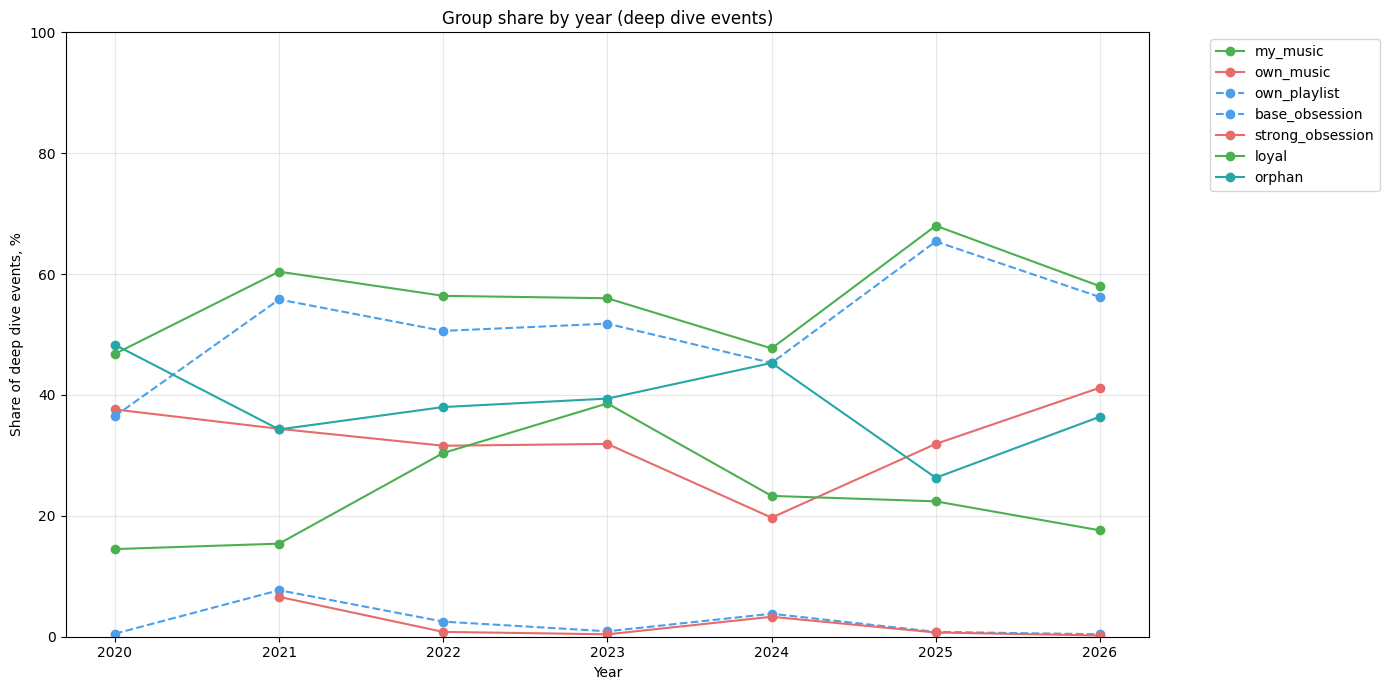

In [72]:
# 4.4 Динамика групп по годам

# Как менялась доля каждой группы в глубоком прослушивании по годам.
# Показывает смену поведенческих режимов: пики, спады, развороты.
#
# Группа burnout здесь не участвует: это текущий статус, а не исторический
# признак. Трек становится Burned только спустя 12 месяцев отсутствия —
# «доля burned в 2021» не имеет смысла.

deep = df_deep.copy()
deep['ts'] = pd.to_datetime(deep['ts'], errors='coerce').dt.tz_localize(None)
deep['year'] = deep['ts'].dt.year

# Группы для динамики: только исторические флаги.
groups_for_years = {
    'my_music': 'my_music',
    'own_music': 'is_own_music',
    'own_playlist': 'is_in_own_playlist',
    'base_obsession': 'is_base_obsession',
    'strong_obsession': 'is_strong_obsession',
    'loyal': 'is_loyal',
    'orphan': 'is_orphan',
}

# --- Доля событий группы по годам ---
yearly_group_share = {}
for label, col in groups_for_years.items():
    yearly_total = deep.groupby('year')['ts'].count()
    yearly_group = deep[deep[col]].groupby('year')['ts'].count()
    share = (yearly_group / yearly_total * 100).round(1)
    yearly_group_share[label] = share

year_share_df = pd.DataFrame(yearly_group_share)
year_share_df.index.name = 'Year'
year_share_df = year_share_df.reset_index()
year_share_df.index = range(1, len(year_share_df) + 1)
year_share_df.index.name = '№'

# Копия только для отображения — оригинал остаётся числовым для графика.
year_share_display = year_share_df.copy()
for col in year_share_display.columns:
    if col != 'Year':
        year_share_display[col] = year_share_display[col].map(
            lambda x: f'{x:.1f}' if pd.notna(x) else ''
        )

print('📊 Group share in deep dive events by year, %:')
show_table(year_share_display)

# --- График ---
# Цвета из единой палитры: каждая группа имеет свой цвет.
group_line_colors = {
    'my_music': COLORS['line_success'],
    'own_music': COLORS['line_accent'],
    'own_playlist': COLORS['line_primary'],
    'base_obsession': COLORS['line_primary'],
    'strong_obsession': COLORS['line_accent'],
    'loyal': COLORS['line_success'],
    'orphan': COLORS['line_secondary'],
}

fig, ax = plt.subplots(figsize=(14, 7))
for label in groups_for_years.keys():
    # own_playlist и base_obsession визуально перекрываются — рисуем их
    # разными стилями линий, чтобы обе читались.
    linestyle = '-' if label not in ['own_playlist', 'base_obsession'] else '--'
    ax.plot(year_share_df['Year'], year_share_df[label],
            marker='o', label=label, linestyle=linestyle,
            color=group_line_colors[label])

ax.set_title('Group share by year (deep dive events)')
ax.set_xlabel('Year')
ax.set_ylabel('Share of deep dive events, %')
ax.set_xticks(list(year_share_df['Year']))
ax.set_xticklabels(list(year_share_df['Year']))
ax.set_ylim(0, 100)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4.4. Вывод

**Что смотрели.** Как менялась доля каждой поведенческой группы в **deep**-событиях по годам.

**Результат.** **my_music** и **own_playlist** идут почти идентично: рост к 2021, плато до 2023, провал 2024, пик 2025, спад 2026. Лайки повторяют форму слабее — глубокий провал 2024 (19.7%) и восстановление 2026 (41.2%). **loyal** растёт до 2023 (38.6%), затем падает до 17.6% в 2026. **orphan** колеблется в противофазе: 48.3% в 2020, 26.3% в 2025, 36.4% в 2026. **base obsession** — 7.7% в 2021, 0.9% в 2023, 3.8% в 2024, ниже 1% в 2025–2026.

**Вывод.** Годы можно разделить на два режима. Годы с обсессиями — 2021 и 2024: доля своей музыки падает, **orphan** растёт. Годы без обсессий — 2023 и 2025: **base obsession** ниже процента, а **my_music** либо стабильна, либо растёт. 2023 выделяется максимумом **loyal**: долгожители набираются, пока новых обсессий нет. 2024 — единственный год, где обе оси совпали: минимум лайков, максимум **orphan** при коротком возврате обсессий.

Форма **my_music** задаётся плейлистами, не лайками. Лайки вносят меньший вклад и сильнее колеблются.

Ограничение: **my_music** = **own_music** OR **own_playlist** — группы пересекаются, сумма долей больше 100%. **strong obsession** в 2020 отсутствует: сильных обсессий в тот год не было. Доли считаются от **deep**-событий, не от всего потока.

## 4.5 Поиск и классификация изменений


### О версии детектора в 4.5

PELT здесь осознанно оставлен в первоначальном виде:
`pen=10` как эвристика, семь смешанных звук+поведение признаков
в одной модели, база — все события без `trim_cold_start`.
Это историческая точка отсчёта методологического пути проекта.

Финальная версия детектора — в `02_methodology/PELT_JOURNEY.md`:
раздельные PELT-A (звук) и PELT-B (поведение), BIC вместо `pen=10`,
`valid` для звука, `df` для поведения, `trim_cold_start`.
Используется в дашборде.

⚠️ Excluding incomplete month: 2026-08 (data up to 2026-08-03)
🔍 Changepoints found: 7
   Dates: ['2021-07', '2022-05', '2022-10', '2023-08', '2024-06', '2024-11', '2025-09']
   Points per year: 1.18
   Scenario: cascade
   Variability level: High


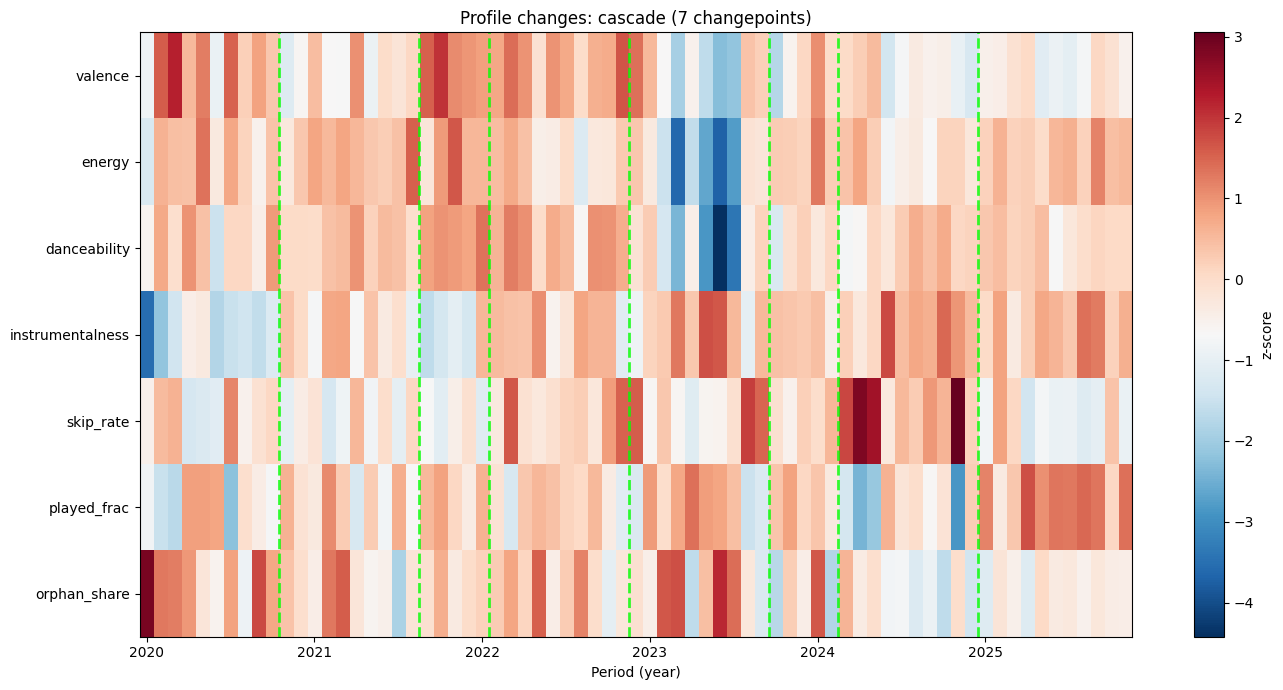

,Period,valence,energy,danceability,instrumentalness,skip_rate,played_frac,orphan_share
№,,,,,,,,
1,2020-05-01 00:00:00,0.256,0.422,0.547,0.018,0.235,0.509,0.765
2,2020-10-01 00:00:00,0.367,0.552,0.615,0.181,0.407,0.387,0.569
3,2020-11-01 00:00:00,0.396,0.540,0.575,0.273,0.426,0.360,0.562
4,2020-12-01 00:00:00,0.319,0.536,0.630,0.388,0.094,0.794,0.525
5,2021-01-01 00:00:00,0.351,0.602,0.599,0.405,0.105,0.792,0.384
6,2021-02-01 00:00:00,0.252,0.486,0.500,0.229,0.128,0.785,0.345
7,2021-03-01 00:00:00,0.364,0.561,0.582,0.260,0.517,0.269,0.511
8,2021-04-01 00:00:00,0.304,0.520,0.583,0.272,0.228,0.640,0.303
9,2021-05-01 00:00:00,0.332,0.471,0.555,0.248,0.298,0.580,0.630



📊 Variables for 4.6:
   scenario = 'cascade'
   variability = 'High'
   points_per_year = 1.18


In [73]:
# 4.5 Поиск и классификация изменений

# Многомерный PELT на месячных рядах: ищем точки разладки, где
# поведение системы сдвинулось одновременно по нескольким метрикам.
#
# Детектор в первоначальной версии — см. пояснение выше.
# ============================================================

import ruptures as rpt

# ---------- Параметры ----------
PELT_PENALTY = 10                    # эвристика, не BIC — см. выше
LOW_VARIABILITY_THRESHOLD = 0.5      # точек в год: <= 0.5 → Low
MODERATE_VARIABILITY_THRESHOLD = 1.0 # 0.5–1.0 → Medium, >1.0 → High
METRICS = ['valence', 'energy', 'danceability', 'instrumentalness',
           'skip_rate', 'played_frac', 'orphan_share']

# ---------- 1. Месячные ряды ----------
data = df.copy()

# Проверка обязательного признака сирот
if 'is_orphan' not in data.columns:
    if 'orphan_category' in data.columns:
        data['is_orphan'] = data['orphan_category'].isin(
            ['skipped', 'significant', 'insignificant']
        )
    else:
        raise KeyError(
            "Колонка 'is_orphan' или 'orphan_category' обязательна. "
            "Сначала выполните блок 0."
        )

data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
data['month'] = data['ts'].dt.to_period('M')

monthly = data.groupby('month').agg(
    valence=('valence', 'mean'),
    energy=('energy', 'mean'),
    danceability=('danceability', 'mean'),
    instrumentalness=('instrumentalness', 'mean'),
    skip_rate=('is_skip', 'mean'),
    played_frac=('played_frac', 'mean'),
    orphan_share=('is_orphan', 'mean'),
).reset_index()

# Исключаем неполный последний месяц (защита от краевых эффектов)
max_date = data['ts'].max()
last_month_period = max_date.to_period('M')
if max_date.day < last_month_period.days_in_month:
    print(f'⚠️ Excluding incomplete month: {last_month_period} (data up to {max_date.date()})')
    monthly = monthly[monthly['month'] < last_month_period].reset_index(drop=True)

monthly['month'] = monthly['month'].dt.to_timestamp()
monthly = monthly.set_index('month').sort_index()

# Заполняем пропуски: медианы для аудио, нули для долей
for col in METRICS:
    if col in ['skip_rate', 'orphan_share']:
        monthly[col] = monthly[col].fillna(0)
    else:
        monthly[col] = monthly[col].fillna(monthly[col].median())

# ---------- 2. Многомерный PELT ----------
X = monthly[METRICS].values

# Z-score нормализация с защитой от деления на ноль
mean = X.mean(axis=0)
std = X.std(axis=0)
std[std == 0] = 1
X_norm = (X - mean) / std

model = rpt.Pelt(model="l2").fit(X_norm)
changepoints = model.predict(pen=PELT_PENALTY)
cp_indices = changepoints[:-1]   # последняя точка — конец ряда
cp_dates = [monthly.index[i] for i in cp_indices]

n_points = len(cp_indices)
total_months = len(monthly)
points_per_year = n_points / (total_months / 12)

print(f'🔍 Changepoints found: {n_points}')
print(f'   Dates: {[d.strftime("%Y-%m") for d in cp_dates] if cp_dates else "none"}')
print(f'   Points per year: {points_per_year:.2f}')

# ---------- 3. Классификация сценария ----------
if points_per_year <= LOW_VARIABILITY_THRESHOLD:
    scenario = 'single'
    variability = 'Low'
elif points_per_year <= MODERATE_VARIABILITY_THRESHOLD:
    scenario = 'moderate'
    variability = 'Medium'
else:
    scenario = 'cascade'
    variability = 'High'

print(f'   Scenario: {scenario}')
print(f'   Variability level: {variability}')

# ---------- 4. Визуализация ----------
fig, ax = plt.subplots(figsize=(14, 7))

im = ax.imshow(X_norm.T, aspect='auto', cmap='RdBu_r', interpolation='nearest')
ax.set_yticks(range(len(METRICS)))
ax.set_yticklabels(METRICS)
ax.set_xlabel('Period (year)')
ax.set_title(f'Profile changes: {scenario} ({n_points} changepoints)')

for idx in cp_indices:
    ax.axvline(x=idx - 0.5, color='lime', linestyle='--', linewidth=2, alpha=0.8)

tick_indices = list(range(0, total_months, 12))
ax.set_xticks(tick_indices)
ax.set_xticklabels([monthly.index[i].strftime('%Y') for i in tick_indices])

plt.colorbar(im, ax=ax, label='z-score')
plt.tight_layout()
plt.show()

# ---------- 5. Таблица месячных значений ----------
df_display = monthly[METRICS].reset_index()
df_display.rename(columns={'month': 'Period'}, inplace=True)

df_display = df_display.reset_index(drop=True)
df_display.index = df_display.index + 1
df_display.index.name = '№'

show_table(df_display, precision=3)

# ---------- 6. Переменные для 4.6 ----------
print('\n📊 Variables for 4.6:')
print(f'   scenario = {scenario!r}')
print(f'   variability = {variability!r}')
print(f'   points_per_year = {points_per_year:.2f}')

### 4.5. Вывод

**Что проверяли.** Есть ли в поведении единая точка перелома или
изменения идут волнами. Многомерный **PELT** на месячных рядах
по семи метрикам: valence, energy, danceability, instrumentalness,
skip_rate, played_frac, orphan_share.

**Результат.** Найдено 7 точек разладки: 2021-07, 2022-05, 2022-10,
2023-08, 2024-06, 2024-11, 2025-09. Плотность — 1.18 точек в год.
Сценарий — **cascade**, уровень **Variability** — **High**.

**Вывод.** Единой точки перелома нет. Изменения распределены
с середины 2021 по конец 2025 — примерно один значимый сдвиг
в год. Это не подтверждает гипотезу о переломе именно в 2024:
2024-06 и 2024-11 — две из семи точек, но не единственная.

По карте видно, какие метрики дают сдвиги. **skip_rate** и
**played_frac** меняются контрастнее остальных: в 2024–2025 они
дают резкие переходы. **instrumentalness** показывает два больших
сдвига — в 2023-08 (вверх) и 2024-06 (вниз). **orphan_share**
колеблется по всей истории, но без чётких периодов стабильности.

**Ограничение.** **pen=10** — эвристика, не BIC-формула.
При другом значении число точек может измениться. Месячные
агрегаты сглаживают резкие сдвиги — недельные данные могли бы
дать более точные даты. Первый и последний месяц ряда могут быть
краевыми эффектами.

Сравнение с финальной архитектурой — в `02_methodology/PELT_JOURNEY.md`.
Там детектор разделён на слои (PELT-A для звука, PELT-B для
поведения, Cosine по составу артистов), использован BIC вместо
`pen=10` и bootstrap для проверки устойчивости. Точки разладки,
найденные здесь, нельзя сравнивать напрямую с финальными:
это разные методы, не версии одного.

## 4.6 Адаптивное сравнение изменений


Changepoint clusters (gap ≤ 6 months):
   Cluster 1: 2021-07
   Cluster 2: 2022-05, 2022-10
   Cluster 3: 2023-08
   Cluster 4: 2024-06, 2024-11
   Cluster 5: 2025-09


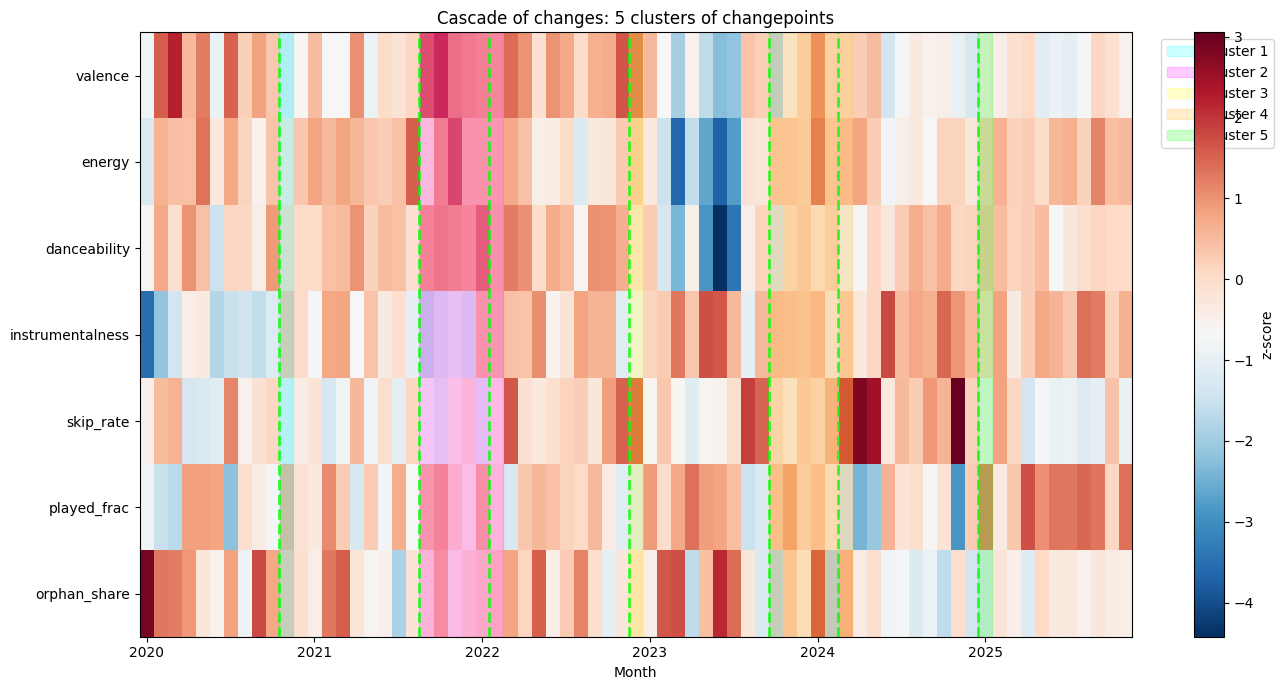


ℹ️ Cascade model: before/after comparison is not meaningful.
   Changes happened in waves, so the period cannot be reduced to one year.

📊 Change summary:
   Scenario: cascade
   Variability level: High
   Changepoints per year: 1.18


In [74]:
# 4.6 Адаптивное сравнение изменений

# Ветвление по scenario из 4.5:
#   single          — одиночный перелом. Делим период на «до» и «после»,
#                     сравниваем аудио и поведение.
#   moderate/cascade — изменения волнами. Кластеризуем точки разладки
#                     по временному разрыву и показываем карту кластеров.
#
# Сравнение «до/после» при каскаде не показательно: единой точки перелома
# нет, и деление на две половины скрывает волновую природу изменений.

# ---------- Параметры ----------
CLUSTER_GAP_MONTHS = 6   # максимальный разрыв между точками внутри кластера

# ---------- Проверка переменных из 4.5 ----------
required_vars = ['scenario', 'variability', 'points_per_year',
                 'cp_dates', 'cp_indices', 'monthly', 'METRICS', 'X_norm']
for var in required_vars:
    if var not in globals():
        raise ValueError(f'Variable {var} not found. Run cell 4.5 first.')

# ==========================================
# Ветка 1: single — одиночный перелом
# ==========================================
if scenario == 'single':
    if len(cp_dates) == 0:
        print('No changepoints found. Cannot determine break point.')
    else:
        change_date = cp_dates[0]
        print(f'Single break point: {change_date.strftime("%Y-%m")}')

        # Данные с периодами
        data = df.copy()
        data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
        data['period'] = np.where(data['ts'] < change_date, 'Before', 'After')

        features = ['valence', 'energy', 'danceability', 'acousticness',
                    'instrumentalness', 'tempo', 'loudness', 'popularity']

        # Сводка по периодам
        summary = {}
        for feat in features:
            summary[feat] = data.groupby('period')[feat].mean().round(3)
        summary['skip_rate'] = data.groupby('period')['is_skip'].mean().mul(100).round(1)
        summary['full_play_rate'] = data.groupby('period')['played_frac'].apply(
            lambda x: (x >= 0.9).mean() * 100
        ).round(1)
        summary['played_frac'] = data.groupby('period')['played_frac'].mean().mul(100).round(1)
        summary['median_ms'] = data.groupby('period')['ms_played'].median().round(0)

        summary_df = pd.DataFrame(summary).T
        summary_df.columns = ['Before', 'After']
        summary_df.index.name = 'Metric'
        print('\n📊 Before/After comparison:')
        display(summary_df)

        # Графики сравнения
        fig, axes = plt.subplots(2, 4, figsize=(16, 8))
        axes = axes.flatten()
        for i, feat in enumerate(features):
            ax = axes[i]
            data.boxplot(column=feat, by='period', ax=ax)
            ax.set_title(feat)
            ax.set_xlabel('')
        plt.suptitle(f'Before/After comparison (break at {change_date.strftime("%Y-%m")})', y=1.02)
        plt.tight_layout()
        plt.show()


# ==========================================
# Ветка 2: moderate / cascade — каскад изменений
# ==========================================
elif scenario in ['moderate', 'cascade']:
    if len(cp_dates) == 0:
        print('No changepoints found.')
    else:
        sorted_dates = sorted(cp_dates)
        clusters = []
        current_cluster = [sorted_dates[0]]

        # Кластеризация: точки ближе CLUSTER_GAP_MONTHS друг к другу — один кластер
        for i in range(1, len(sorted_dates)):
            gap_months = (
                (sorted_dates[i].year - sorted_dates[i-1].year) * 12
                + (sorted_dates[i].month - sorted_dates[i-1].month)
            )
            if gap_months <= CLUSTER_GAP_MONTHS:
                current_cluster.append(sorted_dates[i])
            else:
                clusters.append(current_cluster)
                current_cluster = [sorted_dates[i]]
        clusters.append(current_cluster)

        print(f'Changepoint clusters (gap ≤ {CLUSTER_GAP_MONTHS} months):')
        for i, cluster in enumerate(clusters, 1):
            dates_str = ', '.join([d.strftime('%Y-%m') for d in cluster])
            print(f'   Cluster {i}: {dates_str}')

        # --- Тепловая карта с точками и кластерами ---
        fig, ax = plt.subplots(figsize=(14, 7))
        im = ax.imshow(X_norm.T, aspect='auto', cmap='RdBu_r', interpolation='nearest')
        ax.set_yticks(range(len(METRICS)))
        ax.set_yticklabels(METRICS)
        ax.set_xlabel('Month')
        ax.set_title(f'Cascade of changes: {len(clusters)} clusters of changepoints')

        # Линии точек разладки
        for idx in cp_indices:
            ax.axvline(x=idx - 0.5, color='lime', linestyle='--', linewidth=2, alpha=0.8)

        # Подсветка кластеров
        cluster_colors = ['cyan', 'magenta', 'yellow', 'orange', 'lime', 'pink']
        for ci, cluster in enumerate(clusters):
            cluster_idx = [monthly.index.get_loc(d) for d in cluster]
            min_idx = min(cluster_idx) - 0.5
            max_idx = max(cluster_idx) + 0.5
            ax.axvspan(min_idx, max_idx,
                       color=cluster_colors[ci % len(cluster_colors)],
                       alpha=0.2, label=f'Cluster {ci+1}')

        n_months = len(monthly)
        tick_indices = list(range(0, n_months, 12))
        ax.set_xticks(tick_indices)
        ax.set_xticklabels([monthly.index[i].strftime('%Y') for i in tick_indices])
        ax.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
        plt.colorbar(im, ax=ax, label='z-score')
        plt.tight_layout()
        plt.show()

        print('\nℹ️ Cascade model: before/after comparison is not meaningful.')
        print('   Changes happened in waves, so the period cannot be reduced to one year.')


# ---------- Итог ----------
print('\n📊 Change summary:')
print(f'   Scenario: {scenario}')
print(f'   Variability level: {variability}')
print(f'   Changepoints per year: {points_per_year:.2f}')

### 4.6. Вывод

**Что проверяли.** Сгруппировать точки разладки из 4.5 по временному разрыву и посмотреть, как изменения распределены по волнам.

**Результат.** Семь точек собрались в пять кластеров: 2021-07, 2022-05 + 2022-10, 2023-08, 2024-06 + 2024-11, 2025-09. Разрывы внутри кластеров — до 6 месяцев, между кластерами — 6–12.

По карте видно, какие метрики дают волну. В кластере 2023-08 синхронно сдвигаются danceability и instrumentalness. В кластере 2024-06 сдвиг по energy, danceability, instrumentalness, skip_rate одновременно. В кластере 2025-09 — снова skip_rate и played_frac.

**Вывод.** Поведение менялось волнами, а не одним переломом. Пять кластеров за пять лет — примерно одна волна в год. Каждая волна захватывает свой набор метрик: где-то только звук, где-то только поведение, где-то оба. Сравнение «до/после» по единой точке неприменимо — период не сводится к одному году.

Ограничение: группировка по 6 месяцам — эвристика. При другом пороге кластеры могут слиться или разделиться. Оценка «какие метрики дают волну» визуальная, без статистической проверки внутри кластера.

## 4.7 Итоговый синтез


In [75]:
# 4.7 Итоговый синтез

# Ячейка автономна: если переменные из 4.0 уже в памяти —
# используются они. Если нет — пересчитываются здесь.
# Это дублирование осознанное: 4.7 можно запустить отдельно,
# не прогоняя весь ноутбук.

# Автоматический сводный портрет по четырём осям.
# Числа пересчитываются, если их нет в памяти — ячейка автономна.
#
# Четыре оси:
#   1. Discovery Rate     — поиск нового.
#   2. Retention 90d      — закрепление новинок.
#   3. Burnout Share      — выгорание core-треков.
#   4. Variability        — изменчивость поведения во времени.
#
# Пометка про Variability: в 4.0 и 4.5 она считается через примитивную
# версию PELT (pen=10, смешанные признаки). Финальная версия —
# в 02_methodology/PELT_JOURNEY.md.

# ---------- Параметры ----------
DISCOVERY_LOW = 30
DISCOVERY_HIGH = 50
RETENTION_LOW = 30
RETENTION_HIGH = 40
BURNOUT_LOW = 20
BURNOUT_HIGH = 40
LOW_VARIABILITY_THRESHOLD = 0.5
MODERATE_VARIABILITY_THRESHOLD = 1.0


# ==========================================
# Пересчёт осей (автономно, если нет в памяти)
# ==========================================
if not all(v in globals() for v in [
    'median_discovery', 'retention_90', 'burnout_share',
    'variability', 'points_per_year', 'scenario',
    'discovery_level', 'retention_level', 'burnout_level'
]):
    # 1. Discovery Rate
    valid = df[df['valid_play']].copy()
    valid['ts'] = pd.to_datetime(valid['ts'], errors='coerce').dt.tz_localize(None)
    valid['quarter'] = valid['ts'].dt.to_period('Q')
    valid['first_quarter'] = valid['first_valid_seen'].dt.to_period('Q')
    valid['is_new_event'] = valid['quarter'] == valid['first_quarter']

    quarterly_total = valid.groupby('quarter')['is_new_event'].count()
    quarterly_new = valid.groupby('quarter')['is_new_event'].sum()
    discovery_rate = (quarterly_new / quarterly_total * 100).sort_index()

    first_quarter = valid['ts'].min().to_period('Q')
    start_quarter = first_quarter + 4
    discovery_rate = discovery_rate[discovery_rate.index >= start_quarter]
    median_discovery = discovery_rate.median()

    # 2. Retention 90d
    last_date = valid['ts'].max()
    cutoff_90 = last_date - pd.Timedelta(days=90)
    first_events = valid[valid['ts'] == valid['first_valid_seen']].copy()
    first_events = first_events[first_events['first_valid_seen'] <= cutoff_90]

    repeats = valid[valid['ts'] > valid['first_valid_seen']].copy()
    repeats_90 = repeats[repeats['ts'] <= repeats['first_valid_seen'] + pd.Timedelta(days=90)]

    returned_uris = set(repeats_90['spotify_track_uri'].unique())
    novel_tracks = first_events.drop_duplicates('spotify_track_uri')
    novel_tracks['returned_90'] = novel_tracks['spotify_track_uri'].isin(returned_uris)
    retention_90 = novel_tracks['returned_90'].mean() * 100

    # 3. Burnout Share
    deep = df_deep.copy()
    deep['ts'] = pd.to_datetime(deep['ts'], errors='coerce').dt.tz_localize(None)
    last_deep = deep['ts'].max()

    core_flags = ['is_base_obsession', 'is_strong_obsession', 'is_loyal']
    core_mask = deep[core_flags].any(axis=1)
    core_tracks = deep[core_mask].copy()

    core_grouped = core_tracks.groupby('spotify_track_uri').agg(
        last_seen=('ts', 'max')
    ).reset_index()
    core_grouped['months_since_last'] = (last_deep - core_grouped['last_seen']).dt.days / 30.44
    burnout_share = (core_grouped['months_since_last'] > 12).mean() * 100

    # 4. Variability (примитивная версия PELT)
    import ruptures as rpt
    data = df.copy()
    data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
    data['month'] = data['ts'].dt.to_period('M')

    monthly = data.groupby('month').agg(
        valence=('valence', 'mean'),
        energy=('energy', 'mean'),
        danceability=('danceability', 'mean'),
        instrumentalness=('instrumentalness', 'mean'),
        skip_rate=('is_skip', 'mean'),
        played_frac=('played_frac', 'mean'),
        orphan_share=('is_orphan', 'mean'),
    ).reset_index()
    monthly['month'] = monthly['month'].dt.to_timestamp()
    monthly = monthly.set_index('month').sort_index().dropna()

    METRICS = ['valence', 'energy', 'danceability', 'instrumentalness',
               'skip_rate', 'played_frac', 'orphan_share']
    X = monthly[METRICS].values
    X_norm = (X - X.mean(axis=0)) / X.std(axis=0)

    model = rpt.Pelt(model="l2").fit(X_norm)
    changepoints = model.predict(pen=10)
    cp_indices = changepoints[:-1]

    n_points = len(cp_indices)
    points_per_year = n_points / (len(monthly) / 12)

    if points_per_year <= LOW_VARIABILITY_THRESHOLD:
        scenario = 'single'
        variability = 'Low'
    elif points_per_year <= MODERATE_VARIABILITY_THRESHOLD:
        scenario = 'moderate'
        variability = 'Medium'
    else:
        scenario = 'cascade'
        variability = 'High'

    # Уровни
    def level(value, low, high):
        if value < low:
            return 'Low'
        elif value <= high:
            return 'Medium'
        else:
            return 'High'

    discovery_level = level(median_discovery, DISCOVERY_LOW, DISCOVERY_HIGH)
    retention_level = level(retention_90, RETENTION_LOW, RETENTION_HIGH)
    burnout_level = level(burnout_share, BURNOUT_LOW, BURNOUT_HIGH)


# ==========================================
# Вывод
# ==========================================
print('📊 Final listener profile')
print('=' * 50)
print('Profile across four axes:')
print(f'   1. Discovery Rate (search for new):       {median_discovery:.1f}% → {discovery_level}')
print(f'   2. Retention 90d (novelty anchoring):     {retention_90:.1f}% → {retention_level}')
print(f'   3. Burnout Share (core track churn):      {burnout_share:.1f}% → {burnout_level}')
print(f'   4. Variability (behavior change):         {points_per_year:.2f} points/year → {variability}')
print(f'      Change scenario: {scenario}')

# Автоматическая интерпретация по комбинации уровней
descriptions = {
    ('High', 'Medium', 'Medium', 'High'): (
        'A pronounced explorer with high variability: actively seeks new music, '
        'moderately anchors discoveries, moderately burns through core tracks, '
        'and changes behavior in waves.'
    ),
    ('High', 'High', 'Low', 'Low'): (
        'An efficient collector: searches widely, anchors well, rarely burns out.'
    ),
    ('High', 'Low', 'High', 'High'): (
        'A streaming tourist: lots of new material, little sticks, fast burnout.'
    ),
    ('Medium', 'Medium', 'Medium', 'Medium'): (
        'A balanced listener: search, anchoring, and burnout are all moderate.'
    ),
    ('Low', 'High', 'Low', 'Low'): (
        'A collector: rarely searches, but keeps what is found.'
    ),
    ('Low', 'Low', 'High', 'Low'): (
        'A fading playlist: little new incoming, old obsessions fading.'
    ),
}

profile_key = (discovery_level, retention_level, burnout_level, variability)
interpretation = descriptions.get(
    profile_key,
    f'Profile: {discovery_level} discovery, {retention_level} retention, '
    f'{burnout_level} burnout, {variability} variability.'
)

print('\n📌 Key takeaways:')
print(f'   • {interpretation}')
print(f'   • Discovery Rate: {median_discovery:.1f}% (typical level ~30% per third-party sources).')
print(f'   • Retention 90d: {retention_90:.1f}%.')
print(f'   • Burnout Share: {burnout_share:.1f}%.')
print(f'   • Variability: {points_per_year:.2f} changepoints per year.')

📊 Final listener profile
Profile across four axes:
   1. Discovery Rate (search for new):       65.3% → High
   2. Retention 90d (novelty anchoring):     35.5% → Medium
   3. Burnout Share (core track churn):      32.3% → Medium
   4. Variability (behavior change):         1.18 points/year → High
      Change scenario: cascade

📌 Key takeaways:
   • A pronounced explorer with high variability: actively seeks new music, moderately anchors discoveries, moderately burns through core tracks, and changes behavior in waves.
   • Discovery Rate: 65.3% (typical level ~30% per third-party sources).
   • Retention 90d: 35.5%.
   • Burnout Share: 32.3%.
   • Variability: 1.18 changepoints per year.


### 4.7. Вывод

**Что смотрели.** Сводный профиль по четырём осям: **Discovery Rate**, **Retention 90d**, **Burnout Share**, **Variability**.

**Результат.** **Discovery Rate** — 65.3% (**High**), **Retention 90d** — 35.5% (**Medium**), **Burnout Share** — 32.3% (**Medium**), **Variability** — 1.18 точек в год (**High**). Сценарий изменений — **cascade**.

**Вывод.** Профиль выраженного исследователя с высокой изменчивостью. Активный поиск нового при умеренном закреплении и умеренном выгорании. Поведение меняется волнами — больше одного сдвига в год, единой точки перелома нет.

**Discovery Rate** 65.3% против типичных 30% по Spotify Research — больше чем вдвое выше обычного уровня. Это главная ось профиля: пользователь ищет новое почти постоянно, а не эпизодически. Умеренное закрепление и выгорание при этом означают, что найденное не задерживается надолго — постоянный поток нового и уходящего.

Ограничение: пороги **Low** / **Medium** / **High** заданы вручную. **Discovery** опирается на Spotify Research (2022), **Retention** и **Burnout** — индустриальные ориентиры и эвристики, не выведенные из статистического теста. **Variability** считается через примитивную версию **PELT** (`pen=10`, смешанные признаки) — финальная версия в `02_methodology/PELT_JOURNEY.md`.

## 4.8 Итоговый markdown-блок


In [76]:
# 4.8 Итоговый markdown-блок
# Ячейка автономна: если переменные из 4.0 уже в памяти —
# используются они. Если нет — пересчитываются здесь.
# Это дублирование осознанное: 4.7 можно запустить отдельно,
# не прогоняя весь ноутбук.

# Собирает финальный поведенческий портрет в одно markdown-сообщение.
# Все числа подставляются из переменных — никакого хардкода в тексте.
#
# Если переменные из 4.0 / 4.5 / 4.7 уже в памяти, используется их.
# Иначе — пересчёт внутри ячейки (для автономности).

from IPython.display import Markdown, display

# ---------- Параметры ----------
DISCOVERY_LOW = 30
DISCOVERY_HIGH = 50
RETENTION_LOW = 30
RETENTION_HIGH = 40
BURNOUT_LOW = 20
BURNOUT_HIGH = 40
LOW_VARIABILITY_THRESHOLD = 0.5
MODERATE_VARIABILITY_THRESHOLD = 1.0


# ---------- Пересчёт, если переменных нет в памяти ----------
if not all(v in globals() for v in [
    'median_discovery', 'retention_90', 'burnout_share',
    'variability', 'points_per_year', 'scenario',
    'discovery_level', 'retention_level', 'burnout_level'
]):
    # 1. Discovery Rate
    valid = df[df['valid_play']].copy()
    valid['ts'] = pd.to_datetime(valid['ts'], errors='coerce').dt.tz_localize(None)
    valid['quarter'] = valid['ts'].dt.to_period('Q')
    valid['first_quarter'] = valid['first_valid_seen'].dt.to_period('Q')
    valid['is_new_event'] = valid['quarter'] == valid['first_quarter']

    quarterly_total = valid.groupby('quarter')['is_new_event'].count()
    quarterly_new = valid.groupby('quarter')['is_new_event'].sum()
    discovery_rate = (quarterly_new / quarterly_total * 100).sort_index()

    first_quarter = valid['ts'].min().to_period('Q')
    start_quarter = first_quarter + 4
    discovery_rate = discovery_rate[discovery_rate.index >= start_quarter]
    median_discovery = discovery_rate.median()

    # 2. Retention 90d
    last_date = valid['ts'].max()
    cutoff_90 = last_date - pd.Timedelta(days=90)
    first_events = valid[valid['ts'] == valid['first_valid_seen']].copy()
    first_events = first_events[first_events['first_valid_seen'] <= cutoff_90]

    repeats = valid[valid['ts'] > valid['first_valid_seen']].copy()
    repeats_90 = repeats[repeats['ts'] <= repeats['first_valid_seen'] + pd.Timedelta(days=90)]

    returned_uris = set(repeats_90['spotify_track_uri'].unique())
    novel_tracks = first_events.drop_duplicates('spotify_track_uri')
    novel_tracks['returned_90'] = novel_tracks['spotify_track_uri'].isin(returned_uris)
    retention_90 = novel_tracks['returned_90'].mean() * 100

    # 3. Burnout Share
    deep = df_deep.copy()
    deep['ts'] = pd.to_datetime(deep['ts'], errors='coerce').dt.tz_localize(None)
    last_deep = deep['ts'].max()

    core_flags = ['is_base_obsession', 'is_strong_obsession', 'is_loyal']
    core_mask = deep[core_flags].any(axis=1)
    core_tracks = deep[core_mask].copy()

    core_grouped = core_tracks.groupby('spotify_track_uri').agg(
        last_seen=('ts', 'max')
    ).reset_index()
    core_grouped['months_since_last'] = (last_deep - core_grouped['last_seen']).dt.days / 30.44
    burnout_share = (core_grouped['months_since_last'] > 12).mean() * 100

    # 4. Variability
    import ruptures as rpt
    data = df.copy()
    data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
    data['month'] = data['ts'].dt.to_period('M')

    monthly = data.groupby('month').agg(
        valence=('valence', 'mean'),
        energy=('energy', 'mean'),
        danceability=('danceability', 'mean'),
        instrumentalness=('instrumentalness', 'mean'),
        skip_rate=('is_skip', 'mean'),
        played_frac=('played_frac', 'mean'),
        orphan_share=('is_orphan', 'mean'),
    ).reset_index()
    monthly['month'] = monthly['month'].dt.to_timestamp()
    monthly = monthly.set_index('month').sort_index().dropna()

    METRICS = ['valence', 'energy', 'danceability', 'instrumentalness',
               'skip_rate', 'played_frac', 'orphan_share']
    X = monthly[METRICS].values
    X_norm = (X - X.mean(axis=0)) / X.std(axis=0)

    model = rpt.Pelt(model="l2").fit(X_norm)
    changepoints = model.predict(pen=10)
    cp_indices = changepoints[:-1]

    n_points = len(cp_indices)
    points_per_year = n_points / (len(monthly) / 12)

    if points_per_year <= LOW_VARIABILITY_THRESHOLD:
        scenario = 'single'
        variability = 'Low'
    elif points_per_year <= MODERATE_VARIABILITY_THRESHOLD:
        scenario = 'moderate'
        variability = 'Medium'
    else:
        scenario = 'cascade'
        variability = 'High'

    def level(value, low, high):
        if value < low:
            return 'Low'
        elif value <= high:
            return 'Medium'
        else:
            return 'High'

    discovery_level = level(median_discovery, DISCOVERY_LOW, DISCOVERY_HIGH)
    retention_level = level(retention_90, RETENTION_LOW, RETENTION_HIGH)
    burnout_level = level(burnout_share, BURNOUT_LOW, BURNOUT_HIGH)


# ---------- Функция перевода уровней на русский ----------
def level_ru(level):
    return {
        'Low': 'низкий',
        'Medium': 'средний',
        'High': 'высокий',
    }.get(level, level)

def level_ru_inst(level):
    """Уровень в творительном падеже: «с высоким уровнем»."""
    return {
        'Low': 'низким',
        'Medium': 'средним',
        'High': 'высоким',
    }.get(level, level)

# ---------- Адаптивные описания уровней ----------
discovery_desc = {
    'Low': 'низкая ориентация на новое — пользователь преимущественно слушает знакомую музыку',
    'Medium': 'умеренный поиск нового — баланс между новинками и знакомым',
    'High': 'высокая ориентация на новое — пользователь активно исследует незнакомую музыку',
}

retention_desc = {
    'Low': 'слабое закрепление новинок — найденное редко возвращается',
    'Medium': 'умеренное закрепление новинок — часть найденного остаётся в ротации',
    'High': 'сильное закрепление новинок — найденное часто возвращается',
}

burnout_desc = {
    'Low': 'низкое выгорание — любимые треки долго остаются активными',
    'Medium': 'умеренное выгорание — часть любимых треков со временем уходит',
    'High': 'высокое выгорание — любимые треки быстро покидают ротацию',
}

variability_desc = {
    'Low': 'низкая изменчивость поведения — предпочтения стабильны во времени',
    'Medium': 'умеренная изменчивость — поведение меняется волнами',
    'High': 'высокая изменчивость — частые и выраженные смены музыкального поведения',
}

scenario_desc = {
    'single': 'единичный перелом в поведении',
    'moderate': 'умеренные волны изменений',
    'cascade': 'поведение менялось волнами, без единой точки перелома',
}


# ---------- Формирование markdown ----------
md = f"""
## Итоговый поведенческий портрет

**Профиль по четырём осям:**

| Ось | Значение | Уровень |
|---|---|---|
| **Discovery Rate** (поиск нового) | {median_discovery:.1f}% | {level_ru(discovery_level).capitalize()} |
| **Retention 90d** (закрепление новинок) | {retention_90:.1f}% | {level_ru(retention_level).capitalize()} |
| **Burnout Share** (выгорание любимых треков) | {burnout_share:.1f}% | {level_ru(burnout_level).capitalize()} |
| **Variability** (изменчивость поведения) | {points_per_year:.2f} точек/год | {level_ru(variability).capitalize()} |

Сценарий изменений — **{scenario}**: {scenario_desc.get(scenario, '')}.

### Интерпретация

**Поиск нового.** {discovery_desc.get(discovery_level, '').capitalize()}.

**Закрепление новинок.** {retention_desc.get(retention_level, '').capitalize()}.

**Выгорание любимых треков.** {burnout_desc.get(burnout_level, '').capitalize()}.

**Изменчивость поведения.** {variability_desc.get(variability, '').capitalize()}.

### Итог

Профиль с {level_ru_inst(discovery_level)} уровнем поиска нового, {level_ru_inst(retention_level)} закреплением новинок, {level_ru_inst(burnout_level)} выгоранием любимых треков и {level_ru_inst(variability)} изменчивостью поведения.

### Ограничения

**Variability** считается через примитивную версию **PELT** (`pen=10`, смешанные признаки). Финальная версия — в `02_methodology/PELT_JOURNEY.md`.

Пороги **Low** / **Medium** / **High** — эвристики, не выведенные из статистического теста. Пороги **Discovery** (30 / 50) опираются на Spotify Research (2022). Пороги **Retention** и **Burnout** — индустриальные ориентиры и практические эвристики.
"""

display(Markdown(md))


## Итоговый поведенческий портрет

**Профиль по четырём осям:**

| Ось | Значение | Уровень |
|---|---|---|
| **Discovery Rate** (поиск нового) | 65.3% | Высокий |
| **Retention 90d** (закрепление новинок) | 35.5% | Средний |
| **Burnout Share** (выгорание любимых треков) | 32.3% | Средний |
| **Variability** (изменчивость поведения) | 1.18 точек/год | Высокий |

Сценарий изменений — **cascade**: поведение менялось волнами, без единой точки перелома.

### Интерпретация

**Поиск нового.** Высокая ориентация на новое — пользователь активно исследует незнакомую музыку.

**Закрепление новинок.** Умеренное закрепление новинок — часть найденного остаётся в ротации.

**Выгорание любимых треков.** Умеренное выгорание — часть любимых треков со временем уходит.

**Изменчивость поведения.** Высокая изменчивость — частые и выраженные смены музыкального поведения.

### Итог

Профиль с высоким уровнем поиска нового, средним закреплением новинок, средним выгоранием любимых треков и высоким изменчивостью поведения.

### Ограничения

**Variability** считается через примитивную версию **PELT** (`pen=10`, смешанные признаки). Финальная версия — в `02_methodology/PELT_JOURNEY.md`.

Пороги **Low** / **Medium** / **High** — эвристики, не выведенные из статистического теста. Пороги **Discovery** (30 / 50) опираются на Spotify Research (2022). Пороги **Retention** и **Burnout** — индустриальные ориентиры и практические эвристики.


## Блок 4. Вывод

**Профиль.** Четыре оси: **Discovery Rate** 65.3% (**High**), **Retention 90d** 35.5% (**Medium**), **Burnout Share** 32.3% (**Medium**), **Variability** 1.18 точек в год (**High**). Сценарий — **cascade**.

**Пересечения.** **strong obsession** полностью входит в **base obsession** (20 из 20). **My Music** и **orphan** не пересекаются. 71% **Liked** входят в **Own playlists**. **loyal** на 85.5% в **My Music**, **burned** — на 79.4%, **base obsession** — на 79.5%, **strong obsession** — на 95%.

**Звук.** По Kruskal-Wallis значимы семь характеристик из восьми, tempo — не значим (p=0.145). Разрыв между крайними группами превышает практический порог по всем восьми. Диапазоны по группам: instrumentalness от 0.268 у **base obsession** до 0.485 у **Own playlists**; tempo от 111.236 BPM у **strong obsession** до 120.031 у **Liked**; popularity от 28.532 у **base obsession** до 36.727 у **loyal**.

**Поведение.** skip rate ранжируется от 12.1% у **strong obsession** до 41.0% у **orphan**. Промежуточные: **base obsession** 19.2%, **burned** 22.0%.

**Динамика по годам.** **My Music** колеблется от 47.7% в 2024 до 68.0% в 2025. **Liked** в **deep**-событиях года падает до 19.7% в 2024, восстанавливается до 41.2% в 2026. **loyal** растёт до 2023 (38.6%), затем падает до 17.6% в 2026. **base obsession** — пик 2021 (7.7%), ниже 1% в 2025–2026.

**PELT.** Найдено 7 точек разладки: 2021-07, 2022-05, 2022-10, 2023-08, 2024-06, 2024-11, 2025-09. Плотность — 1.18 точек в год. Сценарий **cascade**. Собрались в 5 кластеров: 2021-07; 2022-05 и 2022-10; 2023-08; 2024-06 и 2024-11; 2025-09.

Это результат примитивного детектора (`pen=10`, смешанные признаки, без **trim_cold_start**). Финальная версия в `02_methodology/PELT_JOURNEY.md` разделяет три слоя — **PELT-A** (звук), **PELT-B** (поведение), **Cosine** по составу артистов. Пять из семи точек совпадают с финальными слоями с точностью до месяца. Точка 2022-05 попала в **Cosine**, не прошла bootstrap (stability 0.078). Точка 2022-10 не находит отражения ни в одном слое. Финальные слои добавляют три точки: 2021-02, 2024-02, 2026-03.

**Ограничения.**

Пороги **Low** / **Medium** / **High** — эвристики, не выведенные из статистического теста.

**Variability** и точки разладки — результат примитивного **PELT** (`pen=10`, смешанные признаки, без **trim_cold_start**). Финальная версия в `02_methodology/PELT_JOURNEY.md` даёт другие числа. Сравнивать их напрямую нельзя: это разные методы, не версии одного.

Группы пересекаются. Парные тесты без поправки на множественные сравнения.

**strong obsession** — 20 треков, средние и медианы неустойчивы.

# Итог ноутбука

Поток событий Spotify за 2020–2026. 79 752 события, 25 624 трека,
2 633 **session**. Вопрос ноутбука — как устроено взаимодействие
с музыкой: как собирается **My Music**, из чего состоит **session**,
что происходит на скипах и перемотках, как возникают и угасают
обсессии.

## My Music

43 437 событий — больше половины потока. По уникальным трекам
20.8% коллекции, но 54.5% событий и 59.3% **deep**.

Три группы сохранения: **Playlist** — 77.1% треков,
**Liked + Playlist** — 16.3%, **Liked** — 6.5%. В историю попадают
40.4% **Playlist** и 91.1% **Liked**.

**My Music** в **deep** — 28.5% треков. Пересечение с
**Other Playlists** — 12.6% треков объединения, 61.5% событий,
множитель интенсивности 4.9x.

**My Music** танцевальнее, громче и менее акустична, чем
**Other Playlists** — по пяти характеристикам из восьми.

Сохранение происходит быстро: 85.5% треков сохраняются после
0–1 **valid** прослушивания. **Immediate** и **Slow** не различаются
ни по одной характеристике. Доля **Immediate** растёт: 13–38%
в 2020–2023 против 45–76% в 2024–2026.

Два **mass_import** — 2020-10-19 и 2021-03-26 — исключены
из анализа сохранений.

## Сессии

Медиана **session** — 38.6 минуты календарной длительности,
12 событий. **continuous** — 66.6%, **interrupted** — 33.4%.
Медианы: 12.8 минуты против 92.3, 6 событий против 28.

**interrupted** навигационно активнее: медианный **skip_share**
0.190 против 0.035. Shuffle не различается (p=0.34).

Паузы внутри сессий создаются реальными перерывами. Нулевые
события не коррелируют с разрывом линейно (Pearson r=0.018),
но слабая ранговая связь есть (Spearman r=0.227).

По годам доля **interrupted** колеблется: 17.5% в 2021, 54.3%
в 2023, 33.5% в 2026. Одиночные сессии — 17.9% (2026) до 33.9%
(2024).

## Сохранение

Медианная доля **saved_after** — 0.108 у **interrupted** против
0.000 у **continuous**. По **never_saved** и **saved_before** группы
не различаются. Разрыв по **saved_after** значим (p=6.263e-42).

Длительность скипов между типами сессий почти не различается:
65.4% событий длиннее 30 секунд у **continuous** против 67.3%
у **interrupted**.

## Скипы и навигация

Мгновенные скипы (<10 сек) — 25.6% событий, полные прослушивания —
57.1%. **not mine** — 57.5% скипов, **context skip** — 42.5%.
**not mine** — более энергичная и громкая музыка.

**not mine** держится в диапазоне 5–15% до конца 2024, затем два
пика — декабрь 2024 (22.7%) и июль 2025 (32.1%). После июля 2025
падает до минимума в декабре 2025 — 0.4% среднее дневных долей.
**context skip** растёт, пока **not mine** падает, и в конце 2025
достигает 36%.

Поздние скипы новых треков — 2.4% потока. 81.8% на чужой музыке.

**fwdbtn** в 81.4% случаев — проверка нового. **backbtn** в 80.4%
случаев — навигационный шум.

Причины окончания: **trackdone** 57.8%, **fwdbtn** 17.0%,
**endplay** 16.2%. Между **continuous** и **interrupted** различия
по причинам — 0.4–2.9 п.п.

## Обсессии

**base obsession** — 1 049 **deep**-событий в 83 уникальных треках.
**strong obsession** — 776 событий в 20 треках, все входят
в базовые. Вместе — 2.3% **deep**-событий. Средняя интенсивность —
12.6 событий на трек у **base**, 38.8 у **strong**.

Пик — февраль 2021: 42.9% **deep**-событий месяца. Вторая волна —
февраль 2024: 18.4%. К 2025–2026 доля обсессий падает ниже
процента, объём **deep**-событий растёт.

Сезонность: зимне-весенний пик, осенний спад. Доля **base
obsession** — февраль 8.0%, лето 0.4–1.5%. Длина зацикливания —
декабрь 29.0 повторов, февраль 18.1, лето 3.0–3.7.

Обе группы вокальные: instrumentalness 0.210 у **base** и 0.222
у **strong** против 0.488 у **deep**-событий без обсессий.
**base obsession** — более танцевальная и громкая, **strong
obsession** — самая медленная и акустичная.

Выживаемость через год: **base** 38.9%, **strong** 70.0%.
Когорта 2023 — 60% и 50% через год и два года у **base**,
100% и 50% у **strong**. Когорта 2022 показывает возвраты
после паузы: 36% → 7% → 36% у **base**.

## Поиск и потери

**Discovery Rate** 65.3%. Кварталов выше 75% — три. Ниже 50% —
семь: 2023Q1, 2024Q2, 2025Q2, 2025Q3, 2025Q4, 2026Q1, 2026Q3.
Четыре из семи приходятся на 2025Q2–2026Q1.

В кварталах с высоким поиском музыка спокойнее, акустичнее
и меланхоличнее. Медиана **My Music** — 0.000 против 1.000.
Сохранение после квартала растёт незначительно.

Возврат новинок: треть через 30 дней, около 40% через 180.
Кварталы с высокой выживаемостью — 2024Q1 (52.4% через 30 дней)
и 2025Q3 (45.4%). Пики **Discovery Rate** с ними не совпадают.

Закрепляются более энергичные, танцевальные, громкие и вокальные
новинки. По **emotion group** — квадрант **Low V / High E**,
разброс между группами 2–4 п.п.

Core-треков 946. **Active** — 35.3%, **Fading** — 32.3%,
**Burned** — 32.3%. Время от пика до последнего появления:
**Burned** 1.0 года, **Active** 1.4, **Fading** 1.9.
Пик выгорания — 2021 (69.7% **Burned**) и 2022 (58.2%).

## Профиль

| Ось | Значение | Уровень |
|---|---|---|
| **Discovery Rate** | 65.3% | Высокий |
| **Retention 90d** | 35.5% | Средний |
| **Burnout Share** | 32.3% | Средний |
| **Variability** | 1.18 точек/год | Высокий |

Уровни по порогам: **Discovery Rate** — 30% и 50%,
**Retention 90d** — 30% и 40%, **Burnout Share** — 20% и 40%,
**Variability** — 0.5 и 1.0 точек в год.

**Variability** считается примитивным **PELT** (`pen=10`, смешанные
признаки). Финальная версия метода — в `02_methodology/PELT_JOURNEY.md`.

Сценарий — **cascade**: точки разладки распределены с середины 2021
по конец 2025, единой точки перелома нет. **PELT** нашёл 7 точек,
они собрались в 5 кластеров.

Пересечения групп: **strong obsession** полностью входит в
**base obsession** (20 из 20), **My Music** и **orphan**
не пересекаются (0 треков), 71% лайкнутых треков входят
в **Own playlists**, **loyal** на 85.5% в **My Music**.

Поведение: skip rate от 12.1% у **strong obsession** до 41.0%
у **orphan**.

## Устойчивость

Разрыв **saved_after** между **continuous** и **interrupted**
воспроизводится во все годы: медианная доля у **interrupted**
всегда больше нуля, у **continuous** — ноль.

Меняется доля **Immediate** у **Likes**: 98.0% в 2020, 65.8%
в 2022, 83.1% в 2024, 68.0% в 2026.

Меняется доля **interrupted** по годам: 17.5% в 2021, 54.3%
в 2023, 33.5% в 2026.

Меняется доля **base obsession** в **deep**-событиях: 7.7% в 2021,
0.9% в 2023, 3.8% в 2024, ниже 1% в 2025–2026.

## Что не подтвердилось

Единый перелом в 2024 году. 2024 — две из семи точек разладки
примитивного детектора. Изменения распределены с середины 2021
по конец 2025.

Связь **Discovery Rate** и выживаемости новинок. 2025Q1 дал много
новизны, но только 33.0% возвратов через 30 дней.

Различия в **Retention** между **emotion group**. Разброс 2–4 п.п.

Нулевые события как объяснение паузы. Pearson r=0.018 при p=0.361.
Ранговая связь есть (Spearman 0.227), но она слабая.

Различия **Immediate** и **Slow** по звуку. Все восемь
характеристик ниже порога практической значимости.

## Ограничения

Выборка — история одного человека. Выводы описывают этот профиль,
не слушателей вообще.

Жанровый анализ ограничен долей **unknown** — 42–57% в разных
срезах.

Пороги классификации — **base obsession** (≥3 повтора и ≥10% доли),
**strong obsession** (≥5 подряд), **deep** (≥5 прослушиваний или
**played_frac** ≥0.7), **session** (разрыв 30 минут), **continuous** /
**interrupted** (разрыв 10 минут), **Active** / **Fading** / **Burned**
(6 и 12 месяцев), **mass_import** (100 треков, 30% месяца, 30%
прослушивания) — эвристики, не выведенные из данных.

Пороги уровней в профиле — **Discovery Rate** (30% и 50%),
**Retention 90d** (30% и 40%), **Burnout Share** (20% и 40%),
**Variability** (0.5 и 1.0 точек в год) — заданы вручную,
не выведены из статистического теста.

**Variability** и точки разладки — результат примитивного **PELT**
(`pen=10`, смешанные признаки). Финальная версия в
`02_methodology/PELT_JOURNEY.md` даёт другие числа. Сравнивать
их напрямую нельзя: это разные методы, не версии одного.

Правый край истории обрезан: 2026 неполный.

**Retention 90d** в разных ячейках считается на разных знаменателях:
в 4.0 — по всем трекам с первым появлением не позже чем за 90 дней
до конца данных, в 3.3 — с дополнительным отсевом треков без полного
аудио-профиля.

Все сравнения без поправки на множественные сравнения.